# Spotless — Parking Occupancy Analysis

This notebook contains the rubric-aligned analysis and a restored archive of the original saved results. **The current checkout has no project data, so calculations cannot yet be recomputed.** Run All safely displays a setup status and explicitly skips new calculations while inputs or dependencies are missing. This is viewing mode, not a successful analysis run.

Restore `data/processed/parking_cross_section.csv` (or set `SPOTLESS_DATA_FILE`) and install `requirements-completed.txt`, restart the kernel, then Run All to calculate the new analysis. Historical outputs at the end are from original Notebooks 01–07 and do not verify the revised models. Variable definitions and narrative remain readable without execution.


In [1]:
from pathlib import Path
import os, sys, json, importlib.metadata, importlib.util
from IPython.display import display, Markdown

SEED = 90095
root = Path.cwd()
if root.name == 'notebooks':
    root = root.parent
DATA_FILE = Path(os.environ.get('SPOTLESS_DATA_FILE', str(root / 'data/processed/parking_cross_section.csv'))).expanduser()
OUTPUT = root / 'outputs/completed_analysis'
required = {'numpy':'numpy','pandas':'pandas','matplotlib':'matplotlib','scipy':'scipy',
            'statsmodels':'statsmodels','sklearn':'scikit-learn','boruta':'Boruta','ydata_profiling':'ydata-profiling'}
missing_packages = [package for module, package in required.items() if importlib.util.find_spec(module) is None]
ANALYSIS_READY = DATA_FILE.is_file() and not missing_packages
if not ANALYSIS_READY:
    reasons = []
    if not DATA_FILE.is_file():
        reasons.append('Missing data: `' + str(DATA_FILE) + '`. Restore this file or set SPOTLESS_DATA_FILE before starting the kernel.')
    if missing_packages:
        reasons.append('Missing packages: ' + ', '.join(missing_packages) + '. Install with `%pip install -r "' + str(root / 'requirements-completed.txt') + '"`, then restart the kernel.')
    display(Markdown('**Viewing mode — analysis has not been recomputed.**\n\n' + '\n\n'.join(reasons) + '\n\nNew calculation cells will skip explicitly. Historical outputs are available at the end, labeled by their source. No replacement or synthetic data is used.'))
else:
    import numpy as np
    import pandas as pd
    import matplotlib.pyplot as plt
    import scipy.stats as st
    import statsmodels.api as sm
    from statsmodels.stats.diagnostic import het_breuschpagan, het_white, linear_reset
    from statsmodels.stats.stattools import jarque_bera
    from statsmodels.stats.outliers_influence import variance_inflation_factor
    from sklearn.model_selection import KFold
    from sklearn.metrics import mean_squared_error
    from sklearn.ensemble import RandomForestRegressor
    from boruta import BorutaPy
    from ydata_profiling import ProfileReport
    from itertools import combinations
    np.random.seed(SEED)
    OUTPUT.mkdir(parents=True, exist_ok=True)
    raw = pd.read_csv(DATA_FILE, dtype={'SpaceID': str, 'GEOID': str})
    assert raw['SpaceID'].is_unique
    parking = raw.loc[raw.RateType.isin(['FLAT','TOD'])].copy()
    parking['RateType_TOD'] = parking.RateType.eq('TOD').astype(int)
    # Preserve unknown labels as missing rather than silently coding them as zero.
    meter_map={'Multi-Space':1,'Single-Space':0}
    parking['MeterType_Multi'] = parking.MeterType.map(meter_map)
    unknown = parking.MeterType.dropna().loc[~parking.MeterType.dropna().isin(meter_map)]
    if len(unknown):
        raise ValueError('Unexpected meter labels: ' + str(unknown.unique()))
    print('Raw and FLAT/TOD shapes:', raw.shape, parking.shape)


**Viewing mode — analysis has not been recomputed.**

Missing data: `/Users/dylan/Documents/GitHub/Spotless/data/processed/parking_cross_section.csv`. Restore this file or set SPOTLESS_DATA_FILE before starting the kernel.

Missing packages: Boruta, ydata-profiling. Install with `%pip install -r "/Users/dylan/Documents/GitHub/Spotless/requirements-completed.txt"`, then restart the kernel.

New calculation cells will skip explicitly. Historical outputs are available at the end, labeled by their source. No replacement or synthetic data is used.

## 2. Data Description and Exploratory Analysis (25 points)

### (a) Provide detailed description of your dataset: source, time period, sample selection, variable definitions

The observation is one LADOT sensor-equipped metered parking space. August 2025 sensor transactions are reduced to occupied valid minutes divided by total valid minutes. The original preparation retains intervals at most 24 hours starting in a known state, does not extend the final event, and requires at least 25 raw transaction-active days. Activity does not guarantee complete monitoring. Occupancy-to-inventory matching establishes the 4,139-space cross-section recorded by the original notebooks. The main analysis excludes JUMP meters because their price strings combine unlike charge durations.

Meter characteristics and business registrations are October 2026 snapshots. ACS 2024 five-year estimates summarize 2020–2024; official 2024 TIGER/Line polygons assign Census tracts. Food-service/retail registrations use NAICS 722 and 44–45 within 0.25 miles. Registrations need not be unique storefronts. Price is a single hourly amount for FLAT and a midpoint proxy for TOD, not an observed payment. Zoning linkage is too incomplete for the primary model. Source documentation: `docs/data_sources.md`, `docs/data_dictionary_raw.md`, and cleaning notebooks 01–03. Associations are not causal effects.

#### Sample-selection accounting

Historical outputs of original cleaning notebooks: **3,707,820 sensor transactions → 4,185 spaces** after valid-interval aggregation and the 25-active-day rule; **46 inventory nonmatches excluded → 4,139 matched spaces**; **79 JUMP spaces excluded → 4,060 FLAT/TOD spaces**; **44 missing-income spaces excluded → 4,016 common complete cases**. These are historical source-output counts, not a newly executed result. Loaded-data counts below must be checked against them. Exact-duplicate inventory rows were removed; the original 35,022 inventory rows became 35,015 unique spaces. The final event receives no duration and UNKNOWN-start intervals are excluded without bridging them. The price/time-limit interpretation, source-date mismatch, and geographic concentration of missing income limit inference.

#### Variable dictionary — visible without running the notebook

All 36 original cross-section fields and the two derived model indicators are defined below.

| Variable | Definition | Units | Source / period |
|---|---|---|---|
| `occupancy_rate` | Retained occupied / valid minutes | fraction, 0–1 | LADOT sensor transactions; August 2025 (SpaceID also inventory linkage) |
| `price_midpoint` | Mean stated dollar amounts in rate string | dollars; TOD proxy | LADOT meter inventory; October 2026 snapshot |
| `time_limit_hours` | Mapped stated parking duration | hours | LADOT meter inventory; October 2026 snapshot |
| `population_density` | ACS tract population / land area | people per square mile | ACS 2024 five-year release (2020–2024); densities additionally Gazetteer land area |
| `housing_density` | ACS housing units / land area | units per square mile | ACS 2024 five-year release (2020–2024); densities additionally Gazetteer land area |
| `median_income` | ACS median household income | 2024 dollars | ACS 2024 five-year release (2020–2024); densities additionally Gazetteer land area |
| `nearby_restaurant_retail_count` | Food-service/retail registrations within 0.25 miles | registered accounts | LA Office of Finance business registry; October 2026 snapshot |
| `nearby_business_count` | All located registrations within 0.25 miles | registered accounts | LA Office of Finance business registry; October 2026 snapshot |
| `drive_alone_share` | Drive-alone workers / all workers age 16+ | fraction, 0–1 | ACS 2024 five-year release (2020–2024); densities additionally Gazetteer land area |
| `transit_share` | Transit workers / all workers age 16+ | fraction, 0–1 | ACS 2024 five-year release (2020–2024); densities additionally Gazetteer land area |
| `walk_share` | Walking workers / all workers age 16+ | fraction, 0–1 | ACS 2024 five-year release (2020–2024); densities additionally Gazetteer land area |
| `RateType_TOD` | TOD=1, FLAT=0 | indicator | Derived from LADOT inventory; October 2026 snapshot |
| `MeterType_Multi` | MeterType label contains MULTI | indicator; inspect source labels | Derived from LADOT inventory; October 2026 snapshot |
| `SpaceID` | Unique meter-space linkage identifier | text identifier | LADOT sensor transactions; August 2025 (SpaceID also inventory linkage) |
| `occupied_minutes` | Sum of retained OCCUPIED interval durations | minutes | LADOT sensor transactions; August 2025 (SpaceID also inventory linkage) |
| `total_minutes` | Sum of retained OCCUPIED and VACANT interval durations | minutes | LADOT sensor transactions; August 2025 (SpaceID also inventory linkage) |
| `active_days` | Distinct local calendar dates with raw sensor transactions, before interval filtering | days | LADOT sensor transactions; August 2025 (SpaceID also inventory linkage) |
| `BlockFace` | Source block-face label/location descriptor | text | LADOT meter inventory; October 2026 snapshot |
| `MeterType` | Source single-space or multi-space meter category | category | LADOT meter inventory; October 2026 snapshot |
| `RateType` | Source FLAT, TOD, or JUMP rate structure; main sample retains FLAT/TOD | category | LADOT meter inventory; October 2026 snapshot |
| `RateRange` | Original stated dollar charge string; not necessarily observed payments | text | LADOT meter inventory; October 2026 snapshot |
| `MeteredTimeLimit` | Original duration label; 2HR-30MIN is interpreted as 2.5 hours, unverified | text | LADOT meter inventory; October 2026 snapshot |
| `latitude` | Inventory latitude; no correction applied in the retained base sample | decimal degrees north | LADOT meter inventory; October 2026 snapshot |
| `longitude` | Inventory longitude; no correction applied in the retained base sample | decimal degrees east | LADOT meter inventory; October 2026 snapshot |
| `GEOID` | Containing Census tract identifier from point-in-polygon linkage | 11-character identifier | Census TIGER/Line or Gazetteer; 2024 |
| `population` | ACS B01003 total tract population | people | ACS 2024 five-year release (2020–2024); densities additionally Gazetteer land area |
| `housing_units` | ACS B25001 tract housing stock | housing units | ACS 2024 five-year release (2020–2024); densities additionally Gazetteer land area |
| `commuters` | ACS B08301 total workers aged 16+, including work from home | workers | ACS 2024 five-year release (2020–2024); densities additionally Gazetteer land area |
| `drive_alone` | ACS B08301 workers commuting alone by car, truck, or van | workers | ACS 2024 five-year release (2020–2024); densities additionally Gazetteer land area |
| `public_transit` | ACS B08301 workers using public transportation | workers | ACS 2024 five-year release (2020–2024); densities additionally Gazetteer land area |
| `walked` | ACS B08301 workers walking to work | workers | ACS 2024 five-year release (2020–2024); densities additionally Gazetteer land area |
| `ALAND_SQMI` | Census Gazetteer tract land area; excludes water | square miles | Census TIGER/Line or Gazetteer; 2024 |
| `zoning_code` | Available generalized zoning code; sparse linkage, excluded from models | category | LA generalized zoning acquisition; October 2026, historical validity unverified |
| `zoning_class` | Available generalized zoning class; sparse linkage, excluded from models | category | LA generalized zoning acquisition; October 2026, historical validity unverified |
| `zoning_description` | Available generalized zoning description; excluded from models | text | LA generalized zoning acquisition; October 2026, historical validity unverified |
| `tract_match_status` | Recorded status of tract spatial assignment | status category | Census TIGER/Line or Gazetteer; 2024 |
| `acs_match_status` | Recorded status of tract-to-ACS merge | status category | ACS 2024 five-year release (2020–2024); densities additionally Gazetteer land area |
| `zoning_match_status` | Recorded status of available zoning assignment | status category | LA generalized zoning acquisition; October 2026, historical validity unverified |

The observation and linkage unit is a parking space, not a sensor event or Census tract. Population and housing densities divide ACS totals by `ALAND_SQMI`; commuting shares divide their named worker counts by `commuters`. Zoning and linkage flags are audit fields, not selected economic regressors.


In [2]:
if globals().get("ANALYSIS_READY", False):
    definitions = {
    'occupancy_rate': ('Retained occupied / valid minutes', 'fraction, 0–1'),
    'price_midpoint': ('Mean stated dollar amounts in rate string', 'dollars; TOD proxy'),
    'time_limit_hours': ('Mapped stated parking duration', 'hours'),
    'population_density': ('ACS tract population / land area', 'people per square mile'),
    'housing_density': ('ACS housing units / land area', 'units per square mile'),
    'median_income': ('ACS median household income', '2024 dollars'),
    'nearby_restaurant_retail_count': ('Food-service/retail registrations within 0.25 miles', 'registered accounts'),
    'nearby_business_count': ('All located registrations within 0.25 miles', 'registered accounts'),
    'drive_alone_share': ('Drive-alone workers / all workers age 16+', 'fraction, 0–1'),
    'transit_share': ('Transit workers / all workers age 16+', 'fraction, 0–1'),
    'walk_share': ('Walking workers / all workers age 16+', 'fraction, 0–1'),
    'RateType_TOD': ('TOD=1, FLAT=0', 'indicator'),
    'MeterType_Multi': ('MeterType label contains MULTI', 'indicator; inspect source labels')}
    display(pd.DataFrame(definitions, index=['Definition', 'Units']).T)
    display(parking.MeterType.value_counts())
    continuous = [x for x in definitions if x not in ['RateType_TOD', 'MeterType_Multi']]
    candidates = [x for x in definitions if x != 'occupancy_rate']
    display(pd.Series({'Original spaces': len(raw), 'FLAT/TOD spaces': len(parking),
                      'Excluded JUMP/other': len(raw)-len(parking)}).to_frame('N'))
else:
    print("Skipped calculation: run setup with the required data and packages. Historical outputs below remain available.")


Skipped calculation: run setup with the required data and packages. Historical outputs below remain available.


### (b) Create comprehensive descriptive statistics table (mean, median, std dev, min, max, skewness, kurtosis)

In [3]:
if globals().get("ANALYSIS_READY", False):
    descriptive = parking[list(definitions)].agg(['count','mean','median','std','min','max','skew','kurt']).T
    # Pandas kurtosis is excess kurtosis: normal reference = 0.
    descriptive = descriptive.rename(columns={'skew':'skewness','kurt':'excess_kurtosis'})
    descriptive["kurtosis"] = descriptive["excess_kurtosis"] + 3
    # Pearson kurtosis normal reference = 3; excess kurtosis normal reference = 0.
    display(descriptive.round(4))
    descriptive.to_csv(OUTPUT / 'descriptive_statistics.csv')
else:
    print("Skipped calculation: run setup with the required data and packages. Historical outputs below remain available.")


Skipped calculation: run setup with the required data and packages. Historical outputs below remain available.


### (c) Generate appropriate visualizations: histograms, box plots, correlation matrix heatmap, scatter plots of key relationships

In [4]:
if globals().get("ANALYSIS_READY", False):
    fig, axes = plt.subplots(len(continuous), 2, figsize=(12, 3*len(continuous)))
    for name, row in zip(continuous, axes):
        values = parking[name].dropna()
        row[0].hist(values, bins=30, edgecolor='white')
        row[0].set_title(name)
        row[1].boxplot(values); row[1].set_title(name)
    fig.tight_layout(); fig.savefig(OUTPUT/'distributions.png', dpi=150); plt.show()
    corr = parking[list(definitions)].corr()
    fig, ax = plt.subplots(figsize=(12,10))
    im = ax.imshow(corr, vmin=-1, vmax=1, cmap='coolwarm')
    ax.set_xticks(range(len(corr)), corr.columns, rotation=90)
    ax.set_yticks(range(len(corr)), corr.index)
    fig.colorbar(im, ax=ax); fig.tight_layout(); fig.savefig(OUTPUT/'correlations.png', dpi=150); plt.show()
    keys = ['price_midpoint','population_density','median_income','nearby_restaurant_retail_count','drive_alone_share']
    fig, axes = plt.subplots(1,len(keys), figsize=(22,4))
    for ax, name in zip(axes, keys):
        ax.scatter(parking[name], parking.occupancy_rate, s=8, alpha=.2)
        ax.set(xlabel=name, ylabel='Occupancy rate')
    fig.tight_layout(); fig.savefig(OUTPUT/'relationships.png', dpi=150); plt.show()
else:
    print("Skipped calculation: run setup with the required data and packages. Historical outputs below remain available.")


Skipped calculation: run setup with the required data and packages. Historical outputs below remain available.


### (d) Assess normality using Q-Q plots and density plots for continuous variables

In [5]:
if globals().get("ANALYSIS_READY", False):
    fig, axes = plt.subplots(len(continuous), 2, figsize=(12,3*len(continuous)))
    for name, row in zip(continuous, axes):
        values = parking[name].dropna().astype(float)
        sm.qqplot(values, line='s', ax=row[0]); row[0].set_title(name+' Q-Q')
        if values.nunique() > 1:
            grid = np.linspace(values.min(), values.max(), 250)
            row[1].plot(grid, st.gaussian_kde(values)(grid), label='Kernel density')
            row[1].plot(grid, st.norm.pdf(grid, values.mean(), values.std()), '--', label='Matched normal')
        row[1].set_title(name+' density'); row[1].legend()
    fig.tight_layout(); fig.savefig(OUTPUT/'continuous_normality.png', dpi=150); plt.show()
    for name in continuous:
        display(Markdown(f"- **{name}:** skewness {descriptive.loc[name,'skewness']:.2f}, excess kurtosis {descriptive.loc[name,'excess_kurtosis']:.2f}. Compare tails and curvature in the Q-Q plot; discrete pricing and bounded shares cannot be exactly normal."))
    normality_summary=pd.DataFrame({'skewness':descriptive.loc[continuous,'skewness'],'excess_kurtosis':descriptive.loc[continuous,'excess_kurtosis']})
    for name, row in normality_summary.iterrows():
        shape='right-skewed' if row.skewness>.5 else 'left-skewed' if row.skewness<-.5 else 'roughly symmetric by skewness'
        tails='heavier' if row.excess_kurtosis>0 else 'lighter'
        display(Markdown(f'**{name}:** {shape}; {tails} tails than normal by excess kurtosis. These moments summarize shape, while Q-Q and density plots reveal departures that moments can miss. KDE may extend beyond feasible bounds and smooth discrete variables.'))
else:
    print("Skipped calculation: run setup with the required data and packages. Historical outputs below remain available.")


Skipped calculation: run setup with the required data and packages. Historical outputs below remain available.


### (e) Identify and discuss potential non-linearities. What transformations might be needed?

Predictor normality is not an OLS assumption. Right tails motivate testing log transformations for positive density and income and log1p for counts; bounded occupancy motivates a fractional-response extension. The following binned means screen for curvature without claiming causality. A quadratic-price alternative is evaluated with cross-validation in Section 3, while RESET evaluates the final model in Section 4.

In [6]:
if globals().get("ANALYSIS_READY", False):
    fig, axes = plt.subplots(1,3,figsize=(15,4))
    for ax, name in zip(axes, ['price_midpoint','population_density','nearby_restaurant_retail_count']):
        temp = parking[[name,'occupancy_rate']].dropna().copy()
        temp['bin'] = pd.qcut(temp[name], 10, duplicates='drop')
        means = temp.groupby('bin', observed=True)[[name,'occupancy_rate']].mean()
        ax.plot(means[name],means.occupancy_rate,'o-'); ax.set(xlabel=name,ylabel='Mean occupancy')
    fig.tight_layout(); plt.show()
else:
    print("Skipped calculation: run setup with the required data and packages. Historical outputs below remain available.")


Skipped calculation: run setup with the required data and packages. Historical outputs below remain available.


In [7]:
if globals().get("ANALYSIS_READY", False):
    # Compare linear vs plausible transformed relationships on identical complete rows.
    transform_cases=parking.dropna(subset=['occupancy_rate','price_midpoint','population_density','nearby_restaurant_retail_count']).copy()
    assert (transform_cases.population_density>0).all()
    assert (transform_cases.nearby_restaurant_retail_count>=0).all()
    linear_features=transform_cases[['price_midpoint','population_density','nearby_restaurant_retail_count']].copy()
    log_features=linear_features.copy()
    log_features['population_density']=np.log(log_features.population_density)
    log_features['nearby_restaurant_retail_count']=np.log1p(log_features.nearby_restaurant_retail_count)
    quadratic_features=linear_features.assign(price_squared=linear_features.price_midpoint**2)
    transform_folds=list(KFold(n_splits=5,shuffle=True,random_state=SEED).split(transform_cases))
    transform_rows=[]
    for label,frame in [('Levels',linear_features),('Log density + log1p registrations',log_features),('Quadratic price',quadratic_features)]:
        errors=[]
        for train,test in transform_folds:
            fit=sm.OLS(transform_cases.occupancy_rate.iloc[train],sm.add_constant(frame.iloc[train])).fit()
            pred=fit.predict(sm.add_constant(frame.iloc[test]))
            errors.append(np.sqrt(mean_squared_error(transform_cases.occupancy_rate.iloc[test],pred)))
        transform_rows.append({'Specification':label,'Mean CV RMSE':np.mean(errors),'Fold SD':np.std(errors,ddof=1)})
    transform_results=pd.DataFrame(transform_rows).set_index('Specification')
    display(transform_results)
    best_transform=transform_results['Mean CV RMSE'].idxmin()
    display(Markdown(f'**Nonlinearity screen:** {best_transform} has the lowest mean RMSE among these three prespecified alternatives on the same rows and folds. This is predictive evidence, not proof of the true functional form; small differences may be sampling variation. Log transforms compress right tails, log1p preserves zero counts, and squared price allows curvature. The competition among primary models remains in Section 3.'))
else:
    print("Skipped calculation: run setup with the required data and packages. Historical outputs below remain available.")


Skipped calculation: run setup with the required data and packages. Historical outputs below remain available.


### (f) Comment on outliers using appropriate detection methods (IQR, standardized residuals)

In [8]:
if globals().get("ANALYSIS_READY", False):
    q1,q3 = parking[continuous].quantile(.25), parking[continuous].quantile(.75)
    iqr=q3-q1
    outliers=pd.DataFrame({'Lower':q1-1.5*iqr,'Upper':q3+1.5*iqr})
    outliers['Flagged']=((parking[continuous]<outliers.Lower)|(parking[continuous]>outliers.Upper)).sum()
    outliers['Percent']=100*outliers.Flagged/parking[continuous].count()
    display(outliers)
    for name,row in outliers.iterrows():
        display(Markdown(f'- **{name}:** {int(row.Flagged)} IQR flags ({row.Percent:.2f}% of observed values), fences [{row.Lower:.4g}, {row.Upper:.4g}]. '+('The IQR is zero; departures can be ordinary discrete categories.' if iqr[name]==0 else 'Inspect source values and shared tract context before excluding observations.')))
    # Preliminary descriptive regression: distinct from final-model diagnostics in Section 4.
    eda_cols=['price_midpoint','population_density','nearby_restaurant_retail_count']
    eda_cases=parking.dropna(subset=['occupancy_rate']+eda_cols)
    eda_fit=sm.OLS(eda_cases.occupancy_rate,sm.add_constant(eda_cases[eda_cols])).fit()
    eda_influence=eda_fit.get_influence()
    eda_residuals=pd.DataFrame({'SpaceID':eda_cases.SpaceID,'GEOID':eda_cases.GEOID,'standardized_residual':eda_influence.resid_studentized_internal})
    eda_residuals['flag_abs_gt_2']=eda_residuals.standardized_residual.abs()>2
    display(eda_residuals.loc[eda_residuals.flag_abs_gt_2].sort_values('standardized_residual'))
    display(Markdown(f'Preliminary Model-2-style regression flags **{eda_residuals.flag_abs_gt_2.sum()} of {len(eda_cases)}** spaces at |internally standardized residual| > 2. Residual flags concern fit conditional on this model; IQR flags concern marginal variable values. Neither establishes measurement error. The sample is retained.'))
    eda_residuals.to_csv(OUTPUT/'eda_standardized_residuals.csv',index=False)
else:
    print("Skipped calculation: run setup with the required data and packages. Historical outputs below remain available.")


Skipped calculation: run setup with the required data and packages. Historical outputs below remain available.


These are screens, not deletion rules: zero IQR for a discrete parking rule can flag ordinary categories. Repeated extreme tract values can represent shared geography. Standardized residuals, leverage, Cook’s distance, and DFBETAS are evaluated after fitting in Section 4; the main sample retains flagged observations.

### (g) Handle missing values: document patterns, justify imputation method, sensitivity analysis

In [9]:
if globals().get("ANALYSIS_READY", False):
    missing=parking[list(definitions)].isna()
    display(pd.DataFrame({'Missing':missing.sum(),'Percent':100*missing.mean()}))
    display(missing.value_counts().rename('Spaces').to_frame())
    display(parking.loc[parking.median_income.isna()].groupby('GEOID').agg(N=('SpaceID','size'),mean_occupancy=('occupancy_rate','mean')))
    # Complete cases hold the sample constant across selection and competing models.
    data=parking.dropna(subset=['occupancy_rate']+candidates).copy()
    y=data.occupancy_rate
    X=data[candidates].astype(float)
    print('Common complete-case sample:', len(data), 'Excluded:', len(parking)-len(data))
    # Explicit sensitivity: median income imputation plus missingness indicator, not primary inference.
    # Fit without income, on income-complete and all otherwise observed spaces, to isolate selection.
    base=['price_midpoint','population_density','nearby_restaurant_retail_count']
    broad=parking.dropna(subset=['occupancy_rate']+base).copy()
    restricted=broad.dropna(subset=['median_income'])
    sensitivity_missing={}
    for label, frame in [('Income-complete, no income predictor',restricted),('All available, no income predictor',broad)]:
        fit=sm.OLS(frame.occupancy_rate,sm.add_constant(frame[base])).fit(cov_type='HC1')
        sensitivity_missing[label]={'N':len(frame),'Price':fit.params['price_midpoint'],'HC1 SE':fit.bse['price_midpoint']}
    imp=broad.copy(); imp['income_missing']=imp.median_income.isna().astype(int)
    imp['median_income']=imp.median_income.fillna(restricted.median_income.median())
    imp_cols=base+['median_income']+(['income_missing'] if imp.income_missing.nunique()>1 else [])
    imputed_fit=sm.OLS(imp.occupancy_rate,sm.add_constant(imp[imp_cols])).fit(cov_type='HC1')
    sensitivity_missing['Median-imputed income + missing flag']={'N':len(imp),'Price':imputed_fit.params['price_midpoint'],'HC1 SE':imputed_fit.bse['price_midpoint']}
    display(pd.DataFrame(sensitivity_missing).T)
    # Also audit source fields excluded from regressions, particularly zoning.
    source_missing=pd.DataFrame({'Missing':raw.isna().sum(),'Percent':100*raw.isna().mean()}).sort_values('Missing',ascending=False)
    display(source_missing)
    missing_comparison=pd.DataFrame(sensitivity_missing).T
    reference=missing_comparison.iloc[0]['Price']
    missing_comparison['Price difference vs income-complete']=missing_comparison.Price-reference
    display(missing_comparison)
    for label,row in missing_comparison.iterrows():
        display(Markdown(f'- **{label}:** N={int(row.N)}, price association {100*row.Price:.3f} occupancy percentage points per dollar, change {100*row["Price difference vs income-complete"]:.3f} points versus the reference. This comparison evaluates sensitivity; it does not prove missingness is ignorable.'))
    missing_comparison.to_csv(OUTPUT/'missing_data_sensitivity.csv')
    assert restricted.median_income.notna().any(), 'Cannot compute median income imputation with no observed incomes.'
else:
    print("Skipped calculation: run setup with the required data and packages. Historical outputs below remain available.")


Skipped calculation: run setup with the required data and packages. Historical outputs below remain available.


Complete cases avoid inventing tract-level income and keep model comparisons on identical observations, but are unbiased only under appropriate assumptions about missingness and the conditional model. Geographic clustering of missing values makes random missingness doubtful. The first two fits isolate the sample restriction with identical predictors; the third changes both income handling and specification. Median imputation compresses variation and ignores imputation uncertainty, so it is a sensitivity analysis, not a claim to solve missing-data bias.

### (h) Discuss findings from Pandas Profiling analysis

In [10]:
if globals().get("ANALYSIS_READY", False):
    profile = ProfileReport(parking[list(definitions)], title='Spotless: FLAT/TOD parking profile', minimal=False,
                            explorative=True, progress_bar=False)
    profile.to_file(OUTPUT/'pandas_profiling.html')
    profile_json=json.loads(profile.to_json())
    alerts=profile_json.get('alerts',[])
    display(Markdown('**Pandas Profiling (maintained as ydata-profiling):** '+str(len(alerts))+' automated alerts.'))
    for alert in alerts:
        display(Markdown('- '+str(alert)))
    # Discuss verified numeric findings alongside automated alerts.
    pairs=corr.where(np.triu(np.ones(corr.shape),k=1).astype(bool)).stack()
    for (a,b),value in pairs.loc[pairs.abs().sort_values(ascending=False).index].head(5).items():
        display(Markdown(f'- **Correlation alert context:** {a} / {b}: r={value:.3f}. Shared demand and tract geography can explain redundancy; correlation does not identify a causal pathway.'))
    display(Markdown(f'- **Missingness context:** {missing.sum().sum()} missing candidate/outcome entries; geographic patterns are examined in 2(g). Automated warnings are screening aids, not reasons to impute or delete automatically.'))
    profile_variables=profile_json.get('variables',{})
    for name,detail in profile_variables.items():
        display(Markdown(f'- **Profile finding — {name}:** inferred type {detail.get("type","unreported")}; missing {detail.get("n_missing","unreported")}; distinct {detail.get("n_distinct","unreported")}. Missingness affects sample inclusion; low cardinality suggests discrete/categorical treatment; high skew calls for inspection rather than automatic deletion.'))
    display(Markdown('**How the report informs the analysis:** redundant density and activity measures motivate the alternative-proxy/VIF checks; income missingness motivates the geographic audit and sensitivity fits; IQR and shape warnings motivate source inspection and transformation comparisons. Indicators are inherently nonnormal. IDs and sparse zoning fields are excluded from the profiling model-variable view, but their missingness is separately audited above. Inspect the saved HTML for report-specific warnings; generated alert text alone is not evidence of a causal relationship.'))
else:
    print("Skipped calculation: run setup with the required data and packages. Historical outputs below remain available.")


Skipped calculation: run setup with the required data and packages. Historical outputs below remain available.


## 3. Variable Selection and Model Development (25 points)

### (a) Apply Boruta Algorithm to identify important predictors (document parameters used)

In [11]:
if globals().get("ANALYSIS_READY", False):
    rf=RandomForestRegressor(max_depth=5,random_state=SEED,n_jobs=1)
    boruta=BorutaPy(rf,n_estimators='auto',max_iter=100,perc=100,alpha=.05,two_step=True,random_state=SEED,verbose=0)
    boruta.fit(X.to_numpy(dtype=float),y.to_numpy())
    boruta_table=pd.DataFrame({'Variable':X.columns,'Confirmed':boruta.support_,'Tentative':boruta.support_weak_,'Rank':boruta.ranking_})
    display(boruta_table)
    boruta_table.to_csv(OUTPUT/'boruta.csv',index=False)
else:
    print("Skipped calculation: run setup with the required data and packages. Historical outputs below remain available.")


Skipped calculation: run setup with the required data and packages. Historical outputs below remain available.


### (b) Apply Mallows Cp criterion for variable selection

In [12]:
if globals().get("ANALYSIS_READY", False):
    full=sm.OLS(y,sm.add_constant(X)).fit()
    sigma2=full.mse_resid
    cp_rows=[]
    for k in range(1,len(candidates)+1):
        for subset in combinations(candidates,k):
            fit=sm.OLS(y,sm.add_constant(X[list(subset)])).fit()
            p=len(fit.params)  # includes intercept
            cp_rows.append({'Variables':subset,'Predictors':k,'Cp':fit.ssr/sigma2-len(y)+2*p,'Parameters':p})
    cp=pd.DataFrame(cp_rows).sort_values('Cp')
    display(cp.head(10))
    best_cp=list(cp.iloc[0].Variables)
    best_by_size=cp.loc[cp.groupby('Predictors').Cp.idxmin()].sort_values('Predictors')
    plt.plot(best_by_size.Predictors,best_by_size.Cp,'o-',label='Minimum Cp')
    plt.plot(best_by_size.Predictors,best_by_size.Parameters,'--',label='Cp = parameter count')
    plt.xlabel('Predictors');plt.ylabel('Mallows Cp');plt.legend();plt.show()
else:
    print("Skipped calculation: run setup with the required data and packages. Historical outputs below remain available.")


Skipped calculation: run setup with the required data and packages. Historical outputs below remain available.


Cp uses the full candidate-model residual variance and counts the intercept. It trades residual fit against model size; heteroskedasticity limits its classical justification. It is considered alongside Boruta, VIF, economic reasoning, and predictive performance rather than treated as definitive.

### (c) Check for multicollinearity using Variance Inflation Factors

In [13]:
if globals().get("ANALYSIS_READY", False):
    def vif_table(frame):
        matrix=sm.add_constant(frame.astype(float),has_constant='add')
        return pd.DataFrame({'Variable':matrix.columns,'VIF':[variance_inflation_factor(matrix.to_numpy(),i) for i in range(matrix.shape[1])]})
    display(vif_table(X))
    # Avoid redundant density and commercial-intensity proxies in the developed specifications.
    reduced=X.drop(columns=['housing_density','nearby_business_count'])
    display(vif_table(reduced))
else:
    print("Skipped calculation: run setup with the required data and packages. Historical outputs below remain available.")


Skipped calculation: run setup with the required data and packages. Historical outputs below remain available.


### (d) Based on economic theory and statistical evidence, develop and justify three competing models

**Model 1: Simple regression with your theoretically most important predictor.** Price is central to parking-demand theory, though demand-responsive pricing can confound its observed association.

**Model 2: Multiple regression with 2-3 key predictors.** Price, population density, and food-service/retail activity represent price and local demand with exactly three predictors.

**Model 3: Multiple regression including all statistically significant predictors.** Begin with nonredundant candidates supported by either Boruta or the best Cp subset, plus the theory-driven Model 2 variables. Backward elimination uses HC1 p-values at 5%, including a final significance check. Post-selection p-values and intervals are exploratory and do not account for selection uncertainty.

In [14]:
if globals().get("ANALYSIS_READY", False):
    m1_cols=['price_midpoint']
    m2_cols=['price_midpoint','population_density','nearby_restaurant_retail_count']
    confirmed=list(X.columns[boruta.support_])
    start=[x for x in reduced if x in set(confirmed+best_cp+m2_cols)]
    def backward(frame,target,cols):
        cols=list(cols)
        while cols:
            fit=sm.OLS(target,sm.add_constant(frame[cols],has_constant='add')).fit(cov_type='HC1')
            pvals=fit.pvalues.drop('const')
            if pvals.max()<=.05:
                break
            cols.remove(pvals.idxmax())
        return cols
    m3_cols=backward(X,y,start)
    models={name:sm.OLS(y,sm.add_constant(X[cols],has_constant='add')).fit()
            for name,cols in [('Model 1',m1_cols),('Model 2',m2_cols),('Model 3',m3_cols)]}
    model_columns={'Model 1':m1_cols,'Model 2':m2_cols,'Model 3':m3_cols}
    assert len(m2_cols)==3
    if m3_cols:
        assert (models['Model 3'].get_robustcov_results(cov_type='HC1').pvalues[1:]<=.05).all()
    for name,fit in models.items():
        display(Markdown('**'+name+'**: '+', '.join(model_columns[name])))
        display(fit.summary())
    display(vif_table(X[m3_cols]))
else:
    print("Skipped calculation: run setup with the required data and packages. Historical outputs below remain available.")


Skipped calculation: run setup with the required data and packages. Historical outputs below remain available.


### (e) Compare models using AIC, BIC, adjusted R2, and cross-validation performance

In [15]:
if globals().get("ANALYSIS_READY", False):
    folds=list(KFold(n_splits=5,shuffle=True,random_state=SEED).split(X))
    cv_rows=[]
    for name,cols in model_columns.items():
        for fold,(train,test) in enumerate(folds,1):
            fit=sm.OLS(y.iloc[train],sm.add_constant(X.iloc[train][cols],has_constant='add')).fit()
            pred=fit.predict(sm.add_constant(X.iloc[test][cols],has_constant='add'))
            cv_rows.append({'Model':name,'Fold':fold,'RMSE':np.sqrt(mean_squared_error(y.iloc[test],pred))})
    cv=pd.DataFrame(cv_rows)
    comparison=pd.DataFrame([{'Model':name,'N':int(fit.nobs),'Predictors':len(model_columns[name]),'AIC':fit.aic,'BIC':fit.bic,'Adjusted R2':fit.rsquared_adj} for name,fit in models.items()]).set_index('Model')
    comparison=comparison.join(cv.groupby('Model').RMSE.agg(['mean','std']).rename(columns={'mean':'CV RMSE','std':'CV SD'}))
    display(comparison)
    comparison.to_csv(OUTPUT/'model_comparison.csv')
    # Nonlinearity sensitivity: identical folds and common observations, quadratic price added to Model 2.
    nonlinear=X[m2_cols].copy(); nonlinear['price_squared']=nonlinear.price_midpoint**2
    nl_errors=[]
    for train,test in folds:
        fit=sm.OLS(y.iloc[train],sm.add_constant(nonlinear.iloc[train])).fit()
        nl_errors.append(np.sqrt(mean_squared_error(y.iloc[test],fit.predict(sm.add_constant(nonlinear.iloc[test])))))
    display(pd.Series({'Linear Model 2 CV RMSE':comparison.loc['Model 2','CV RMSE'],'Quadratic price CV RMSE':np.mean(nl_errors)}))
else:
    print("Skipped calculation: run setup with the required data and packages. Historical outputs below remain available.")


Skipped calculation: run setup with the required data and packages. Historical outputs below remain available.


Five-fold errors are conditional on specifications selected using this sample. Fits within folds use training rows only, but Boruta/Cp and Model 3 selection used the full sample, so performance can be optimistic. This is not an untouched external test set or nested validation. Spatial overlap between folds is another limitation.

### (f) Select final model and provide detailed economic and statistical justification

In [16]:
if globals().get("ANALYSIS_READY", False):
    final_name=comparison['CV RMSE'].idxmin()
    final_model=models[final_name]
    predictors=model_columns[final_name]
    Z=sm.add_constant(X[predictors],has_constant='add')
    robust=sm.OLS(y,Z).fit(cov_type='HC1')
    display(Markdown(f"**Selected: {final_name}.** Lowest mean five-fold RMSE ({comparison.loc[final_name,'CV RMSE']:.5f}) is the primary selection rule; exact ties follow model order favoring simplicity. Adjusted R² is {final_model.rsquared_adj:.4f}, AIC {final_model.aic:.2f}, and BIC {final_model.bic:.2f}. Controls represent parking price, neighborhood demand, commuting patterns, or meter institutions where selected; exclusion does not prove no economic effect. Selection uncertainty and price endogeneity prevent causal interpretation."))
else:
    print("Skipped calculation: run setup with the required data and packages. Historical outputs below remain available.")


Skipped calculation: run setup with the required data and packages. Historical outputs below remain available.


## 4. Final Model Diagnostics and Robustness (20 points)

### Linearity: Residuals vs. fitted values plots, RESET test for specification

In [17]:
if globals().get("ANALYSIS_READY", False):
    fitted=final_model.fittedvalues; residuals=final_model.resid
    influence=final_model.get_influence()
    standardized=influence.resid_studentized_internal
    fig,ax=plt.subplots();ax.scatter(fitted,residuals,s=8,alpha=.3);ax.axhline(0,color='red');ax.set(xlabel='Fitted occupancy',ylabel='Residual');plt.show()
    reset=linear_reset(final_model,power=2,test_type='fitted',use_f=True,cov_type='HC1')
    print('HC1 RESET:',reset)
else:
    print("Skipped calculation: run setup with the required data and packages. Historical outputs below remain available.")


Skipped calculation: run setup with the required data and packages. Historical outputs below remain available.


### Homoskedasticity: Breusch-Pagan test, White test, scale-location plots

In [18]:
if globals().get("ANALYSIS_READY", False):
    bp=het_breuschpagan(residuals,Z)
    white=het_white(residuals,Z)
    display(pd.DataFrame([bp,white],index=['Breusch-Pagan','White'],columns=['LM','LM p','F','F p']))
    plt.scatter(fitted,np.sqrt(np.abs(standardized)),s=8,alpha=.3)
    plt.xlabel('Fitted occupancy');plt.ylabel('sqrt(abs(standardized residual))');plt.show()
    display(pd.DataFrame({'Coefficient':final_model.params,'OLS SE':final_model.bse,'HC1 SE':robust.bse,'HC1 p':robust.pvalues}))
else:
    print("Skipped calculation: run setup with the required data and packages. Historical outputs below remain available.")


Skipped calculation: run setup with the required data and packages. Historical outputs below remain available.


### Normality of residuals: Q-Q plots, Jarque-Bera test, histograms of residuals

In [19]:
if globals().get("ANALYSIS_READY", False):
    fig,axes=plt.subplots(1,2,figsize=(12,4))
    sm.qqplot(standardized,line='s',ax=axes[0]);axes[0].set_title('Residual Q-Q')
    axes[1].hist(residuals,bins=35,edgecolor='white');axes[1].set_title('Residual histogram')
    plt.show()
    jb=jarque_bera(residuals)
    display(pd.Series(jb,index=['JB','p','Skewness','Kurtosis']))
else:
    print("Skipped calculation: run setup with the required data and packages. Historical outputs below remain available.")


Skipped calculation: run setup with the required data and packages. Historical outputs below remain available.


### Outliers and influence: Cook’s distance plot, leverage vs. residuals, DFBETAS

In [20]:
if globals().get("ANALYSIS_READY", False):
    diagnostics=data[['SpaceID','GEOID']].copy()
    diagnostics['Standardized residual']=standardized
    diagnostics['Studentized residual']=influence.resid_studentized_external
    diagnostics['Leverage']=influence.hat_matrix_diag
    diagnostics['Cook']=influence.cooks_distance[0]
    nobs=len(data);p=len(final_model.params)
    dfbetas=pd.DataFrame(influence.dfbetas,index=data.index,columns=Z.columns)
    threshold=2/np.sqrt(nobs)
    display(pd.DataFrame({'DFBETAS threshold':threshold,'Flagged spaces':dfbetas.abs().gt(threshold).sum(),'Max abs DFBETAS':dfbetas.abs().max()}))
    fig,axes=plt.subplots(1,3,figsize=(18,4))
    axes[0].scatter(np.arange(nobs),diagnostics.Cook,s=8);axes[0].axhline(4/nobs,color='red');axes[0].set(xlabel='Observation',ylabel="Cook's distance")
    axes[1].scatter(diagnostics.Leverage,diagnostics['Studentized residual'],s=8,alpha=.3)
    axes[1].axvline(2*p/nobs,color='red');axes[1].axhline(2,color='grey');axes[1].axhline(-2,color='grey');axes[1].set(xlabel='Leverage',ylabel='Studentized residual')
    axes[2].plot(dfbetas.to_numpy(),alpha=.4);axes[2].axhline(threshold,color='red');axes[2].axhline(-threshold,color='red');axes[2].set(xlabel='Observation',ylabel='DFBETAS, all parameters')
    fig.tight_layout();plt.show()
    display(diagnostics.nlargest(10,'Cook'))
    display(pd.Series({'Abs standardized > 2':(np.abs(standardized)>2).sum(),'Cook > 4/n':(diagnostics.Cook>4/nobs).sum(),'Leverage > 2p/n':(diagnostics.Leverage>2*p/nobs).sum(),'Any DFBETAS flag':dfbetas.abs().gt(threshold).any(axis=1).sum()}))
    keep=diagnostics.Cook<=4/nobs
    sensitivity=sm.OLS(y.loc[keep],Z.loc[keep]).fit(cov_type='HC1')
    display(pd.DataFrame({'Full coefficient':robust.params,'Cook-screened coefficient':sensitivity.params}))
    diagnostics.to_csv(OUTPUT/'influence.csv',index=False)
else:
    print("Skipped calculation: run setup with the required data and packages. Historical outputs below remain available.")


Skipped calculation: run setup with the required data and packages. Historical outputs below remain available.


Thresholds are descriptive screens, not proof of erroneous records. The full sample remains primary; the Cook-screened fit measures sensitivity. Removing observations changes the target sample, and DFBETAS multiple screening can flag many ordinary observations.

### Robustness analysis: Bootstrap coefficient estimates (1000 replications), compare with OLS estimates

In [21]:
if globals().get("ANALYSIS_READY", False):
    rng=np.random.default_rng(SEED)
    boot=[]
    for replication in range(1000):
        draw=rng.integers(0,nobs,size=nobs)
        boot.append(np.linalg.lstsq(Z.to_numpy()[draw],y.to_numpy()[draw],rcond=None)[0])
    bootstrap=pd.DataFrame(boot,columns=Z.columns)
    bootstrap_table=pd.DataFrame({'OLS':final_model.params,'Bootstrap mean':bootstrap.mean(),'Bootstrap SE':bootstrap.std(),'2.5%':bootstrap.quantile(.025),'97.5%':bootstrap.quantile(.975)})
    display(bootstrap_table)
    bootstrap_table.to_csv(OUTPUT/'bootstrap.csv')
    bootstrap.hist(bins=30,figsize=(12,10));plt.tight_layout();plt.show()
else:
    print("Skipped calculation: run setup with the required data and packages. Historical outputs below remain available.")


Skipped calculation: run setup with the required data and packages. Historical outputs below remain available.


The row bootstrap holds the selected specification fixed. It does not capture model-selection uncertainty or within-tract dependence. A tract-clustered covariance comparison below addresses shared tract errors as an additional sensitivity, with caution when tract counts are small.

In [22]:
if globals().get("ANALYSIS_READY", False):
    clustered=sm.OLS(y,Z).fit(cov_type='cluster',cov_kwds={'groups':data.GEOID})
    display(pd.DataFrame({'HC1 SE':robust.bse,'Tract-clustered SE':clustered.bse,'Clustered p':clustered.pvalues}))
    print('Tracts:',data.GEOID.nunique())
else:
    print("Skipped calculation: run setup with the required data and packages. Historical outputs below remain available.")


Skipped calculation: run setup with the required data and packages. Historical outputs below remain available.


### Model validation: 5-fold or 10-fold cross-validation, out-of-sample prediction accuracy

In [23]:
if globals().get("ANALYSIS_READY", False):
    display(cv.loc[cv.Model.eq(final_name)])
    display(comparison.loc[[final_name],['CV RMSE','CV SD']])
    print('Fitted predictions outside [0,1]:',((fitted<0)|(fitted>1)).sum())
else:
    print("Skipped calculation: run setup with the required data and packages. Historical outputs below remain available.")


Skipped calculation: run setup with the required data and packages. Historical outputs below remain available.


### Document any violations of OLS assumptions and discuss implications for your results.

In [24]:
if globals().get("ANALYSIS_READY", False):
    for name,pvalue,implication in [
    ('HC1 RESET',float(reset.pvalue),'Rejection suggests conditional-mean misspecification; test transformations or omitted structure.'),
    ('Breusch-Pagan',bp[1],'Rejection indicates nonconstant variance; conventional OLS uncertainty is unreliable.'),
    ('White',white[1],'Rejection is compatible with heteroskedasticity and/or specification problems.'),
    ('Jarque-Bera',jb[1],'Rejection indicates nonnormal residuals; nonrejection does not prove normality.')]:
        display(Markdown(f"- **{name}: p={pvalue:.4g}; {'reject' if pvalue<.05 else 'do not reject'} at 5%.** {implication}"))
    display(Markdown('Independent errors and exogenous regressors are not established by these tests. Nearby spaces share demand conditions; clustered uncertainty is compared above. Endogenous pricing remains unresolved. Robust standard errors do not correct biased coefficients or an incorrect mean function.'))
else:
    print("Skipped calculation: run setup with the required data and packages. Historical outputs below remain available.")


Skipped calculation: run setup with the required data and packages. Historical outputs below remain available.


## 5. Results and Economic Interpretation (25 points)

### (a) Present final model results in professional regression table

In [25]:
if globals().get("ANALYSIS_READY", False):
    ci=robust.conf_int()
    results=pd.DataFrame({'Coefficient':robust.params,'HC1 SE':robust.bse,'HC1 p':robust.pvalues,'95% lower':ci[0],'95% upper':ci[1]})
    display(Markdown(f'**{final_name}; N={len(data):,}; R²={final_model.rsquared:.4f}; adjusted R²={final_model.rsquared_adj:.4f}. HC1 uncertainty; exploratory post-selection inference.**'))
    display(results.style.format({'Coefficient':'{:.6g}','HC1 SE':'{:.6g}','HC1 p':'{:.3g}','95% lower':'{:.6g}','95% upper':'{:.6g}'}))
    results.to_csv(OUTPUT/'final_regression.csv')
else:
    print("Skipped calculation: run setup with the required data and packages. Historical outputs below remain available.")


Skipped calculation: run setup with the required data and packages. Historical outputs below remain available.


### (b) Interpret ALL coefficients in economic terms (magnitude, direction, units)

In [26]:
if globals().get("ANALYSIS_READY", False):
    increments={'price_midpoint':(1,'$1 higher stated price proxy'),'time_limit_hours':(1,'one additional permitted hour'),'population_density':(1000,'1,000 additional people per square mile'),'housing_density':(1000,'1,000 additional housing units per square mile'),'median_income':(10000,'$10,000 higher median household income'),'nearby_restaurant_retail_count':(100,'100 additional food-service/retail registrations'),'nearby_business_count':(100,'100 additional business registrations'),'drive_alone_share':(.1,'a 10-percentage-point higher drive-alone share'),'transit_share':(.1,'a 10-percentage-point higher transit share'),'walk_share':(.1,'a 10-percentage-point higher walk share'),'RateType_TOD':(1,'TOD rather than FLAT pricing'),'MeterType_Multi':(1,'a multi-space rather than other meter label')}
    for name,beta in robust.params.items():
        if name=='const':
            display(Markdown(f'- **Intercept:** predicted occupancy {beta:.3f} when numeric predictors and indicators are zero. This reference combination may lie outside observed support and has limited standalone economic meaning.'))
        else:
            change,label=increments[name]
            effect=100*change*beta;lower,upper=100*change*ci.loc[name]
            display(Markdown(f'- **{name}:** {label} is associated with {abs(effect):.3f} percentage points {"higher" if effect>=0 else "lower"} occupancy, holding included covariates fixed (HC1 95% CI for the signed change [{lower:.3f}, {upper:.3f}]). This is an association, not a causal effect.'))
else:
    print("Skipped calculation: run setup with the required data and packages. Historical outputs below remain available.")


Skipped calculation: run setup with the required data and packages. Historical outputs below remain available.


### (c) Distinguish between statistical significance and economic significance

In [27]:
if globals().get("ANALYSIS_READY", False):
    for name in predictors:
        scale,label=increments[name]
        display(Markdown(f'- **{name}:** HC1 p={robust.pvalues[name]:.4g} ({"significant" if robust.pvalues[name]<.05 else "not significant"} at 5%). The associated change for {label} is {100*scale*robust.params[name]:.3f} occupancy percentage points. Practical relevance depends on achievable changes, costs, and baseline occupancy; statistical significance alone does not establish policy importance.'))
else:
    print("Skipped calculation: run setup with the required data and packages. Historical outputs below remain available.")


Skipped calculation: run setup with the required data and packages. Historical outputs below remain available.


### (d) Calculate and interpret confidence intervals for key parameters

In [28]:
if globals().get("ANALYSIS_READY", False):
    display(results[['95% lower','95% upper']])
    display(bootstrap_table[['2.5%','97.5%']])
    display(Markdown('HC1 intervals quantify uncertainty under the fitted specification with heteroskedasticity correction; percentile intervals use the row bootstrap. They do not account fully for variable selection, temporal mismatch, endogenous pricing, or spatial dependence. Interpret repeated-sampling coverage under the methods’ assumptions, not a 95% probability assigned to a fixed coefficient.'))
else:
    print("Skipped calculation: run setup with the required data and packages. Historical outputs below remain available.")


Skipped calculation: run setup with the required data and packages. Historical outputs below remain available.


### (e) Discuss R2 and model fit in economic context

In [29]:
if globals().get("ANALYSIS_READY", False):
    display(Markdown(f'The final model explains {100*final_model.rsquared:.2f}% of within-sample occupancy variation; {100*(1-final_model.rsquared):.2f}% remains unexplained. Mean conditional five-fold RMSE is {100*comparison.loc[final_name,"CV RMSE"]:.2f} occupancy percentage points. R² describes fit, not causal identification or external validity. Local events, hourly demand, enforcement, and other omitted factors may explain remaining differences.'))
else:
    print("Skipped calculation: run setup with the required data and packages. Historical outputs below remain available.")


Skipped calculation: run setup with the required data and packages. Historical outputs below remain available.


## 6. Limitations, Policy Implications, and Extensions (10 points)

### (a) Discuss key limitations of your analysis (data, methodology, scope)

August 2025 occupancy is matched to later prices and registrations and multi-year ACS measures. The price midpoint is imperfect, registered accounts differ from storefronts, and sensor gaps affect measured occupancy. The 24-hour interval and 25-active-day rules are researcher choices, not fully monitored time. OLS can predict outside zero and one. Automated selection and conditional cross-validation add optimism.

### (b) Identify potential sources of bias and how they might affect conclusions

High-demand locations may have higher prices, generating upward confounding of the price association relative to the demand response. Geographic missingness and sensor selection may change the represented population; their bias direction is unknown. Misdated or noisy predictors may attenuate simple associations but can produce more complex bias in multivariate models. Tract dependence affects uncertainty; HC1 alone does not handle it.

### (c) Describe policy implications of your findings (if applicable)

Conditional associations can identify locations and factors for further investigation, but cannot determine optimal prices or the causal occupancy response to a rate change. A positive price coefficient must not be interpreted as evidence that raising prices increases demand. Intervention decisions require contemporaneous data and a credible causal design.

### (d) Suggest concrete extensions for future research

Use contemporaneous rate schedules and historical business records; compare 12/24/48-hour gap thresholds and 20/25/28 active-day criteria; assess Sunday reporting; use spatially grouped or nested cross-validation; test log/spline and fractional-response specifications; investigate multiple imputation where defensible; and build a panel around policy changes for causal estimation. The sensor-threshold alternatives require rebuilding the raw outcome and are extensions beyond the checklist’s missing-data sensitivity completed here.

### (e) Comment on external validity: to what populations/contexts do results generalize?

The target is retained sensor-equipped Los Angeles metered spaces with FLAT/TOD pricing in August 2025 and observed model covariates. Findings do not establish generalization to JUMP meters, unsensored locations, off-street facilities, other cities, or other seasons. Common complete cases further restrict geographic representation.

## 7. Code Quality and Reproducibility (10 points)

### Well-commented Python code with clear section headers

Sections follow the rubric. Source data remain unchanged. Analysis outputs go to a dedicated directory. Definitions and units are explicit; original cleaning notebooks retain the raw-data pipeline.

### Reproducible analysis (set random seeds where applicable)

In [30]:
if globals().get("ANALYSIS_READY", False):
    packages=['pandas','numpy','scipy','matplotlib','statsmodels','scikit-learn','Boruta','ydata-profiling','nbclient']
    versions={name:importlib.metadata.version(name) for name in packages}
    manifest={'seed':SEED,'python':sys.version,'packages':versions,'input':str(DATA_FILE),'observations':len(data),'final_model':final_name,'predictors':predictors,'bootstrap_replications':len(bootstrap),'cv_folds':5}
    (OUTPUT/'run_manifest.json').write_text(json.dumps(manifest,indent=2))
    display(pd.Series(versions,name='Version'))
else:
    print("Skipped calculation: run setup with the required data and packages. Historical outputs below remain available.")


Skipped calculation: run setup with the required data and packages. Historical outputs below remain available.


### Efficient, readable code following best practices

Reusable functions implement VIF and backward selection. The bootstrap uses least squares directly, avoiding redundant model-summary construction. Exhaustive Cp is practical for this small candidate set but scales exponentially. Randomness is seeded, and missing inputs produce an explicit error.

### All figures and tables generated programmatically

In [31]:
if globals().get("ANALYSIS_READY", False):
    assert len(bootstrap)==1000
    assert len(folds)==5
    assert data.SpaceID.is_unique
    assert np.isfinite(Z.to_numpy()).all()
    assert len(m2_cols) in (2,3)
    print('Analysis completed. Generated tables, profile, selected figures, and run manifest:',OUTPUT)
else:
    print("Skipped calculation: run setup with the required data and packages. Historical outputs below remain available.")


Skipped calculation: run setup with the required data and packages. Historical outputs below remain available.


## Historical saved outputs — original analysis

These outputs were restored from the original notebooks. They are not new results and may describe different model specifications from the revised analysis above.


In [32]:
from IPython.display import display, Markdown
display(Markdown('### Historical source: 01_clean_occupancy.ipynb'))
_historical_bundles = [{'text/markdown': '# 01 — Clean Occupancy Data\n\nI use the August 2025 LADOT sensor transactions to construct a time-weighted monthly occupancy rate for each parking space. I first check the raw records and coverage, then apply the interval and sample rules described below.\n'}, {'text/markdown': '## 1. Load the raw transactions\n\nI start with the August 2025 LADOT sensor file and inspect a few rows to check its structure. The raw source file stays unchanged throughout this notebook.\n'}, {'text/html': ['<div>\n', '<style scoped>\n', '    .dataframe tbody tr th:only-of-type {\n', '        vertical-align: middle;\n', '    }\n', '\n', '    .dataframe tbody tr th {\n', '        vertical-align: top;\n', '    }\n', '\n', '    .dataframe thead th {\n', '        text-align: right;\n', '    }\n', '</style>\n', '<table border="1" class="dataframe">\n', '  <thead>\n', '    <tr style="text-align: right;">\n', '      <th></th>\n', '      <th>SpaceID</th>\n', '      <th>EventTime_Local</th>\n', '      <th>EventTime_UTC</th>\n', '      <th>OccupancyState</th>\n', '    </tr>\n', '  </thead>\n', '  <tbody>\n', '    <tr>\n', '      <th>0</th>\n', '      <td>WV308</td>\n', '      <td>8/1/2025 12:00:01 AM</td>\n', '      <td>8/1/2025 7:00:01 AM</td>\n', '      <td>VACANT</td>\n', '    </tr>\n', '    <tr>\n', '      <th>1</th>\n', '      <td>WV65</td>\n', '      <td>8/1/2025 12:00:01 AM</td>\n', '      <td>8/1/2025 7:00:01 AM</td>\n', '      <td>VACANT</td>\n', '    </tr>\n', '    <tr>\n', '      <th>2</th>\n', '      <td>SV24</td>\n', '      <td>8/1/2025 12:00:01 AM</td>\n', '      <td>8/1/2025 7:00:01 AM</td>\n', '      <td>OCCUPIED</td>\n', '    </tr>\n', '    <tr>\n', '      <th>3</th>\n', '      <td>WV582</td>\n', '      <td>8/1/2025 12:00:02 AM</td>\n', '      <td>8/1/2025 7:00:02 AM</td>\n', '      <td>OCCUPIED</td>\n', '    </tr>\n', '    <tr>\n', '      <th>4</th>\n', '      <td>WV126</td>\n', '      <td>8/1/2025 12:00:02 AM</td>\n', '      <td>8/1/2025 7:00:02 AM</td>\n', '      <td>VACANT</td>\n', '    </tr>\n', '  </tbody>\n', '</table>\n', '</div>'], 'text/plain': ['  SpaceID       EventTime_Local        EventTime_UTC OccupancyState\n', '0   WV308  8/1/2025 12:00:01 AM  8/1/2025 7:00:01 AM         VACANT\n', '1    WV65  8/1/2025 12:00:01 AM  8/1/2025 7:00:01 AM         VACANT\n', '2    SV24  8/1/2025 12:00:01 AM  8/1/2025 7:00:01 AM       OCCUPIED\n', '3   WV582  8/1/2025 12:00:02 AM  8/1/2025 7:00:02 AM       OCCUPIED\n', '4   WV126  8/1/2025 12:00:02 AM  8/1/2025 7:00:02 AM         VACANT']}, {'text/markdown': '## 2. Check the records and timestamps\n\nI check the dimensions, missing values, state labels, and exact duplicates before constructing any durations. These are validation checks, not filtering rules; the local timestamps are parsed with their recorded format so the month is measured in Los Angeles local time.\n'}, {'text/plain': 'Rows and columns: (3707820, 4)\n\nColumn types:\nSpaceID            object\nEventTime_Local    object\nEventTime_UTC      object\nOccupancyState     object\ndtype: object\n\nUnique parking spaces:\n4905\n'}, {'text/plain': ['SpaceID            0\n', 'EventTime_Local    0\n', 'EventTime_UTC      0\n', 'OccupancyState     0\n', 'dtype: int64']}, {'text/plain': 'Occupancy states:\nOccupancyState\nVACANT      1849424\nOCCUPIED    1847148\nUNKNOWN       11248\nName: count, dtype: int64\n\nExact duplicate rows:\n0\n'}, {'text/plain': '\nTime range:\n2025-08-01 00:00:01\n2025-08-31 23:59:59\n'}, {'text/markdown': '## 3. Inspect coverage across parking spaces\n\nEvent counts and first-to-last spans show how much information is available for each space. The elapsed span is measured in whole days, while active days count distinct calendar dates with at least one raw event; neither measure guarantees continuous observation. No spaces are removed at this stage.\n'}, {'text/plain': ['count    4905.000000\n', 'mean      755.926606\n', 'std       672.564195\n', 'min         1.000000\n', '25%       389.000000\n', '50%       589.000000\n', '75%       878.000000\n', 'max      8517.000000\n', 'dtype: float64']}, {'text/plain': ['count    4905.000000\n', 'mean       29.046687\n', 'std         2.000729\n', 'min         0.000000\n', '25%        29.000000\n', '50%        29.000000\n', '75%        30.000000\n', 'max        30.000000\n', 'Name: days_covered, dtype: float64']}, {'text/plain': ['count    4905.000000\n', 'mean       26.622222\n', 'std         4.177373\n', 'min         1.000000\n', '25%        26.000000\n', '50%        26.000000\n', '75%        31.000000\n', 'max        31.000000\n', 'Name: date, dtype: float64']}, {'text/markdown': '## 4. Inspect one space’s event sequence\n\nI inspect one parking space to see how recorded states evolve over time. This helps motivate a duration-based measure, although the sequence alone cannot confirm that every sensor interval is reliable.\n'}, {'text/html': ['<div>\n', '<style scoped>\n', '    .dataframe tbody tr th:only-of-type {\n', '        vertical-align: middle;\n', '    }\n', '\n', '    .dataframe tbody tr th {\n', '        vertical-align: top;\n', '    }\n', '\n', '    .dataframe thead th {\n', '        text-align: right;\n', '    }\n', '</style>\n', '<table border="1" class="dataframe">\n', '  <thead>\n', '    <tr style="text-align: right;">\n', '      <th></th>\n', '      <th>SpaceID</th>\n', '      <th>EventTime_Local</th>\n', '      <th>EventTime_UTC</th>\n', '      <th>OccupancyState</th>\n', '      <th>date</th>\n', '    </tr>\n', '  </thead>\n', '  <tbody>\n', '    <tr>\n', '      <th>0</th>\n', '      <td>WV308</td>\n', '      <td>2025-08-01 00:00:01</td>\n', '      <td>8/1/2025 7:00:01 AM</td>\n', '      <td>VACANT</td>\n', '      <td>2025-08-01</td>\n', '    </tr>\n', '    <tr>\n', '      <th>10546</th>\n', '      <td>WV308</td>\n', '      <td>2025-08-01 06:11:05</td>\n', '      <td>8/1/2025 1:11:05 PM</td>\n', '      <td>OCCUPIED</td>\n', '      <td>2025-08-01</td>\n', '    </tr>\n', '    <tr>\n', '      <th>11425</th>\n', '      <td>WV308</td>\n', '      <td>2025-08-01 06:26:35</td>\n', '      <td>8/1/2025 1:26:35 PM</td>\n', '      <td>VACANT</td>\n', '      <td>2025-08-01</td>\n', '    </tr>\n', '    <tr>\n', '      <th>11490</th>\n', '      <td>WV308</td>\n', '      <td>2025-08-01 06:27:47</td>\n', '      <td>8/1/2025 1:27:47 PM</td>\n', '      <td>OCCUPIED</td>\n', '      <td>2025-08-01</td>\n', '    </tr>\n', '    <tr>\n', '      <th>11599</th>\n', '      <td>WV308</td>\n', '      <td>2025-08-01 06:29:23</td>\n', '      <td>8/1/2025 1:29:23 PM</td>\n', '      <td>VACANT</td>\n', '      <td>2025-08-01</td>\n', '    </tr>\n', '    <tr>\n', '      <th>14330</th>\n', '      <td>WV308</td>\n', '      <td>2025-08-01 07:03:38</td>\n', '      <td>8/1/2025 2:03:38 PM</td>\n', '      <td>OCCUPIED</td>\n', '      <td>2025-08-01</td>\n', '    </tr>\n', '    <tr>\n', '      <th>15280</th>\n', '      <td>WV308</td>\n', '      <td>2025-08-01 07:12:47</td>\n', '      <td>8/1/2025 2:12:47 PM</td>\n', '      <td>VACANT</td>\n', '      <td>2025-08-01</td>\n', '    </tr>\n', '    <tr>\n', '      <th>15311</th>\n', '      <td>WV308</td>\n', '      <td>2025-08-01 07:13:12</td>\n', '      <td>8/1/2025 2:13:12 PM</td>\n', '      <td>OCCUPIED</td>\n', '      <td>2025-08-01</td>\n', '    </tr>\n', '    <tr>\n', '      <th>16890</th>\n', '      <td>WV308</td>\n', '      <td>2025-08-01 07:28:03</td>\n', '      <td>8/1/2025 2:28:03 PM</td>\n', '      <td>VACANT</td>\n', '      <td>2025-08-01</td>\n', '    </tr>\n', '    <tr>\n', '      <th>17694</th>\n', '      <td>WV308</td>\n', '      <td>2025-08-01 07:35:15</td>\n', '      <td>8/1/2025 2:35:15 PM</td>\n', '      <td>OCCUPIED</td>\n', '      <td>2025-08-01</td>\n', '    </tr>\n', '    <tr>\n', '      <th>18067</th>\n', '      <td>WV308</td>\n', '      <td>2025-08-01 07:38:29</td>\n', '      <td>8/1/2025 2:38:29 PM</td>\n', '      <td>VACANT</td>\n', '      <td>2025-08-01</td>\n', '    </tr>\n', '    <tr>\n', '      <th>18990</th>\n', '      <td>WV308</td>\n', '      <td>2025-08-01 07:46:21</td>\n', '      <td>8/1/2025 2:46:21 PM</td>\n', '      <td>OCCUPIED</td>\n', '      <td>2025-08-01</td>\n', '    </tr>\n', '    <tr>\n', '      <th>19214</th>\n', '      <td>WV308</td>\n', '      <td>2025-08-01 07:48:32</td>\n', '      <td>8/1/2025 2:48:32 PM</td>\n', '      <td>VACANT</td>\n', '      <td>2025-08-01</td>\n', '    </tr>\n', '    <tr>\n', '      <th>19341</th>\n', '      <td>WV308</td>\n', '      <td>2025-08-01 07:49:29</td>\n', '      <td>8/1/2025 2:49:29 PM</td>\n', '      <td>OCCUPIED</td>\n', '      <td>2025-08-01</td>\n', '    </tr>\n', '    <tr>\n', '      <th>19986</th>\n', '      <td>WV308</td>\n', '      <td>2025-08-01 07:54:17</td>\n', '      <td>8/1/2025 2:54:17 PM</td>\n', '      <td>VACANT</td>\n', '      <td>2025-08-01</td>\n', '    </tr>\n', '  </tbody>\n', '</table>\n', '</div>'], 'text/plain': ['      SpaceID     EventTime_Local        EventTime_UTC OccupancyState  \\\n', '0       WV308 2025-08-01 00:00:01  8/1/2025 7:00:01 AM         VACANT   \n', '10546   WV308 2025-08-01 06:11:05  8/1/2025 1:11:05 PM       OCCUPIED   \n', '11425   WV308 2025-08-01 06:26:35  8/1/2025 1:26:35 PM         VACANT   \n', '11490   WV308 2025-08-01 06:27:47  8/1/2025 1:27:47 PM       OCCUPIED   \n', '11599   WV308 2025-08-01 06:29:23  8/1/2025 1:29:23 PM         VACANT   \n', '14330   WV308 2025-08-01 07:03:38  8/1/2025 2:03:38 PM       OCCUPIED   \n', '15280   WV308 2025-08-01 07:12:47  8/1/2025 2:12:47 PM         VACANT   \n', '15311   WV308 2025-08-01 07:13:12  8/1/2025 2:13:12 PM       OCCUPIED   \n', '16890   WV308 2025-08-01 07:28:03  8/1/2025 2:28:03 PM         VACANT   \n', '17694   WV308 2025-08-01 07:35:15  8/1/2025 2:35:15 PM       OCCUPIED   \n', '18067   WV308 2025-08-01 07:38:29  8/1/2025 2:38:29 PM         VACANT   \n', '18990   WV308 2025-08-01 07:46:21  8/1/2025 2:46:21 PM       OCCUPIED   \n', '19214   WV308 2025-08-01 07:48:32  8/1/2025 2:48:32 PM         VACANT   \n', '19341   WV308 2025-08-01 07:49:29  8/1/2025 2:49:29 PM       OCCUPIED   \n', '19986   WV308 2025-08-01 07:54:17  8/1/2025 2:54:17 PM         VACANT   \n', '\n', '             date  \n', '0      2025-08-01  \n', '10546  2025-08-01  \n', '11425  2025-08-01  \n', '11490  2025-08-01  \n', '11599  2025-08-01  \n', '14330  2025-08-01  \n', '15280  2025-08-01  \n', '15311  2025-08-01  \n', '16890  2025-08-01  \n', '17694  2025-08-01  \n', '18067  2025-08-01  \n', '18990  2025-08-01  \n', '19214  2025-08-01  \n', '19341  2025-08-01  \n', '19986  2025-08-01  ']}, {'text/markdown': '## 5. Measure time in each recorded state\n\nTransactions are unevenly spaced, so the share of rows marked OCCUPIED is not the share of time occupied: it gives a short interval the same weight as a long one. I assume each recorded state persists until the next recorded transaction for the same space and use that interval to measure elapsed minutes. The last event has no following timestamp, so its duration is left missing rather than extended to the end of the month.\n'}, {'text/html': ['<div>\n', '<style scoped>\n', '    .dataframe tbody tr th:only-of-type {\n', '        vertical-align: middle;\n', '    }\n', '\n', '    .dataframe tbody tr th {\n', '        vertical-align: top;\n', '    }\n', '\n', '    .dataframe thead th {\n', '        text-align: right;\n', '    }\n', '</style>\n', '<table border="1" class="dataframe">\n', '  <thead>\n', '    <tr style="text-align: right;">\n', '      <th></th>\n', '      <th>SpaceID</th>\n', '      <th>EventTime_Local</th>\n', '      <th>OccupancyState</th>\n', '      <th>next_time</th>\n', '      <th>duration_minutes</th>\n', '    </tr>\n', '  </thead>\n', '  <tbody>\n', '    <tr>\n', '      <th>18964</th>\n', '      <td>61111</td>\n', '      <td>2025-08-01 07:46:06</td>\n', '      <td>VACANT</td>\n', '      <td>2025-08-01 07:57:00</td>\n', '      <td>10.9</td>\n', '    </tr>\n', '    <tr>\n', '      <th>20302</th>\n', '      <td>61111</td>\n', '      <td>2025-08-01 07:57:00</td>\n', '      <td>OCCUPIED</td>\n', '      <td>2025-08-01 08:01:42</td>\n', '      <td>4.7</td>\n', '    </tr>\n', '    <tr>\n', '      <th>20957</th>\n', '      <td>61111</td>\n', '      <td>2025-08-01 08:01:42</td>\n', '      <td>VACANT</td>\n', '      <td>2025-08-01 08:09:12</td>\n', '      <td>7.5</td>\n', '    </tr>\n', '    <tr>\n', '      <th>22006</th>\n', '      <td>61111</td>\n', '      <td>2025-08-01 08:09:12</td>\n', '      <td>OCCUPIED</td>\n', '      <td>2025-08-01 08:09:18</td>\n', '      <td>0.1</td>\n', '    </tr>\n', '    <tr>\n', '      <th>22018</th>\n', '      <td>61111</td>\n', '      <td>2025-08-01 08:09:18</td>\n', '      <td>VACANT</td>\n', '      <td>2025-08-01 09:00:30</td>\n', '      <td>51.2</td>\n', '    </tr>\n', '    <tr>\n', '      <th>28963</th>\n', '      <td>61111</td>\n', '      <td>2025-08-01 09:00:30</td>\n', '      <td>OCCUPIED</td>\n', '      <td>2025-08-01 09:01:54</td>\n', '      <td>1.4</td>\n', '    </tr>\n', '    <tr>\n', '      <th>29224</th>\n', '      <td>61111</td>\n', '      <td>2025-08-01 09:01:54</td>\n', '      <td>VACANT</td>\n', '      <td>2025-08-01 10:07:00</td>\n', '      <td>65.1</td>\n', '    </tr>\n', '    <tr>\n', '      <th>40391</th>\n', '      <td>61111</td>\n', '      <td>2025-08-01 10:07:00</td>\n', '      <td>OCCUPIED</td>\n', '      <td>2025-08-01 10:13:42</td>\n', '      <td>6.7</td>\n', '    </tr>\n', '    <tr>\n', '      <th>41443</th>\n', '      <td>61111</td>\n', '      <td>2025-08-01 10:13:42</td>\n', '      <td>VACANT</td>\n', '      <td>2025-08-01 10:22:18</td>\n', '      <td>8.6</td>\n', '    </tr>\n', '    <tr>\n', '      <th>42712</th>\n', '      <td>61111</td>\n', '      <td>2025-08-01 10:22:18</td>\n', '      <td>OCCUPIED</td>\n', '      <td>2025-08-01 10:42:06</td>\n', '      <td>19.8</td>\n', '    </tr>\n', '    <tr>\n', '      <th>45850</th>\n', '      <td>61111</td>\n', '      <td>2025-08-01 10:42:06</td>\n', '      <td>VACANT</td>\n', '      <td>2025-08-01 10:59:18</td>\n', '      <td>17.2</td>\n', '    </tr>\n', '    <tr>\n', '      <th>48395</th>\n', '      <td>61111</td>\n', '      <td>2025-08-01 10:59:18</td>\n', '      <td>OCCUPIED</td>\n', '      <td>2025-08-01 10:59:24</td>\n', '      <td>0.1</td>\n', '    </tr>\n', '    <tr>\n', '      <th>48415</th>\n', '      <td>61111</td>\n', '      <td>2025-08-01 10:59:24</td>\n', '      <td>VACANT</td>\n', '      <td>2025-08-01 11:15:12</td>\n', '      <td>15.8</td>\n', '    </tr>\n', '    <tr>\n', '      <th>50924</th>\n', '      <td>61111</td>\n', '      <td>2025-08-01 11:15:12</td>\n', '      <td>OCCUPIED</td>\n', '      <td>2025-08-01 11:32:48</td>\n', '      <td>17.6</td>\n', '    </tr>\n', '    <tr>\n', '      <th>53784</th>\n', '      <td>61111</td>\n', '      <td>2025-08-01 11:32:48</td>\n', '      <td>VACANT</td>\n', '      <td>2025-08-01 11:43:06</td>\n', '      <td>10.3</td>\n', '    </tr>\n', '  </tbody>\n', '</table>\n', '</div>'], 'text/plain': ['      SpaceID     EventTime_Local OccupancyState           next_time  \\\n', '18964   61111 2025-08-01 07:46:06         VACANT 2025-08-01 07:57:00   \n', '20302   61111 2025-08-01 07:57:00       OCCUPIED 2025-08-01 08:01:42   \n', '20957   61111 2025-08-01 08:01:42         VACANT 2025-08-01 08:09:12   \n', '22006   61111 2025-08-01 08:09:12       OCCUPIED 2025-08-01 08:09:18   \n', '22018   61111 2025-08-01 08:09:18         VACANT 2025-08-01 09:00:30   \n', '28963   61111 2025-08-01 09:00:30       OCCUPIED 2025-08-01 09:01:54   \n', '29224   61111 2025-08-01 09:01:54         VACANT 2025-08-01 10:07:00   \n', '40391   61111 2025-08-01 10:07:00       OCCUPIED 2025-08-01 10:13:42   \n', '41443   61111 2025-08-01 10:13:42         VACANT 2025-08-01 10:22:18   \n', '42712   61111 2025-08-01 10:22:18       OCCUPIED 2025-08-01 10:42:06   \n', '45850   61111 2025-08-01 10:42:06         VACANT 2025-08-01 10:59:18   \n', '48395   61111 2025-08-01 10:59:18       OCCUPIED 2025-08-01 10:59:24   \n', '48415   61111 2025-08-01 10:59:24         VACANT 2025-08-01 11:15:12   \n', '50924   61111 2025-08-01 11:15:12       OCCUPIED 2025-08-01 11:32:48   \n', '53784   61111 2025-08-01 11:32:48         VACANT 2025-08-01 11:43:06   \n', '\n', '       duration_minutes  \n', '18964              10.9  \n', '20302               4.7  \n', '20957               7.5  \n', '22006               0.1  \n', '22018              51.2  \n', '28963               1.4  \n', '29224              65.1  \n', '40391               6.7  \n', '41443               8.6  \n', '42712              19.8  \n', '45850              17.2  \n', '48395               0.1  \n', '48415              15.8  \n', '50924              17.6  \n', '53784              10.3  ']}, {'text/markdown': '## 6. Inspect long gaps between events\n\nI inspect the duration distribution and count intervals exceeding several possible gap lengths. These checks describe the gaps; the filtering decision is made in the next step.\n'}, {'text/plain': ['count    3.702915e+06\n', 'mean     5.648012e+01\n', 'std      2.368703e+02\n', 'min      1.666667e-02\n', '50%      4.316667e+00\n', '90%      1.044167e+02\n', '95%      2.928167e+02\n', '99%      8.915310e+02\n', 'max      3.259072e+04\n', 'Name: duration_minutes, dtype: float64']}, {'text/plain': 'Over 12 hours: 59740\nOver 24 hours: 14994\nOver 48 hours: 1734\nOver 72 hours: 711\n'}, {'text/markdown': '## 7. Identify valid intervals\n\nI mark an interval as valid when it has a following timestamp, lasts no more than 24 hours, and starts in a state other than UNKNOWN. UNKNOWN intervals do not identify occupied or vacant time, while very long gaps may reflect unreliable or unobserved sensor periods. Exactly 24 hours is retained; the next transaction is identified before this rule is applied, so the calculation does not bridge over UNKNOWN records.\n'}, {'text/plain': ['valid_duration\n', 'True     3677140\n', 'False      30680\n', 'Name: count, dtype: int64']}, {'text/markdown': '## 8. Calculate the monthly occupancy rate\n\nI retain the valid intervals and sum occupied minutes and total valid minutes for each space. I define `occupancy_rate` as occupied valid minutes divided by total valid minutes, giving longer intervals their appropriate time weight. This is occupancy during the retained observation time, rather than an assumption that all 31 days were continuously observed.\n'}, {'text/plain': ['count    4901.000000\n', 'mean        0.553006\n', 'std         0.208118\n', 'min         0.000000\n', '25%         0.410367\n', '50%         0.554946\n', '75%         0.706238\n', 'max         1.000000\n', 'Name: occupancy_rate, dtype: float64']}, {'text/markdown': '## 9. Require at least 25 active calendar days\n\nI retain spaces with raw events on at least 25 distinct calendar days to limit the final sample to spaces with activity across most of August. This uses the active-day count calculated before interval filtering, not a count of days with valid intervals or complete 24-hour coverage. The resulting monthly cross-section contains 4,185 parking spaces.\n'}, {'text/plain': 'Final number of spaces: 4185\n'}, {'text/plain': ['count    4185.000000\n', 'mean        0.535638\n', 'std         0.196711\n', 'min         0.003520\n', '25%         0.399502\n', '50%         0.536993\n', '75%         0.678971\n', 'max         0.998916\n', 'Name: occupancy_rate, dtype: float64']}, {'text/markdown': '## 10. Save the parking-space cross-section\n\nI save one row per parking space, including its occupancy rate, supporting duration totals, and active-day count. This file will supply the dependent variable when I assemble the cross-sectional dataset for the later OLS analysis.\n'}, {'text/html': ['<div>\n', '<style scoped>\n', '    .dataframe tbody tr th:only-of-type {\n', '        vertical-align: middle;\n', '    }\n', '\n', '    .dataframe tbody tr th {\n', '        vertical-align: top;\n', '    }\n', '\n', '    .dataframe thead th {\n', '        text-align: right;\n', '    }\n', '</style>\n', '<table border="1" class="dataframe">\n', '  <thead>\n', '    <tr style="text-align: right;">\n', '      <th></th>\n', '      <th>SpaceID</th>\n', '      <th>occupied_minutes</th>\n', '      <th>total_minutes</th>\n', '      <th>occupancy_rate</th>\n', '      <th>active_days</th>\n', '    </tr>\n', '  </thead>\n', '  <tbody>\n', '    <tr>\n', '      <th>0</th>\n', '      <td>61111</td>\n', '      <td>19511.316667</td>\n', '      <td>37847.833333</td>\n', '      <td>0.515520</td>\n', '      <td>30</td>\n', '    </tr>\n', '    <tr>\n', '      <th>1</th>\n', '      <td>61112</td>\n', '      <td>17954.033333</td>\n', '      <td>38293.550000</td>\n', '      <td>0.468853</td>\n', '      <td>30</td>\n', '    </tr>\n', '    <tr>\n', '      <th>2</th>\n', '      <td>61113</td>\n', '      <td>21939.050000</td>\n', '      <td>40604.650000</td>\n', '      <td>0.540309</td>\n', '      <td>30</td>\n', '    </tr>\n', '    <tr>\n', '      <th>3</th>\n', '      <td>61114</td>\n', '      <td>26049.100000</td>\n', '      <td>43845.700000</td>\n', '      <td>0.594108</td>\n', '      <td>31</td>\n', '    </tr>\n', '    <tr>\n', '      <th>4</th>\n', '      <td>61116</td>\n', '      <td>22993.916667</td>\n', '      <td>43823.916667</td>\n', '      <td>0.524689</td>\n', '      <td>31</td>\n', '    </tr>\n', '  </tbody>\n', '</table>\n', '</div>'], 'text/plain': ['  SpaceID  occupied_minutes  total_minutes  occupancy_rate  active_days\n', '0   61111      19511.316667   37847.833333        0.515520           30\n', '1   61112      17954.033333   38293.550000        0.468853           30\n', '2   61113      21939.050000   40604.650000        0.540309           30\n', '3   61114      26049.100000   43845.700000        0.594108           31\n', '4   61116      22993.916667   43823.916667        0.524689           31']}, {'text/markdown': '## Summary\n\nThe 3,707,820 raw sensor transactions have been converted into a cross-sectional dataset with 4,185 parking-space observations. The time-weighted `occupancy_rate` will be the dependent variable in the later OLS analysis.\n\nThe 24-hour gap cutoff and 25-active-day requirement are researcher-selected rules. The duration calculation also assumes that a recorded state remains valid until the next recorded transaction over the intervals retained as usable; the resulting rate therefore describes retained valid time, not verified continuous monitoring of the entire month.\n'}]
for _bundle in _historical_bundles:
    display(_bundle, raw=True)


### Historical source: 01_clean_occupancy.ipynb

# 01 — Clean Occupancy Data

I use the August 2025 LADOT sensor transactions to construct a time-weighted monthly occupancy rate for each parking space. I first check the raw records and coverage, then apply the interval and sample rules described below.


## 1. Load the raw transactions

I start with the August 2025 LADOT sensor file and inspect a few rows to check its structure. The raw source file stays unchanged throughout this notebook.


,SpaceID,EventTime_Local,EventTime_UTC,OccupancyState
0,WV308,8/1/2025 12:00:01 AM,8/1/2025 7:00:01 AM,VACANT
1,WV65,8/1/2025 12:00:01 AM,8/1/2025 7:00:01 AM,VACANT
2,SV24,8/1/2025 12:00:01 AM,8/1/2025 7:00:01 AM,OCCUPIED
3,WV582,8/1/2025 12:00:02 AM,8/1/2025 7:00:02 AM,OCCUPIED
4,WV126,8/1/2025 12:00:02 AM,8/1/2025 7:00:02 AM,VACANT


## 2. Check the records and timestamps

I check the dimensions, missing values, state labels, and exact duplicates before constructing any durations. These are validation checks, not filtering rules; the local timestamps are parsed with their recorded format so the month is measured in Los Angeles local time.


...

Final number of spaces: 4185


count    4185.000000
mean        0.535638
std         0.196711
min         0.003520
25%         0.399502
50%         0.536993
75%         0.678971
max         0.998916
Name: occupancy_rate, dtype: float64

## 10. Save the parking-space cross-section

I save one row per parking space, including its occupancy rate, supporting duration totals, and active-day count. This file will supply the dependent variable when I assemble the cross-sectional dataset for the later OLS analysis.


,SpaceID,occupied_minutes,total_minutes,occupancy_rate,active_days
0,61111,19511.316667,37847.833333,0.515520,30
1,61112,17954.033333,38293.550000,0.468853,30
2,61113,21939.050000,40604.650000,0.540309,30
3,61114,26049.100000,43845.700000,0.594108,31
4,61116,22993.916667,43823.916667,0.524689,31


## Summary

The 3,707,820 raw sensor transactions have been converted into a cross-sectional dataset with 4,185 parking-space observations. The time-weighted `occupancy_rate` will be the dependent variable in the later OLS analysis.

The 24-hour gap cutoff and 25-active-day requirement are researcher-selected rules. The duration calculation also assumes that a recorded state remains valid until the next recorded transaction over the intervals retained as usable; the resulting rate therefore describes retained valid time, not verified continuous monitoring of the entire month.


In [33]:
from IPython.display import display, Markdown
display(Markdown('### Historical source: 02_clean_meter_inventory.ipynb'))
_historical_bundles = [{'text/markdown': '# 02 — Clean Meter Inventory\n\nI use the LADOT meter inventory to prepare parking characteristics for the cross-sectional analysis. I first inspect the raw records, then remove exact duplicates, construct numeric variables, and check matches to the occupancy sample from Notebook 01.\n'}, {'text/markdown': '## 1. Load the raw meter inventory\n\nI start with the raw LADOT meter inventory and inspect a few rows before making any changes. The source file stays unchanged, and I work with a separate in-memory copy.\n'}, {'text/html': ['<div>\n', '<style scoped>\n', '    .dataframe tbody tr th:only-of-type {\n', '        vertical-align: middle;\n', '    }\n', '\n', '    .dataframe tbody tr th {\n', '        vertical-align: top;\n', '    }\n', '\n', '    .dataframe thead th {\n', '        text-align: right;\n', '    }\n', '</style>\n', '<table border="1" class="dataframe">\n', '  <thead>\n', '    <tr style="text-align: right;">\n', '      <th></th>\n', '      <th>SpaceID</th>\n', '      <th>BlockFace</th>\n', '      <th>MeterType</th>\n', '      <th>RateType</th>\n', '      <th>RateRange</th>\n', '      <th>MeteredTimeLimit</th>\n', '      <th>LatLng</th>\n', '    </tr>\n', '  </thead>\n', '  <tbody>\n', '    <tr>\n', '      <th>0</th>\n', '      <td>CB3201</td>\n', '      <td>201 8TH ST</td>\n', '      <td>Single-Space</td>\n', '      <td>TOD</td>\n', '      <td>$5.00 - $7.00</td>\n', '      <td>2HR</td>\n', '      <td>(34.04163, -118.251873)</td>\n', '    </tr>\n', '    <tr>\n', '      <th>1</th>\n', '      <td>WV156</td>\n', '      <td>10900 LE CONTE AVE</td>\n', '      <td>Single-Space</td>\n', '      <td>FLAT</td>\n', '      <td>$3.00</td>\n', '      <td>2HR</td>\n', '      <td>(34.063573, -118.447284)</td>\n', '    </tr>\n', '    <tr>\n', '      <th>2</th>\n', '      <td>WV250</td>\n', '      <td>10900 LE CONTE AVE</td>\n', '      <td>Single-Space</td>\n', '      <td>FLAT</td>\n', '      <td>$3.00</td>\n', '      <td>2HR</td>\n', '      <td>(34.063589, -118.446051)</td>\n', '    </tr>\n', '    <tr>\n', '      <th>3</th>\n', '      <td>SH248</td>\n', '      <td>1000 HIGHLAND AVE</td>\n', '      <td>Single-Space</td>\n', '      <td>FLAT</td>\n', '      <td>$1.50</td>\n', '      <td>1HR</td>\n', '      <td>(34.089736, -118.338477)</td>\n', '    </tr>\n', '    <tr>\n', '      <th>4</th>\n', '      <td>SH5</td>\n', '      <td>6201 SANTA MONICA BLVD</td>\n', '      <td>Single-Space</td>\n', '      <td>FLAT</td>\n', '      <td>$1.50</td>\n', '      <td>1HR</td>\n', '      <td>(34.090827, -118.325045)</td>\n', '    </tr>\n', '  </tbody>\n', '</table>\n', '</div>'], 'text/plain': ['  SpaceID               BlockFace     MeterType RateType      RateRange  \\\n', '0  CB3201              201 8TH ST  Single-Space      TOD  $5.00 - $7.00   \n', '1   WV156      10900 LE CONTE AVE  Single-Space     FLAT          $3.00   \n', '2   WV250      10900 LE CONTE AVE  Single-Space     FLAT          $3.00   \n', '3   SH248       1000 HIGHLAND AVE  Single-Space     FLAT          $1.50   \n', '4     SH5  6201 SANTA MONICA BLVD  Single-Space     FLAT          $1.50   \n', '\n', '  MeteredTimeLimit                    LatLng  \n', '0              2HR   (34.04163, -118.251873)  \n', '1              2HR  (34.063573, -118.447284)  \n', '2              2HR  (34.063589, -118.446051)  \n', '3              1HR  (34.089736, -118.338477)  \n', '4              1HR  (34.090827, -118.325045)  ']}, {'text/markdown': '## 2. Check the inventory structure and categories\n\nI check the dimensions, data types, missing values, and number of unique SpaceIDs, then inspect the meter types, pricing categories, rate strings, and time-limit labels. The file has 35,022 rows but 35,015 unique IDs, with no missing values in the raw columns. These are inspection steps; the value counts do not remove or recode any observations.\n'}, {'text/plain': 'Rows and columns: (35022, 7)\n\nColumn types:\nSpaceID             object\nBlockFace           object\nMeterType           object\nRateType            object\nRateRange           object\nMeteredTimeLimit    object\nLatLng              object\ndtype: object\n\nMissing values:\nSpaceID             0\nBlockFace           0\nMeterType           0\nRateType            0\nRateRange           0\nMeteredTimeLimit    0\nLatLng              0\ndtype: int64\n\nUnique SpaceIDs: 35015\nDuplicate SpaceIDs: 7\n'}, {'text/plain': 'Meter types:\nMeterType\nSingle-Space    33769\nMulti-Space      1253\nName: count, dtype: int64\n\nRate types:\nRateType\nFLAT    27433\nTOD      6080\nJUMP     1509\nName: count, dtype: int64\n\nRate ranges:\nRateRange\n$1.50              24532\n$1.00               1318\n$1.5/H - $6/10H      799\n$0.50 - $1.00        772\n$0.50                698\n$0.50 - $2.00        496\n$0.50 - $3.00        435\n$2.50                432\n$0.50 - $1.50        419\n$1.00 - $2.00        388\n$1.00 - $3.00        378\n$1.00 - $1.50        359\n$1.50 - $3.00        294\n$0.50 - $5.00        293\n$1/H - $4/10H        260\nName: count, dtype: int64\n\nTime limits:\nMeteredTimeLimit\n2HR          22453\n1HR           6886\n4HR           3616\n10HR          1094\n30MIN          314\n6HR            240\n15MIN          226\n14HR            90\n13HR            81\n2HR-30MIN       11\n7HR             11\nName: count, dtype: int64\n'}, {'text/markdown': '## 3. Confirm and remove exact duplicate records\n\nI inspect both copies of the seven repeated SpaceIDs to confirm that their recorded attributes are identical. I then remove exact duplicate rows, rather than arbitrarily choosing between conflicting records with the same ID. The result is 35,015 rows and 35,015 unique SpaceIDs, establishing one inventory row per parking space.\n'}, {'text/html': ['<div>\n', '<style scoped>\n', '    .dataframe tbody tr th:only-of-type {\n', '        vertical-align: middle;\n', '    }\n', '\n', '    .dataframe tbody tr th {\n', '        vertical-align: top;\n', '    }\n', '\n', '    .dataframe thead th {\n', '        text-align: right;\n', '    }\n', '</style>\n', '<table border="1" class="dataframe">\n', '  <thead>\n', '    <tr style="text-align: right;">\n', '      <th></th>\n', '      <th>SpaceID</th>\n', '      <th>BlockFace</th>\n', '      <th>MeterType</th>\n', '      <th>RateType</th>\n', '      <th>RateRange</th>\n', '      <th>MeteredTimeLimit</th>\n', '      <th>LatLng</th>\n', '    </tr>\n', '  </thead>\n', '  <tbody>\n', '    <tr>\n', '      <th>10842</th>\n', '      <td>CT252</td>\n', '      <td>700 HILL ST</td>\n', '      <td>Single-Space</td>\n', '      <td>TOD</td>\n', '      <td>$0.50 - $3.00</td>\n', '      <td>2HR</td>\n', '      <td>(34.06157, -118.240023)</td>\n', '    </tr>\n', '    <tr>\n', '      <th>14506</th>\n', '      <td>CT252</td>\n', '      <td>700 HILL ST</td>\n', '      <td>Single-Space</td>\n', '      <td>TOD</td>\n', '      <td>$0.50 - $3.00</td>\n', '      <td>2HR</td>\n', '      <td>(34.06157, -118.240023)</td>\n', '    </tr>\n', '    <tr>\n', '      <th>5463</th>\n', '      <td>CT253</td>\n', '      <td>700 HILL ST</td>\n', '      <td>Single-Space</td>\n', '      <td>TOD</td>\n', '      <td>$0.50 - $3.00</td>\n', '      <td>2HR</td>\n', '      <td>(34.061637, -118.23999)</td>\n', '    </tr>\n', '    <tr>\n', '      <th>19874</th>\n', '      <td>CT253</td>\n', '      <td>700 HILL ST</td>\n', '      <td>Single-Space</td>\n', '      <td>TOD</td>\n', '      <td>$0.50 - $3.00</td>\n', '      <td>2HR</td>\n', '      <td>(34.061637, -118.23999)</td>\n', '    </tr>\n', '    <tr>\n', '      <th>12531</th>\n', '      <td>CT254</td>\n', '      <td>700 HILL ST</td>\n', '      <td>Single-Space</td>\n', '      <td>TOD</td>\n', '      <td>$0.50 - $3.00</td>\n', '      <td>2HR</td>\n', '      <td>(34.06169, -118.239964)</td>\n', '    </tr>\n', '    <tr>\n', '      <th>19424</th>\n', '      <td>CT254</td>\n', '      <td>700 HILL ST</td>\n', '      <td>Single-Space</td>\n', '      <td>TOD</td>\n', '      <td>$0.50 - $3.00</td>\n', '      <td>2HR</td>\n', '      <td>(34.06169, -118.239964)</td>\n', '    </tr>\n', '    <tr>\n', '      <th>6122</th>\n', '      <td>CT256</td>\n', '      <td>700 HILL ST</td>\n', '      <td>Single-Space</td>\n', '      <td>TOD</td>\n', '      <td>$0.50 - $3.00</td>\n', '      <td>2HR</td>\n', '      <td>(34.061857, -118.239878)</td>\n', '    </tr>\n', '    <tr>\n', '      <th>24465</th>\n', '      <td>CT256</td>\n', '      <td>700 HILL ST</td>\n', '      <td>Single-Space</td>\n', '      <td>TOD</td>\n', '      <td>$0.50 - $3.00</td>\n', '      <td>2HR</td>\n', '      <td>(34.061857, -118.239878)</td>\n', '    </tr>\n', '    <tr>\n', '      <th>11362</th>\n', '      <td>CT257</td>\n', '      <td>700 HILL ST</td>\n', '      <td>Single-Space</td>\n', '      <td>TOD</td>\n', '      <td>$0.50 - $3.00</td>\n', '      <td>2HR</td>\n', '      <td>(34.062011, -118.239799)</td>\n', '    </tr>\n', '    <tr>\n', '      <th>16811</th>\n', '      <td>CT257</td>\n', '      <td>700 HILL ST</td>\n', '      <td>Single-Space</td>\n', '      <td>TOD</td>\n', '      <td>$0.50 - $3.00</td>\n', '      <td>2HR</td>\n', '      <td>(34.062011, -118.239799)</td>\n', '    </tr>\n', '    <tr>\n', '      <th>1981</th>\n', '      <td>CT258</td>\n', '      <td>700 HILL ST</td>\n', '      <td>Single-Space</td>\n', '      <td>TOD</td>\n', '      <td>$0.50 - $3.00</td>\n', '      <td>2HR</td>\n', '      <td>(34.062078, -118.239767)</td>\n', '    </tr>\n', '    <tr>\n', '      <th>20276</th>\n', '      <td>CT258</td>\n', '      <td>700 HILL ST</td>\n', '      <td>Single-Space</td>\n', '      <td>TOD</td>\n', '      <td>$0.50 - $3.00</td>\n', '      <td>2HR</td>\n', '      <td>(34.062078, -118.239767)</td>\n', '    </tr>\n', '    <tr>\n', '      <th>1944</th>\n', '      <td>CT259</td>\n', '      <td>700 HILL ST</td>\n', '      <td>Single-Space</td>\n', '      <td>TOD</td>\n', '      <td>$0.50 - $3.00</td>\n', '      <td>2HR</td>\n', '      <td>(34.062129, -118.239741)</td>\n', '    </tr>\n', '    <tr>\n', '      <th>21883</th>\n', '      <td>CT259</td>\n', '      <td>700 HILL ST</td>\n', '      <td>Single-Space</td>\n', '      <td>TOD</td>\n', '      <td>$0.50 - $3.00</td>\n', '      <td>2HR</td>\n', '      <td>(34.062129, -118.239741)</td>\n', '    </tr>\n', '  </tbody>\n', '</table>\n', '</div>'], 'text/plain': ['      SpaceID    BlockFace     MeterType RateType      RateRange  \\\n', '10842   CT252  700 HILL ST  Single-Space      TOD  $0.50 - $3.00   \n', '14506   CT252  700 HILL ST  Single-Space      TOD  $0.50 - $3.00   \n', '5463    CT253  700 HILL ST  Single-Space      TOD  $0.50 - $3.00   \n', '19874   CT253  700 HILL ST  Single-Space      TOD  $0.50 - $3.00   \n', '12531   CT254  700 HILL ST  Single-Space      TOD  $0.50 - $3.00   \n', '19424   CT254  700 HILL ST  Single-Space      TOD  $0.50 - $3.00   \n', '6122    CT256  700 HILL ST  Single-Space      TOD  $0.50 - $3.00   \n', '24465   CT256  700 HILL ST  Single-Space      TOD  $0.50 - $3.00   \n', '11362   CT257  700 HILL ST  Single-Space      TOD  $0.50 - $3.00   \n', '16811   CT257  700 HILL ST  Single-Space      TOD  $0.50 - $3.00   \n', '1981    CT258  700 HILL ST  Single-Space      TOD  $0.50 - $3.00   \n', '20276   CT258  700 HILL ST  Single-Space      TOD  $0.50 - $3.00   \n', '1944    CT259  700 HILL ST  Single-Space      TOD  $0.50 - $3.00   \n', '21883   CT259  700 HILL ST  Single-Space      TOD  $0.50 - $3.00   \n', '\n', '      MeteredTimeLimit                    LatLng  \n', '10842              2HR   (34.06157, -118.240023)  \n', '14506              2HR   (34.06157, -118.240023)  \n', '5463               2HR   (34.061637, -118.23999)  \n', '19874              2HR   (34.061637, -118.23999)  \n', '12531              2HR   (34.06169, -118.239964)  \n', '19424              2HR   (34.06169, -118.239964)  \n', '6122               2HR  (34.061857, -118.239878)  \n', '24465              2HR  (34.061857, -118.239878)  \n', '11362              2HR  (34.062011, -118.239799)  \n', '16811              2HR  (34.062011, -118.239799)  \n', '1981               2HR  (34.062078, -118.239767)  \n', '20276              2HR  (34.062078, -118.239767)  \n', '1944               2HR  (34.062129, -118.239741)  \n', '21883              2HR  (34.062129, -118.239741)  ']}, {'text/plain': 'Rows after removing duplicates: 35015\nUnique SpaceIDs: 35015\nDuplicate SpaceIDs: 0\n'}, {'text/markdown': '## 4. Express parking time limits in hours\n\nI inspect the remaining time-limit labels and map them to numeric `time_limit_hours` for later analysis. The existing mapping treats `2HR-30MIN` as 2.5 hours; this is an interpretation of the compound label, not a separately verified parking rule. I keep `MeteredTimeLimit` alongside the numeric version so the original information remains available.\n'}, {'text/plain': ['MeteredTimeLimit\n', '10HR          1094\n', '13HR            81\n', '14HR            90\n', '15MIN          226\n', '1HR           6886\n', '2HR          22446\n', '2HR-30MIN       11\n', '30MIN          314\n', '4HR           3616\n', '6HR            240\n', '7HR             11\n', 'Name: count, dtype: int64']}, {'text/plain': ['count    35015.000000\n', 'mean         2.320520\n', 'std          1.820516\n', 'min          0.250000\n', '25%          2.000000\n', '50%          2.000000\n', '75%          2.000000\n', 'max         14.000000\n', 'Name: time_limit_hours, dtype: float64']}, {'text/markdown': '## 5. Inspect pricing structures and extract dollar amounts\n\nI inspect rate strings separately for FLAT, time-of-day (TOD), and JUMP meters because their pricing structures differ. I then extract only the dollar-denominated amounts into `price_numbers`, leaving duration labels such as `/10H` out of the extraction. This is a parsing step, not a filter or a conversion of multi-hour charges into hourly rates.\n'}, {'text/plain': '\n FLAT\nRateRange\n$1.50    24532\n$1.00     1318\n$0.50      698\n$2.50      432\n$2.00      221\n$3.00       83\n$7.00       56\n$5.00       42\n$8.00       23\n$4.00       20\n$6.00        8\nName: count, dtype: int64\n\n TOD\nRateRange\n$0.50 - $1.00    772\n$0.50 - $2.00    496\n$0.50 - $3.00    428\n$0.50 - $1.50    419\n$1.00 - $2.00    388\n$1.00 - $3.00    378\n$1.00 - $1.50    359\n$1.50 - $3.00    294\n$0.50 - $5.00    293\n$1.00 - $5.00    205\n$1.00 - $7.00    182\n$0.50 - $4.00    180\n$1.50 - $5.00    157\n$1.00 - $2.50    147\n$0.50 - $7.00    136\nName: count, dtype: int64\n\n JUMP\nRateRange\n$1.5/H - $6/10H     799\n$1/H - $4/10H       260\n$1.5/H - $6/6H      163\n$0.50/H - $5/13H     81\n$1/H - $4/6H         71\n$0.50/H - $5/14H     51\n$1.5/H - $6/14H      39\n$1.50/H - $6/10H     26\n$1.5/H - $6/7H       11\n$0.5/H - $2/6H        6\n$0.50/H - $3/10H      1\n$2/H - $8/10H         1\nName: count, dtype: int64\n'}, {'text/html': ['<div>\n', '<style scoped>\n', '    .dataframe tbody tr th:only-of-type {\n', '        vertical-align: middle;\n', '    }\n', '\n', '    .dataframe tbody tr th {\n', '        vertical-align: top;\n', '    }\n', '\n', '    .dataframe thead th {\n', '        text-align: right;\n', '    }\n', '</style>\n', '<table border="1" class="dataframe">\n', '  <thead>\n', '    <tr style="text-align: right;">\n', '      <th></th>\n', '      <th>RateType</th>\n', '      <th>RateRange</th>\n', '      <th>price_numbers</th>\n', '    </tr>\n', '  </thead>\n', '  <tbody>\n', '    <tr>\n', '      <th>0</th>\n', '      <td>TOD</td>\n', '      <td>$5.00 - $7.00</td>\n', '      <td>[5.00, 7.00]</td>\n', '    </tr>\n', '    <tr>\n', '      <th>1</th>\n', '      <td>FLAT</td>\n', '      <td>$3.00</td>\n', '      <td>[3.00]</td>\n', '    </tr>\n', '    <tr>\n', '      <th>2</th>\n', '      <td>FLAT</td>\n', '      <td>$3.00</td>\n', '      <td>[3.00]</td>\n', '    </tr>\n', '    <tr>\n', '      <th>3</th>\n', '      <td>FLAT</td>\n', '      <td>$1.50</td>\n', '      <td>[1.50]</td>\n', '    </tr>\n', '    <tr>\n', '      <th>4</th>\n', '      <td>FLAT</td>\n', '      <td>$1.50</td>\n', '      <td>[1.50]</td>\n', '    </tr>\n', '    <tr>\n', '      <th>5</th>\n', '      <td>FLAT</td>\n', '      <td>$1.50</td>\n', '      <td>[1.50]</td>\n', '    </tr>\n', '    <tr>\n', '      <th>6</th>\n', '      <td>FLAT</td>\n', '      <td>$1.50</td>\n', '      <td>[1.50]</td>\n', '    </tr>\n', '    <tr>\n', '      <th>7</th>\n', '      <td>FLAT</td>\n', '      <td>$1.50</td>\n', '      <td>[1.50]</td>\n', '    </tr>\n', '    <tr>\n', '      <th>8</th>\n', '      <td>FLAT</td>\n', '      <td>$1.50</td>\n', '      <td>[1.50]</td>\n', '    </tr>\n', '    <tr>\n', '      <th>9</th>\n', '      <td>FLAT</td>\n', '      <td>$1.50</td>\n', '      <td>[1.50]</td>\n', '    </tr>\n', '    <tr>\n', '      <th>10</th>\n', '      <td>FLAT</td>\n', '      <td>$1.50</td>\n', '      <td>[1.50]</td>\n', '    </tr>\n', '    <tr>\n', '      <th>11</th>\n', '      <td>FLAT</td>\n', '      <td>$1.50</td>\n', '      <td>[1.50]</td>\n', '    </tr>\n', '    <tr>\n', '      <th>12</th>\n', '      <td>FLAT</td>\n', '      <td>$1.50</td>\n', '      <td>[1.50]</td>\n', '    </tr>\n', '    <tr>\n', '      <th>13</th>\n', '      <td>FLAT</td>\n', '      <td>$1.50</td>\n', '      <td>[1.50]</td>\n', '    </tr>\n', '    <tr>\n', '      <th>14</th>\n', '      <td>FLAT</td>\n', '      <td>$1.50</td>\n', '      <td>[1.50]</td>\n', '    </tr>\n', '  </tbody>\n', '</table>\n', '</div>'], 'text/plain': ['   RateType      RateRange price_numbers\n', '0       TOD  $5.00 - $7.00  [5.00, 7.00]\n', '1      FLAT          $3.00        [3.00]\n', '2      FLAT          $3.00        [3.00]\n', '3      FLAT          $1.50        [1.50]\n', '4      FLAT          $1.50        [1.50]\n', '5      FLAT          $1.50        [1.50]\n', '6      FLAT          $1.50        [1.50]\n', '7      FLAT          $1.50        [1.50]\n', '8      FLAT          $1.50        [1.50]\n', '9      FLAT          $1.50        [1.50]\n', '10     FLAT          $1.50        [1.50]\n', '11     FLAT          $1.50        [1.50]\n', '12     FLAT          $1.50        [1.50]\n', '13     FLAT          $1.50        [1.50]\n', '14     FLAT          $1.50        [1.50]']}, {'text/markdown': '## 6. Construct the price proxy and numeric coordinates\n\nI define `price_midpoint` as the arithmetic mean of the extracted dollar amounts: it equals a single stated price or the midpoint of two stated amounts. For TOD and JUMP schedules it is only a summary proxy, not the price every driver paid; in JUMP strings, the amounts can even refer to different durations, so this is not a normalized hourly price. I also separate `LatLng` into numeric `latitude` and `longitude`, while retaining `RateType` and `RateRange` to preserve the original pricing context.\n'}, {'text/plain': '  RateType      RateRange  price_midpoint\n0      TOD  $5.00 - $7.00             6.0\n1     FLAT          $3.00             3.0\n2     FLAT          $3.00             3.0\n3     FLAT          $1.50             1.5\n4     FLAT          $1.50             1.5\n5     FLAT          $1.50             1.5\n6     FLAT          $1.50             1.5\n7     FLAT          $1.50             1.5\n8     FLAT          $1.50             1.5\n9     FLAT          $1.50             1.5\n\nPrice summary:\ncount    35015.000000\nmean         1.703784\nstd          0.809644\nmin          0.500000\n25%          1.500000\n50%          1.500000\n75%          1.500000\nmax          8.000000\nName: price_midpoint, dtype: float64\n\nCoordinate summary:\n           latitude     longitude\ncount  35015.000000  35015.000000\nmean      34.056893   -118.314527\nstd        1.301737      2.033623\nmin     -118.290443   -118.630592\n25%       34.045335   -118.429528\n50%       34.061636   -118.328036\n75%       34.099362   -118.266839\nmax       34.207462     34.100232\n'}, {'text/markdown': '## 7. Validate the numeric variables\n\nI review the summaries above and check the constructed variables for missing values and implausible ranges, without applying another filter. The saved outputs show no missing numeric values, but the coordinate summary includes a latitude below −90 and a positive maximum longitude, suggesting some source coordinate pairs may be reversed. That issue remains unresolved here; a successful numeric conversion does not establish that every coordinate is valid.\n'}, {'text/plain': 'Missing time limits: 0\nMissing prices: 0\nMissing latitude: 0\nMissing longitude: 0\n\nTime limit summary:\ncount    35015.000000\nmean         2.320520\nstd          1.820516\nmin          0.250000\n25%          2.000000\n50%          2.000000\n75%          2.000000\nmax         14.000000\nName: time_limit_hours, dtype: float64\n'}, {'text/markdown': '## 8. Check matches to the cleaned occupancy sample\n\nI use a left merge on SpaceID to check how the 4,185-space occupancy sample from Notebook 01 matches to the inventory. The saved results show 4,139 matches (98.90%) and 46 unmatched spaces, which I inspect without dropping them from the occupancy sample. This is a linkage check, not the final cross-sectional merge or an additional restriction on the inventory.\n'}, {'text/plain': '_merge\nboth          4139\nleft_only       46\nright_only       0\nName: count, dtype: int64\n\nMatched percentage:\n98.90083632019116\n'}, {'text/plain': 'Unmatched spaces: 46\n'}, {'text/html': ['<div>\n', '<style scoped>\n', '    .dataframe tbody tr th:only-of-type {\n', '        vertical-align: middle;\n', '    }\n', '\n', '    .dataframe tbody tr th {\n', '        vertical-align: top;\n', '    }\n', '\n', '    .dataframe thead th {\n', '        text-align: right;\n', '    }\n', '</style>\n', '<table border="1" class="dataframe">\n', '  <thead>\n', '    <tr style="text-align: right;">\n', '      <th></th>\n', '      <th>SpaceID</th>\n', '      <th>occupancy_rate</th>\n', '      <th>active_days</th>\n', '    </tr>\n', '  </thead>\n', '  <tbody>\n', '    <tr>\n', '      <th>5</th>\n', '      <td>61117</td>\n', '      <td>0.501990</td>\n', '      <td>31</td>\n', '    </tr>\n', '    <tr>\n', '      <th>6</th>\n', '      <td>61118</td>\n', '      <td>0.521684</td>\n', '      <td>31</td>\n', '    </tr>\n', '    <tr>\n', '      <th>37</th>\n', '      <td>61351</td>\n', '      <td>0.650139</td>\n', '      <td>31</td>\n', '    </tr>\n', '    <tr>\n', '      <th>38</th>\n', '      <td>61352</td>\n', '      <td>0.682325</td>\n', '      <td>31</td>\n', '    </tr>\n', '    <tr>\n', '      <th>39</th>\n', '      <td>61353</td>\n', '      <td>0.677709</td>\n', '      <td>31</td>\n', '    </tr>\n', '    <tr>\n', '      <th>40</th>\n', '      <td>61354</td>\n', '      <td>0.698670</td>\n', '      <td>31</td>\n', '    </tr>\n', '    <tr>\n', '      <th>41</th>\n', '      <td>61355</td>\n', '      <td>0.652248</td>\n', '      <td>31</td>\n', '    </tr>\n', '    <tr>\n', '      <th>42</th>\n', '      <td>61356</td>\n', '      <td>0.664612</td>\n', '      <td>31</td>\n', '    </tr>\n', '    <tr>\n', '      <th>43</th>\n', '      <td>61357</td>\n', '      <td>0.645580</td>\n', '      <td>31</td>\n', '    </tr>\n', '    <tr>\n', '      <th>44</th>\n', '      <td>61358</td>\n', '      <td>0.700899</td>\n', '      <td>29</td>\n', '    </tr>\n', '    <tr>\n', '      <th>61</th>\n', '      <td>61451</td>\n', '      <td>0.977785</td>\n', '      <td>26</td>\n', '    </tr>\n', '    <tr>\n', '      <th>62</th>\n', '      <td>61452</td>\n', '      <td>0.663717</td>\n', '      <td>31</td>\n', '    </tr>\n', '    <tr>\n', '      <th>63</th>\n', '      <td>61453</td>\n', '      <td>0.679096</td>\n', '      <td>31</td>\n', '    </tr>\n', '    <tr>\n', '      <th>64</th>\n', '      <td>61454</td>\n', '      <td>0.665691</td>\n', '      <td>31</td>\n', '    </tr>\n', '    <tr>\n', '      <th>65</th>\n', '      <td>61455</td>\n', '      <td>0.338167</td>\n', '      <td>31</td>\n', '    </tr>\n', '    <tr>\n', '      <th>66</th>\n', '      <td>61456</td>\n', '      <td>0.652132</td>\n', '      <td>31</td>\n', '    </tr>\n', '    <tr>\n', '      <th>67</th>\n', '      <td>61457</td>\n', '      <td>0.535662</td>\n', '      <td>27</td>\n', '    </tr>\n', '    <tr>\n', '      <th>68</th>\n', '      <td>61463</td>\n', '      <td>0.615295</td>\n', '      <td>31</td>\n', '    </tr>\n', '    <tr>\n', '      <th>69</th>\n', '      <td>61464</td>\n', '      <td>0.674543</td>\n', '      <td>31</td>\n', '    </tr>\n', '    <tr>\n', '      <th>668</th>\n', '      <td>CB199</td>\n', '      <td>0.871565</td>\n', '      <td>25</td>\n', '    </tr>\n', '  </tbody>\n', '</table>\n', '</div>'], 'text/plain': ['    SpaceID  occupancy_rate  active_days\n', '5     61117        0.501990           31\n', '6     61118        0.521684           31\n', '37    61351        0.650139           31\n', '38    61352        0.682325           31\n', '39    61353        0.677709           31\n', '40    61354        0.698670           31\n', '41    61355        0.652248           31\n', '42    61356        0.664612           31\n', '43    61357        0.645580           31\n', '44    61358        0.700899           29\n', '61    61451        0.977785           26\n', '62    61452        0.663717           31\n', '63    61453        0.679096           31\n', '64    61454        0.665691           31\n', '65    61455        0.338167           31\n', '66    61456        0.652132           31\n', '67    61457        0.535662           27\n', '68    61463        0.615295           31\n', '69    61464        0.674543           31\n', '668   CB199        0.871565           25']}, {'text/markdown': '## 9. Save the cleaned meter inventory\n\nI save all 35,015 unique inventory spaces with the selected original fields and the four numeric variables created here. The original `MeteredTimeLimit`, `RateType`, and `RateRange` remain in the output, while the temporary `price_numbers` list is not exported. This meter-level file will be used in the later cross-sectional merge; it is not restricted to the spaces matched in the check above.\n'}, {'text/html': ['<div>\n', '<style scoped>\n', '    .dataframe tbody tr th:only-of-type {\n', '        vertical-align: middle;\n', '    }\n', '\n', '    .dataframe tbody tr th {\n', '        vertical-align: top;\n', '    }\n', '\n', '    .dataframe thead th {\n', '        text-align: right;\n', '    }\n', '</style>\n', '<table border="1" class="dataframe">\n', '  <thead>\n', '    <tr style="text-align: right;">\n', '      <th></th>\n', '      <th>SpaceID</th>\n', '      <th>BlockFace</th>\n', '      <th>MeterType</th>\n', '      <th>RateType</th>\n', '      <th>RateRange</th>\n', '      <th>MeteredTimeLimit</th>\n', '      <th>price_midpoint</th>\n', '      <th>time_limit_hours</th>\n', '      <th>latitude</th>\n', '      <th>longitude</th>\n', '    </tr>\n', '  </thead>\n', '  <tbody>\n', '    <tr>\n', '      <th>0</th>\n', '      <td>CB3201</td>\n', '      <td>201 8TH ST</td>\n', '      <td>Single-Space</td>\n', '      <td>TOD</td>\n', '      <td>$5.00 - $7.00</td>\n', '      <td>2HR</td>\n', '      <td>6.0</td>\n', '      <td>2.0</td>\n', '      <td>34.041630</td>\n', '      <td>-118.251873</td>\n', '    </tr>\n', '    <tr>\n', '      <th>1</th>\n', '      <td>WV156</td>\n', '      <td>10900 LE CONTE AVE</td>\n', '      <td>Single-Space</td>\n', '      <td>FLAT</td>\n', '      <td>$3.00</td>\n', '      <td>2HR</td>\n', '      <td>3.0</td>\n', '      <td>2.0</td>\n', '      <td>34.063573</td>\n', '      <td>-118.447284</td>\n', '    </tr>\n', '    <tr>\n', '      <th>2</th>\n', '      <td>WV250</td>\n', '      <td>10900 LE CONTE AVE</td>\n', '      <td>Single-Space</td>\n', '      <td>FLAT</td>\n', '      <td>$3.00</td>\n', '      <td>2HR</td>\n', '      <td>3.0</td>\n', '      <td>2.0</td>\n', '      <td>34.063589</td>\n', '      <td>-118.446051</td>\n', '    </tr>\n', '    <tr>\n', '      <th>3</th>\n', '      <td>SH248</td>\n', '      <td>1000 HIGHLAND AVE</td>\n', '      <td>Single-Space</td>\n', '      <td>FLAT</td>\n', '      <td>$1.50</td>\n', '      <td>1HR</td>\n', '      <td>1.5</td>\n', '      <td>1.0</td>\n', '      <td>34.089736</td>\n', '      <td>-118.338477</td>\n', '    </tr>\n', '    <tr>\n', '      <th>4</th>\n', '      <td>SH5</td>\n', '      <td>6201 SANTA MONICA BLVD</td>\n', '      <td>Single-Space</td>\n', '      <td>FLAT</td>\n', '      <td>$1.50</td>\n', '      <td>1HR</td>\n', '      <td>1.5</td>\n', '      <td>1.0</td>\n', '      <td>34.090827</td>\n', '      <td>-118.325045</td>\n', '    </tr>\n', '  </tbody>\n', '</table>\n', '</div>'], 'text/plain': ['  SpaceID               BlockFace     MeterType RateType      RateRange  \\\n', '0  CB3201              201 8TH ST  Single-Space      TOD  $5.00 - $7.00   \n', '1   WV156      10900 LE CONTE AVE  Single-Space     FLAT          $3.00   \n', '2   WV250      10900 LE CONTE AVE  Single-Space     FLAT          $3.00   \n', '3   SH248       1000 HIGHLAND AVE  Single-Space     FLAT          $1.50   \n', '4     SH5  6201 SANTA MONICA BLVD  Single-Space     FLAT          $1.50   \n', '\n', '  MeteredTimeLimit  price_midpoint  time_limit_hours   latitude   longitude  \n', '0              2HR             6.0               2.0  34.041630 -118.251873  \n', '1              2HR             3.0               2.0  34.063573 -118.447284  \n', '2              2HR             3.0               2.0  34.063589 -118.446051  \n', '3              1HR             1.5               1.0  34.089736 -118.338477  \n', '4              1HR             1.5               1.0  34.090827 -118.325045  ']}, {'text/markdown': '## Summary\n\nRemoving seven exact duplicate records leaves 35,015 unique meter-space observations. I created `time_limit_hours`, `price_midpoint`, `latitude`, and `longitude` as candidate explanatory variables for the later OLS analysis, while preserving the original time-limit and pricing fields. Latitude and longitude will also allow neighborhood characteristics to be attached in the next stage, subject to resolving the coordinate issue noted above.\n\nThe price proxy simplifies TOD and JUMP schedules and should not be interpreted as a precise transaction price or, for mixed-duration JUMP amounts, a uniform hourly rate. The inventory is also a later snapshot than the August 2025 occupancy data, so its recorded prices and rules may not exactly describe that month.\n'}]
for _bundle in _historical_bundles:
    display(_bundle, raw=True)


### Historical source: 02_clean_meter_inventory.ipynb

# 02 — Clean Meter Inventory

I use the LADOT meter inventory to prepare parking characteristics for the cross-sectional analysis. I first inspect the raw records, then remove exact duplicates, construct numeric variables, and check matches to the occupancy sample from Notebook 01.


## 1. Load the raw meter inventory

I start with the raw LADOT meter inventory and inspect a few rows before making any changes. The source file stays unchanged, and I work with a separate in-memory copy.


,SpaceID,BlockFace,MeterType,RateType,RateRange,MeteredTimeLimit,LatLng
0,CB3201,201 8TH ST,Single-Space,TOD,$5.00 - $7.00,2HR,"(34.04163, -118.251873)"
1,WV156,10900 LE CONTE AVE,Single-Space,FLAT,$3.00,2HR,"(34.063573, -118.447284)"
2,WV250,10900 LE CONTE AVE,Single-Space,FLAT,$3.00,2HR,"(34.063589, -118.446051)"
3,SH248,1000 HIGHLAND AVE,Single-Space,FLAT,$1.50,1HR,"(34.089736, -118.338477)"
4,SH5,6201 SANTA MONICA BLVD,Single-Space,FLAT,$1.50,1HR,"(34.090827, -118.325045)"


## 2. Check the inventory structure and categories

I check the dimensions, data types, missing values, and number of unique SpaceIDs, then inspect the meter types, pricing categories, rate strings, and time-limit labels. The file has 35,022 rows but 35,015 unique IDs, with no missing values in the raw columns. These are inspection steps; the value counts do not remove or recode any observations.


...

Unmatched spaces: 46


,SpaceID,occupancy_rate,active_days
5,61117,0.501990,31
6,61118,0.521684,31
37,61351,0.650139,31
38,61352,0.682325,31
39,61353,0.677709,31
40,61354,0.698670,31
41,61355,0.652248,31
42,61356,0.664612,31
43,61357,0.645580,31
44,61358,0.700899,29


## 9. Save the cleaned meter inventory

I save all 35,015 unique inventory spaces with the selected original fields and the four numeric variables created here. The original `MeteredTimeLimit`, `RateType`, and `RateRange` remain in the output, while the temporary `price_numbers` list is not exported. This meter-level file will be used in the later cross-sectional merge; it is not restricted to the spaces matched in the check above.


,SpaceID,BlockFace,MeterType,RateType,RateRange,MeteredTimeLimit,price_midpoint,time_limit_hours,latitude,longitude
0,CB3201,201 8TH ST,Single-Space,TOD,$5.00 - $7.00,2HR,6.0,2.0,34.041630,-118.251873
1,WV156,10900 LE CONTE AVE,Single-Space,FLAT,$3.00,2HR,3.0,2.0,34.063573,-118.447284
2,WV250,10900 LE CONTE AVE,Single-Space,FLAT,$3.00,2HR,3.0,2.0,34.063589,-118.446051
3,SH248,1000 HIGHLAND AVE,Single-Space,FLAT,$1.50,1HR,1.5,1.0,34.089736,-118.338477
4,SH5,6201 SANTA MONICA BLVD,Single-Space,FLAT,$1.50,1HR,1.5,1.0,34.090827,-118.325045


## Summary

Removing seven exact duplicate records leaves 35,015 unique meter-space observations. I created `time_limit_hours`, `price_midpoint`, `latitude`, and `longitude` as candidate explanatory variables for the later OLS analysis, while preserving the original time-limit and pricing fields. Latitude and longitude will also allow neighborhood characteristics to be attached in the next stage, subject to resolving the coordinate issue noted above.

The price proxy simplifies TOD and JUMP schedules and should not be interpreted as a precise transaction price or, for mixed-duration JUMP amounts, a uniform hourly rate. The inventory is also a later snapshot than the August 2025 occupancy data, so its recorded prices and rules may not exactly describe that month.


In [34]:
from IPython.display import display, Markdown
display(Markdown('### Historical source: 03_build_cross_section.ipynb'))
_historical_bundles = [{'text/markdown': '# 03 — Build Cross-Section\n\nI combine the August 2025 occupancy outcome with meter characteristics, Census neighborhood measures, nearby business activity, and available zoning information. The goal is one row per parking space with candidate predictors for later EDA and variable selection, not a selected regression specification.'}, {'text/markdown': '## 1. Load the prepared parking data\n\nI use the occupancy outcome and meter variables already saved by Notebooks 01 and 02. I keep their definitions unchanged, including the time-weighted outcome, 24-hour interval rule, 25-active-day requirement, and the price proxy.'}, {'text/plain': 'Occupancy rows: 4185\nInventory rows: 35015\nOccupancy duplicate IDs: 0\nInventory duplicate IDs: 0\n'}, {'text/html': ['<div>\n', '<style scoped>\n', '    .dataframe tbody tr th:only-of-type {\n', '        vertical-align: middle;\n', '    }\n', '\n', '    .dataframe tbody tr th {\n', '        vertical-align: top;\n', '    }\n', '\n', '    .dataframe thead th {\n', '        text-align: right;\n', '    }\n', '</style>\n', '<table border="1" class="dataframe">\n', '  <thead>\n', '    <tr style="text-align: right;">\n', '      <th></th>\n', '      <th>SpaceID</th>\n', '      <th>occupied_minutes</th>\n', '      <th>total_minutes</th>\n', '      <th>occupancy_rate</th>\n', '      <th>active_days</th>\n', '    </tr>\n', '  </thead>\n', '  <tbody>\n', '    <tr>\n', '      <th>0</th>\n', '      <td>61111</td>\n', '      <td>19511.316667</td>\n', '      <td>37847.833333</td>\n', '      <td>0.515520</td>\n', '      <td>30</td>\n', '    </tr>\n', '    <tr>\n', '      <th>1</th>\n', '      <td>61112</td>\n', '      <td>17954.033333</td>\n', '      <td>38293.550000</td>\n', '      <td>0.468853</td>\n', '      <td>30</td>\n', '    </tr>\n', '    <tr>\n', '      <th>2</th>\n', '      <td>61113</td>\n', '      <td>21939.050000</td>\n', '      <td>40604.650000</td>\n', '      <td>0.540309</td>\n', '      <td>30</td>\n', '    </tr>\n', '    <tr>\n', '      <th>3</th>\n', '      <td>61114</td>\n', '      <td>26049.100000</td>\n', '      <td>43845.700000</td>\n', '      <td>0.594108</td>\n', '      <td>31</td>\n', '    </tr>\n', '    <tr>\n', '      <th>4</th>\n', '      <td>61116</td>\n', '      <td>22993.916667</td>\n', '      <td>43823.916667</td>\n', '      <td>0.524689</td>\n', '      <td>31</td>\n', '    </tr>\n', '  </tbody>\n', '</table>\n', '</div>'], 'text/plain': ['  SpaceID  occupied_minutes  total_minutes  occupancy_rate  active_days\n', '0   61111      19511.316667   37847.833333        0.515520           30\n', '1   61112      17954.033333   38293.550000        0.468853           30\n', '2   61113      21939.050000   40604.650000        0.540309           30\n', '3   61114      26049.100000   43845.700000        0.594108           31\n', '4   61116      22993.916667   43823.916667        0.524689           31']}, {'text/markdown': '## 2. Match occupancy to meter characteristics\n\nI first use a left merge to show which occupancy spaces have meter information. The merge check is separate from the sample decision: I inspect the unmatched spaces before establishing the matched base sample.'}, {'text/plain': '_merge\nboth          4139\nleft_only       46\nright_only       0\nName: count, dtype: int64\nMatch percentage: 98.90083632019116\nUnmatched spaces: 46\n'}, {'text/html': ['<div>\n', '<style scoped>\n', '    .dataframe tbody tr th:only-of-type {\n', '        vertical-align: middle;\n', '    }\n', '\n', '    .dataframe tbody tr th {\n', '        vertical-align: top;\n', '    }\n', '\n', '    .dataframe thead th {\n', '        text-align: right;\n', '    }\n', '</style>\n', '<table border="1" class="dataframe">\n', '  <thead>\n', '    <tr style="text-align: right;">\n', '      <th></th>\n', '      <th>SpaceID</th>\n', '      <th>occupancy_rate</th>\n', '      <th>active_days</th>\n', '    </tr>\n', '  </thead>\n', '  <tbody>\n', '    <tr>\n', '      <th>5</th>\n', '      <td>61117</td>\n', '      <td>0.501990</td>\n', '      <td>31</td>\n', '    </tr>\n', '    <tr>\n', '      <th>6</th>\n', '      <td>61118</td>\n', '      <td>0.521684</td>\n', '      <td>31</td>\n', '    </tr>\n', '    <tr>\n', '      <th>37</th>\n', '      <td>61351</td>\n', '      <td>0.650139</td>\n', '      <td>31</td>\n', '    </tr>\n', '    <tr>\n', '      <th>38</th>\n', '      <td>61352</td>\n', '      <td>0.682325</td>\n', '      <td>31</td>\n', '    </tr>\n', '    <tr>\n', '      <th>39</th>\n', '      <td>61353</td>\n', '      <td>0.677709</td>\n', '      <td>31</td>\n', '    </tr>\n', '    <tr>\n', '      <th>40</th>\n', '      <td>61354</td>\n', '      <td>0.698670</td>\n', '      <td>31</td>\n', '    </tr>\n', '    <tr>\n', '      <th>41</th>\n', '      <td>61355</td>\n', '      <td>0.652248</td>\n', '      <td>31</td>\n', '    </tr>\n', '    <tr>\n', '      <th>42</th>\n', '      <td>61356</td>\n', '      <td>0.664612</td>\n', '      <td>31</td>\n', '    </tr>\n', '    <tr>\n', '      <th>43</th>\n', '      <td>61357</td>\n', '      <td>0.645580</td>\n', '      <td>31</td>\n', '    </tr>\n', '    <tr>\n', '      <th>44</th>\n', '      <td>61358</td>\n', '      <td>0.700899</td>\n', '      <td>29</td>\n', '    </tr>\n', '    <tr>\n', '      <th>61</th>\n', '      <td>61451</td>\n', '      <td>0.977785</td>\n', '      <td>26</td>\n', '    </tr>\n', '    <tr>\n', '      <th>62</th>\n', '      <td>61452</td>\n', '      <td>0.663717</td>\n', '      <td>31</td>\n', '    </tr>\n', '    <tr>\n', '      <th>63</th>\n', '      <td>61453</td>\n', '      <td>0.679096</td>\n', '      <td>31</td>\n', '    </tr>\n', '    <tr>\n', '      <th>64</th>\n', '      <td>61454</td>\n', '      <td>0.665691</td>\n', '      <td>31</td>\n', '    </tr>\n', '    <tr>\n', '      <th>65</th>\n', '      <td>61455</td>\n', '      <td>0.338167</td>\n', '      <td>31</td>\n', '    </tr>\n', '    <tr>\n', '      <th>66</th>\n', '      <td>61456</td>\n', '      <td>0.652132</td>\n', '      <td>31</td>\n', '    </tr>\n', '    <tr>\n', '      <th>67</th>\n', '      <td>61457</td>\n', '      <td>0.535662</td>\n', '      <td>27</td>\n', '    </tr>\n', '    <tr>\n', '      <th>68</th>\n', '      <td>61463</td>\n', '      <td>0.615295</td>\n', '      <td>31</td>\n', '    </tr>\n', '    <tr>\n', '      <th>69</th>\n', '      <td>61464</td>\n', '      <td>0.674543</td>\n', '      <td>31</td>\n', '    </tr>\n', '    <tr>\n', '      <th>668</th>\n', '      <td>CB199</td>\n', '      <td>0.871565</td>\n', '      <td>25</td>\n', '    </tr>\n', '  </tbody>\n', '</table>\n', '</div>'], 'text/plain': ['    SpaceID  occupancy_rate  active_days\n', '5     61117        0.501990           31\n', '6     61118        0.521684           31\n', '37    61351        0.650139           31\n', '38    61352        0.682325           31\n', '39    61353        0.677709           31\n', '40    61354        0.698670           31\n', '41    61355        0.652248           31\n', '42    61356        0.664612           31\n', '43    61357        0.645580           31\n', '44    61358        0.700899           29\n', '61    61451        0.977785           26\n', '62    61452        0.663717           31\n', '63    61453        0.679096           31\n', '64    61454        0.665691           31\n', '65    61455        0.338167           31\n', '66    61456        0.652132           31\n', '67    61457        0.535662           27\n', '68    61463        0.615295           31\n', '69    61464        0.674543           31\n', '668   CB199        0.871565           25']}, {'text/plain': 'Base shape: (4139, 14)\nUnique SpaceIDs: 4139\nDuplicate SpaceIDs: 0\n'}, {'text/html': ['<div>\n', '<style scoped>\n', '    .dataframe tbody tr th:only-of-type {\n', '        vertical-align: middle;\n', '    }\n', '\n', '    .dataframe tbody tr th {\n', '        vertical-align: top;\n', '    }\n', '\n', '    .dataframe thead th {\n', '        text-align: right;\n', '    }\n', '</style>\n', '<table border="1" class="dataframe">\n', '  <thead>\n', '    <tr style="text-align: right;">\n', '      <th></th>\n', '      <th>SpaceID</th>\n', '      <th>occupancy_rate</th>\n', '      <th>price_midpoint</th>\n', '      <th>latitude</th>\n', '      <th>longitude</th>\n', '    </tr>\n', '  </thead>\n', '  <tbody>\n', '    <tr>\n', '      <th>0</th>\n', '      <td>61111</td>\n', '      <td>0.515520</td>\n', '      <td>1.0</td>\n', '      <td>33.997217</td>\n', '      <td>-118.478897</td>\n', '    </tr>\n', '    <tr>\n', '      <th>1</th>\n', '      <td>61112</td>\n', '      <td>0.468853</td>\n', '      <td>1.0</td>\n', '      <td>33.997177</td>\n', '      <td>-118.478857</td>\n', '    </tr>\n', '    <tr>\n', '      <th>2</th>\n', '      <td>61113</td>\n', '      <td>0.540309</td>\n', '      <td>1.0</td>\n', '      <td>33.997106</td>\n', '      <td>-118.478788</td>\n', '    </tr>\n', '    <tr>\n', '      <th>3</th>\n', '      <td>61114</td>\n', '      <td>0.594108</td>\n', '      <td>1.0</td>\n', '      <td>33.997058</td>\n', '      <td>-118.478741</td>\n', '    </tr>\n', '    <tr>\n', '      <th>4</th>\n', '      <td>61116</td>\n', '      <td>0.524689</td>\n', '      <td>1.0</td>\n', '      <td>33.996964</td>\n', '      <td>-118.478645</td>\n', '    </tr>\n', '  </tbody>\n', '</table>\n', '</div>'], 'text/plain': ['  SpaceID  occupancy_rate  price_midpoint   latitude   longitude\n', '0   61111        0.515520             1.0  33.997217 -118.478897\n', '1   61112        0.468853             1.0  33.997177 -118.478857\n', '2   61113        0.540309             1.0  33.997106 -118.478788\n', '3   61114        0.594108             1.0  33.997058 -118.478741\n', '4   61116        0.524689             1.0  33.996964 -118.478645']}, {'text/markdown': '## 3. Read the Census estimates by tract\n\nThe saved ACS JSON is organized by Census geography, with nested estimates for each table. I extract the agreed variables using the source column codes and retain the 2024 five-year release, which summarizes 2020–2024 rather than August 2025 alone.'}, {'text/plain': "ACS release: {'id': 'acs2024_5yr', 'name': 'ACS 2024 5-year', 'years': '2020-2024'}\nACS shape: (2498, 8)\nDuplicate tract IDs: 0\nMissing estimates:\nGEOID              0\npopulation         0\nmedian_income     42\nhousing_units      0\ncommuters          0\ndrive_alone        0\npublic_transit     0\nwalked             0\ndtype: int64\n"}, {'text/html': ['<div>\n', '<style scoped>\n', '    .dataframe tbody tr th:only-of-type {\n', '        vertical-align: middle;\n', '    }\n', '\n', '    .dataframe tbody tr th {\n', '        vertical-align: top;\n', '    }\n', '\n', '    .dataframe thead th {\n', '        text-align: right;\n', '    }\n', '</style>\n', '<table border="1" class="dataframe">\n', '  <thead>\n', '    <tr style="text-align: right;">\n', '      <th></th>\n', '      <th>GEOID</th>\n', '      <th>population</th>\n', '      <th>median_income</th>\n', '      <th>housing_units</th>\n', '      <th>commuters</th>\n', '      <th>drive_alone</th>\n', '      <th>public_transit</th>\n', '      <th>walked</th>\n', '    </tr>\n', '  </thead>\n', '  <tbody>\n', '    <tr>\n', '      <th>0</th>\n', '      <td>06037101110</td>\n', '      <td>4294.0</td>\n', '      <td>88438.0</td>\n', '      <td>1698.0</td>\n', '      <td>2232.0</td>\n', '      <td>1458.0</td>\n', '      <td>54.0</td>\n', '      <td>41.0</td>\n', '    </tr>\n', '    <tr>\n', '      <th>1</th>\n', '      <td>06037101122</td>\n', '      <td>4124.0</td>\n', '      <td>104643.0</td>\n', '      <td>1460.0</td>\n', '      <td>1992.0</td>\n', '      <td>1281.0</td>\n', '      <td>0.0</td>\n', '      <td>8.0</td>\n', '    </tr>\n', '    <tr>\n', '      <th>2</th>\n', '      <td>06037101220</td>\n', '      <td>3467.0</td>\n', '      <td>92317.0</td>\n', '      <td>1389.0</td>\n', '      <td>1806.0</td>\n', '      <td>1196.0</td>\n', '      <td>130.0</td>\n', '      <td>0.0</td>\n', '    </tr>\n', '    <tr>\n', '      <th>3</th>\n', '      <td>06037101221</td>\n', '      <td>3593.0</td>\n', '      <td>52204.0</td>\n', '      <td>1585.0</td>\n', '      <td>1495.0</td>\n', '      <td>1137.0</td>\n', '      <td>55.0</td>\n', '      <td>0.0</td>\n', '    </tr>\n', '    <tr>\n', '      <th>4</th>\n', '      <td>06037101222</td>\n', '      <td>2290.0</td>\n', '      <td>38125.0</td>\n', '      <td>1030.0</td>\n', '      <td>1067.0</td>\n', '      <td>694.0</td>\n', '      <td>74.0</td>\n', '      <td>93.0</td>\n', '    </tr>\n', '  </tbody>\n', '</table>\n', '</div>'], 'text/plain': ['         GEOID  population  median_income  housing_units  commuters  \\\n', '0  06037101110      4294.0        88438.0         1698.0     2232.0   \n', '1  06037101122      4124.0       104643.0         1460.0     1992.0   \n', '2  06037101220      3467.0        92317.0         1389.0     1806.0   \n', '3  06037101221      3593.0        52204.0         1585.0     1495.0   \n', '4  06037101222      2290.0        38125.0         1030.0     1067.0   \n', '\n', '   drive_alone  public_transit  walked  \n', '0       1458.0            54.0    41.0  \n', '1       1281.0             0.0     8.0  \n', '2       1196.0           130.0     0.0  \n', '3       1137.0            55.0     0.0  \n', '4        694.0            74.0    93.0  ']}, {'text/markdown': '## 4. Construct commuting shares and densities\n\nI divide each commuting count by the B08301 total of workers age 16 and over, including those who work from home; the variable name `commuters` refers to that source total. A zero denominator remains missing rather than becoming an artificial zero share. These measures describe tract residents, not jobs located near the parking space.'}, {'text/plain': '       drive_alone_share  transit_share   walk_share\ncount        2473.000000    2473.000000  2473.000000\nmean            0.643520       0.042298     0.027185\nstd             0.120169       0.057867     0.060686\nmin             0.000000       0.000000     0.000000\n25%             0.577413       0.006487     0.002331\n50%             0.661463       0.022346     0.012627\n75%             0.723684       0.055786     0.030488\nmax             1.000000       0.572973     1.000000\n'}, {'text/plain': 'Gazetteer matches:\n_merge\nboth          2498\nleft_only        0\nright_only       0\nName: count, dtype: int64\nTracts with zero/nonpositive land area: 3\nTracts with missing land area: 0\n'}, {'text/plain': 'Nonmissing tract densities:\npopulation_density    2495\nhousing_density       2495\ndtype: int64\n'}, {'text/html': ['<div>\n', '<style scoped>\n', '    .dataframe tbody tr th:only-of-type {\n', '        vertical-align: middle;\n', '    }\n', '\n', '    .dataframe tbody tr th {\n', '        vertical-align: top;\n', '    }\n', '\n', '    .dataframe thead th {\n', '        text-align: right;\n', '    }\n', '</style>\n', '<table border="1" class="dataframe">\n', '  <thead>\n', '    <tr style="text-align: right;">\n', '      <th></th>\n', '      <th>ALAND_SQMI</th>\n', '      <th>population_density</th>\n', '      <th>housing_density</th>\n', '    </tr>\n', '  </thead>\n', '  <tbody>\n', '    <tr>\n', '      <th>count</th>\n', '      <td>2498.000000</td>\n', '      <td>2495.000000</td>\n', '      <td>2495.000000</td>\n', '    </tr>\n', '    <tr>\n', '      <th>mean</th>\n', '      <td>1.625408</td>\n', '      <td>13325.679910</td>\n', '      <td>5323.289743</td>\n', '    </tr>\n', '    <tr>\n', '      <th>std</th>\n', '      <td>15.216200</td>\n', '      <td>11310.653706</td>\n', '      <td>5967.552659</td>\n', '    </tr>\n', '    <tr>\n', '      <th>min</th>\n', '      <td>0.000000</td>\n', '      <td>0.000000</td>\n', '      <td>0.000000</td>\n', '    </tr>\n', '    <tr>\n', '      <th>25%</th>\n', '      <td>0.211000</td>\n', '      <td>6445.017127</td>\n', '      <td>2230.397727</td>\n', '    </tr>\n', '    <tr>\n', '      <th>50%</th>\n', '      <td>0.366500</td>\n', '      <td>10611.034483</td>\n', '      <td>3666.666667</td>\n', '    </tr>\n', '    <tr>\n', '      <th>75%</th>\n', '      <td>0.651750</td>\n', '      <td>17298.890633</td>\n', '      <td>6255.318236</td>\n', '    </tr>\n', '    <tr>\n', '      <th>max</th>\n', '      <td>575.175000</td>\n', '      <td>132736.842105</td>\n', '      <td>101157.894737</td>\n', '    </tr>\n', '  </tbody>\n', '</table>\n', '</div>'], 'text/plain': ['        ALAND_SQMI  population_density  housing_density\n', 'count  2498.000000         2495.000000      2495.000000\n', 'mean      1.625408        13325.679910      5323.289743\n', 'std      15.216200        11310.653706      5967.552659\n', 'min       0.000000            0.000000         0.000000\n', '25%       0.211000         6445.017127      2230.397727\n', '50%       0.366500        10611.034483      3666.666667\n', '75%       0.651750        17298.890633      6255.318236\n', 'max     575.175000       132736.842105    101157.894737']}, {'text/markdown': '## 5. Load the official tract polygons\n\nI use the official 2024 Census Bureau TIGER/Line California tract shapefile already downloaded for this project, then retain California state FIPS 06 and Los Angeles County FIPS 037. Gazetteer reference points are not tract boundaries, so they are not used to assign parking locations.'}, {'text/plain': 'California tracts: 9129\nLos Angeles County tracts: 2498\nSource CRS: EPSG:4269\nDuplicate GEOIDs: 0\n'}, {'text/plain': 'Invalid tract geometries: 0\n'}, {'text/html': ['<div>\n', '<style scoped>\n', '    .dataframe tbody tr th:only-of-type {\n', '        vertical-align: middle;\n', '    }\n', '\n', '    .dataframe tbody tr th {\n', '        vertical-align: top;\n', '    }\n', '\n', '    .dataframe thead th {\n', '        text-align: right;\n', '    }\n', '</style>\n', '<table border="1" class="dataframe">\n', '  <thead>\n', '    <tr style="text-align: right;">\n', '      <th></th>\n', '      <th>STATEFP</th>\n', '      <th>COUNTYFP</th>\n', '      <th>TRACTCE</th>\n', '      <th>GEOID</th>\n', '    </tr>\n', '  </thead>\n', '  <tbody>\n', '    <tr>\n', '      <th>2</th>\n', '      <td>06</td>\n', '      <td>037</td>\n', '      <td>204920</td>\n', '      <td>06037204920</td>\n', '    </tr>\n', '    <tr>\n', '      <th>3</th>\n', '      <td>06</td>\n', '      <td>037</td>\n', '      <td>205110</td>\n', '      <td>06037205110</td>\n', '    </tr>\n', '    <tr>\n', '      <th>4</th>\n', '      <td>06</td>\n', '      <td>037</td>\n', '      <td>205120</td>\n', '      <td>06037205120</td>\n', '    </tr>\n', '    <tr>\n', '      <th>5</th>\n', '      <td>06</td>\n', '      <td>037</td>\n', '      <td>206010</td>\n', '      <td>06037206010</td>\n', '    </tr>\n', '    <tr>\n', '      <th>6</th>\n', '      <td>06</td>\n', '      <td>037</td>\n', '      <td>206020</td>\n', '      <td>06037206020</td>\n', '    </tr>\n', '  </tbody>\n', '</table>\n', '</div>'], 'text/plain': ['  STATEFP COUNTYFP TRACTCE        GEOID\n', '2      06      037  204920  06037204920\n', '3      06      037  205110  06037205110\n', '4      06      037  205120  06037205120\n', '5      06      037  206010  06037206010\n', '6      06      037  206020  06037206020']}, {'text/markdown': '## 6. Assign parking spaces to Census tracts\n\nI first check the coordinates in the matched parking sample; the full inventory has known coordinate concerns, so they should not be assumed valid everywhere. Meter coordinates are treated as longitude/latitude in WGS84 (EPSG:4326), and I reproject the NAD83 tract polygons to that CRS before a `within` point-in-polygon join. This assigns actual containing tracts, with no nearest-centroid fallback.'}, {'text/plain': 'Matched spaces with missing coordinates: 0\nMatched spaces outside broad Southern California bounds: 0\nEmpty DataFrame\nColumns: [SpaceID, latitude, longitude]\nIndex: []\n'}, {'text/plain': 'Starting parking spaces: 4139\nAssigned tract: 4139\nUnmatched: 0\nMatch percentage: 100.0\nUnique SpaceIDs: 4139\nDuplicated SpaceIDs after join: 0\nEmpty DataFrame\nColumns: [SpaceID, latitude, longitude]\nIndex: []\n'}, {'text/markdown': '## 7. Attach the ACS candidate predictors\n\nI merge the tract estimates onto parking spaces using the Census GEOID and check both linkage and missing estimates. All base spaces remain in the table even if a tract or estimate is missing; no Census values are imputed and no predictors are selected here.'}, {'text/plain': 'ACS merge status:\n_merge\nboth          4139\nleft_only        0\nright_only       0\nName: count, dtype: int64\nMissing Census predictors:\npopulation             0\nmedian_income         44\nhousing_units          0\npopulation_density     0\nhousing_density        0\ndrive_alone_share      0\ntransit_share          0\nwalk_share             0\ndtype: int64\n'}, {'text/plain': '         population  median_income  housing_units  population_density  \\\ncount   4139.000000    4095.000000    4139.000000         4139.000000   \nmean    3449.185069   62970.026374    2357.271563        17841.532089   \nstd     2073.255205   29400.981266    1580.475393        12751.817083   \nmin     1051.000000    9375.000000       0.000000         1915.322581   \n25%     1900.000000   46952.000000    1402.000000         9233.644860   \n50%     2964.000000   52412.000000    1844.000000        14754.901961   \n75%     4105.000000   69000.000000    2715.000000        26229.629630   \nmax    13681.000000  157115.000000    7590.000000       132736.842105   \n\n       housing_density  drive_alone_share  transit_share   walk_share  \ncount      4139.000000        4139.000000    4139.000000  4139.000000  \nmean      12190.224917           0.415807       0.094397     0.141054  \nstd        9814.547478           0.162707       0.061717     0.111217  \nmin           0.000000           0.088889       0.000000     0.000000  \n25%        5943.925234           0.297872       0.050942     0.055661  \n50%        9015.957447           0.377602       0.070767     0.134286  \n75%       20614.814815           0.514161       0.138408     0.181971  \nmax      101157.894737           0.790323       0.271111     0.627193  \n'}, {'text/html': ['<div>\n', '<style scoped>\n', '    .dataframe tbody tr th:only-of-type {\n', '        vertical-align: middle;\n', '    }\n', '\n', '    .dataframe tbody tr th {\n', '        vertical-align: top;\n', '    }\n', '\n', '    .dataframe thead th {\n', '        text-align: right;\n', '    }\n', '</style>\n', '<table border="1" class="dataframe">\n', '  <thead>\n', '    <tr style="text-align: right;">\n', '      <th></th>\n', '      <th>SpaceID</th>\n', '      <th>occupancy_rate</th>\n', '      <th>price_midpoint</th>\n', '      <th>GEOID</th>\n', '      <th>population</th>\n', '      <th>median_income</th>\n', '      <th>housing_units</th>\n', '      <th>population_density</th>\n', '      <th>housing_density</th>\n', '      <th>drive_alone_share</th>\n', '      <th>transit_share</th>\n', '      <th>walk_share</th>\n', '    </tr>\n', '  </thead>\n', '  <tbody>\n', '    <tr>\n', '      <th>0</th>\n', '      <td>61111</td>\n', '      <td>0.515520</td>\n', '      <td>1.0</td>\n', '      <td>06037273404</td>\n', '      <td>1571.0</td>\n', '      <td>85688.0</td>\n', '      <td>1435.0</td>\n', '      <td>18702.380952</td>\n', '      <td>17083.333333</td>\n', '      <td>0.406043</td>\n', '      <td>0.0</td>\n', '      <td>0.022663</td>\n', '    </tr>\n', '    <tr>\n', '      <th>1</th>\n', '      <td>61112</td>\n', '      <td>0.468853</td>\n', '      <td>1.0</td>\n', '      <td>06037273404</td>\n', '      <td>1571.0</td>\n', '      <td>85688.0</td>\n', '      <td>1435.0</td>\n', '      <td>18702.380952</td>\n', '      <td>17083.333333</td>\n', '      <td>0.406043</td>\n', '      <td>0.0</td>\n', '      <td>0.022663</td>\n', '    </tr>\n', '    <tr>\n', '      <th>2</th>\n', '      <td>61113</td>\n', '      <td>0.540309</td>\n', '      <td>1.0</td>\n', '      <td>06037273404</td>\n', '      <td>1571.0</td>\n', '      <td>85688.0</td>\n', '      <td>1435.0</td>\n', '      <td>18702.380952</td>\n', '      <td>17083.333333</td>\n', '      <td>0.406043</td>\n', '      <td>0.0</td>\n', '      <td>0.022663</td>\n', '    </tr>\n', '    <tr>\n', '      <th>3</th>\n', '      <td>61114</td>\n', '      <td>0.594108</td>\n', '      <td>1.0</td>\n', '      <td>06037273404</td>\n', '      <td>1571.0</td>\n', '      <td>85688.0</td>\n', '      <td>1435.0</td>\n', '      <td>18702.380952</td>\n', '      <td>17083.333333</td>\n', '      <td>0.406043</td>\n', '      <td>0.0</td>\n', '      <td>0.022663</td>\n', '    </tr>\n', '    <tr>\n', '      <th>4</th>\n', '      <td>61116</td>\n', '      <td>0.524689</td>\n', '      <td>1.0</td>\n', '      <td>06037273404</td>\n', '      <td>1571.0</td>\n', '      <td>85688.0</td>\n', '      <td>1435.0</td>\n', '      <td>18702.380952</td>\n', '      <td>17083.333333</td>\n', '      <td>0.406043</td>\n', '      <td>0.0</td>\n', '      <td>0.022663</td>\n', '    </tr>\n', '  </tbody>\n', '</table>\n', '</div>'], 'text/plain': ['  SpaceID  occupancy_rate  price_midpoint        GEOID  population  \\\n', '0   61111        0.515520             1.0  06037273404      1571.0   \n', '1   61112        0.468853             1.0  06037273404      1571.0   \n', '2   61113        0.540309             1.0  06037273404      1571.0   \n', '3   61114        0.594108             1.0  06037273404      1571.0   \n', '4   61116        0.524689             1.0  06037273404      1571.0   \n', '\n', '   median_income  housing_units  population_density  housing_density  \\\n', '0        85688.0         1435.0        18702.380952     17083.333333   \n', '1        85688.0         1435.0        18702.380952     17083.333333   \n', '2        85688.0         1435.0        18702.380952     17083.333333   \n', '3        85688.0         1435.0        18702.380952     17083.333333   \n', '4        85688.0         1435.0        18702.380952     17083.333333   \n', '\n', '   drive_alone_share  transit_share  walk_share  \n', '0           0.406043            0.0    0.022663  \n', '1           0.406043            0.0    0.022663  \n', '2           0.406043            0.0    0.022663  \n', '3           0.406043            0.0    0.022663  \n', '4           0.406043            0.0    0.022663  ']}, {'text/markdown': '## 8. Inspect the business registry\n\nThe Office of Finance registry is an October 2026 snapshot, roughly fourteen months after the occupancy month. It is a proxy for commercial activity, not a verified August 2025 business census, and includes registered locations outside Los Angeles and locations without coordinates. I inspect the available fields, classifications, missing locations, and duplicates before constructing a count.'}, {'text/plain': "Raw business records: 632799\nColumns: ['LOCATION ACCOUNT #', 'BUSINESS NAME', 'DBA NAME', 'STREET ADDRESS', 'CITY', 'ZIP CODE', 'LOCATION DESCRIPTION', 'MAILING ADDRESS', 'MAILING CITY', 'MAILING ZIP CODE', 'NAICS', 'PRIMARY NAICS DESCRIPTION', 'COUNCIL DISTRICT', 'LOCATION START DATE', 'LOCATION END DATE', 'LOCATION']\nMissing LOCATION: 66505\n"}, {'text/plain': 'Exact duplicate rows: 0\nDuplicate location account IDs: 0\nMissing NAICS: 57281\nPRIMARY NAICS DESCRIPTION\nLessors of real estate (including mini warehouses & self-storage units)                                                                                           42258\nAll other personal services                                                                                                                                       40857\nIndependent artists, writers, & performers                                                                                                                        34511\nSingle Family Housing Construction (1997 NAICS)                                                                                                                   16322\nAll other professional, scientific, & technical services                                                                                                          15785\nManagement, scientific, & technical consulting services                                                                                                           14720\nJanitorial services                                                                                                                                               14071\nMotion picture & video industries (except video rental)                                                                                                           13670\nAll other specialty trade contractors                                                                                                                              8521\nOther direct selling establishments (including door-to-door retailing, frozen food plan providers, party plan merchandisers, & coffee-break service providers)     7756\nName: count, dtype: int64\n'}, {'text/html': ['<div>\n', '<style scoped>\n', '    .dataframe tbody tr th:only-of-type {\n', '        vertical-align: middle;\n', '    }\n', '\n', '    .dataframe tbody tr th {\n', '        vertical-align: top;\n', '    }\n', '\n', '    .dataframe thead th {\n', '        text-align: right;\n', '    }\n', '</style>\n', '<table border="1" class="dataframe">\n', '  <thead>\n', '    <tr style="text-align: right;">\n', '      <th></th>\n', '      <th>LOCATION ACCOUNT #</th>\n', '      <th>NAICS</th>\n', '      <th>PRIMARY NAICS DESCRIPTION</th>\n', '      <th>LOCATION</th>\n', '    </tr>\n', '  </thead>\n', '  <tbody>\n', '    <tr>\n', '      <th>0</th>\n', '      <td>0000000320-0019-3</td>\n', '      <td>NaN</td>\n', '      <td>NaN</td>\n', '      <td>(34.0386, -118.2197)</td>\n', '    </tr>\n', '    <tr>\n', '      <th>1</th>\n', '      <td>0000000321-0001-5</td>\n', '      <td>NaN</td>\n', '      <td>NaN</td>\n', '      <td>NaN</td>\n', '    </tr>\n', '    <tr>\n', '      <th>2</th>\n', '      <td>0000000554-0001-6</td>\n', '      <td>NaN</td>\n', '      <td>NaN</td>\n', '      <td>(34.1017, -118.305)</td>\n', '    </tr>\n', '    <tr>\n', '      <th>3</th>\n', '      <td>0000001036-0012-0</td>\n', '      <td>621400</td>\n', '      <td>Outpatient&nbsp;&nbsp;care centers</td>\n', '      <td>(34.0366, -118.2461)</td>\n', '    </tr>\n', '    <tr>\n', '      <th>4</th>\n', '      <td>0000001333-0001-5</td>\n', '      <td>611000</td>\n', '      <td>Educational services (including schools, colle...</td>\n', '      <td>NaN</td>\n', '    </tr>\n', '  </tbody>\n', '</table>\n', '</div>'], 'text/plain': ['  LOCATION ACCOUNT #   NAICS  \\\n', '0  0000000320-0019-3     NaN   \n', '1  0000000321-0001-5     NaN   \n', '2  0000000554-0001-6     NaN   \n', '3  0000001036-0012-0  621400   \n', '4  0000001333-0001-5  611000   \n', '\n', '                           PRIMARY NAICS DESCRIPTION              LOCATION  \n', '0                                                NaN  (34.0386, -118.2197)  \n', '1                                                NaN                   NaN  \n', '2                                                NaN   (34.1017, -118.305)  \n', '3                           Outpatient  care centers  (34.0366, -118.2461)  \n', '4  Educational services (including schools, colle...                   NaN  ']}, {'text/markdown': '## 9. Prepare located businesses and a transparent activity subset\n\nI retain distinct source records with usable latitude/longitude, without collapsing different business accounts at the same address. Missing or invalid locations cannot contribute to a radius count, but this does not imply those businesses do not exist. The combined restaurant/retail candidate uses NAICS prefixes 722 (food services and drinking places, broader than restaurants alone) and 44–45 (retail); missing classifications contribute only to the all-business count.'}, {'text/plain': 'Distinct business records: 632799\nRecords with usable locations: 559615\nExcluded from spatial counting for location issues: 73184\nLocated food-service/retail records: 65528\n'}, {'text/markdown': "## 10. Count businesses within a quarter mile\n\nI choose a fixed 0.25-mile radius (402.336 metres) as a local walking-distance measure, without using model performance to choose it. Parking and business points are projected to NAD83 / UTM zone 11N (EPSG:26911), whose metre units are suitable for distances around Los Angeles. A zero means no eligible geocoded registry records were found in the buffer, not proof that there are no actual businesses; the registry's missing locations and later vintage limit interpretation."}, {'text/plain': 'Nonfinite projected business locations: 0\n'}, {'text/plain': 'Radius in miles / metres: 0.25 402.336\nParking spaces receiving counts: 4139\n       nearby_business_count  nearby_restaurant_retail_count\ncount            4139.000000                     4139.000000\nmean             1177.134332                      228.786422\nstd               704.700473                      148.293265\nmin               129.000000                       21.000000\n25%               678.500000                      119.000000\n50%               949.000000                      176.000000\n75%              1592.500000                      334.000000\nmax              4825.000000                      878.000000\n'}, {'text/html': ['<div>\n', '<style scoped>\n', '    .dataframe tbody tr th:only-of-type {\n', '        vertical-align: middle;\n', '    }\n', '\n', '    .dataframe tbody tr th {\n', '        vertical-align: top;\n', '    }\n', '\n', '    .dataframe thead th {\n', '        text-align: right;\n', '    }\n', '</style>\n', '<table border="1" class="dataframe">\n', '  <thead>\n', '    <tr style="text-align: right;">\n', '      <th></th>\n', '      <th>SpaceID</th>\n', '      <th>nearby_business_count</th>\n', '      <th>nearby_restaurant_retail_count</th>\n', '    </tr>\n', '  </thead>\n', '  <tbody>\n', '    <tr>\n', '      <th>0</th>\n', '      <td>61111</td>\n', '      <td>358</td>\n', '      <td>45</td>\n', '    </tr>\n', '    <tr>\n', '      <th>1</th>\n', '      <td>61112</td>\n', '      <td>368</td>\n', '      <td>46</td>\n', '    </tr>\n', '    <tr>\n', '      <th>2</th>\n', '      <td>61113</td>\n', '      <td>371</td>\n', '      <td>47</td>\n', '    </tr>\n', '    <tr>\n', '      <th>3</th>\n', '      <td>61114</td>\n', '      <td>371</td>\n', '      <td>46</td>\n', '    </tr>\n', '    <tr>\n', '      <th>4</th>\n', '      <td>61116</td>\n', '      <td>375</td>\n', '      <td>47</td>\n', '    </tr>\n', '    <tr>\n', '      <th>5</th>\n', '      <td>61121</td>\n', '      <td>402</td>\n', '      <td>52</td>\n', '    </tr>\n', '    <tr>\n', '      <th>6</th>\n', '      <td>61122</td>\n', '      <td>420</td>\n', '      <td>53</td>\n', '    </tr>\n', '    <tr>\n', '      <th>7</th>\n', '      <td>61123</td>\n', '      <td>437</td>\n', '      <td>55</td>\n', '    </tr>\n', '    <tr>\n', '      <th>8</th>\n', '      <td>61124</td>\n', '      <td>444</td>\n', '      <td>55</td>\n', '    </tr>\n', '    <tr>\n', '      <th>9</th>\n', '      <td>61125</td>\n', '      <td>450</td>\n', '      <td>55</td>\n', '    </tr>\n', '  </tbody>\n', '</table>\n', '</div>'], 'text/plain': ['  SpaceID  nearby_business_count  nearby_restaurant_retail_count\n', '0   61111                    358                              45\n', '1   61112                    368                              46\n', '2   61113                    371                              47\n', '3   61114                    371                              46\n', '4   61116                    375                              47\n', '5   61121                    402                              52\n', '6   61122                    420                              53\n', '7   61123                    437                              55\n', '8   61124                    444                              55\n', '9   61125                    450                              55']}, {'text/markdown': '## 11. Read and validate the zoning batches\n\nThe saved ArcGIS JSON pages contain zoning attributes and polygon rings in EPSG:3857. I convert the ring linework to polygon areas so holes and separate parts are represented, then inspect source IDs, duplicate features, and geometry validity.\n\nTwo unreadable original pages require separately saved current supplements; two other pages were restored with their original hashes. I keep the original distinct-ID coverage but disclose changed duplicate multiplicities and mixed retrieval dates in the checks below; full recovery provenance is in the [completion report](../docs/notebook03_completion_report.md). Raw supplemental responses are not edited.'}, {'text/plain': 'Zoning pages: 28\nRaw feature count: 58956\nNew source IDs outside the original listing: 4\nFeatures within the original ID coverage: 58952\nSource IDs with changed multiplicities: 40\nAll original distinct IDs represented: True\nSource spatial references: {"{\'wkid\': 102100, \'latestWkid\': 3857}"}\nFields: [\'OBJECTID\', \'ZONE_CMPLT\', \'ZONE_UNDER\', \'JTX_ID\', \'PAPER_ST\', \'ZONE_CLASS\', \'ZONE_CODE\', \'ZONING_DESCRIPTION\', \'TOOLTIP\', \'geometry\']\nGeometry types:\nPolygon               58903\nMultiPolygon             34\nGeometryCollection       15\nName: count, dtype: int64\nRepeated source IDs: 97\n'}, {'text/plain': 'Exact duplicate features: 0\nEmpty geometries: 15\nInvalid geometries: 0\n'}, {'text/html': ['<div>\n', '<style scoped>\n', '    .dataframe tbody tr th:only-of-type {\n', '        vertical-align: middle;\n', '    }\n', '\n', '    .dataframe tbody tr th {\n', '        vertical-align: top;\n', '    }\n', '\n', '    .dataframe thead th {\n', '        text-align: right;\n', '    }\n', '</style>\n', '<table border="1" class="dataframe">\n', '  <thead>\n', '    <tr style="text-align: right;">\n', '      <th></th>\n', '      <th>OBJECTID</th>\n', '      <th>ZONE_CMPLT</th>\n', '      <th>ZONE_CLASS</th>\n', '      <th>ZONING_DESCRIPTION</th>\n', '    </tr>\n', '  </thead>\n', '  <tbody>\n', '    <tr>\n', '      <th>588</th>\n', '      <td>589</td>\n', '      <td>UV(CA)</td>\n', '      <td>UV(CA)</td>\n', '      <td>Manufacturing/Industrial - CM,MR,CCS,M1,WC,M2,...</td>\n', '    </tr>\n', '    <tr>\n', '      <th>589</th>\n', '      <td>589</td>\n', '      <td>UV(CA)</td>\n', '      <td></td>\n', '      <td>Industrial-Mixed (Chapter 1A)</td>\n', '    </tr>\n', '    <tr>\n', '      <th>2609</th>\n', '      <td>2609</td>\n', '      <td>UV(CA)</td>\n', '      <td>UV(CA)</td>\n', '      <td>Manufacturing/Industrial - CM,MR,CCS,M1,WC,M2,...</td>\n', '    </tr>\n', '    <tr>\n', '      <th>2610</th>\n', '      <td>2609</td>\n', '      <td>UV(CA)</td>\n', '      <td></td>\n', '      <td>Industrial-Mixed (Chapter 1A)</td>\n', '    </tr>\n', '    <tr>\n', '      <th>2613</th>\n', '      <td>2612</td>\n', '      <td>UV(CA)</td>\n', '      <td>UV(CA)</td>\n', '      <td>Manufacturing/Industrial - CM,MR,CCS,M1,WC,M2,...</td>\n', '    </tr>\n', '    <tr>\n', '      <th>2614</th>\n', '      <td>2612</td>\n', '      <td>UV(CA)</td>\n', '      <td></td>\n', '      <td>Industrial-Mixed (Chapter 1A)</td>\n', '    </tr>\n', '    <tr>\n', '      <th>3548</th>\n', '      <td>3546</td>\n', '      <td>UV(CA)</td>\n', '      <td>UV(CA)</td>\n', '      <td>Manufacturing/Industrial - CM,MR,CCS,M1,WC,M2,...</td>\n', '    </tr>\n', '    <tr>\n', '      <th>3549</th>\n', '      <td>3546</td>\n', '      <td>UV(CA)</td>\n', '      <td></td>\n', '      <td>Industrial-Mixed (Chapter 1A)</td>\n', '    </tr>\n', '    <tr>\n', '      <th>3550</th>\n', '      <td>3547</td>\n', '      <td>UV(CA)</td>\n', '      <td>UV(CA)</td>\n', '      <td>Manufacturing/Industrial - CM,MR,CCS,M1,WC,M2,...</td>\n', '    </tr>\n', '    <tr>\n', '      <th>3551</th>\n', '      <td>3547</td>\n', '      <td>UV(CA)</td>\n', '      <td></td>\n', '      <td>Industrial-Mixed (Chapter 1A)</td>\n', '    </tr>\n', '    <tr>\n', '      <th>4038</th>\n', '      <td>4034</td>\n', '      <td>UV(CA)</td>\n', '      <td>UV(CA)</td>\n', '      <td>Manufacturing/Industrial - CM,MR,CCS,M1,WC,M2,...</td>\n', '    </tr>\n', '    <tr>\n', '      <th>4039</th>\n', '      <td>4034</td>\n', '      <td>UV(CA)</td>\n', '      <td></td>\n', '      <td>Industrial-Mixed (Chapter 1A)</td>\n', '    </tr>\n', '  </tbody>\n', '</table>\n', '</div>'], 'text/plain': ['      OBJECTID ZONE_CMPLT ZONE_CLASS  \\\n', '588        589     UV(CA)     UV(CA)   \n', '589        589     UV(CA)              \n', '2609      2609     UV(CA)     UV(CA)   \n', '2610      2609     UV(CA)              \n', '2613      2612     UV(CA)     UV(CA)   \n', '2614      2612     UV(CA)              \n', '3548      3546     UV(CA)     UV(CA)   \n', '3549      3546     UV(CA)              \n', '3550      3547     UV(CA)     UV(CA)   \n', '3551      3547     UV(CA)              \n', '4038      4034     UV(CA)     UV(CA)   \n', '4039      4034     UV(CA)              \n', '\n', '                                     ZONING_DESCRIPTION  \n', '588   Manufacturing/Industrial - CM,MR,CCS,M1,WC,M2,...  \n', '589                       Industrial-Mixed (Chapter 1A)  \n', '2609  Manufacturing/Industrial - CM,MR,CCS,M1,WC,M2,...  \n', '2610                      Industrial-Mixed (Chapter 1A)  \n', '2613  Manufacturing/Industrial - CM,MR,CCS,M1,WC,M2,...  \n', '2614                      Industrial-Mixed (Chapter 1A)  \n', '3548  Manufacturing/Industrial - CM,MR,CCS,M1,WC,M2,...  \n', '3549                      Industrial-Mixed (Chapter 1A)  \n', '3550  Manufacturing/Industrial - CM,MR,CCS,M1,WC,M2,...  \n', '3551                      Industrial-Mixed (Chapter 1A)  \n', '4038  Manufacturing/Industrial - CM,MR,CCS,M1,WC,M2,...  \n', '4039                      Industrial-Mixed (Chapter 1A)  ']}, {'text/markdown': "## 12. Match the available zoning polygons\n\nI check for exact duplicate features while retaining distinct records that share a source ID. Parking spaces lie along streets while zoning polygons may describe adjacent parcels, so unmatched points do not receive a neighbor's zoning by assumption. I preserve source labels and leave out the 15 empty polygon areas after displaying their attributes; no boundary is invented and no parking observation is removed."}, {'text/plain': 'Features after exact duplicate removal: 58952\nRemaining repeated source IDs: 97\nSource descriptions:\nZONING_DESCRIPTION\nResidential - RE,RS,R1,RU,RZ,RW1                             20053\nMultiple Dwelling - R2,RD,RMP,RW2,R3,R4,R5                   15822\nCommercial - ADP, C1, C1.5, C2, C4, C5, CR, CW, LASED, WC    10571\nManufacturing/Industrial - CM,MR,CCS,M1,WC,M2,M3,SL           3107\nAgricultural/Suburvan - A,RA                                  2441\nPublic Facility - PF                                          1913\nOpen Space - OS                                               1442\nParking - P,PB                                                1304\nCommercial-Mixed (Chapter 1A)                                  752\nResidential-Mixed (Chapter 1A)                                 520\nIndustrial-Mixed (Chapter 1A)                                  427\nIndustrial (Chapter 1A)                                        192\nPublic (Chapter 1A)                                            183\nResidential (Chapter 1A)                                        98\nOpen Space (Chapter 1A)                                         61\nName: count, dtype: int64\nSource records with empty polygon areas:\n       OBJECTID      ZONE_CMPLT ZONE_CLASS\n12853     12840              CW         CW\n27498     37456          RA-1-K         RA\n30168     50124            P-1L          P\n30924     50878            PF-1         PF\n32172     52112  (T)[Q]RAS4-1VL       RAS4\n33072     53012         DNSP-SN       DNSP\n34686     54626        R1-1-RIO         R1\n34732     54672        R1-1-RIO         R1\n34737     54677        R1-1-RIO         R1\n34741     54681        R1-1-RIO         R1\n34751     54691        R1-1-RIO         R1\n40040     21042    [Q]R1-1D-HCR         R1\n52985     43987       RE9-1-HCR        RE9\n56094     47095        R1-1-HCR         R1\n56813     47814          C2-1VL         C2\nNonempty features used for matching: 58937\nRows after zoning join: 4139\nExtra repeated SpaceIDs: 0\nSpaces with multiple polygon matches: 0\n'}, {'text/html': ['<div>\n', '<style scoped>\n', '    .dataframe tbody tr th:only-of-type {\n', '        vertical-align: middle;\n', '    }\n', '\n', '    .dataframe tbody tr th {\n', '        vertical-align: top;\n', '    }\n', '\n', '    .dataframe thead th {\n', '        text-align: right;\n', '    }\n', '</style>\n', '<table border="1" class="dataframe">\n', '  <thead>\n', '    <tr style="text-align: right;">\n', '      <th></th>\n', '      <th>SpaceID</th>\n', '      <th>ZONE_CMPLT</th>\n', '      <th>ZONE_CLASS</th>\n', '      <th>ZONING_DESCRIPTION</th>\n', '    </tr>\n', '  </thead>\n', '  <tbody>\n', '  </tbody>\n', '</table>\n', '</div>'], 'text/plain': ['Empty DataFrame\n', 'Columns: [SpaceID, ZONE_CMPLT, ZONE_CLASS, ZONING_DESCRIPTION]\n', 'Index: []']}, {'text/plain': 'Spaces with conflicting zoning labels: 0\nEmpty DataFrame\nColumns: [SpaceID, ZONE_CMPLT, ZONE_CLASS, ZONING_DESCRIPTION]\nIndex: []\nZoning match status:\nzoning_match_status\nunmatched    4090\nmatched        49\nName: count, dtype: int64\nAssigned zoning percentage: 1.1838608359507128\nDuplicate parking IDs: 0\nzoning_code\n[DM1-G1-5][P2-FA][CPIO-O]     16\nC2-2D-CPIO                    11\n[HB3-G1-5][CX2-FA][CPIO-O]     8\nC4-1                           6\n[DM1-AL1-5][IX3-FA][CPIO]      3\n[HB5-SH1-5][CX3-FA][CPIO]      1\n[DM1-SH1-5][IX3-FA][CPIO]      1\nVARIOUS                        1\nPF-2D                          1\n[Q]C2-2D-CPIO                  1\nName: count, dtype: int64\nzoning_description\nCommercial - ADP, C1, C1.5, C2, C4, C5, CR, CW, LASED, WC    18\nPublic (Chapter 1A)                                          16\nCommercial-Mixed (Chapter 1A)                                 9\nIndustrial-Mixed (Chapter 1A)                                 4\nPublic Facility - PF                                          1\nName: count, dtype: int64\n'}, {'text/html': ['<div>\n', '<style scoped>\n', '    .dataframe tbody tr th:only-of-type {\n', '        vertical-align: middle;\n', '    }\n', '\n', '    .dataframe tbody tr th {\n', '        vertical-align: top;\n', '    }\n', '\n', '    .dataframe thead th {\n', '        text-align: right;\n', '    }\n', '</style>\n', '<table border="1" class="dataframe">\n', '  <thead>\n', '    <tr style="text-align: right;">\n', '      <th></th>\n', '      <th>SpaceID</th>\n', '      <th>latitude</th>\n', '      <th>longitude</th>\n', '      <th>zoning_match_status</th>\n', '    </tr>\n', '  </thead>\n', '  <tbody>\n', '    <tr>\n', '      <th>0</th>\n', '      <td>61111</td>\n', '      <td>33.997217</td>\n', '      <td>-118.478897</td>\n', '      <td>unmatched</td>\n', '    </tr>\n', '    <tr>\n', '      <th>1</th>\n', '      <td>61112</td>\n', '      <td>33.997177</td>\n', '      <td>-118.478857</td>\n', '      <td>unmatched</td>\n', '    </tr>\n', '    <tr>\n', '      <th>2</th>\n', '      <td>61113</td>\n', '      <td>33.997106</td>\n', '      <td>-118.478788</td>\n', '      <td>unmatched</td>\n', '    </tr>\n', '    <tr>\n', '      <th>3</th>\n', '      <td>61114</td>\n', '      <td>33.997058</td>\n', '      <td>-118.478741</td>\n', '      <td>unmatched</td>\n', '    </tr>\n', '    <tr>\n', '      <th>4</th>\n', '      <td>61116</td>\n', '      <td>33.996964</td>\n', '      <td>-118.478645</td>\n', '      <td>unmatched</td>\n', '    </tr>\n', '    <tr>\n', '      <th>5</th>\n', '      <td>61121</td>\n', '      <td>33.996677</td>\n', '      <td>-118.478366</td>\n', '      <td>unmatched</td>\n', '    </tr>\n', '    <tr>\n', '      <th>6</th>\n', '      <td>61122</td>\n', '      <td>33.996625</td>\n', '      <td>-118.478314</td>\n', '      <td>unmatched</td>\n', '    </tr>\n', '    <tr>\n', '      <th>7</th>\n', '      <td>61123</td>\n', '      <td>33.996580</td>\n', '      <td>-118.478269</td>\n', '      <td>unmatched</td>\n', '    </tr>\n', '    <tr>\n', '      <th>8</th>\n', '      <td>61124</td>\n', '      <td>33.996527</td>\n', '      <td>-118.478216</td>\n', '      <td>unmatched</td>\n', '    </tr>\n', '    <tr>\n', '      <th>9</th>\n', '      <td>61125</td>\n', '      <td>33.996485</td>\n', '      <td>-118.478172</td>\n', '      <td>unmatched</td>\n', '    </tr>\n', '    <tr>\n', '      <th>10</th>\n', '      <td>61127</td>\n', '      <td>33.996386</td>\n', '      <td>-118.478075</td>\n', '      <td>unmatched</td>\n', '    </tr>\n', '    <tr>\n', '      <th>11</th>\n', '      <td>61128</td>\n', '      <td>33.996329</td>\n', '      <td>-118.478016</td>\n', '      <td>unmatched</td>\n', '    </tr>\n', '    <tr>\n', '      <th>12</th>\n', '      <td>61141</td>\n', '      <td>33.996416</td>\n', '      <td>-118.477276</td>\n', '      <td>unmatched</td>\n', '    </tr>\n', '    <tr>\n', '      <th>13</th>\n', '      <td>61142</td>\n', '      <td>33.996387</td>\n', '      <td>-118.477330</td>\n', '      <td>unmatched</td>\n', '    </tr>\n', '    <tr>\n', '      <th>14</th>\n', '      <td>61143</td>\n', '      <td>33.996349</td>\n', '      <td>-118.477402</td>\n', '      <td>unmatched</td>\n', '    </tr>\n', '  </tbody>\n', '</table>\n', '</div>'], 'text/plain': ['   SpaceID   latitude   longitude zoning_match_status\n', '0    61111  33.997217 -118.478897           unmatched\n', '1    61112  33.997177 -118.478857           unmatched\n', '2    61113  33.997106 -118.478788           unmatched\n', '3    61114  33.997058 -118.478741           unmatched\n', '4    61116  33.996964 -118.478645           unmatched\n', '5    61121  33.996677 -118.478366           unmatched\n', '6    61122  33.996625 -118.478314           unmatched\n', '7    61123  33.996580 -118.478269           unmatched\n', '8    61124  33.996527 -118.478216           unmatched\n', '9    61125  33.996485 -118.478172           unmatched\n', '10   61127  33.996386 -118.478075           unmatched\n', '11   61128  33.996329 -118.478016           unmatched\n', '12   61141  33.996416 -118.477276           unmatched\n', '13   61142  33.996387 -118.477330           unmatched\n', '14   61143  33.996349 -118.477402           unmatched']}, {'text/markdown': '## 13. Assemble one row per parking space\n\nI keep the original outcome and support variables, meter fields, Census candidates, two business counts, and source zoning labels. Tract land area and commuting counts remain as traceable components of the derived predictors, and match-status fields explain missing spatial data. No complete-case restriction or final predictor selection is applied.'}, {'text/plain': 'Final rows and columns: (4139, 36)\nUnique SpaceIDs: 4139\nDuplicate SpaceIDs: 0\n'}, {'text/html': ['<div>\n', '<style scoped>\n', '    .dataframe tbody tr th:only-of-type {\n', '        vertical-align: middle;\n', '    }\n', '\n', '    .dataframe tbody tr th {\n', '        vertical-align: top;\n', '    }\n', '\n', '    .dataframe thead th {\n', '        text-align: right;\n', '    }\n', '</style>\n', '<table border="1" class="dataframe">\n', '  <thead>\n', '    <tr style="text-align: right;">\n', '      <th></th>\n', '      <th>SpaceID</th>\n', '      <th>occupancy_rate</th>\n', '      <th>occupied_minutes</th>\n', '      <th>total_minutes</th>\n', '      <th>active_days</th>\n', '      <th>BlockFace</th>\n', '      <th>MeterType</th>\n', '      <th>RateType</th>\n', '      <th>RateRange</th>\n', '      <th>MeteredTimeLimit</th>\n', '      <th>...</th>\n', '      <th>transit_share</th>\n', '      <th>walk_share</th>\n', '      <th>nearby_business_count</th>\n', '      <th>nearby_restaurant_retail_count</th>\n', '      <th>zoning_code</th>\n', '      <th>zoning_class</th>\n', '      <th>zoning_description</th>\n', '      <th>tract_match_status</th>\n', '      <th>acs_match_status</th>\n', '      <th>zoning_match_status</th>\n', '    </tr>\n', '  </thead>\n', '  <tbody>\n', '    <tr>\n', '      <th>0</th>\n', '      <td>61111</td>\n', '      <td>0.515520</td>\n', '      <td>19511.316667</td>\n', '      <td>37847.833333</td>\n', '      <td>30</td>\n', '      <td>245 MAIN ST</td>\n', '      <td>Multi-Space</td>\n', '      <td>TOD</td>\n', '      <td>$0.50 - $1.50</td>\n', '      <td>2HR</td>\n', '      <td>...</td>\n', '      <td>0.0</td>\n', '      <td>0.022663</td>\n', '      <td>358</td>\n', '      <td>45</td>\n', '      <td>NaN</td>\n', '      <td>NaN</td>\n', '      <td>NaN</td>\n', '      <td>matched</td>\n', '      <td>matched</td>\n', '      <td>unmatched</td>\n', '    </tr>\n', '    <tr>\n', '      <th>1</th>\n', '      <td>61112</td>\n', '      <td>0.468853</td>\n', '      <td>17954.033333</td>\n', '      <td>38293.550000</td>\n', '      <td>30</td>\n', '      <td>245 MAIN ST</td>\n', '      <td>Multi-Space</td>\n', '      <td>TOD</td>\n', '      <td>$0.50 - $1.50</td>\n', '      <td>2HR</td>\n', '      <td>...</td>\n', '      <td>0.0</td>\n', '      <td>0.022663</td>\n', '      <td>368</td>\n', '      <td>46</td>\n', '      <td>NaN</td>\n', '      <td>NaN</td>\n', '      <td>NaN</td>\n', '      <td>matched</td>\n', '      <td>matched</td>\n', '      <td>unmatched</td>\n', '    </tr>\n', '    <tr>\n', '      <th>2</th>\n', '      <td>61113</td>\n', '      <td>0.540309</td>\n', '      <td>21939.050000</td>\n', '      <td>40604.650000</td>\n', '      <td>30</td>\n', '      <td>245 MAIN ST</td>\n', '      <td>Multi-Space</td>\n', '      <td>TOD</td>\n', '      <td>$0.50 - $1.50</td>\n', '      <td>2HR</td>\n', '      <td>...</td>\n', '      <td>0.0</td>\n', '      <td>0.022663</td>\n', '      <td>371</td>\n', '      <td>47</td>\n', '      <td>NaN</td>\n', '      <td>NaN</td>\n', '      <td>NaN</td>\n', '      <td>matched</td>\n', '      <td>matched</td>\n', '      <td>unmatched</td>\n', '    </tr>\n', '    <tr>\n', '      <th>3</th>\n', '      <td>61114</td>\n', '      <td>0.594108</td>\n', '      <td>26049.100000</td>\n', '      <td>43845.700000</td>\n', '      <td>31</td>\n', '      <td>245 MAIN ST</td>\n', '      <td>Multi-Space</td>\n', '      <td>TOD</td>\n', '      <td>$0.50 - $1.50</td>\n', '      <td>2HR</td>\n', '      <td>...</td>\n', '      <td>0.0</td>\n', '      <td>0.022663</td>\n', '      <td>371</td>\n', '      <td>46</td>\n', '      <td>NaN</td>\n', '      <td>NaN</td>\n', '      <td>NaN</td>\n', '      <td>matched</td>\n', '      <td>matched</td>\n', '      <td>unmatched</td>\n', '    </tr>\n', '    <tr>\n', '      <th>4</th>\n', '      <td>61116</td>\n', '      <td>0.524689</td>\n', '      <td>22993.916667</td>\n', '      <td>43823.916667</td>\n', '      <td>31</td>\n', '      <td>245 MAIN ST</td>\n', '      <td>Multi-Space</td>\n', '      <td>TOD</td>\n', '      <td>$0.50 - $1.50</td>\n', '      <td>2HR</td>\n', '      <td>...</td>\n', '      <td>0.0</td>\n', '      <td>0.022663</td>\n', '      <td>375</td>\n', '      <td>47</td>\n', '      <td>NaN</td>\n', '      <td>NaN</td>\n', '      <td>NaN</td>\n', '      <td>matched</td>\n', '      <td>matched</td>\n', '      <td>unmatched</td>\n', '    </tr>\n', '  </tbody>\n', '</table>\n', '<p>5 rows × 36 columns</p>\n', '</div>'], 'text/plain': ['  SpaceID  occupancy_rate  occupied_minutes  total_minutes  active_days  \\\n', '0   61111        0.515520      19511.316667   37847.833333           30   \n', '1   61112        0.468853      17954.033333   38293.550000           30   \n', '2   61113        0.540309      21939.050000   40604.650000           30   \n', '3   61114        0.594108      26049.100000   43845.700000           31   \n', '4   61116        0.524689      22993.916667   43823.916667           31   \n', '\n', '     BlockFace    MeterType RateType      RateRange MeteredTimeLimit  ...  \\\n', '0  245 MAIN ST  Multi-Space      TOD  $0.50 - $1.50              2HR  ...   \n', '1  245 MAIN ST  Multi-Space      TOD  $0.50 - $1.50              2HR  ...   \n', '2  245 MAIN ST  Multi-Space      TOD  $0.50 - $1.50              2HR  ...   \n', '3  245 MAIN ST  Multi-Space      TOD  $0.50 - $1.50              2HR  ...   \n', '4  245 MAIN ST  Multi-Space      TOD  $0.50 - $1.50              2HR  ...   \n', '\n', '   transit_share  walk_share  nearby_business_count  \\\n', '0            0.0    0.022663                    358   \n', '1            0.0    0.022663                    368   \n', '2            0.0    0.022663                    371   \n', '3            0.0    0.022663                    371   \n', '4            0.0    0.022663                    375   \n', '\n', '   nearby_restaurant_retail_count zoning_code  zoning_class  \\\n', '0                              45         NaN           NaN   \n', '1                              46         NaN           NaN   \n', '2                              47         NaN           NaN   \n', '3                              46         NaN           NaN   \n', '4                              47         NaN           NaN   \n', '\n', '   zoning_description  tract_match_status  acs_match_status  \\\n', '0                 NaN             matched           matched   \n', '1                 NaN             matched           matched   \n', '2                 NaN             matched           matched   \n', '3                 NaN             matched           matched   \n', '4                 NaN             matched           matched   \n', '\n', '   zoning_match_status  \n', '0            unmatched  \n', '1            unmatched  \n', '2            unmatched  \n', '3            unmatched  \n', '4            unmatched  \n', '\n', '[5 rows x 36 columns]']}, {'text/markdown': '## 14. Validate the candidate variables\n\nI check missingness, ranges, and category counts to confirm what was constructed and what remains unresolved. Large values alone do not trigger exclusions here, and missing predictors are preserved for Notebook 04. These checks do not choose a regression specification or estimate any model.'}, {'text/plain': '                                missing_count  missing_percent\nprice_midpoint                              0         0.000000\ntime_limit_hours                            0         0.000000\nMeterType                                   0         0.000000\nRateType                                    0         0.000000\nlatitude                                    0         0.000000\nlongitude                                   0         0.000000\npopulation                                  0         0.000000\nmedian_income                              44         1.063059\nhousing_units                               0         0.000000\npopulation_density                          0         0.000000\nhousing_density                             0         0.000000\ndrive_alone_share                           0         0.000000\ntransit_share                               0         0.000000\nwalk_share                                  0         0.000000\nnearby_business_count                       0         0.000000\nnearby_restaurant_retail_count              0         0.000000\nzoning_code                              4090        98.816139\nzoning_class                             4119        99.516791\nzoning_description                       4091        98.840300\n                                 count          mean           std  \\\noccupancy_rate                  4139.0      0.535950      0.195576   \nprice_midpoint                  4139.0      2.099541      1.387919   \ntime_limit_hours                4139.0      2.583837      1.354504   \nlatitude                        4139.0     34.033790      0.074860   \nlongitude                       4139.0   -118.294127      0.068244   \npopulation                      4139.0   3449.185069   2073.255205   \nmedian_income                   4095.0  62970.026374  29400.981266   \nhousing_units                   4139.0   2357.271563   1580.475393   \npopulation_density              4139.0  17841.532089  12751.817083   \nhousing_density                 4139.0  12190.224917   9814.547478   \ndrive_alone_share               4139.0      0.415807      0.162707   \ntransit_share                   4139.0      0.094397      0.061717   \nwalk_share                      4139.0      0.141054      0.111217   \nnearby_business_count           4139.0   1177.134332    704.700473   \nnearby_restaurant_retail_count  4139.0    228.786422    148.293265   \n\n                                        min           25%           50%  \\\noccupancy_rate                     0.003520      0.400472      0.536623   \nprice_midpoint                     0.500000      1.000000      1.750000   \ntime_limit_hours                   0.250000      2.000000      2.000000   \nlatitude                          33.736298     34.035426     34.041158   \nlongitude                       -118.480323   -118.327298   -118.259780   \npopulation                      1051.000000   1900.000000   2964.000000   \nmedian_income                   9375.000000  46952.000000  52412.000000   \nhousing_units                      0.000000   1402.000000   1844.000000   \npopulation_density              1915.322581   9233.644860  14754.901961   \nhousing_density                    0.000000   5943.925234   9015.957447   \ndrive_alone_share                  0.088889      0.297872      0.377602   \ntransit_share                      0.000000      0.050942      0.070767   \nwalk_share                         0.000000      0.055661      0.134286   \nnearby_business_count            129.000000    678.500000    949.000000   \nnearby_restaurant_retail_count    21.000000    119.000000    176.000000   \n\n                                         75%            max  \noccupancy_rate                      0.678867       0.998916  \nprice_midpoint                      2.750000       8.000000  \ntime_limit_hours                    4.000000      10.000000  \nlatitude                           34.061047      34.105161  \nlongitude                        -118.253332    -118.236110  \npopulation                       4105.000000   13681.000000  \nmedian_income                   69000.000000  157115.000000  \nhousing_units                    2715.000000    7590.000000  \npopulation_density              26229.629630  132736.842105  \nhousing_density                 20614.814815  101157.894737  \ndrive_alone_share                   0.514161       0.790323  \ntransit_share                       0.138408       0.271111  \nwalk_share                          0.181971       0.627193  \nnearby_business_count            1592.500000    4825.000000  \nnearby_restaurant_retail_count    334.000000     878.000000  \n\n MeterType\nMeterType\nSingle-Space    4006\nMulti-Space      133\nName: count, dtype: int64\n\n RateType\nRateType\nTOD     3323\nFLAT     737\nJUMP      79\nName: count, dtype: int64\n\n zoning_class\nzoning_class\nNaN        4119\nC2           12\nC4            6\nVARIOUS       1\nPF            1\nName: count, dtype: int64\n\n zoning_description\nzoning_description\nNaN                                                          4091\nCommercial - ADP, C1, C1.5, C2, C4, C5, CR, CW, LASED, WC      18\nPublic (Chapter 1A)                                            16\nCommercial-Mixed (Chapter 1A)                                   9\nIndustrial-Mixed (Chapter 1A)                                   4\nPublic Facility - PF                                            1\nName: count, dtype: int64\n'}, {'text/plain': 'Occupancy outside [0, 1]: 0\nLatitude range: 33.736298 34.105161\nLongitude range: -118.480323 -118.23611\ndrive_alone_share range: 0.08888888888888889 0.7903225806451613 outside [0, 1]: 0\ntransit_share range: 0.0 0.27111111111111114 outside [0, 1]: 0\nwalk_share range: 0.0 0.6271929824561403 outside [0, 1]: 0\nNegative values in nonnegative quantities:\noccupied_minutes                  0\ntotal_minutes                     0\nactive_days                       0\nprice_midpoint                    0\ntime_limit_hours                  0\npopulation                        0\nmedian_income                     0\nhousing_units                     0\ncommuters                         0\ndrive_alone                       0\npublic_transit                    0\nwalked                            0\nALAND_SQMI                        0\npopulation_density                0\nhousing_density                   0\nnearby_business_count             0\nnearby_restaurant_retail_count    0\ndtype: int64\nNonfinite nonmissing numeric values: 0\nBusiness subset count above all-business count: 0\n'}, {'text/markdown': '## 15. Save the cross-section for later analysis\n\nI save the one-row-per-space dataset with missing predictors and match-status information intact. The occupancy outcome and parking variables have not been redefined, and price remains a proxy with potential endogeneity. EDA, predictor selection, OLS, diagnostics, and model-based transformations belong in later notebooks.'}, {'text/plain': 'Saved shape: (4139, 36)\nSaved path: ../data/processed/parking_cross_section.csv\n'}, {'text/html': ['<div>\n', '<style scoped>\n', '    .dataframe tbody tr th:only-of-type {\n', '        vertical-align: middle;\n', '    }\n', '\n', '    .dataframe tbody tr th {\n', '        vertical-align: top;\n', '    }\n', '\n', '    .dataframe thead th {\n', '        text-align: right;\n', '    }\n', '</style>\n', '<table border="1" class="dataframe">\n', '  <thead>\n', '    <tr style="text-align: right;">\n', '      <th></th>\n', '      <th>SpaceID</th>\n', '      <th>occupancy_rate</th>\n', '      <th>price_midpoint</th>\n', '      <th>GEOID</th>\n', '      <th>population_density</th>\n', '      <th>nearby_business_count</th>\n', '      <th>zoning_class</th>\n', '    </tr>\n', '  </thead>\n', '  <tbody>\n', '    <tr>\n', '      <th>0</th>\n', '      <td>61111</td>\n', '      <td>0.515520</td>\n', '      <td>1.0</td>\n', '      <td>06037273404</td>\n', '      <td>18702.380952</td>\n', '      <td>358</td>\n', '      <td>NaN</td>\n', '    </tr>\n', '    <tr>\n', '      <th>1</th>\n', '      <td>61112</td>\n', '      <td>0.468853</td>\n', '      <td>1.0</td>\n', '      <td>06037273404</td>\n', '      <td>18702.380952</td>\n', '      <td>368</td>\n', '      <td>NaN</td>\n', '    </tr>\n', '    <tr>\n', '      <th>2</th>\n', '      <td>61113</td>\n', '      <td>0.540309</td>\n', '      <td>1.0</td>\n', '      <td>06037273404</td>\n', '      <td>18702.380952</td>\n', '      <td>371</td>\n', '      <td>NaN</td>\n', '    </tr>\n', '    <tr>\n', '      <th>3</th>\n', '      <td>61114</td>\n', '      <td>0.594108</td>\n', '      <td>1.0</td>\n', '      <td>06037273404</td>\n', '      <td>18702.380952</td>\n', '      <td>371</td>\n', '      <td>NaN</td>\n', '    </tr>\n', '    <tr>\n', '      <th>4</th>\n', '      <td>61116</td>\n', '      <td>0.524689</td>\n', '      <td>1.0</td>\n', '      <td>06037273404</td>\n', '      <td>18702.380952</td>\n', '      <td>375</td>\n', '      <td>NaN</td>\n', '    </tr>\n', '  </tbody>\n', '</table>\n', '</div>'], 'text/plain': ['  SpaceID  occupancy_rate  price_midpoint        GEOID  population_density  \\\n', '0   61111        0.515520             1.0  06037273404        18702.380952   \n', '1   61112        0.468853             1.0  06037273404        18702.380952   \n', '2   61113        0.540309             1.0  06037273404        18702.380952   \n', '3   61114        0.594108             1.0  06037273404        18702.380952   \n', '4   61116        0.524689             1.0  06037273404        18702.380952   \n', '\n', '   nearby_business_count zoning_class  \n', '0                    358          NaN  \n', '1                    368          NaN  \n', '2                    371          NaN  \n', '3                    371          NaN  \n', '4                    375          NaN  ']}, {'text/markdown': '## Summary\n\nThe saved cross-section retains the 4,139 spaces that match the cleaned meter inventory; Census and business linkage is complete, but source zoning codes match only 49 spaces (1.18%) and remain an incomplete candidate rather than a ready general land-use control. Missing or conflicting spatial assignments remain visible rather than being silently dropped or imputed.\n\nThe quarter-mile business radius is researcher-selected, the business and meter snapshots are later than August 2025, and zoning polygons may not cover street parking points. The Census release summarizes 2020–2024, while the outcome is August 2025; all coefficients in later OLS work should be interpreted as associations unless a stronger identification argument is developed.'}]
for _bundle in _historical_bundles:
    display(_bundle, raw=True)


### Historical source: 03_build_cross_section.ipynb

# 03 — Build Cross-Section

I combine the August 2025 occupancy outcome with meter characteristics, Census neighborhood measures, nearby business activity, and available zoning information. The goal is one row per parking space with candidate predictors for later EDA and variable selection, not a selected regression specification.

## 1. Load the prepared parking data

I use the occupancy outcome and meter variables already saved by Notebooks 01 and 02. I keep their definitions unchanged, including the time-weighted outcome, 24-hour interval rule, 25-active-day requirement, and the price proxy.

Occupancy rows: 4185
Inventory rows: 35015
Occupancy duplicate IDs: 0
Inventory duplicate IDs: 0


,SpaceID,occupied_minutes,total_minutes,occupancy_rate,active_days
0,61111,19511.316667,37847.833333,0.515520,30
1,61112,17954.033333,38293.550000,0.468853,30
2,61113,21939.050000,40604.650000,0.540309,30
3,61114,26049.100000,43845.700000,0.594108,31
4,61116,22993.916667,43823.916667,0.524689,31


...

Occupancy outside [0, 1]: 0
Latitude range: 33.736298 34.105161
Longitude range: -118.480323 -118.23611
drive_alone_share range: 0.08888888888888889 0.7903225806451613 outside [0, 1]: 0
transit_share range: 0.0 0.27111111111111114 outside [0, 1]: 0
walk_share range: 0.0 0.6271929824561403 outside [0, 1]: 0
Negative values in nonnegative quantities:
occupied_minutes                  0
total_minutes                     0
active_days                       0
price_midpoint                    0
time_limit_hours                  0
population                        0
median_income                     0
housing_units                     0
commuters                         0
drive_alone                       0
public_transit                    0
walked                            0
ALAND_SQMI                        0
population_density                0
housing_density                   0
nearby_business_count             0
nearby_restaurant_retail_count    0
dtype: int64
Nonfinite nonmissing num

## 15. Save the cross-section for later analysis

I save the one-row-per-space dataset with missing predictors and match-status information intact. The occupancy outcome and parking variables have not been redefined, and price remains a proxy with potential endogeneity. EDA, predictor selection, OLS, diagnostics, and model-based transformations belong in later notebooks.

Saved shape: (4139, 36)
Saved path: ../data/processed/parking_cross_section.csv


,SpaceID,occupancy_rate,price_midpoint,GEOID,population_density,nearby_business_count,zoning_class
0,61111,0.515520,1.0,06037273404,18702.380952,358,NaN
1,61112,0.468853,1.0,06037273404,18702.380952,368,NaN
2,61113,0.540309,1.0,06037273404,18702.380952,371,NaN
3,61114,0.594108,1.0,06037273404,18702.380952,371,NaN
4,61116,0.524689,1.0,06037273404,18702.380952,375,NaN


## Summary

The saved cross-section retains the 4,139 spaces that match the cleaned meter inventory; Census and business linkage is complete, but source zoning codes match only 49 spaces (1.18%) and remain an incomplete candidate rather than a ready general land-use control. Missing or conflicting spatial assignments remain visible rather than being silently dropped or imputed.

The quarter-mile business radius is researcher-selected, the business and meter snapshots are later than August 2025, and zoning polygons may not cover street parking points. The Census release summarizes 2020–2024, while the outcome is August 2025; all coefficients in later OLS work should be interpreted as associations unless a stronger identification argument is developed.

### Historical source: 04_eda.ipynb

# 04 — Exploratory Data Analysis

I explore the saved parking-space cross-section before choosing regression predictors. I apply the approved FLAT + TOD restriction here, keep the original 4,139-space data available, and use descriptive tables and plots to understand the outcome and candidate variables. No regressions or new spatial measures are constructed in this notebook.

## 1. Load the saved cross-section

I start from the file produced by Notebook 03 rather than repeating its merges. SpaceID and Census GEOID are read as strings so their formatting is preserved. I inspect the first rows, dimensions, columns, and missing values before defining the analysis sample.

,SpaceID,occupancy_rate,occupied_minutes,total_minutes,active_days,BlockFace,MeterType,RateType,RateRange,MeteredTimeLimit,...,transit_share,walk_share,nearby_business_count,nearby_restaurant_retail_count,zoning_code,zoning_class,zoning_description,tract_match_status,acs_match_status,zoning_match_status
0,61111,0.515520,19511.316667,37847.833333,30,245 MAIN ST,Multi-Space,TOD,$0.50 - $1.50,2HR,...,0.0,0.022663,358,45,NaN,NaN,NaN,matched,matched,unmatched
1,61112,0.468853,17954.033333,38293.550000,30,245 MAIN ST,Multi-Space,TOD,$0.50 - $1.50,2HR,...,0.0,0.022663,368,46,NaN,NaN,NaN,matched,matched,unmatched
2,61113,0.540309,21939.050000,40604.650000,30,245 MAIN ST,Multi-Space,TOD,$0.50 - $1.50,2HR,...,0.0,0.022663,371,47,NaN,NaN,NaN,matched,matched,unmatched
3,61114,0.594108,26049.100000,43845.700000,31,245 MAIN ST,Multi-Space,TOD,$0.50 - $1.50,2HR,...,0.0,0.022663,371,46,NaN,NaN,NaN,matched,matched,unmatched
4,61116,0.524689,22993.916667,43823.916667,31,245 MAIN ST,Multi-Space,TOD,$0.50 - $1.50,2HR,...,0.0,0.022663,375,47,NaN,NaN,NaN,matched,matched,unmatched


Original rows and columns: (4139, 36)
Unique SpaceIDs: 4139
Duplicate SpaceIDs: 0
Columns:
['SpaceID', 'occupancy_rate', 'occupied_minutes', 'total_minutes', 'active_days', 'BlockFace', 'MeterType', 'RateType', 'RateRange', 'MeteredTimeLimit', 'price_midpoint', 'time_limit_hours', 'latitude', 'longitude', 'GEOID', 'population', 'median_income', 'housing_units', 'commuters', 'drive_alone', 'public_transit', 'walked', 'ALAND_SQMI', 'population_density', 'housing_density', 'drive_alone_share', 'transit_share', 'walk_share', 'nearby_business_count', 'nearby_restaurant_retail_count', 'zoning_code', 'zoning_class', 'zoning_description', 'tract_match_status', 'acs_match_status', 'zoning_match_status']


...

Original sample income missing: 44
Original sample income missing (%): 1.06
Main EDA sample: 4060


,missing_count,missing_percent
occupancy_rate,0,0.00
price_midpoint,0,0.00
time_limit_hours,0,0.00
population_density,0,0.00
median_income,44,1.08
nearby_restaurant_retail_count,0,0.00
drive_alone_share,0,0.00
RateType,0,0.00
MeterType,0,0.00
housing_density,0,0.00


,spaces,mean_occupancy
GEOID,,
06037207307,15,0.541551
06037265301,29,0.678567


Main EDA sample: 4060
Complete cases for the outcome and primary candidates: 4016
Spaces excluded from this comparison: 44
Income-complete rate types:
RateType
TOD     3279
FLAT     737
Name: count, dtype: int64


## 6. Inspect histograms and boxplots

I plot occupancy, price, population density, income, and the food-service/retail count in their original units. Histograms show the overall shape, while boxplots make long tails and extreme values easier to see. Income plots omit only missing income values; the other plots use all 4,060 spaces.

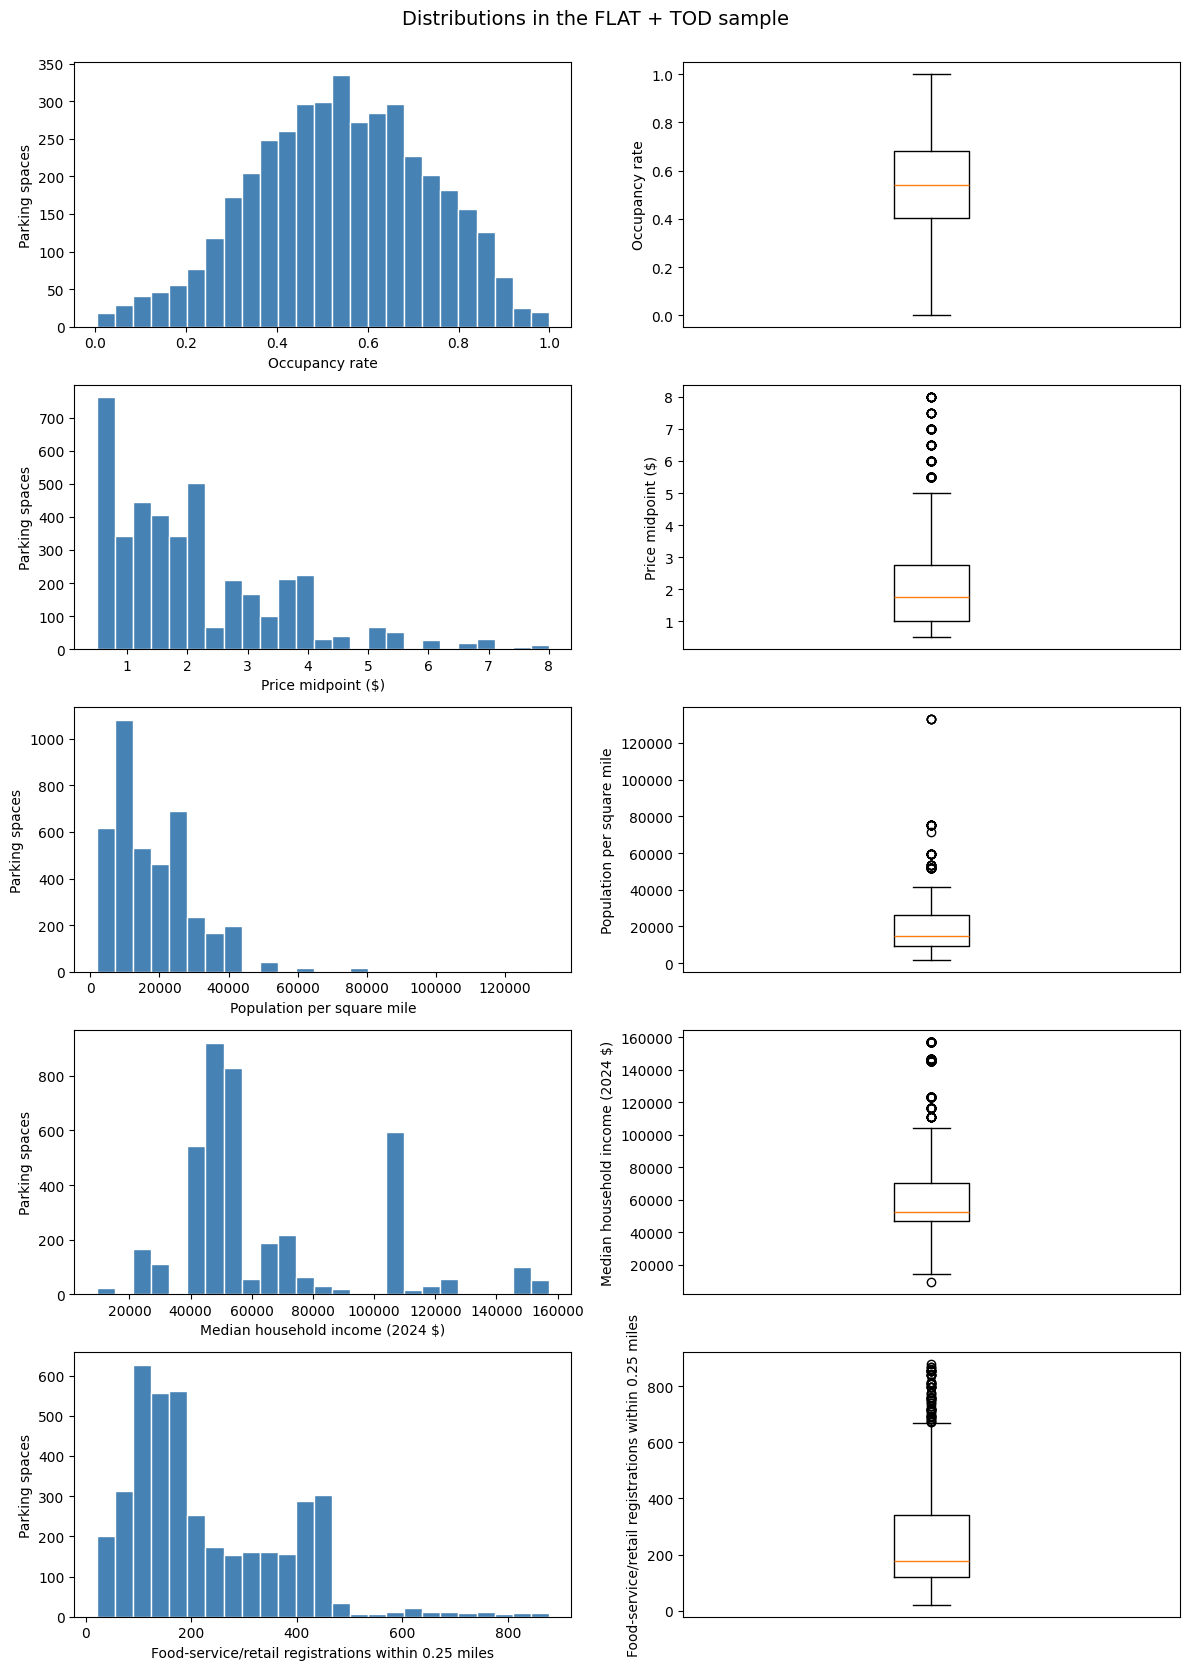

## 7. Explore occupancy relationships

I compare occupancy with price, population density, income, food-service/retail registrations, and the drive-alone share. Transparent points help with overlap, but repeated tract values and discrete prices still create vertical bands. These are unadjusted relationships; I do not fit regression lines or interpret them as causal effects.

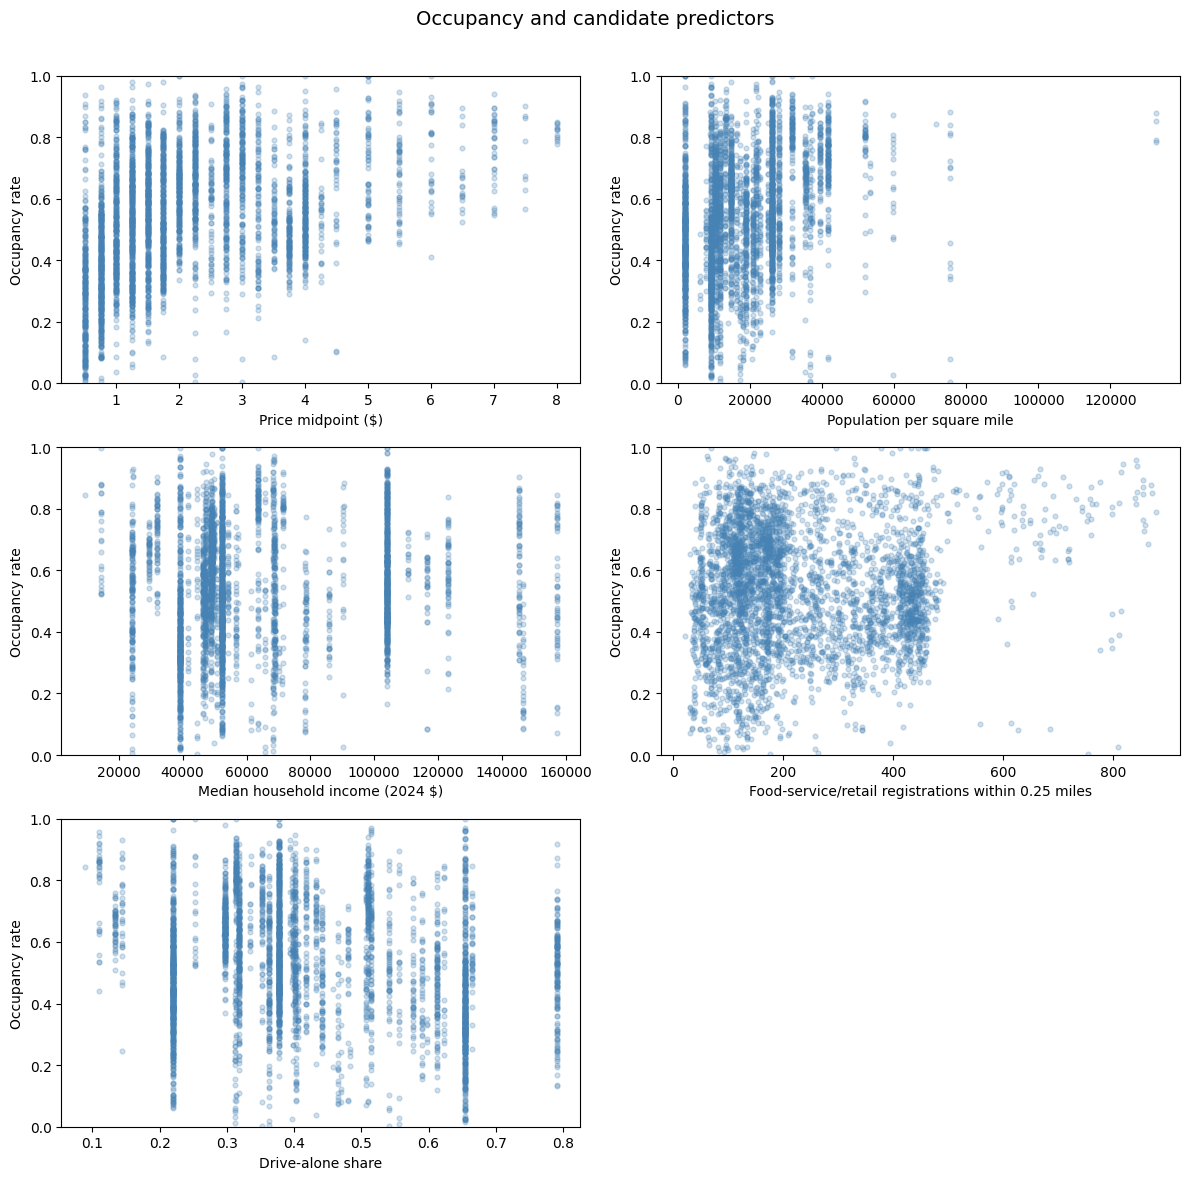

## 8. Compare correlations

I calculate Pearson correlations for the outcome and numeric candidates, including the additional density and business measures for comparison. Pandas uses available pairs: correlations involving income use 4,016 spaces and the other pairs use 4,060. The table and heatmap help identify overlapping information, not select the final predictors.

,occupancy_rate,price_midpoint,time_limit_hours,population_density,median_income,nearby_restaurant_retail_count,drive_alone_share,housing_density,transit_share,walk_share,nearby_business_count
occupancy_rate,1.000,0.394,-0.089,0.322,0.073,0.080,-0.197,0.295,-0.092,0.260,0.192
price_midpoint,0.394,1.000,-0.238,0.218,0.105,0.545,-0.341,0.281,-0.077,0.207,0.586
time_limit_hours,-0.089,-0.238,1.000,-0.067,-0.080,-0.089,0.095,-0.037,0.204,-0.122,-0.099
population_density,0.322,0.218,-0.067,1.000,0.131,0.130,0.094,0.925,0.029,0.047,0.185
median_income,0.073,0.105,-0.080,0.131,1.000,-0.014,-0.106,0.241,-0.593,-0.072,0.019
nearby_restaurant_retail_count,0.080,0.545,-0.089,0.130,-0.014,1.000,-0.398,0.279,0.050,0.143,0.898
drive_alone_share,-0.197,-0.341,0.095,0.094,-0.106,-0.398,1.000,0.023,0.360,-0.687,-0.471
housing_density,0.295,0.281,-0.037,0.925,0.241,0.279,0.023,1.000,-0.019,-0.043,0.329
transit_share,-0.092,-0.077,0.204,0.029,-0.593,0.050,0.360,-0.019,1.000,-0.363,-0.061
walk_share,0.260,0.207,-0.122,0.047,-0.072,0.143,-0.687,-0.043,-0.363,1.000,0.279


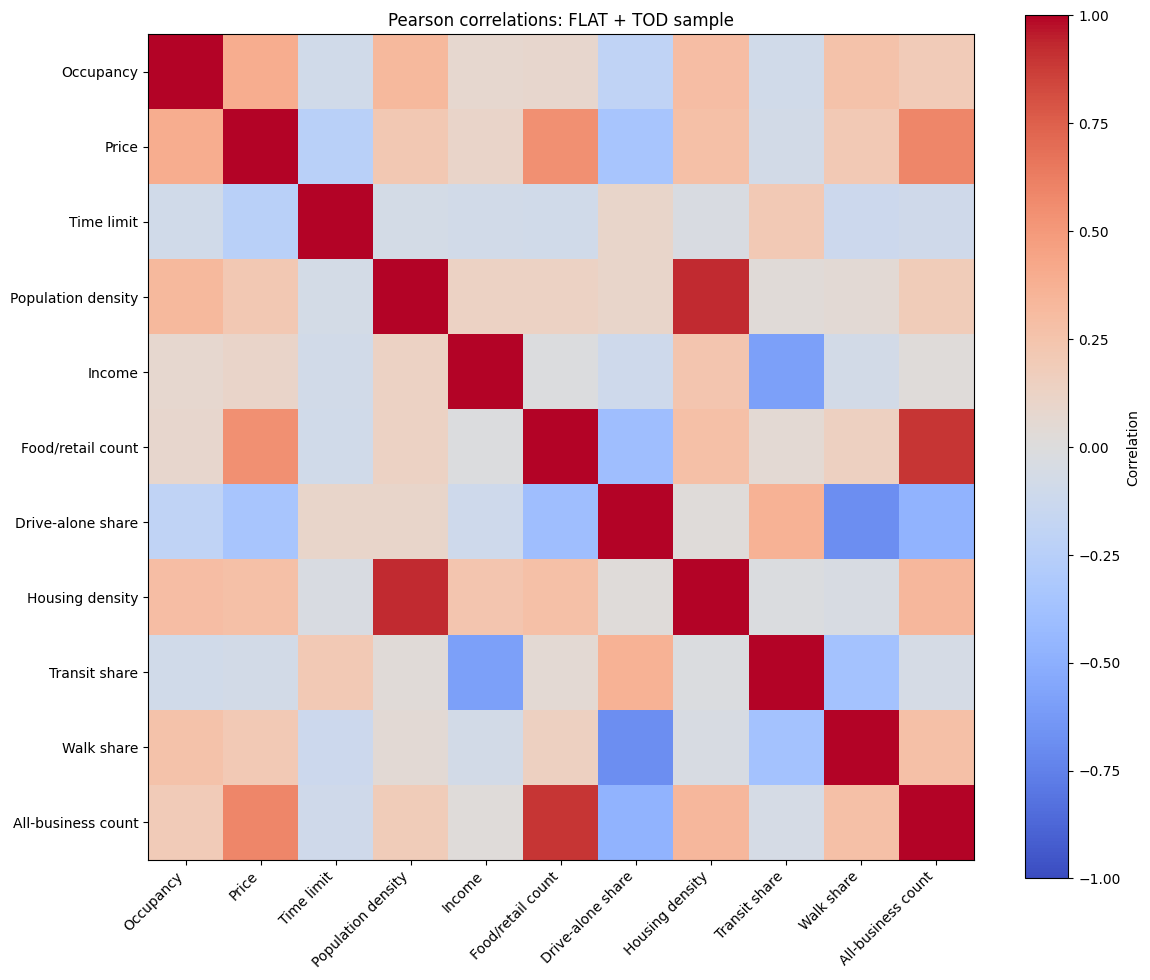

## 9. Flag extreme values without removing them

I use the usual 1.5-IQR fences as a descriptive screen, alongside the histograms and boxplots. The percentage below uses the nonmissing count for each variable. The rule can flag ordinary values for discrete variables, so it is not an automatic cleaning rule.

,observed_count,lower_fence,upper_fence,outside_count,outside_percent
occupancy_rate,4060,-0.012,1.094,0,0.000
price_midpoint,4060,-1.625,5.375,150,3.695
time_limit_hours,4060,2.000,2.000,1160,28.571
population_density,4060,-16260.332,51723.607,79,1.946
median_income,4016,11924.000,105332.000,251,6.250
nearby_restaurant_retail_count,4060,-212.500,671.500,59,1.453
drive_alone_share,4060,0.008,0.818,0,0.000
housing_density,4060,-16062.409,42621.149,36,0.887
transit_share,4060,-0.083,0.274,0,0.000
walk_share,4060,-0.134,0.371,82,2.020


,spaces,population_density,housing_density,median_income
GEOID,,,,
06037207304,4,132736.84,101157.89,14342.0
06037207307,15,75368.42,69894.74,NaN
06037206302,1,71611.11,43222.22,9375.0
06037207308,16,59666.67,53333.33,90156.0
06037265306,6,53333.33,14861.11,57188.0


,SpaceID,BlockFace,nearby_restaurant_retail_count,nearby_business_count,occupancy_rate
1466,CB3648B,501 SPRING ST,878,4467,0.789179
1468,CB3651,601 SPRING ST,870,4457,0.851962
1465,CB3648,501 SPRING ST,868,4406,0.878580
1912,CB4371,600 SPRING ST,862,4435,0.684367
1909,CB4368,600 SPRING ST,858,4399,0.746714


## 10. Summarize the EDA and hand off to Notebook 05

The main sample has **4,060 spaces**, after excluding 79 JUMP meters from the original 4,139. Mean time-weighted occupancy is about **0.539**. I explored price, time limits, population density, income, food-service/retail registrations, drive-alone share, and the additional meter, housing, commuting, and all-business candidates.

Income is missing for **44 spaces (1.08%)** in two tracts. The separate complete-case copy for the primary candidate list has **4,016 spaces**; the initial EDA sample keeps the missing incomes. Zoning is excluded from the analysis lists because of incomplete coverage, without deleting rows.

Price, density, income, and business measures have right tails. The density pair (0.925) and business-count pair (0.898) are strongly correlated, and price is related to commercial activity. The scatterplots show substantial variation and possible changes in shape or spread, but do not establish a nonlinear specification. Extreme densities and registration counts need careful interpretation rather than automatic trimming.

Notebook 05 should compare a small set of economically motivated candidates, using the food-service/retail count as the primary commercial measure and documenting each model's complete-case sample. Final predictor selection, categorical encoding, transformations, and regressions have not been performed. The 2026 price and business snapshots remain proxies for conditions around the August 2025 outcome.

Later robustness analysis should compare **12-, 24-, and 48-hour interval cutoffs**, **20-, 25-, and 28-active-day samples**, and **Sunday-reporting differences**. Those alternatives are not rebuilt here. All samples in this notebook stay in memory; the original processed cross-section and Notebooks 01–03 remain unchanged.

Original cross-section: (4139, 36)
Main EDA sample: (4060, 36)
Income-complete comparison: (4016, 36)
Main sample unique SpaceIDs: 4060
Main sample duplicate SpaceIDs: 0


In [35]:
from IPython.display import display, Markdown
display(Markdown('### Historical source: 04_eda.ipynb'))
_historical_bundles = [{'text/markdown': '# 04 — Exploratory Data Analysis\n\nI explore the saved parking-space cross-section before choosing regression predictors. I apply the approved FLAT + TOD restriction here, keep the original 4,139-space data available, and use descriptive tables and plots to understand the outcome and candidate variables. No regressions or new spatial measures are constructed in this notebook.'}, {'text/markdown': '## 1. Load the saved cross-section\n\nI start from the file produced by Notebook 03 rather than repeating its merges. SpaceID and Census GEOID are read as strings so their formatting is preserved. I inspect the first rows, dimensions, columns, and missing values before defining the analysis sample.'}, {'text/html': ['<div>\n', '<style scoped>\n', '    .dataframe tbody tr th:only-of-type {\n', '        vertical-align: middle;\n', '    }\n', '\n', '    .dataframe tbody tr th {\n', '        vertical-align: top;\n', '    }\n', '\n', '    .dataframe thead th {\n', '        text-align: right;\n', '    }\n', '</style>\n', '<table border="1" class="dataframe">\n', '  <thead>\n', '    <tr style="text-align: right;">\n', '      <th></th>\n', '      <th>SpaceID</th>\n', '      <th>occupancy_rate</th>\n', '      <th>occupied_minutes</th>\n', '      <th>total_minutes</th>\n', '      <th>active_days</th>\n', '      <th>BlockFace</th>\n', '      <th>MeterType</th>\n', '      <th>RateType</th>\n', '      <th>RateRange</th>\n', '      <th>MeteredTimeLimit</th>\n', '      <th>...</th>\n', '      <th>transit_share</th>\n', '      <th>walk_share</th>\n', '      <th>nearby_business_count</th>\n', '      <th>nearby_restaurant_retail_count</th>\n', '      <th>zoning_code</th>\n', '      <th>zoning_class</th>\n', '      <th>zoning_description</th>\n', '      <th>tract_match_status</th>\n', '      <th>acs_match_status</th>\n', '      <th>zoning_match_status</th>\n', '    </tr>\n', '  </thead>\n', '  <tbody>\n', '    <tr>\n', '      <th>0</th>\n', '      <td>61111</td>\n', '      <td>0.515520</td>\n', '      <td>19511.316667</td>\n', '      <td>37847.833333</td>\n', '      <td>30</td>\n', '      <td>245 MAIN ST</td>\n', '      <td>Multi-Space</td>\n', '      <td>TOD</td>\n', '      <td>$0.50 - $1.50</td>\n', '      <td>2HR</td>\n', '      <td>...</td>\n', '      <td>0.0</td>\n', '      <td>0.022663</td>\n', '      <td>358</td>\n', '      <td>45</td>\n', '      <td>NaN</td>\n', '      <td>NaN</td>\n', '      <td>NaN</td>\n', '      <td>matched</td>\n', '      <td>matched</td>\n', '      <td>unmatched</td>\n', '    </tr>\n', '    <tr>\n', '      <th>1</th>\n', '      <td>61112</td>\n', '      <td>0.468853</td>\n', '      <td>17954.033333</td>\n', '      <td>38293.550000</td>\n', '      <td>30</td>\n', '      <td>245 MAIN ST</td>\n', '      <td>Multi-Space</td>\n', '      <td>TOD</td>\n', '      <td>$0.50 - $1.50</td>\n', '      <td>2HR</td>\n', '      <td>...</td>\n', '      <td>0.0</td>\n', '      <td>0.022663</td>\n', '      <td>368</td>\n', '      <td>46</td>\n', '      <td>NaN</td>\n', '      <td>NaN</td>\n', '      <td>NaN</td>\n', '      <td>matched</td>\n', '      <td>matched</td>\n', '      <td>unmatched</td>\n', '    </tr>\n', '    <tr>\n', '      <th>2</th>\n', '      <td>61113</td>\n', '      <td>0.540309</td>\n', '      <td>21939.050000</td>\n', '      <td>40604.650000</td>\n', '      <td>30</td>\n', '      <td>245 MAIN ST</td>\n', '      <td>Multi-Space</td>\n', '      <td>TOD</td>\n', '      <td>$0.50 - $1.50</td>\n', '      <td>2HR</td>\n', '      <td>...</td>\n', '      <td>0.0</td>\n', '      <td>0.022663</td>\n', '      <td>371</td>\n', '      <td>47</td>\n', '      <td>NaN</td>\n', '      <td>NaN</td>\n', '      <td>NaN</td>\n', '      <td>matched</td>\n', '      <td>matched</td>\n', '      <td>unmatched</td>\n', '    </tr>\n', '    <tr>\n', '      <th>3</th>\n', '      <td>61114</td>\n', '      <td>0.594108</td>\n', '      <td>26049.100000</td>\n', '      <td>43845.700000</td>\n', '      <td>31</td>\n', '      <td>245 MAIN ST</td>\n', '      <td>Multi-Space</td>\n', '      <td>TOD</td>\n', '      <td>$0.50 - $1.50</td>\n', '      <td>2HR</td>\n', '      <td>...</td>\n', '      <td>0.0</td>\n', '      <td>0.022663</td>\n', '      <td>371</td>\n', '      <td>46</td>\n', '      <td>NaN</td>\n', '      <td>NaN</td>\n', '      <td>NaN</td>\n', '      <td>matched</td>\n', '      <td>matched</td>\n', '      <td>unmatched</td>\n', '    </tr>\n', '    <tr>\n', '      <th>4</th>\n', '      <td>61116</td>\n', '      <td>0.524689</td>\n', '      <td>22993.916667</td>\n', '      <td>43823.916667</td>\n', '      <td>31</td>\n', '      <td>245 MAIN ST</td>\n', '      <td>Multi-Space</td>\n', '      <td>TOD</td>\n', '      <td>$0.50 - $1.50</td>\n', '      <td>2HR</td>\n', '      <td>...</td>\n', '      <td>0.0</td>\n', '      <td>0.022663</td>\n', '      <td>375</td>\n', '      <td>47</td>\n', '      <td>NaN</td>\n', '      <td>NaN</td>\n', '      <td>NaN</td>\n', '      <td>matched</td>\n', '      <td>matched</td>\n', '      <td>unmatched</td>\n', '    </tr>\n', '  </tbody>\n', '</table>\n', '<p>5 rows × 36 columns</p>\n', '</div>'], 'text/plain': ['  SpaceID  occupancy_rate  occupied_minutes  total_minutes  active_days  \\\n', '0   61111        0.515520      19511.316667   37847.833333           30   \n', '1   61112        0.468853      17954.033333   38293.550000           30   \n', '2   61113        0.540309      21939.050000   40604.650000           30   \n', '3   61114        0.594108      26049.100000   43845.700000           31   \n', '4   61116        0.524689      22993.916667   43823.916667           31   \n', '\n', '     BlockFace    MeterType RateType      RateRange MeteredTimeLimit  ...  \\\n', '0  245 MAIN ST  Multi-Space      TOD  $0.50 - $1.50              2HR  ...   \n', '1  245 MAIN ST  Multi-Space      TOD  $0.50 - $1.50              2HR  ...   \n', '2  245 MAIN ST  Multi-Space      TOD  $0.50 - $1.50              2HR  ...   \n', '3  245 MAIN ST  Multi-Space      TOD  $0.50 - $1.50              2HR  ...   \n', '4  245 MAIN ST  Multi-Space      TOD  $0.50 - $1.50              2HR  ...   \n', '\n', '   transit_share  walk_share  nearby_business_count  \\\n', '0            0.0    0.022663                    358   \n', '1            0.0    0.022663                    368   \n', '2            0.0    0.022663                    371   \n', '3            0.0    0.022663                    371   \n', '4            0.0    0.022663                    375   \n', '\n', '   nearby_restaurant_retail_count zoning_code  zoning_class  \\\n', '0                              45         NaN           NaN   \n', '1                              46         NaN           NaN   \n', '2                              47         NaN           NaN   \n', '3                              46         NaN           NaN   \n', '4                              47         NaN           NaN   \n', '\n', '   zoning_description  tract_match_status  acs_match_status  \\\n', '0                 NaN             matched           matched   \n', '1                 NaN             matched           matched   \n', '2                 NaN             matched           matched   \n', '3                 NaN             matched           matched   \n', '4                 NaN             matched           matched   \n', '\n', '   zoning_match_status  \n', '0            unmatched  \n', '1            unmatched  \n', '2            unmatched  \n', '3            unmatched  \n', '4            unmatched  \n', '\n', '[5 rows x 36 columns]']}, {'text/plain': "Original rows and columns: (4139, 36)\nUnique SpaceIDs: 4139\nDuplicate SpaceIDs: 0\nColumns:\n['SpaceID', 'occupancy_rate', 'occupied_minutes', 'total_minutes', 'active_days', 'BlockFace', 'MeterType', 'RateType', 'RateRange', 'MeteredTimeLimit', 'price_midpoint', 'time_limit_hours', 'latitude', 'longitude', 'GEOID', 'population', 'median_income', 'housing_units', 'commuters', 'drive_alone', 'public_transit', 'walked', 'ALAND_SQMI', 'population_density', 'housing_density', 'drive_alone_share', 'transit_share', 'walk_share', 'nearby_business_count', 'nearby_restaurant_retail_count', 'zoning_code', 'zoning_class', 'zoning_description', 'tract_match_status', 'acs_match_status', 'zoning_match_status']\n"}, {'text/html': ['<div>\n', '<style scoped>\n', '    .dataframe tbody tr th:only-of-type {\n', '        vertical-align: middle;\n', '    }\n', '\n', '    .dataframe tbody tr th {\n', '        vertical-align: top;\n', '    }\n', '\n', '    .dataframe thead th {\n', '        text-align: right;\n', '    }\n', '</style>\n', '<table border="1" class="dataframe">\n', '  <thead>\n', '    <tr style="text-align: right;">\n', '      <th></th>\n', '      <th>missing_count</th>\n', '      <th>missing_percent</th>\n', '    </tr>\n', '  </thead>\n', '  <tbody>\n', '    <tr>\n', '      <th>SpaceID</th>\n', '      <td>0</td>\n', '      <td>0.00</td>\n', '    </tr>\n', '    <tr>\n', '      <th>occupancy_rate</th>\n', '      <td>0</td>\n', '      <td>0.00</td>\n', '    </tr>\n', '    <tr>\n', '      <th>occupied_minutes</th>\n', '      <td>0</td>\n', '      <td>0.00</td>\n', '    </tr>\n', '    <tr>\n', '      <th>total_minutes</th>\n', '      <td>0</td>\n', '      <td>0.00</td>\n', '    </tr>\n', '    <tr>\n', '      <th>active_days</th>\n', '      <td>0</td>\n', '      <td>0.00</td>\n', '    </tr>\n', '    <tr>\n', '      <th>BlockFace</th>\n', '      <td>0</td>\n', '      <td>0.00</td>\n', '    </tr>\n', '    <tr>\n', '      <th>MeterType</th>\n', '      <td>0</td>\n', '      <td>0.00</td>\n', '    </tr>\n', '    <tr>\n', '      <th>RateType</th>\n', '      <td>0</td>\n', '      <td>0.00</td>\n', '    </tr>\n', '    <tr>\n', '      <th>RateRange</th>\n', '      <td>0</td>\n', '      <td>0.00</td>\n', '    </tr>\n', '    <tr>\n', '      <th>MeteredTimeLimit</th>\n', '      <td>0</td>\n', '      <td>0.00</td>\n', '    </tr>\n', '    <tr>\n', '      <th>price_midpoint</th>\n', '      <td>0</td>\n', '      <td>0.00</td>\n', '    </tr>\n', '    <tr>\n', '      <th>time_limit_hours</th>\n', '      <td>0</td>\n', '      <td>0.00</td>\n', '    </tr>\n', '    <tr>\n', '      <th>latitude</th>\n', '      <td>0</td>\n', '      <td>0.00</td>\n', '    </tr>\n', '    <tr>\n', '      <th>longitude</th>\n', '      <td>0</td>\n', '      <td>0.00</td>\n', '    </tr>\n', '    <tr>\n', '      <th>GEOID</th>\n', '      <td>0</td>\n', '      <td>0.00</td>\n', '    </tr>\n', '    <tr>\n', '      <th>population</th>\n', '      <td>0</td>\n', '      <td>0.00</td>\n', '    </tr>\n', '    <tr>\n', '      <th>median_income</th>\n', '      <td>44</td>\n', '      <td>1.06</td>\n', '    </tr>\n', '    <tr>\n', '      <th>housing_units</th>\n', '      <td>0</td>\n', '      <td>0.00</td>\n', '    </tr>\n', '    <tr>\n', '      <th>commuters</th>\n', '      <td>0</td>\n', '      <td>0.00</td>\n', '    </tr>\n', '    <tr>\n', '      <th>drive_alone</th>\n', '      <td>0</td>\n', '      <td>0.00</td>\n', '    </tr>\n', '    <tr>\n', '      <th>public_transit</th>\n', '      <td>0</td>\n', '      <td>0.00</td>\n', '    </tr>\n', '    <tr>\n', '      <th>walked</th>\n', '      <td>0</td>\n', '      <td>0.00</td>\n', '    </tr>\n', '    <tr>\n', '      <th>ALAND_SQMI</th>\n', '      <td>0</td>\n', '      <td>0.00</td>\n', '    </tr>\n', '    <tr>\n', '      <th>population_density</th>\n', '      <td>0</td>\n', '      <td>0.00</td>\n', '    </tr>\n', '    <tr>\n', '      <th>housing_density</th>\n', '      <td>0</td>\n', '      <td>0.00</td>\n', '    </tr>\n', '    <tr>\n', '      <th>drive_alone_share</th>\n', '      <td>0</td>\n', '      <td>0.00</td>\n', '    </tr>\n', '    <tr>\n', '      <th>transit_share</th>\n', '      <td>0</td>\n', '      <td>0.00</td>\n', '    </tr>\n', '    <tr>\n', '      <th>walk_share</th>\n', '      <td>0</td>\n', '      <td>0.00</td>\n', '    </tr>\n', '    <tr>\n', '      <th>nearby_business_count</th>\n', '      <td>0</td>\n', '      <td>0.00</td>\n', '    </tr>\n', '    <tr>\n', '      <th>nearby_restaurant_retail_count</th>\n', '      <td>0</td>\n', '      <td>0.00</td>\n', '    </tr>\n', '    <tr>\n', '      <th>zoning_code</th>\n', '      <td>4090</td>\n', '      <td>98.82</td>\n', '    </tr>\n', '    <tr>\n', '      <th>zoning_class</th>\n', '      <td>4119</td>\n', '      <td>99.52</td>\n', '    </tr>\n', '    <tr>\n', '      <th>zoning_description</th>\n', '      <td>4091</td>\n', '      <td>98.84</td>\n', '    </tr>\n', '    <tr>\n', '      <th>tract_match_status</th>\n', '      <td>0</td>\n', '      <td>0.00</td>\n', '    </tr>\n', '    <tr>\n', '      <th>acs_match_status</th>\n', '      <td>0</td>\n', '      <td>0.00</td>\n', '    </tr>\n', '    <tr>\n', '      <th>zoning_match_status</th>\n', '      <td>0</td>\n', '      <td>0.00</td>\n', '    </tr>\n', '  </tbody>\n', '</table>\n', '</div>'], 'text/plain': ['                                missing_count  missing_percent\n', 'SpaceID                                     0             0.00\n', 'occupancy_rate                              0             0.00\n', 'occupied_minutes                            0             0.00\n', 'total_minutes                               0             0.00\n', 'active_days                                 0             0.00\n', 'BlockFace                                   0             0.00\n', 'MeterType                                   0             0.00\n', 'RateType                                    0             0.00\n', 'RateRange                                   0             0.00\n', 'MeteredTimeLimit                            0             0.00\n', 'price_midpoint                              0             0.00\n', 'time_limit_hours                            0             0.00\n', 'latitude                                    0             0.00\n', 'longitude                                   0             0.00\n', 'GEOID                                       0             0.00\n', 'population                                  0             0.00\n', 'median_income                              44             1.06\n', 'housing_units                               0             0.00\n', 'commuters                                   0             0.00\n', 'drive_alone                                 0             0.00\n', 'public_transit                              0             0.00\n', 'walked                                      0             0.00\n', 'ALAND_SQMI                                  0             0.00\n', 'population_density                          0             0.00\n', 'housing_density                             0             0.00\n', 'drive_alone_share                           0             0.00\n', 'transit_share                               0             0.00\n', 'walk_share                                  0             0.00\n', 'nearby_business_count                       0             0.00\n', 'nearby_restaurant_retail_count              0             0.00\n', 'zoning_code                              4090            98.82\n', 'zoning_class                             4119            99.52\n', 'zoning_description                       4091            98.84\n', 'tract_match_status                          0             0.00\n', 'acs_match_status                            0             0.00\n', 'zoning_match_status                         0             0.00']}, {'text/markdown': '## 2. Define the main FLAT + TOD sample\n\nI retain FLAT and TOD meters for the main numeric-price analysis. The JUMP midpoint averages an hourly charge with a multi-hour maximum charge, so it is not comparable. I filter a separate copy and preserve `parking_full` for later comparisons.'}, {'text/plain': 'Sample before filtering: 4139\nJUMP spaces removed: 79\nMain sample: 4060\nTotal spaces excluded: 79\n'}, {'text/plain': ['RateType\n', 'TOD     3323\n', 'FLAT     737\n', 'Name: count, dtype: int64']}, {'text/markdown': '## 3. Identify the outcome and candidate predictors\n\nThe dependent variable remains time-weighted August 2025 `occupancy_rate`. Notebook 01 uses OCCUPIED and VACANT intervals, excludes UNKNOWN states and intervals longer than 24 hours, and requires at least 25 calendar days with sensor transactions. A recorded state is assumed to persist until the next recorded transaction over retained intervals; active days are not necessarily complete monitoring days.\n\nI separate the primary candidate list from additional variables worth exploring. These lists guide EDA and do not select a final regression specification.'}, {'text/plain': "Dependent variable: occupancy_rate\nPrimary candidate predictors: ['price_midpoint', 'time_limit_hours', 'population_density', 'median_income', 'nearby_restaurant_retail_count', 'drive_alone_share', 'RateType']\nAdditional candidates: ['MeterType', 'housing_density', 'transit_share', 'walk_share', 'nearby_business_count']\nMeter types:\nMeterType\nSingle-Space    3927\nMulti-Space      133\nName: count, dtype: int64\n"}, {'text/markdown': '## 4. Summarize the numeric variables\n\nI calculate the main descriptive statistics for the outcome and numeric candidates. Density is measured per square mile of tract land, income is in 2024 dollars, and occupancy and commuting shares run from zero to one. Pandas reports excess kurtosis, so a normal distribution has a reference value of zero.'}, {'text/html': ['<div>\n', '<style scoped>\n', '    .dataframe tbody tr th:only-of-type {\n', '        vertical-align: middle;\n', '    }\n', '\n', '    .dataframe tbody tr th {\n', '        vertical-align: top;\n', '    }\n', '\n', '    .dataframe thead th {\n', '        text-align: right;\n', '    }\n', '</style>\n', '<table border="1" class="dataframe">\n', '  <thead>\n', '    <tr style="text-align: right;">\n', '      <th></th>\n', '      <th>count</th>\n', '      <th>mean</th>\n', '      <th>median</th>\n', '      <th>std</th>\n', '      <th>min</th>\n', '      <th>max</th>\n', '      <th>skewness</th>\n', '      <th>excess_kurtosis</th>\n', '    </tr>\n', '  </thead>\n', '  <tbody>\n', '    <tr>\n', '      <th>occupancy_rate</th>\n', '      <td>4060.0</td>\n', '      <td>0.539</td>\n', '      <td>0.539</td>\n', '      <td>0.194</td>\n', '      <td>0.004</td>\n', '      <td>0.999</td>\n', '      <td>-0.160</td>\n', '      <td>-0.424</td>\n', '    </tr>\n', '    <tr>\n', '      <th>price_midpoint</th>\n', '      <td>4060.0</td>\n', '      <td>2.092</td>\n', '      <td>1.750</td>\n', '      <td>1.400</td>\n', '      <td>0.500</td>\n', '      <td>8.000</td>\n', '      <td>1.338</td>\n', '      <td>1.873</td>\n', '    </tr>\n', '    <tr>\n', '      <th>time_limit_hours</th>\n', '      <td>4060.0</td>\n', '      <td>2.446</td>\n', '      <td>2.000</td>\n', '      <td>0.925</td>\n', '      <td>0.250</td>\n', '      <td>4.000</td>\n', '      <td>0.811</td>\n', '      <td>-0.419</td>\n', '    </tr>\n', '    <tr>\n', '      <th>population_density</th>\n', '      <td>4060.0</td>\n', '      <td>18006.954</td>\n', '      <td>14754.902</td>\n', '      <td>12710.083</td>\n', '      <td>1915.323</td>\n', '      <td>132736.842</td>\n', '      <td>1.547</td>\n', '      <td>7.374</td>\n', '    </tr>\n', '    <tr>\n', '      <th>median_income</th>\n', '      <td>4016.0</td>\n', '      <td>63083.058</td>\n', '      <td>52412.000</td>\n', '      <td>29658.373</td>\n', '      <td>9375.000</td>\n', '      <td>157115.000</td>\n', '      <td>1.251</td>\n', '      <td>0.942</td>\n', '    </tr>\n', '    <tr>\n', '      <th>nearby_restaurant_retail_count</th>\n', '      <td>4060.0</td>\n', '      <td>230.007</td>\n', '      <td>176.000</td>\n', '      <td>148.842</td>\n', '      <td>21.000</td>\n', '      <td>878.000</td>\n', '      <td>1.148</td>\n', '      <td>1.336</td>\n', '    </tr>\n', '    <tr>\n', '      <th>drive_alone_share</th>\n', '      <td>4060.0</td>\n', '      <td>0.417</td>\n', '      <td>0.378</td>\n', '      <td>0.162</td>\n', '      <td>0.089</td>\n', '      <td>0.790</td>\n', '      <td>0.504</td>\n', '      <td>-0.568</td>\n', '    </tr>\n', '    <tr>\n', '      <th>housing_density</th>\n', '      <td>4060.0</td>\n', '      <td>12335.445</td>\n', '      <td>9015.957</td>\n', '      <td>9824.718</td>\n', '      <td>0.000</td>\n', '      <td>101157.895</td>\n', '      <td>2.163</td>\n', '      <td>10.791</td>\n', '    </tr>\n', '    <tr>\n', '      <th>transit_share</th>\n', '      <td>4060.0</td>\n', '      <td>0.095</td>\n', '      <td>0.071</td>\n', '      <td>0.062</td>\n', '      <td>0.000</td>\n', '      <td>0.271</td>\n', '      <td>0.331</td>\n', '      <td>-0.962</td>\n', '    </tr>\n', '    <tr>\n', '      <th>walk_share</th>\n', '      <td>4060.0</td>\n', '      <td>0.141</td>\n', '      <td>0.125</td>\n', '      <td>0.112</td>\n', '      <td>0.000</td>\n', '      <td>0.627</td>\n', '      <td>1.640</td>\n', '      <td>4.218</td>\n', '    </tr>\n', '    <tr>\n', '      <th>nearby_business_count</th>\n', '      <td>4060.0</td>\n', '      <td>1183.856</td>\n', '      <td>955.000</td>\n', '      <td>708.001</td>\n', '      <td>129.000</td>\n', '      <td>4825.000</td>\n', '      <td>1.774</td>\n', '      <td>4.767</td>\n', '    </tr>\n', '  </tbody>\n', '</table>\n', '</div>'], 'text/plain': ['                                 count       mean     median        std  \\\n', 'occupancy_rate                  4060.0      0.539      0.539      0.194   \n', 'price_midpoint                  4060.0      2.092      1.750      1.400   \n', 'time_limit_hours                4060.0      2.446      2.000      0.925   \n', 'population_density              4060.0  18006.954  14754.902  12710.083   \n', 'median_income                   4016.0  63083.058  52412.000  29658.373   \n', 'nearby_restaurant_retail_count  4060.0    230.007    176.000    148.842   \n', 'drive_alone_share               4060.0      0.417      0.378      0.162   \n', 'housing_density                 4060.0  12335.445   9015.957   9824.718   \n', 'transit_share                   4060.0      0.095      0.071      0.062   \n', 'walk_share                      4060.0      0.141      0.125      0.112   \n', 'nearby_business_count           4060.0   1183.856    955.000    708.001   \n', '\n', '                                     min         max  skewness  \\\n', 'occupancy_rate                     0.004       0.999    -0.160   \n', 'price_midpoint                     0.500       8.000     1.338   \n', 'time_limit_hours                   0.250       4.000     0.811   \n', 'population_density              1915.323  132736.842     1.547   \n', 'median_income                   9375.000  157115.000     1.251   \n', 'nearby_restaurant_retail_count    21.000     878.000     1.148   \n', 'drive_alone_share                  0.089       0.790     0.504   \n', 'housing_density                    0.000  101157.895     2.163   \n', 'transit_share                      0.000       0.271     0.331   \n', 'walk_share                         0.000       0.627     1.640   \n', 'nearby_business_count            129.000    4825.000     1.774   \n', '\n', '                                excess_kurtosis  \n', 'occupancy_rate                           -0.424  \n', 'price_midpoint                            1.873  \n', 'time_limit_hours                         -0.419  \n', 'population_density                        7.374  \n', 'median_income                             0.942  \n', 'nearby_restaurant_retail_count            1.336  \n', 'drive_alone_share                        -0.568  \n', 'housing_density                          10.791  \n', 'transit_share                            -0.962  \n', 'walk_share                                4.218  \n', 'nearby_business_count                     4.767  ']}, {'text/markdown': '## 5. Inspect missing income and prepare a comparison sample\n\nI show missingness for the outcome and both candidate lists, using the 4,060-space EDA sample as the denominator. Income remains missing rather than being imputed, and I keep those observations in the initial EDA sample. The tract breakdown checks whether missing income is geographically concentrated.'}, {'text/plain': 'Original sample income missing: 44\nOriginal sample income missing (%): 1.06\nMain EDA sample: 4060\n'}, {'text/html': ['<div>\n', '<style scoped>\n', '    .dataframe tbody tr th:only-of-type {\n', '        vertical-align: middle;\n', '    }\n', '\n', '    .dataframe tbody tr th {\n', '        vertical-align: top;\n', '    }\n', '\n', '    .dataframe thead th {\n', '        text-align: right;\n', '    }\n', '</style>\n', '<table border="1" class="dataframe">\n', '  <thead>\n', '    <tr style="text-align: right;">\n', '      <th></th>\n', '      <th>missing_count</th>\n', '      <th>missing_percent</th>\n', '    </tr>\n', '  </thead>\n', '  <tbody>\n', '    <tr>\n', '      <th>occupancy_rate</th>\n', '      <td>0</td>\n', '      <td>0.00</td>\n', '    </tr>\n', '    <tr>\n', '      <th>price_midpoint</th>\n', '      <td>0</td>\n', '      <td>0.00</td>\n', '    </tr>\n', '    <tr>\n', '      <th>time_limit_hours</th>\n', '      <td>0</td>\n', '      <td>0.00</td>\n', '    </tr>\n', '    <tr>\n', '      <th>population_density</th>\n', '      <td>0</td>\n', '      <td>0.00</td>\n', '    </tr>\n', '    <tr>\n', '      <th>median_income</th>\n', '      <td>44</td>\n', '      <td>1.08</td>\n', '    </tr>\n', '    <tr>\n', '      <th>nearby_restaurant_retail_count</th>\n', '      <td>0</td>\n', '      <td>0.00</td>\n', '    </tr>\n', '    <tr>\n', '      <th>drive_alone_share</th>\n', '      <td>0</td>\n', '      <td>0.00</td>\n', '    </tr>\n', '    <tr>\n', '      <th>RateType</th>\n', '      <td>0</td>\n', '      <td>0.00</td>\n', '    </tr>\n', '    <tr>\n', '      <th>MeterType</th>\n', '      <td>0</td>\n', '      <td>0.00</td>\n', '    </tr>\n', '    <tr>\n', '      <th>housing_density</th>\n', '      <td>0</td>\n', '      <td>0.00</td>\n', '    </tr>\n', '    <tr>\n', '      <th>transit_share</th>\n', '      <td>0</td>\n', '      <td>0.00</td>\n', '    </tr>\n', '    <tr>\n', '      <th>walk_share</th>\n', '      <td>0</td>\n', '      <td>0.00</td>\n', '    </tr>\n', '    <tr>\n', '      <th>nearby_business_count</th>\n', '      <td>0</td>\n', '      <td>0.00</td>\n', '    </tr>\n', '  </tbody>\n', '</table>\n', '</div>'], 'text/plain': ['                                missing_count  missing_percent\n', 'occupancy_rate                              0             0.00\n', 'price_midpoint                              0             0.00\n', 'time_limit_hours                            0             0.00\n', 'population_density                          0             0.00\n', 'median_income                              44             1.08\n', 'nearby_restaurant_retail_count              0             0.00\n', 'drive_alone_share                           0             0.00\n', 'RateType                                    0             0.00\n', 'MeterType                                   0             0.00\n', 'housing_density                             0             0.00\n', 'transit_share                               0             0.00\n', 'walk_share                                  0             0.00\n', 'nearby_business_count                       0             0.00']}, {'text/html': ['<div>\n', '<style scoped>\n', '    .dataframe tbody tr th:only-of-type {\n', '        vertical-align: middle;\n', '    }\n', '\n', '    .dataframe tbody tr th {\n', '        vertical-align: top;\n', '    }\n', '\n', '    .dataframe thead th {\n', '        text-align: right;\n', '    }\n', '</style>\n', '<table border="1" class="dataframe">\n', '  <thead>\n', '    <tr style="text-align: right;">\n', '      <th></th>\n', '      <th>spaces</th>\n', '      <th>mean_occupancy</th>\n', '    </tr>\n', '    <tr>\n', '      <th>GEOID</th>\n', '      <th></th>\n', '      <th></th>\n', '    </tr>\n', '  </thead>\n', '  <tbody>\n', '    <tr>\n', '      <th>06037207307</th>\n', '      <td>15</td>\n', '      <td>0.541551</td>\n', '    </tr>\n', '    <tr>\n', '      <th>06037265301</th>\n', '      <td>29</td>\n', '      <td>0.678567</td>\n', '    </tr>\n', '  </tbody>\n', '</table>\n', '</div>'], 'text/plain': ['             spaces  mean_occupancy\n', 'GEOID                              \n', '06037207307      15        0.541551\n', '06037265301      29        0.678567']}, {'text/plain': 'Main EDA sample: 4060\nComplete cases for the outcome and primary candidates: 4016\nSpaces excluded from this comparison: 44\nIncome-complete rate types:\nRateType\nTOD     3279\nFLAT     737\nName: count, dtype: int64\n'}, {'text/markdown': '## 6. Inspect histograms and boxplots\n\nI plot occupancy, price, population density, income, and the food-service/retail count in their original units. Histograms show the overall shape, while boxplots make long tails and extreme values easier to see. Income plots omit only missing income values; the other plots use all 4,060 spaces.'}, {'image/png': '...', 'text/plain': ['<Figure size 1200x1700 with 10 Axes>']}, {'text/markdown': '## 7. Explore occupancy relationships\n\nI compare occupancy with price, population density, income, food-service/retail registrations, and the drive-alone share. Transparent points help with overlap, but repeated tract values and discrete prices still create vertical bands. These are unadjusted relationships; I do not fit regression lines or interpret them as causal effects.'}, {'image/png': '...', 'text/plain': ['<Figure size 1200x1200 with 6 Axes>']}, {'text/markdown': '## 8. Compare correlations\n\nI calculate Pearson correlations for the outcome and numeric candidates, including the additional density and business measures for comparison. Pandas uses available pairs: correlations involving income use 4,016 spaces and the other pairs use 4,060. The table and heatmap help identify overlapping information, not select the final predictors.'}, {'text/html': ['<div>\n', '<style scoped>\n', '    .dataframe tbody tr th:only-of-type {\n', '        vertical-align: middle;\n', '    }\n', '\n', '    .dataframe tbody tr th {\n', '        vertical-align: top;\n', '    }\n', '\n', '    .dataframe thead th {\n', '        text-align: right;\n', '    }\n', '</style>\n', '<table border="1" class="dataframe">\n', '  <thead>\n', '    <tr style="text-align: right;">\n', '      <th></th>\n', '      <th>occupancy_rate</th>\n', '      <th>price_midpoint</th>\n', '      <th>time_limit_hours</th>\n', '      <th>population_density</th>\n', '      <th>median_income</th>\n', '      <th>nearby_restaurant_retail_count</th>\n', '      <th>drive_alone_share</th>\n', '      <th>housing_density</th>\n', '      <th>transit_share</th>\n', '      <th>walk_share</th>\n', '      <th>nearby_business_count</th>\n', '    </tr>\n', '  </thead>\n', '  <tbody>\n', '    <tr>\n', '      <th>occupancy_rate</th>\n', '      <td>1.000</td>\n', '      <td>0.394</td>\n', '      <td>-0.089</td>\n', '      <td>0.322</td>\n', '      <td>0.073</td>\n', '      <td>0.080</td>\n', '      <td>-0.197</td>\n', '      <td>0.295</td>\n', '      <td>-0.092</td>\n', '      <td>0.260</td>\n', '      <td>0.192</td>\n', '    </tr>\n', '    <tr>\n', '      <th>price_midpoint</th>\n', '      <td>0.394</td>\n', '      <td>1.000</td>\n', '      <td>-0.238</td>\n', '      <td>0.218</td>\n', '      <td>0.105</td>\n', '      <td>0.545</td>\n', '      <td>-0.341</td>\n', '      <td>0.281</td>\n', '      <td>-0.077</td>\n', '      <td>0.207</td>\n', '      <td>0.586</td>\n', '    </tr>\n', '    <tr>\n', '      <th>time_limit_hours</th>\n', '      <td>-0.089</td>\n', '      <td>-0.238</td>\n', '      <td>1.000</td>\n', '      <td>-0.067</td>\n', '      <td>-0.080</td>\n', '      <td>-0.089</td>\n', '      <td>0.095</td>\n', '      <td>-0.037</td>\n', '      <td>0.204</td>\n', '      <td>-0.122</td>\n', '      <td>-0.099</td>\n', '    </tr>\n', '    <tr>\n', '      <th>population_density</th>\n', '      <td>0.322</td>\n', '      <td>0.218</td>\n', '      <td>-0.067</td>\n', '      <td>1.000</td>\n', '      <td>0.131</td>\n', '      <td>0.130</td>\n', '      <td>0.094</td>\n', '      <td>0.925</td>\n', '      <td>0.029</td>\n', '      <td>0.047</td>\n', '      <td>0.185</td>\n', '    </tr>\n', '    <tr>\n', '      <th>median_income</th>\n', '      <td>0.073</td>\n', '      <td>0.105</td>\n', '      <td>-0.080</td>\n', '      <td>0.131</td>\n', '      <td>1.000</td>\n', '      <td>-0.014</td>\n', '      <td>-0.106</td>\n', '      <td>0.241</td>\n', '      <td>-0.593</td>\n', '      <td>-0.072</td>\n', '      <td>0.019</td>\n', '    </tr>\n', '    <tr>\n', '      <th>nearby_restaurant_retail_count</th>\n', '      <td>0.080</td>\n', '      <td>0.545</td>\n', '      <td>-0.089</td>\n', '      <td>0.130</td>\n', '      <td>-0.014</td>\n', '      <td>1.000</td>\n', '      <td>-0.398</td>\n', '      <td>0.279</td>\n', '      <td>0.050</td>\n', '      <td>0.143</td>\n', '      <td>0.898</td>\n', '    </tr>\n', '    <tr>\n', '      <th>drive_alone_share</th>\n', '      <td>-0.197</td>\n', '      <td>-0.341</td>\n', '      <td>0.095</td>\n', '      <td>0.094</td>\n', '      <td>-0.106</td>\n', '      <td>-0.398</td>\n', '      <td>1.000</td>\n', '      <td>0.023</td>\n', '      <td>0.360</td>\n', '      <td>-0.687</td>\n', '      <td>-0.471</td>\n', '    </tr>\n', '    <tr>\n', '      <th>housing_density</th>\n', '      <td>0.295</td>\n', '      <td>0.281</td>\n', '      <td>-0.037</td>\n', '      <td>0.925</td>\n', '      <td>0.241</td>\n', '      <td>0.279</td>\n', '      <td>0.023</td>\n', '      <td>1.000</td>\n', '      <td>-0.019</td>\n', '      <td>-0.043</td>\n', '      <td>0.329</td>\n', '    </tr>\n', '    <tr>\n', '      <th>transit_share</th>\n', '      <td>-0.092</td>\n', '      <td>-0.077</td>\n', '      <td>0.204</td>\n', '      <td>0.029</td>\n', '      <td>-0.593</td>\n', '      <td>0.050</td>\n', '      <td>0.360</td>\n', '      <td>-0.019</td>\n', '      <td>1.000</td>\n', '      <td>-0.363</td>\n', '      <td>-0.061</td>\n', '    </tr>\n', '    <tr>\n', '      <th>walk_share</th>\n', '      <td>0.260</td>\n', '      <td>0.207</td>\n', '      <td>-0.122</td>\n', '      <td>0.047</td>\n', '      <td>-0.072</td>\n', '      <td>0.143</td>\n', '      <td>-0.687</td>\n', '      <td>-0.043</td>\n', '      <td>-0.363</td>\n', '      <td>1.000</td>\n', '      <td>0.279</td>\n', '    </tr>\n', '    <tr>\n', '      <th>nearby_business_count</th>\n', '      <td>0.192</td>\n', '      <td>0.586</td>\n', '      <td>-0.099</td>\n', '      <td>0.185</td>\n', '      <td>0.019</td>\n', '      <td>0.898</td>\n', '      <td>-0.471</td>\n', '      <td>0.329</td>\n', '      <td>-0.061</td>\n', '      <td>0.279</td>\n', '      <td>1.000</td>\n', '    </tr>\n', '  </tbody>\n', '</table>\n', '</div>'], 'text/plain': ['                                occupancy_rate  price_midpoint  \\\n', 'occupancy_rate                           1.000           0.394   \n', 'price_midpoint                           0.394           1.000   \n', 'time_limit_hours                        -0.089          -0.238   \n', 'population_density                       0.322           0.218   \n', 'median_income                            0.073           0.105   \n', 'nearby_restaurant_retail_count           0.080           0.545   \n', 'drive_alone_share                       -0.197          -0.341   \n', 'housing_density                          0.295           0.281   \n', 'transit_share                           -0.092          -0.077   \n', 'walk_share                               0.260           0.207   \n', 'nearby_business_count                    0.192           0.586   \n', '\n', '                                time_limit_hours  population_density  \\\n', 'occupancy_rate                            -0.089               0.322   \n', 'price_midpoint                            -0.238               0.218   \n', 'time_limit_hours                           1.000              -0.067   \n', 'population_density                        -0.067               1.000   \n', 'median_income                             -0.080               0.131   \n', 'nearby_restaurant_retail_count            -0.089               0.130   \n', 'drive_alone_share                          0.095               0.094   \n', 'housing_density                           -0.037               0.925   \n', 'transit_share                              0.204               0.029   \n', 'walk_share                                -0.122               0.047   \n', 'nearby_business_count                     -0.099               0.185   \n', '\n', '                                median_income  nearby_restaurant_retail_count  \\\n', 'occupancy_rate                          0.073                           0.080   \n', 'price_midpoint                          0.105                           0.545   \n', 'time_limit_hours                       -0.080                          -0.089   \n', 'population_density                      0.131                           0.130   \n', 'median_income                           1.000                          -0.014   \n', 'nearby_restaurant_retail_count         -0.014                           1.000   \n', 'drive_alone_share                      -0.106                          -0.398   \n', 'housing_density                         0.241                           0.279   \n', 'transit_share                          -0.593                           0.050   \n', 'walk_share                             -0.072                           0.143   \n', 'nearby_business_count                   0.019                           0.898   \n', '\n', '                                drive_alone_share  housing_density  \\\n', 'occupancy_rate                             -0.197            0.295   \n', 'price_midpoint                             -0.341            0.281   \n', 'time_limit_hours                            0.095           -0.037   \n', 'population_density                          0.094            0.925   \n', 'median_income                              -0.106            0.241   \n', 'nearby_restaurant_retail_count             -0.398            0.279   \n', 'drive_alone_share                           1.000            0.023   \n', 'housing_density                             0.023            1.000   \n', 'transit_share                               0.360           -0.019   \n', 'walk_share                                 -0.687           -0.043   \n', 'nearby_business_count                      -0.471            0.329   \n', '\n', '                                transit_share  walk_share  \\\n', 'occupancy_rate                         -0.092       0.260   \n', 'price_midpoint                         -0.077       0.207   \n', 'time_limit_hours                        0.204      -0.122   \n', 'population_density                      0.029       0.047   \n', 'median_income                          -0.593      -0.072   \n', 'nearby_restaurant_retail_count          0.050       0.143   \n', 'drive_alone_share                       0.360      -0.687   \n', 'housing_density                        -0.019      -0.043   \n', 'transit_share                           1.000      -0.363   \n', 'walk_share                             -0.363       1.000   \n', 'nearby_business_count                  -0.061       0.279   \n', '\n', '                                nearby_business_count  \n', 'occupancy_rate                                  0.192  \n', 'price_midpoint                                  0.586  \n', 'time_limit_hours                               -0.099  \n', 'population_density                              0.185  \n', 'median_income                                   0.019  \n', 'nearby_restaurant_retail_count                  0.898  \n', 'drive_alone_share                              -0.471  \n', 'housing_density                                 0.329  \n', 'transit_share                                  -0.061  \n', 'walk_share                                      0.279  \n', 'nearby_business_count                           1.000  ']}, {'image/png': '...', 'text/plain': ['<Figure size 1200x1000 with 2 Axes>']}, {'text/markdown': '## 9. Flag extreme values without removing them\n\nI use the usual 1.5-IQR fences as a descriptive screen, alongside the histograms and boxplots. The percentage below uses the nonmissing count for each variable. The rule can flag ordinary values for discrete variables, so it is not an automatic cleaning rule.'}, {'text/html': ['<div>\n', '<style scoped>\n', '    .dataframe tbody tr th:only-of-type {\n', '        vertical-align: middle;\n', '    }\n', '\n', '    .dataframe tbody tr th {\n', '        vertical-align: top;\n', '    }\n', '\n', '    .dataframe thead th {\n', '        text-align: right;\n', '    }\n', '</style>\n', '<table border="1" class="dataframe">\n', '  <thead>\n', '    <tr style="text-align: right;">\n', '      <th></th>\n', '      <th>observed_count</th>\n', '      <th>lower_fence</th>\n', '      <th>upper_fence</th>\n', '      <th>outside_count</th>\n', '      <th>outside_percent</th>\n', '    </tr>\n', '  </thead>\n', '  <tbody>\n', '    <tr>\n', '      <th>occupancy_rate</th>\n', '      <td>4060</td>\n', '      <td>-0.012</td>\n', '      <td>1.094</td>\n', '      <td>0</td>\n', '      <td>0.000</td>\n', '    </tr>\n', '    <tr>\n', '      <th>price_midpoint</th>\n', '      <td>4060</td>\n', '      <td>-1.625</td>\n', '      <td>5.375</td>\n', '      <td>150</td>\n', '      <td>3.695</td>\n', '    </tr>\n', '    <tr>\n', '      <th>time_limit_hours</th>\n', '      <td>4060</td>\n', '      <td>2.000</td>\n', '      <td>2.000</td>\n', '      <td>1160</td>\n', '      <td>28.571</td>\n', '    </tr>\n', '    <tr>\n', '      <th>population_density</th>\n', '      <td>4060</td>\n', '      <td>-16260.332</td>\n', '      <td>51723.607</td>\n', '      <td>79</td>\n', '      <td>1.946</td>\n', '    </tr>\n', '    <tr>\n', '      <th>median_income</th>\n', '      <td>4016</td>\n', '      <td>11924.000</td>\n', '      <td>105332.000</td>\n', '      <td>251</td>\n', '      <td>6.250</td>\n', '    </tr>\n', '    <tr>\n', '      <th>nearby_restaurant_retail_count</th>\n', '      <td>4060</td>\n', '      <td>-212.500</td>\n', '      <td>671.500</td>\n', '      <td>59</td>\n', '      <td>1.453</td>\n', '    </tr>\n', '    <tr>\n', '      <th>drive_alone_share</th>\n', '      <td>4060</td>\n', '      <td>0.008</td>\n', '      <td>0.818</td>\n', '      <td>0</td>\n', '      <td>0.000</td>\n', '    </tr>\n', '    <tr>\n', '      <th>housing_density</th>\n', '      <td>4060</td>\n', '      <td>-16062.409</td>\n', '      <td>42621.149</td>\n', '      <td>36</td>\n', '      <td>0.887</td>\n', '    </tr>\n', '    <tr>\n', '      <th>transit_share</th>\n', '      <td>4060</td>\n', '      <td>-0.083</td>\n', '      <td>0.274</td>\n', '      <td>0</td>\n', '      <td>0.000</td>\n', '    </tr>\n', '    <tr>\n', '      <th>walk_share</th>\n', '      <td>4060</td>\n', '      <td>-0.134</td>\n', '      <td>0.371</td>\n', '      <td>82</td>\n', '      <td>2.020</td>\n', '    </tr>\n', '    <tr>\n', '      <th>nearby_business_count</th>\n', '      <td>4060</td>\n', '      <td>-707.125</td>\n', '      <td>2993.875</td>\n', '      <td>112</td>\n', '      <td>2.759</td>\n', '    </tr>\n', '  </tbody>\n', '</table>\n', '</div>'], 'text/plain': ['                                observed_count  lower_fence  upper_fence  \\\n', 'occupancy_rate                            4060       -0.012        1.094   \n', 'price_midpoint                            4060       -1.625        5.375   \n', 'time_limit_hours                          4060        2.000        2.000   \n', 'population_density                        4060   -16260.332    51723.607   \n', 'median_income                             4016    11924.000   105332.000   \n', 'nearby_restaurant_retail_count            4060     -212.500      671.500   \n', 'drive_alone_share                         4060        0.008        0.818   \n', 'housing_density                           4060   -16062.409    42621.149   \n', 'transit_share                             4060       -0.083        0.274   \n', 'walk_share                                4060       -0.134        0.371   \n', 'nearby_business_count                     4060     -707.125     2993.875   \n', '\n', '                                outside_count  outside_percent  \n', 'occupancy_rate                              0            0.000  \n', 'price_midpoint                            150            3.695  \n', 'time_limit_hours                         1160           28.571  \n', 'population_density                         79            1.946  \n', 'median_income                             251            6.250  \n', 'nearby_restaurant_retail_count             59            1.453  \n', 'drive_alone_share                           0            0.000  \n', 'housing_density                            36            0.887  \n', 'transit_share                               0            0.000  \n', 'walk_share                                 82            2.020  \n', 'nearby_business_count                     112            2.759  ']}, {'text/html': ['<div>\n', '<style scoped>\n', '    .dataframe tbody tr th:only-of-type {\n', '        vertical-align: middle;\n', '    }\n', '\n', '    .dataframe tbody tr th {\n', '        vertical-align: top;\n', '    }\n', '\n', '    .dataframe thead th {\n', '        text-align: right;\n', '    }\n', '</style>\n', '<table border="1" class="dataframe">\n', '  <thead>\n', '    <tr style="text-align: right;">\n', '      <th></th>\n', '      <th>spaces</th>\n', '      <th>population_density</th>\n', '      <th>housing_density</th>\n', '      <th>median_income</th>\n', '    </tr>\n', '    <tr>\n', '      <th>GEOID</th>\n', '      <th></th>\n', '      <th></th>\n', '      <th></th>\n', '      <th></th>\n', '    </tr>\n', '  </thead>\n', '  <tbody>\n', '    <tr>\n', '      <th>06037207304</th>\n', '      <td>4</td>\n', '      <td>132736.84</td>\n', '      <td>101157.89</td>\n', '      <td>14342.0</td>\n', '    </tr>\n', '    <tr>\n', '      <th>06037207307</th>\n', '      <td>15</td>\n', '      <td>75368.42</td>\n', '      <td>69894.74</td>\n', '      <td>NaN</td>\n', '    </tr>\n', '    <tr>\n', '      <th>06037206302</th>\n', '      <td>1</td>\n', '      <td>71611.11</td>\n', '      <td>43222.22</td>\n', '      <td>9375.0</td>\n', '    </tr>\n', '    <tr>\n', '      <th>06037207308</th>\n', '      <td>16</td>\n', '      <td>59666.67</td>\n', '      <td>53333.33</td>\n', '      <td>90156.0</td>\n', '    </tr>\n', '    <tr>\n', '      <th>06037265306</th>\n', '      <td>6</td>\n', '      <td>53333.33</td>\n', '      <td>14861.11</td>\n', '      <td>57188.0</td>\n', '    </tr>\n', '  </tbody>\n', '</table>\n', '</div>'], 'text/plain': ['             spaces  population_density  housing_density  median_income\n', 'GEOID                                                                  \n', '06037207304       4           132736.84        101157.89        14342.0\n', '06037207307      15            75368.42         69894.74            NaN\n', '06037206302       1            71611.11         43222.22         9375.0\n', '06037207308      16            59666.67         53333.33        90156.0\n', '06037265306       6            53333.33         14861.11        57188.0']}, {'text/html': ['<div>\n', '<style scoped>\n', '    .dataframe tbody tr th:only-of-type {\n', '        vertical-align: middle;\n', '    }\n', '\n', '    .dataframe tbody tr th {\n', '        vertical-align: top;\n', '    }\n', '\n', '    .dataframe thead th {\n', '        text-align: right;\n', '    }\n', '</style>\n', '<table border="1" class="dataframe">\n', '  <thead>\n', '    <tr style="text-align: right;">\n', '      <th></th>\n', '      <th>SpaceID</th>\n', '      <th>BlockFace</th>\n', '      <th>nearby_restaurant_retail_count</th>\n', '      <th>nearby_business_count</th>\n', '      <th>occupancy_rate</th>\n', '    </tr>\n', '  </thead>\n', '  <tbody>\n', '    <tr>\n', '      <th>1466</th>\n', '      <td>CB3648B</td>\n', '      <td>501 SPRING ST</td>\n', '      <td>878</td>\n', '      <td>4467</td>\n', '      <td>0.789179</td>\n', '    </tr>\n', '    <tr>\n', '      <th>1468</th>\n', '      <td>CB3651</td>\n', '      <td>601 SPRING ST</td>\n', '      <td>870</td>\n', '      <td>4457</td>\n', '      <td>0.851962</td>\n', '    </tr>\n', '    <tr>\n', '      <th>1465</th>\n', '      <td>CB3648</td>\n', '      <td>501 SPRING ST</td>\n', '      <td>868</td>\n', '      <td>4406</td>\n', '      <td>0.878580</td>\n', '    </tr>\n', '    <tr>\n', '      <th>1912</th>\n', '      <td>CB4371</td>\n', '      <td>600 SPRING ST</td>\n', '      <td>862</td>\n', '      <td>4435</td>\n', '      <td>0.684367</td>\n', '    </tr>\n', '    <tr>\n', '      <th>1909</th>\n', '      <td>CB4368</td>\n', '      <td>600 SPRING ST</td>\n', '      <td>858</td>\n', '      <td>4399</td>\n', '      <td>0.746714</td>\n', '    </tr>\n', '  </tbody>\n', '</table>\n', '</div>'], 'text/plain': ['      SpaceID      BlockFace  nearby_restaurant_retail_count  \\\n', '1466  CB3648B  501 SPRING ST                             878   \n', '1468   CB3651  601 SPRING ST                             870   \n', '1465   CB3648  501 SPRING ST                             868   \n', '1912   CB4371  600 SPRING ST                             862   \n', '1909   CB4368  600 SPRING ST                             858   \n', '\n', '      nearby_business_count  occupancy_rate  \n', '1466                   4467        0.789179  \n', '1468                   4457        0.851962  \n', '1465                   4406        0.878580  \n', '1912                   4435        0.684367  \n', '1909                   4399        0.746714  ']}, {'text/markdown': "## 10. Summarize the EDA and hand off to Notebook 05\n\nThe main sample has **4,060 spaces**, after excluding 79 JUMP meters from the original 4,139. Mean time-weighted occupancy is about **0.539**. I explored price, time limits, population density, income, food-service/retail registrations, drive-alone share, and the additional meter, housing, commuting, and all-business candidates.\n\nIncome is missing for **44 spaces (1.08%)** in two tracts. The separate complete-case copy for the primary candidate list has **4,016 spaces**; the initial EDA sample keeps the missing incomes. Zoning is excluded from the analysis lists because of incomplete coverage, without deleting rows.\n\nPrice, density, income, and business measures have right tails. The density pair (0.925) and business-count pair (0.898) are strongly correlated, and price is related to commercial activity. The scatterplots show substantial variation and possible changes in shape or spread, but do not establish a nonlinear specification. Extreme densities and registration counts need careful interpretation rather than automatic trimming.\n\nNotebook 05 should compare a small set of economically motivated candidates, using the food-service/retail count as the primary commercial measure and documenting each model's complete-case sample. Final predictor selection, categorical encoding, transformations, and regressions have not been performed. The 2026 price and business snapshots remain proxies for conditions around the August 2025 outcome.\n\nLater robustness analysis should compare **12-, 24-, and 48-hour interval cutoffs**, **20-, 25-, and 28-active-day samples**, and **Sunday-reporting differences**. Those alternatives are not rebuilt here. All samples in this notebook stay in memory; the original processed cross-section and Notebooks 01–03 remain unchanged."}, {'text/plain': 'Original cross-section: (4139, 36)\nMain EDA sample: (4060, 36)\nIncome-complete comparison: (4016, 36)\nMain sample unique SpaceIDs: 4060\nMain sample duplicate SpaceIDs: 0\n'}]
for _bundle in _historical_bundles:
    display(_bundle, raw=True)


### Historical source: 05_variable_selection.ipynb

# 05 — Variable Selection

Evaluate candidate predictors for the cross-sectional analysis using economic reasoning and the assignment requirements. Document the rationale for the variables and specifications you choose.

Original observations: 4139
Observations after excluding JUMP: 4060


Explanatory variables: ['price_midpoint', 'time_limit_hours', 'population_density', 'median_income', 'nearby_restaurant_retail_count', 'drive_alone_share', 'housing_density', 'transit_share', 'walk_share', 'nearby_business_count', 'RateType_TOD', 'MeterType_Single-Space']
Number of explanatory variables: 12


Missing values:
occupancy_rate                     0
price_midpoint                     0
time_limit_hours                   0
population_density                 0
median_income                     44
nearby_restaurant_retail_count     0
drive_alone_share                  0
housing_density                    0
transit_share                      0
walk_share                         0
nearby_business_count              0
RateType_TOD                       0
MeterType_Single-Space             0
dtype: int64
Final observations: 4016
Number of predictors: 12


...

Iteration: 	1 / 100
Confirmed: 	0
Tentative: 	12
Rejected: 	0
Iteration: 	2 / 100
Confirmed: 	0
Tentative: 	12
Rejected: 	0
Iteration: 	3 / 100
Confirmed: 	0
Tentative: 	12
Rejected: 	0
Iteration: 	4 / 100
Confirmed: 	0
Tentative: 	12
Rejected: 	0
Iteration: 	5 / 100
Confirmed: 	0
Tentative: 	12
Rejected: 	0
Iteration: 	6 / 100
Confirmed: 	0
Tentative: 	12
Rejected: 	0
Iteration: 	7 / 100
Confirmed: 	0
Tentative: 	12
Rejected: 	0
Iteration: 	8 / 100
Confirmed: 	7
Tentative: 	4
Rejected: 	1
Iteration: 	9 / 100
Confirmed: 	7
Tentative: 	4
Rejected: 	1
Iteration: 	10 / 100
Confirmed: 	7
Tentative: 	4
Rejected: 	1
Iteration: 	11 / 100
Confirmed: 	7
Tentative: 	4
Rejected: 	1
Iteration: 	12 / 100
Confirmed: 	8
Tentative: 	3
Rejected: 	1
Iteration: 	13 / 100
Confirmed: 	8
Tentative: 	3
Rejected: 	1
Iteration: 	14 / 100
Confirmed: 	8
Tentative: 	3
Rejected: 	1
Iteration: 	15 / 100
Confirmed: 	8
Tentative: 	3
Rejected: 	1
Iteration: 	16 / 100
Confirmed: 	9
Tentative: 	2
Rejected: 	1
Iteration:

Feature: price_midpoint                      Rank: 1, Keep: Confirmed
Feature: time_limit_hours                    Rank: 1, Keep: Confirmed
Feature: population_density                  Rank: 1, Keep: Confirmed
Feature: median_income                       Rank: 2, Keep: Reject
Feature: nearby_restaurant_retail_count      Rank: 1, Keep: Confirmed
Feature: drive_alone_share                   Rank: 1, Keep: Confirmed
Feature: housing_density                     Rank: 1, Keep: Confirmed
Feature: transit_share                       Rank: 1, Keep: Confirmed
Feature: walk_share                          Rank: 1, Keep: Confirmed
Feature: nearby_business_count               Rank: 1, Keep: Confirmed
Feature: RateType_TOD                        Rank: 1, Keep: Confirmed
Feature: MeterType_Single-Space              Rank: 3, Keep: Reject


                            OLS Regression Results                            
Dep. Variable:         occupancy_rate   R-squared:                       0.297
Model:                            OLS   Adj. R-squared:                  0.295
Method:                 Least Squares   F-statistic:                     140.7
Date:                Thu, 22 Oct 2026   Prob (F-statistic):          8.50e-295
Time:                        20:24:24   Log-Likelihood:                 1608.0
No. Observations:                4016   AIC:                            -3190.
Df Residuals:                    4003   BIC:                            -3108.
Df Model:                          12                                         
Covariance Type:            nonrobust                                         
                                     coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------------------------
const       

,Variables,Number of predictors,Cp,Adjusted R2
4050,"(price_midpoint, time_limit_hours, population_...",10,9.949599,0.294709
3950,"(price_midpoint, population_density, nearby_re...",9,10.531400,0.294431
4090,"(price_midpoint, time_limit_hours, population_...",11,11.122981,0.294679
4069,"(price_midpoint, population_density, nearby_re...",10,11.578361,0.294423
4088,"(price_midpoint, time_limit_hours, population_...",11,11.773507,0.294564
3582,"(price_midpoint, population_density, nearby_re...",8,11.788981,0.294033
3867,"(price_midpoint, time_limit_hours, population_...",9,11.923251,0.294186
4067,"(price_midpoint, population_density, median_in...",10,12.257728,0.294303
3944,"(price_midpoint, population_density, nearby_re...",9,12.613759,0.294064
4044,"(price_midpoint, time_limit_hours, population_...",10,12.845720,0.294199


,Number of predictors,Cp,Adjusted R2
0,1,786.957,0.157
13,2,413.784,0.222
93,3,231.578,0.255
414,4,82.641,0.281
956,5,55.239,0.286
1882,6,20.214,0.292
2861,7,17.199,0.293
3582,8,11.789,0.294
3950,9,10.531,0.294
4050,10,9.950,0.295


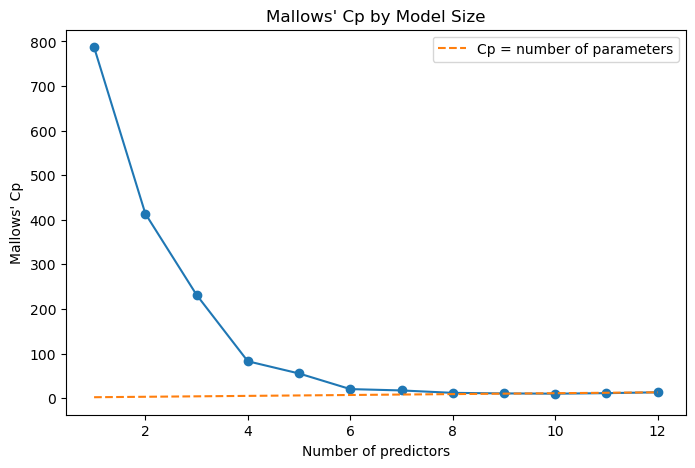

Best 8-variable model:
price_midpoint
population_density
nearby_restaurant_retail_count
housing_density
transit_share
walk_share
nearby_business_count
RateType_TOD

Mallows' Cp: 11.789
Adjusted R2: 0.294


Best 8-variable model:
price_midpoint
population_density
nearby_restaurant_retail_count
housing_density
transit_share
walk_share
nearby_business_count
RateType_TOD

Mallows' Cp: 11.789
Adjusted R2: 0.294


,Variable,Boruta Selected,Mallows Cp (8),VIF
0,price_midpoint,True,True,1.71
1,time_limit_hours,True,False,1.16
2,population_density,True,True,11.98
3,median_income,False,False,2.08
4,nearby_restaurant_retail_count,True,True,5.91
5,drive_alone_share,True,False,2.96
6,housing_density,True,True,12.69
7,transit_share,True,True,2.32
8,walk_share,True,True,3.03
9,nearby_business_count,True,True,6.68


,Variable,VIF
0,const,36.83
1,price_midpoint,1.62
2,time_limit_hours,1.11
3,population_density,1.09
4,nearby_restaurant_retail_count,1.67
5,drive_alone_share,1.67
6,transit_share,1.25
7,RateType_TOD,1.18


### Variable Selection Summary

I compared 12 candidate explanatory variables using VIF, Boruta, and Mallows' Cp.

Boruta confirmed 10 variables and rejected median income and meter type. Mallows' Cp showed that models with approximately 8–10 predictors provided similar adjusted R² values.

The initial VIF results showed substantial multicollinearity between population and housing density, as well as overlap between the two business-count variables. I retained population density and restaurant/retail count because they are directly relevant to parking demand.

My preferred specification contains seven explanatory variables: price, time limit, population density, restaurant/retail count, drive-alone commuting share, transit commuting share, and the TOD pricing indicator.

All seven predictors have VIF values below 2. I will use this specification as the main model and compare it with simpler OLS models in Notebook 06. These variables are associated with occupancy, but the analysis does not establish causal effects.

In [36]:
from IPython.display import display, Markdown
display(Markdown('### Historical source: 05_variable_selection.ipynb'))
_historical_bundles = [{'text/markdown': '# 05 — Variable Selection\n\nEvaluate candidate predictors for the cross-sectional analysis using economic reasoning and the assignment requirements. Document the rationale for the variables and specifications you choose.'}, {'text/plain': 'Original observations: 4139\nObservations after excluding JUMP: 4060\n'}, {'text/plain': "Explanatory variables: ['price_midpoint', 'time_limit_hours', 'population_density', 'median_income', 'nearby_restaurant_retail_count', 'drive_alone_share', 'housing_density', 'transit_share', 'walk_share', 'nearby_business_count', 'RateType_TOD', 'MeterType_Single-Space']\nNumber of explanatory variables: 12\n"}, {'text/plain': 'Missing values:\noccupancy_rate                     0\nprice_midpoint                     0\ntime_limit_hours                   0\npopulation_density                 0\nmedian_income                     44\nnearby_restaurant_retail_count     0\ndrive_alone_share                  0\nhousing_density                    0\ntransit_share                      0\nwalk_share                         0\nnearby_business_count              0\nRateType_TOD                       0\nMeterType_Single-Space             0\ndtype: int64\nFinal observations: 4016\nNumber of predictors: 12\n'}, {'text/html': ['<div>\n', '<style scoped>\n', '    .dataframe tbody tr th:only-of-type {\n', '        vertical-align: middle;\n', '    }\n', '\n', '    .dataframe tbody tr th {\n', '        vertical-align: top;\n', '    }\n', '\n', '    .dataframe thead th {\n', '        text-align: right;\n', '    }\n', '</style>\n', '<table border="1" class="dataframe">\n', '  <thead>\n', '    <tr style="text-align: right;">\n', '      <th></th>\n', '      <th>Variable</th>\n', '      <th>VIF</th>\n', '    </tr>\n', '  </thead>\n', '  <tbody>\n', '    <tr>\n', '      <th>0</th>\n', '      <td>const</td>\n', '      <td>110.00</td>\n', '    </tr>\n', '    <tr>\n', '      <th>1</th>\n', '      <td>price_midpoint</td>\n', '      <td>1.71</td>\n', '    </tr>\n', '    <tr>\n', '      <th>2</th>\n', '      <td>time_limit_hours</td>\n', '      <td>1.16</td>\n', '    </tr>\n', '    <tr>\n', '      <th>3</th>\n', '      <td>population_density</td>\n', '      <td>11.98</td>\n', '    </tr>\n', '    <tr>\n', '      <th>4</th>\n', '      <td>median_income</td>\n', '      <td>2.08</td>\n', '    </tr>\n', '    <tr>\n', '      <th>5</th>\n', '      <td>nearby_restaurant_retail_count</td>\n', '      <td>5.91</td>\n', '    </tr>\n', '    <tr>\n', '      <th>6</th>\n', '      <td>drive_alone_share</td>\n', '      <td>2.96</td>\n', '    </tr>\n', '    <tr>\n', '      <th>7</th>\n', '      <td>housing_density</td>\n', '      <td>12.69</td>\n', '    </tr>\n', '    <tr>\n', '      <th>8</th>\n', '      <td>transit_share</td>\n', '      <td>2.32</td>\n', '    </tr>\n', '    <tr>\n', '      <th>9</th>\n', '      <td>walk_share</td>\n', '      <td>3.03</td>\n', '    </tr>\n', '    <tr>\n', '      <th>10</th>\n', '      <td>nearby_business_count</td>\n', '      <td>6.68</td>\n', '    </tr>\n', '    <tr>\n', '      <th>11</th>\n', '      <td>RateType_TOD</td>\n', '      <td>1.25</td>\n', '    </tr>\n', '    <tr>\n', '      <th>12</th>\n', '      <td>MeterType_Single-Space</td>\n', '      <td>1.09</td>\n', '    </tr>\n', '  </tbody>\n', '</table>\n', '</div>'], 'text/plain': ['                          Variable     VIF\n', '0                            const  110.00\n', '1                   price_midpoint    1.71\n', '2                 time_limit_hours    1.16\n', '3               population_density   11.98\n', '4                    median_income    2.08\n', '5   nearby_restaurant_retail_count    5.91\n', '6                drive_alone_share    2.96\n', '7                  housing_density   12.69\n', '8                    transit_share    2.32\n', '9                       walk_share    3.03\n', '10           nearby_business_count    6.68\n', '11                    RateType_TOD    1.25\n', '12          MeterType_Single-Space    1.09']}, {'text/html': ['<div>\n', '<style scoped>\n', '    .dataframe tbody tr th:only-of-type {\n', '        vertical-align: middle;\n', '    }\n', '\n', '    .dataframe tbody tr th {\n', '        vertical-align: top;\n', '    }\n', '\n', '    .dataframe thead th {\n', '        text-align: right;\n', '    }\n', '</style>\n', '<table border="1" class="dataframe">\n', '  <thead>\n', '    <tr style="text-align: right;">\n', '      <th></th>\n', '      <th>Variable</th>\n', '      <th>VIF</th>\n', '    </tr>\n', '  </thead>\n', '  <tbody>\n', '    <tr>\n', '      <th>0</th>\n', '      <td>const</td>\n', '      <td>109.12</td>\n', '    </tr>\n', '    <tr>\n', '      <th>1</th>\n', '      <td>price_midpoint</td>\n', '      <td>1.64</td>\n', '    </tr>\n', '    <tr>\n', '      <th>2</th>\n', '      <td>time_limit_hours</td>\n', '      <td>1.13</td>\n', '    </tr>\n', '    <tr>\n', '      <th>3</th>\n', '      <td>population_density</td>\n', '      <td>1.18</td>\n', '    </tr>\n', '    <tr>\n', '      <th>4</th>\n', '      <td>median_income</td>\n', '      <td>2.03</td>\n', '    </tr>\n', '    <tr>\n', '      <th>5</th>\n', '      <td>nearby_restaurant_retail_count</td>\n', '      <td>1.75</td>\n', '    </tr>\n', '    <tr>\n', '      <th>6</th>\n', '      <td>drive_alone_share</td>\n', '      <td>2.79</td>\n', '    </tr>\n', '    <tr>\n', '      <th>7</th>\n', '      <td>transit_share</td>\n', '      <td>2.27</td>\n', '    </tr>\n', '    <tr>\n', '      <th>8</th>\n', '      <td>walk_share</td>\n', '      <td>2.49</td>\n', '    </tr>\n', '    <tr>\n', '      <th>9</th>\n', '      <td>RateType_TOD</td>\n', '      <td>1.23</td>\n', '    </tr>\n', '    <tr>\n', '      <th>10</th>\n', '      <td>MeterType_Single-Space</td>\n', '      <td>1.08</td>\n', '    </tr>\n', '  </tbody>\n', '</table>\n', '</div>'], 'text/plain': ['                          Variable     VIF\n', '0                            const  109.12\n', '1                   price_midpoint    1.64\n', '2                 time_limit_hours    1.13\n', '3               population_density    1.18\n', '4                    median_income    2.03\n', '5   nearby_restaurant_retail_count    1.75\n', '6                drive_alone_share    2.79\n', '7                    transit_share    2.27\n', '8                       walk_share    2.49\n', '9                     RateType_TOD    1.23\n', '10          MeterType_Single-Space    1.08']}, {'text/plain': 'Collecting boruta\n  Downloading Boruta-0.4.3-py3-none-any.whl.metadata (8.8 kB)\nRequirement already satisfied: numpy>=1.10.4 in /opt/anaconda3/lib/python3.13/site-packages (from boruta) (2.3.5)\nRequirement already satisfied: scikit-learn>=0.17.1 in /opt/anaconda3/lib/python3.13/site-packages (from boruta) (1.7.2)\nRequirement already satisfied: scipy>=0.17.0 in /opt/anaconda3/lib/python3.13/site-packages (from boruta) (1.16.3)\nRequirement already satisfied: joblib>=1.2.0 in /opt/anaconda3/lib/python3.13/site-packages (from scikit-learn>=0.17.1->boruta) (1.5.2)\nRequirement already satisfied: threadpoolctl>=3.1.0 in /opt/anaconda3/lib/python3.13/site-packages (from scikit-learn>=0.17.1->boruta) (3.5.0)\nDownloading Boruta-0.4.3-py3-none-any.whl (57 kB)\nInstalling collected packages: boruta\nSuccessfully installed boruta-0.4.3\nNote: you may need to restart the kernel to use updated packages.\n'}, {'text/plain': "Iteration: \t1 / 100\nConfirmed: \t0\nTentative: \t12\nRejected: \t0\nIteration: \t2 / 100\nConfirmed: \t0\nTentative: \t12\nRejected: \t0\nIteration: \t3 / 100\nConfirmed: \t0\nTentative: \t12\nRejected: \t0\nIteration: \t4 / 100\nConfirmed: \t0\nTentative: \t12\nRejected: \t0\nIteration: \t5 / 100\nConfirmed: \t0\nTentative: \t12\nRejected: \t0\nIteration: \t6 / 100\nConfirmed: \t0\nTentative: \t12\nRejected: \t0\nIteration: \t7 / 100\nConfirmed: \t0\nTentative: \t12\nRejected: \t0\nIteration: \t8 / 100\nConfirmed: \t7\nTentative: \t4\nRejected: \t1\nIteration: \t9 / 100\nConfirmed: \t7\nTentative: \t4\nRejected: \t1\nIteration: \t10 / 100\nConfirmed: \t7\nTentative: \t4\nRejected: \t1\nIteration: \t11 / 100\nConfirmed: \t7\nTentative: \t4\nRejected: \t1\nIteration: \t12 / 100\nConfirmed: \t8\nTentative: \t3\nRejected: \t1\nIteration: \t13 / 100\nConfirmed: \t8\nTentative: \t3\nRejected: \t1\nIteration: \t14 / 100\nConfirmed: \t8\nTentative: \t3\nRejected: \t1\nIteration: \t15 / 100\nConfirmed: \t8\nTentative: \t3\nRejected: \t1\nIteration: \t16 / 100\nConfirmed: \t9\nTentative: \t2\nRejected: \t1\nIteration: \t17 / 100\nConfirmed: \t9\nTentative: \t2\nRejected: \t1\nIteration: \t18 / 100\nConfirmed: \t9\nTentative: \t2\nRejected: \t1\nIteration: \t19 / 100\nConfirmed: \t10\nTentative: \t1\nRejected: \t1\nIteration: \t20 / 100\nConfirmed: \t10\nTentative: \t1\nRejected: \t1\nIteration: \t21 / 100\nConfirmed: \t10\nTentative: \t1\nRejected: \t1\nIteration: \t22 / 100\nConfirmed: \t10\nTentative: \t1\nRejected: \t1\nIteration: \t23 / 100\nConfirmed: \t10\nTentative: \t1\nRejected: \t1\nIteration: \t24 / 100\nConfirmed: \t10\nTentative: \t1\nRejected: \t1\nIteration: \t25 / 100\nConfirmed: \t10\nTentative: \t1\nRejected: \t1\nIteration: \t26 / 100\nConfirmed: \t10\nTentative: \t1\nRejected: \t1\nIteration: \t27 / 100\nConfirmed: \t10\nTentative: \t1\nRejected: \t1\nIteration: \t28 / 100\nConfirmed: \t10\nTentative: \t1\nRejected: \t1\nIteration: \t29 / 100\nConfirmed: \t10\nTentative: \t0\nRejected: \t2\n\n\nBorutaPy finished running.\n\nIteration: \t30 / 100\nConfirmed: \t10\nTentative: \t0\nRejected: \t2\n\nConfirmed: ['price_midpoint', 'time_limit_hours', 'population_density', 'nearby_restaurant_retail_count', 'drive_alone_share', 'housing_density', 'transit_share', 'walk_share', 'nearby_business_count', 'RateType_TOD']\n"}, {'text/plain': 'Feature: price_midpoint                      Rank: 1, Keep: Confirmed\nFeature: time_limit_hours                    Rank: 1, Keep: Confirmed\nFeature: population_density                  Rank: 1, Keep: Confirmed\nFeature: median_income                       Rank: 2, Keep: Reject\nFeature: nearby_restaurant_retail_count      Rank: 1, Keep: Confirmed\nFeature: drive_alone_share                   Rank: 1, Keep: Confirmed\nFeature: housing_density                     Rank: 1, Keep: Confirmed\nFeature: transit_share                       Rank: 1, Keep: Confirmed\nFeature: walk_share                          Rank: 1, Keep: Confirmed\nFeature: nearby_business_count               Rank: 1, Keep: Confirmed\nFeature: RateType_TOD                        Rank: 1, Keep: Confirmed\nFeature: MeterType_Single-Space              Rank: 3, Keep: Reject\n'}, {'text/plain': '                            OLS Regression Results                            \n==============================================================================\nDep. Variable:         occupancy_rate   R-squared:                       0.297\nModel:                            OLS   Adj. R-squared:                  0.295\nMethod:                 Least Squares   F-statistic:                     140.7\nDate:                Thu, 22 Oct 2026   Prob (F-statistic):          8.50e-295\nTime:                        20:24:24   Log-Likelihood:                 1608.0\nNo. Observations:                4016   AIC:                            -3190.\nDf Residuals:                    4003   BIC:                            -3108.\nDf Model:                          12                                         \nCovariance Type:            nonrobust                                         \n==================================================================================================\n                                     coef    std err          t      P>|t|      [0.025      0.975]\n--------------------------------------------------------------------------------------------------\nconst                              0.3454      0.027     12.851      0.000       0.293       0.398\nprice_midpoint                     0.0520      0.002     21.784      0.000       0.047       0.057\ntime_limit_hours                   0.0046      0.003      1.542      0.123      -0.001       0.010\npopulation_density              2.679e-06   7.22e-07      3.710      0.000    1.26e-06     4.1e-06\nmedian_income                   4.369e-08   1.25e-07      0.351      0.726   -2.01e-07    2.88e-07\nnearby_restaurant_retail_count    -0.0005   4.25e-05    -12.527      0.000      -0.001      -0.000\ndrive_alone_share                 -0.0240      0.027     -0.879      0.379      -0.078       0.030\nhousing_density                 1.932e-06   9.96e-07      1.940      0.052   -2.02e-08    3.88e-06\ntransit_share                      0.1507      0.063      2.401      0.016       0.028       0.274\nwalk_share                         0.3014      0.042      7.122      0.000       0.218       0.384\nnearby_business_count           6.083e-05   9.51e-06      6.397      0.000    4.22e-05    7.95e-05\nRateType_TOD                       0.0376      0.007      5.087      0.000       0.023       0.052\nMeterType_Single-Space            -0.0285      0.015     -1.912      0.056      -0.058       0.001\n==============================================================================\nOmnibus:                        6.384   Durbin-Watson:                   0.907\nProb(Omnibus):                  0.041   Jarque-Bera (JB):                7.094\nSkew:                           0.038   Prob(JB):                       0.0288\nKurtosis:                       3.191   Cond. No.                     1.89e+06\n==============================================================================\n\nNotes:\n[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.\n[2] The condition number is large, 1.89e+06. This might indicate that there are\nstrong multicollinearity or other numerical problems.\n'}, {'text/html': ['<div>\n', '<style scoped>\n', '    .dataframe tbody tr th:only-of-type {\n', '        vertical-align: middle;\n', '    }\n', '\n', '    .dataframe tbody tr th {\n', '        vertical-align: top;\n', '    }\n', '\n', '    .dataframe thead th {\n', '        text-align: right;\n', '    }\n', '</style>\n', '<table border="1" class="dataframe">\n', '  <thead>\n', '    <tr style="text-align: right;">\n', '      <th></th>\n', '      <th>Variables</th>\n', '      <th>Number of predictors</th>\n', '      <th>Cp</th>\n', '      <th>Adjusted R2</th>\n', '    </tr>\n', '  </thead>\n', '  <tbody>\n', '    <tr>\n', '      <th>4050</th>\n', '      <td>(price_midpoint, time_limit_hours, population_...</td>\n', '      <td>10</td>\n', '      <td>9.949599</td>\n', '      <td>0.294709</td>\n', '    </tr>\n', '    <tr>\n', '      <th>3950</th>\n', '      <td>(price_midpoint, population_density, nearby_re...</td>\n', '      <td>9</td>\n', '      <td>10.531400</td>\n', '      <td>0.294431</td>\n', '    </tr>\n', '    <tr>\n', '      <th>4090</th>\n', '      <td>(price_midpoint, time_limit_hours, population_...</td>\n', '      <td>11</td>\n', '      <td>11.122981</td>\n', '      <td>0.294679</td>\n', '    </tr>\n', '    <tr>\n', '      <th>4069</th>\n', '      <td>(price_midpoint, population_density, nearby_re...</td>\n', '      <td>10</td>\n', '      <td>11.578361</td>\n', '      <td>0.294423</td>\n', '    </tr>\n', '    <tr>\n', '      <th>4088</th>\n', '      <td>(price_midpoint, time_limit_hours, population_...</td>\n', '      <td>11</td>\n', '      <td>11.773507</td>\n', '      <td>0.294564</td>\n', '    </tr>\n', '    <tr>\n', '      <th>3582</th>\n', '      <td>(price_midpoint, population_density, nearby_re...</td>\n', '      <td>8</td>\n', '      <td>11.788981</td>\n', '      <td>0.294033</td>\n', '    </tr>\n', '    <tr>\n', '      <th>3867</th>\n', '      <td>(price_midpoint, time_limit_hours, population_...</td>\n', '      <td>9</td>\n', '      <td>11.923251</td>\n', '      <td>0.294186</td>\n', '    </tr>\n', '    <tr>\n', '      <th>4067</th>\n', '      <td>(price_midpoint, population_density, median_in...</td>\n', '      <td>10</td>\n', '      <td>12.257728</td>\n', '      <td>0.294303</td>\n', '    </tr>\n', '    <tr>\n', '      <th>3944</th>\n', '      <td>(price_midpoint, population_density, nearby_re...</td>\n', '      <td>9</td>\n', '      <td>12.613759</td>\n', '      <td>0.294064</td>\n', '    </tr>\n', '    <tr>\n', '      <th>4044</th>\n', '      <td>(price_midpoint, time_limit_hours, population_...</td>\n', '      <td>10</td>\n', '      <td>12.845720</td>\n', '      <td>0.294199</td>\n', '    </tr>\n', '  </tbody>\n', '</table>\n', '</div>'], 'text/plain': ['                                              Variables  Number of predictors  \\\n', '4050  (price_midpoint, time_limit_hours, population_...                    10   \n', '3950  (price_midpoint, population_density, nearby_re...                     9   \n', '4090  (price_midpoint, time_limit_hours, population_...                    11   \n', '4069  (price_midpoint, population_density, nearby_re...                    10   \n', '4088  (price_midpoint, time_limit_hours, population_...                    11   \n', '3582  (price_midpoint, population_density, nearby_re...                     8   \n', '3867  (price_midpoint, time_limit_hours, population_...                     9   \n', '4067  (price_midpoint, population_density, median_in...                    10   \n', '3944  (price_midpoint, population_density, nearby_re...                     9   \n', '4044  (price_midpoint, time_limit_hours, population_...                    10   \n', '\n', '             Cp  Adjusted R2  \n', '4050   9.949599     0.294709  \n', '3950  10.531400     0.294431  \n', '4090  11.122981     0.294679  \n', '4069  11.578361     0.294423  \n', '4088  11.773507     0.294564  \n', '3582  11.788981     0.294033  \n', '3867  11.923251     0.294186  \n', '4067  12.257728     0.294303  \n', '3944  12.613759     0.294064  \n', '4044  12.845720     0.294199  ']}, {'text/html': ['<div>\n', '<style scoped>\n', '    .dataframe tbody tr th:only-of-type {\n', '        vertical-align: middle;\n', '    }\n', '\n', '    .dataframe tbody tr th {\n', '        vertical-align: top;\n', '    }\n', '\n', '    .dataframe thead th {\n', '        text-align: right;\n', '    }\n', '</style>\n', '<table border="1" class="dataframe">\n', '  <thead>\n', '    <tr style="text-align: right;">\n', '      <th></th>\n', '      <th>Number of predictors</th>\n', '      <th>Cp</th>\n', '      <th>Adjusted R2</th>\n', '    </tr>\n', '  </thead>\n', '  <tbody>\n', '    <tr>\n', '      <th>0</th>\n', '      <td>1</td>\n', '      <td>786.957</td>\n', '      <td>0.157</td>\n', '    </tr>\n', '    <tr>\n', '      <th>13</th>\n', '      <td>2</td>\n', '      <td>413.784</td>\n', '      <td>0.222</td>\n', '    </tr>\n', '    <tr>\n', '      <th>93</th>\n', '      <td>3</td>\n', '      <td>231.578</td>\n', '      <td>0.255</td>\n', '    </tr>\n', '    <tr>\n', '      <th>414</th>\n', '      <td>4</td>\n', '      <td>82.641</td>\n', '      <td>0.281</td>\n', '    </tr>\n', '    <tr>\n', '      <th>956</th>\n', '      <td>5</td>\n', '      <td>55.239</td>\n', '      <td>0.286</td>\n', '    </tr>\n', '    <tr>\n', '      <th>1882</th>\n', '      <td>6</td>\n', '      <td>20.214</td>\n', '      <td>0.292</td>\n', '    </tr>\n', '    <tr>\n', '      <th>2861</th>\n', '      <td>7</td>\n', '      <td>17.199</td>\n', '      <td>0.293</td>\n', '    </tr>\n', '    <tr>\n', '      <th>3582</th>\n', '      <td>8</td>\n', '      <td>11.789</td>\n', '      <td>0.294</td>\n', '    </tr>\n', '    <tr>\n', '      <th>3950</th>\n', '      <td>9</td>\n', '      <td>10.531</td>\n', '      <td>0.294</td>\n', '    </tr>\n', '    <tr>\n', '      <th>4050</th>\n', '      <td>10</td>\n', '      <td>9.950</td>\n', '      <td>0.295</td>\n', '    </tr>\n', '    <tr>\n', '      <th>4090</th>\n', '      <td>11</td>\n', '      <td>11.123</td>\n', '      <td>0.295</td>\n', '    </tr>\n', '    <tr>\n', '      <th>4094</th>\n', '      <td>12</td>\n', '      <td>13.000</td>\n', '      <td>0.295</td>\n', '    </tr>\n', '  </tbody>\n', '</table>\n', '</div>'], 'text/plain': ['      Number of predictors       Cp  Adjusted R2\n', '0                        1  786.957        0.157\n', '13                       2  413.784        0.222\n', '93                       3  231.578        0.255\n', '414                      4   82.641        0.281\n', '956                      5   55.239        0.286\n', '1882                     6   20.214        0.292\n', '2861                     7   17.199        0.293\n', '3582                     8   11.789        0.294\n', '3950                     9   10.531        0.294\n', '4050                    10    9.950        0.295\n', '4090                    11   11.123        0.295\n', '4094                    12   13.000        0.295']}, {'image/png': '...', 'text/plain': ['<Figure size 800x500 with 1 Axes>']}, {'text/plain': "Best 8-variable model:\nprice_midpoint\npopulation_density\nnearby_restaurant_retail_count\nhousing_density\ntransit_share\nwalk_share\nnearby_business_count\nRateType_TOD\n\nMallows' Cp: 11.789\nAdjusted R2: 0.294\n"}, {'text/plain': "Best 8-variable model:\nprice_midpoint\npopulation_density\nnearby_restaurant_retail_count\nhousing_density\ntransit_share\nwalk_share\nnearby_business_count\nRateType_TOD\n\nMallows' Cp: 11.789\nAdjusted R2: 0.294\n"}, {'text/html': ['<div>\n', '<style scoped>\n', '    .dataframe tbody tr th:only-of-type {\n', '        vertical-align: middle;\n', '    }\n', '\n', '    .dataframe tbody tr th {\n', '        vertical-align: top;\n', '    }\n', '\n', '    .dataframe thead th {\n', '        text-align: right;\n', '    }\n', '</style>\n', '<table border="1" class="dataframe">\n', '  <thead>\n', '    <tr style="text-align: right;">\n', '      <th></th>\n', '      <th>Variable</th>\n', '      <th>Boruta Selected</th>\n', '      <th>Mallows Cp (8)</th>\n', '      <th>VIF</th>\n', '    </tr>\n', '  </thead>\n', '  <tbody>\n', '    <tr>\n', '      <th>0</th>\n', '      <td>price_midpoint</td>\n', '      <td>True</td>\n', '      <td>True</td>\n', '      <td>1.71</td>\n', '    </tr>\n', '    <tr>\n', '      <th>1</th>\n', '      <td>time_limit_hours</td>\n', '      <td>True</td>\n', '      <td>False</td>\n', '      <td>1.16</td>\n', '    </tr>\n', '    <tr>\n', '      <th>2</th>\n', '      <td>population_density</td>\n', '      <td>True</td>\n', '      <td>True</td>\n', '      <td>11.98</td>\n', '    </tr>\n', '    <tr>\n', '      <th>3</th>\n', '      <td>median_income</td>\n', '      <td>False</td>\n', '      <td>False</td>\n', '      <td>2.08</td>\n', '    </tr>\n', '    <tr>\n', '      <th>4</th>\n', '      <td>nearby_restaurant_retail_count</td>\n', '      <td>True</td>\n', '      <td>True</td>\n', '      <td>5.91</td>\n', '    </tr>\n', '    <tr>\n', '      <th>5</th>\n', '      <td>drive_alone_share</td>\n', '      <td>True</td>\n', '      <td>False</td>\n', '      <td>2.96</td>\n', '    </tr>\n', '    <tr>\n', '      <th>6</th>\n', '      <td>housing_density</td>\n', '      <td>True</td>\n', '      <td>True</td>\n', '      <td>12.69</td>\n', '    </tr>\n', '    <tr>\n', '      <th>7</th>\n', '      <td>transit_share</td>\n', '      <td>True</td>\n', '      <td>True</td>\n', '      <td>2.32</td>\n', '    </tr>\n', '    <tr>\n', '      <th>8</th>\n', '      <td>walk_share</td>\n', '      <td>True</td>\n', '      <td>True</td>\n', '      <td>3.03</td>\n', '    </tr>\n', '    <tr>\n', '      <th>9</th>\n', '      <td>nearby_business_count</td>\n', '      <td>True</td>\n', '      <td>True</td>\n', '      <td>6.68</td>\n', '    </tr>\n', '    <tr>\n', '      <th>10</th>\n', '      <td>RateType_TOD</td>\n', '      <td>True</td>\n', '      <td>True</td>\n', '      <td>1.25</td>\n', '    </tr>\n', '    <tr>\n', '      <th>11</th>\n', '      <td>MeterType_Single-Space</td>\n', '      <td>False</td>\n', '      <td>False</td>\n', '      <td>1.09</td>\n', '    </tr>\n', '  </tbody>\n', '</table>\n', '</div>'], 'text/plain': ['                          Variable  Boruta Selected  Mallows Cp (8)    VIF\n', '0                   price_midpoint             True            True   1.71\n', '1                 time_limit_hours             True           False   1.16\n', '2               population_density             True            True  11.98\n', '3                    median_income            False           False   2.08\n', '4   nearby_restaurant_retail_count             True            True   5.91\n', '5                drive_alone_share             True           False   2.96\n', '6                  housing_density             True            True  12.69\n', '7                    transit_share             True            True   2.32\n', '8                       walk_share             True            True   3.03\n', '9            nearby_business_count             True            True   6.68\n', '10                    RateType_TOD             True            True   1.25\n', '11          MeterType_Single-Space            False           False   1.09']}, {'text/html': ['<div>\n', '<style scoped>\n', '    .dataframe tbody tr th:only-of-type {\n', '        vertical-align: middle;\n', '    }\n', '\n', '    .dataframe tbody tr th {\n', '        vertical-align: top;\n', '    }\n', '\n', '    .dataframe thead th {\n', '        text-align: right;\n', '    }\n', '</style>\n', '<table border="1" class="dataframe">\n', '  <thead>\n', '    <tr style="text-align: right;">\n', '      <th></th>\n', '      <th>Variable</th>\n', '      <th>VIF</th>\n', '    </tr>\n', '  </thead>\n', '  <tbody>\n', '    <tr>\n', '      <th>0</th>\n', '      <td>const</td>\n', '      <td>36.83</td>\n', '    </tr>\n', '    <tr>\n', '      <th>1</th>\n', '      <td>price_midpoint</td>\n', '      <td>1.62</td>\n', '    </tr>\n', '    <tr>\n', '      <th>2</th>\n', '      <td>time_limit_hours</td>\n', '      <td>1.11</td>\n', '    </tr>\n', '    <tr>\n', '      <th>3</th>\n', '      <td>population_density</td>\n', '      <td>1.09</td>\n', '    </tr>\n', '    <tr>\n', '      <th>4</th>\n', '      <td>nearby_restaurant_retail_count</td>\n', '      <td>1.67</td>\n', '    </tr>\n', '    <tr>\n', '      <th>5</th>\n', '      <td>drive_alone_share</td>\n', '      <td>1.67</td>\n', '    </tr>\n', '    <tr>\n', '      <th>6</th>\n', '      <td>transit_share</td>\n', '      <td>1.25</td>\n', '    </tr>\n', '    <tr>\n', '      <th>7</th>\n', '      <td>RateType_TOD</td>\n', '      <td>1.18</td>\n', '    </tr>\n', '  </tbody>\n', '</table>\n', '</div>'], 'text/plain': ['                         Variable    VIF\n', '0                           const  36.83\n', '1                  price_midpoint   1.62\n', '2                time_limit_hours   1.11\n', '3              population_density   1.09\n', '4  nearby_restaurant_retail_count   1.67\n', '5               drive_alone_share   1.67\n', '6                   transit_share   1.25\n', '7                    RateType_TOD   1.18']}, {'text/markdown': "### Variable Selection Summary\n\nI compared 12 candidate explanatory variables using VIF, Boruta, and Mallows' Cp.\n\nBoruta confirmed 10 variables and rejected median income and meter type. Mallows' Cp showed that models with approximately 8–10 predictors provided similar adjusted R² values.\n\nThe initial VIF results showed substantial multicollinearity between population and housing density, as well as overlap between the two business-count variables. I retained population density and restaurant/retail count because they are directly relevant to parking demand.\n\nMy preferred specification contains seven explanatory variables: price, time limit, population density, restaurant/retail count, drive-alone commuting share, transit commuting share, and the TOD pricing indicator.\n\nAll seven predictors have VIF values below 2. I will use this specification as the main model and compare it with simpler OLS models in Notebook 06. These variables are associated with occupancy, but the analysis does not establish causal effects."}]
for _bundle in _historical_bundles:
    display(_bundle, raw=True)


### Historical source: 06_regression_models.ipynb

# 06 — Regression Models

I compare the three OLS specifications developed from Notebook 05, using the same parking spaces in every model. I keep the existing model estimates and specifications, then compare fit, price coefficients, and out-of-sample prediction before choosing a model to carry into diagnostics.

I reviewed `project1-1.pdf` and `Regression_Lecture0.ipynb`, `Regression_Lecture1.ipynb`, and `Regression_Lecture2.ipynb` in the local Downloads folder. The OLS, coefficient, dummy-variable, RMSE, and five-fold validation methods follow Lecture 1 (Sections 3.2, 4.1, and 6); multiple regression and AIC/BIC follow Lecture 2 (Sections 1.1 and 3.6). No new modeling method is introduced here.

## 1. Load and prepare the common sample

I load the unchanged Notebook 03 cross-section and retain FLAT and TOD meters, excluding the 79 JUMP spaces with incomparable price midpoints. I use the same 4,016 income-complete observations as Notebook 05 so changes across models reflect the controls rather than a changing sample. The 44 missing-income spaces are excluded for consistency with variable selection, even though none of these three models includes income.

Original observations: 4139
JUMP observations excluded: 79
FLAT + TOD observations: 4060
Missing values before the common-sample restriction:
occupancy_rate                     0
price_midpoint                     0
time_limit_hours                   0
population_density                 0
nearby_restaurant_retail_count     0
drive_alone_share                  0
transit_share                      0
RateType_TOD                       0
median_income                     44
dtype: int64
Common comparison observations: 4016
Unique parking spaces: 4016
Duplicate parking spaces: 0
Census tracts: 45
Missing values in the comparison data: 0


## 2. Model 1: Price

I start with price alone to measure its unadjusted relationship with occupancy. `price_midpoint` is a stated hourly price for FLAT meters and a midpoint of hourly-rate endpoints for TOD meters, rather than the average payment made by drivers.

...

## 7. Interpret Model 3

I report each coefficient with its uncertainty, then use changes that are easier to interpret for density, registrations, and commuting shares. These comparisons hold the other included variables constant. Statistical significance does not establish causality or tell us whether a magnitude is economically large.

,Coefficient,Standard error,P-value,95% lower,95% upper
Variable,,,,,
const,0.456337,0.0157939,6.470e-167,0.425373,0.487302
price_midpoint,0.0556328,0.00236136,4.731e-115,0.0510033,0.0602624
time_limit_hours,0.00487929,0.00294796,9.797e-02,-0.000900361,0.0106589
population_density,4.57052e-06,2.21771e-07,8.803e-90,4.13573e-06,5.00531e-06
nearby_restaurant_retail_count,-0.000321282,2.29852e-05,2.189e-43,-0.000366346,-0.000276218
drive_alone_share,-0.198101,0.0208314,3.195e-21,-0.238942,-0.15726
transit_share,0.0196471,0.0468362,6.749e-01,-0.072178,0.111472
RateType_TOD,0.0330042,0.00731608,6.631e-06,0.0186606,0.0473478


## 8. Compare five-fold prediction performance

Following Lecture 1, I use shuffled five-fold validation with seed 10 and the same folds for each model. `cross_val_score` fits a fresh `LinearRegression` with an intercept on each training fold and predicts only its held-out fold; it does not use the full-sample `model1`, `model2`, or `model3` fits. No scaling, imputation, or new predictor selection is performed in this comparison.

,Fold,Model 1 RMSE,Model 2 RMSE,Model 3 RMSE
0,1,0.17539,0.16609,0.16293
1,2,0.17974,0.17098,0.16667
2,3,0.17911,0.17102,0.16712
3,4,0.17685,0.16534,0.16425
4,5,0.17673,0.16827,0.16561


,Model,Mean CV RMSE,SD across folds
0,Model 1,0.17756,0.00181
1,Model 2,0.16834,0.00266
2,Model 3,0.16532,0.00173


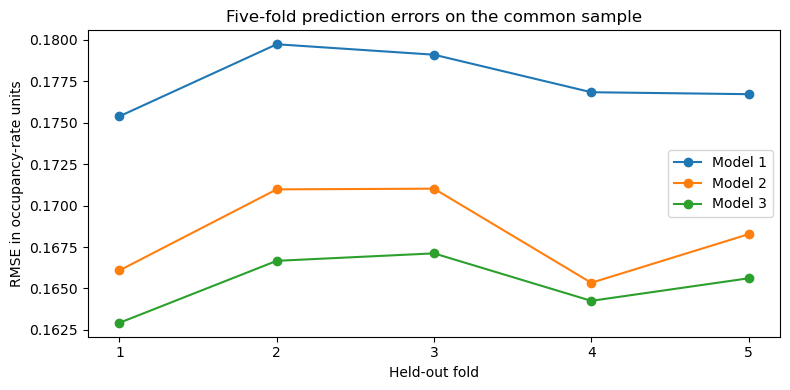

## 9. Choose a model to carry into diagnostics

I combine the fit and held-out error summaries before making a provisional choice. The criteria evaluate different tradeoffs, so I show their preferred models separately. The comparison is conditional on the same 4,016 observations and the three specified models.

,Model,Predictors,N,R2,Adjusted R2,AIC,BIC,In-sample RMSE,Mean CV RMSE,SD across folds
0,Model 1,1,4016,0.15678,0.15657,-2483.67051,-2471.07443,0.17752,0.17756,0.00181
1,Model 2,4,4016,0.24379,0.24303,-2915.05190,-2883.56169,0.16811,0.16834,0.00266
2,Model 3,7,4016,0.27362,0.27235,-3070.71241,-3020.32808,0.16476,0.16532,0.00173


Highest adjusted R2    Model 3
Lowest AIC             Model 3
Lowest BIC             Model 3
Lowest mean CV RMSE    Model 3
Name: Preferred model, dtype: object

## 10. Limitations, assignment check, and next steps

The outcome is August 2025 occupancy, while prices and business registrations come from October 2026. TOD midpoint summarizes hourly-rate endpoints rather than actual payments, and prices may respond to demand, creating endogeneity. Registration counts also need not represent unique storefronts or businesses active during the outcome month.

Several spaces share tracts and nearby demand conditions, so the conventional standard errors need further examination. Large condition numbers in the summaries can reflect differing variable units as well as collinearity; they are not a diagnosis by themselves, and Notebook 05's selected-model VIFs were below two. OLS predictions are not constrained to the occupancy interval of zero to one.

Notebook 07 will examine residuals, regression assumptions, influential observations, and robustness. Planned sensor comparisons cover 12/24/48-hour maximum intervals, 20/25/28 active days, and Sunday-reporting differences; none of those datasets or diagnostics is rebuilt here. The five-fold comparison above already supplies the requested initial held-out prediction check and need not be repeated without a reason.

### Assignment checklist

This checklist follows `project1-1.pdf` (130-point rubric). Completing Notebook 06 does not complete the assignment.

| Requirement | Status and location |
|---|---|
| At least 500 observations, five potential predictors, cross-sectional OLS setting | Completed in the constructed data and Notebooks 04–06; the common comparison has 4,016 spaces |
| Source, period, sample and variable definitions; descriptive statistics; histograms, boxplots, scatterplots and correlation heatmap | Completed in Notebooks 01–04, with the comparison-sample decision shown here |
| IQR outlier inspection and missingness patterns | Completed in Notebook 04; standardized-residual checks and missingness/sample sensitivity remain for later work |
| Q-Q plots, density plots and Pandas Profiling discussion for EDA | Not present in the saved Notebook 04; still outstanding, without modifying that notebook here |
| Boruta, Mallows' Cp and VIF | Completed in the saved Notebook 05; its selection results are preserved |
| Three competing models with explicit predictors and a common sample | Completed here for the requested specifications; the middle-model predictor-count mismatch is noted below |
| AIC, BIC, adjusted R² and five- or ten-fold validation | Completed here using common observations and five fixed, shuffled folds |
| Coefficients, standard errors, p-values, economic units and key 95% intervals | Completed here, including all Model 3 coefficients; final presentation remains for Notebook 08 |
| Economic/statistical justification of the model carried forward | Provisional comparison completed here; final choice remains subject to diagnostics and the specification issues below |
| Residual/fitted and scale-location plots; RESET; Breusch–Pagan/White; residual Q-Q, Jarque–Bera and histogram; Cook's distance, leverage and DFBETAS | Reserved for Notebook 07; summary-output statistics alone do not complete these diagnostics |
| Bootstrap coefficient estimates with 1,000 replications; comparison with OLS | Reserved for Notebook 07 |
| Economic motivation with at least two academic sources, expected signs/magnitudes, policy/external-validity discussion, final conclusions and references | Final report work for Notebook 08; complete submission content has not been verified here |
| Reproducible code and fixed seeds | Notebook 06 runs from the saved CSV; validation uses seed 10; no dataset is overwritten |
| One group report with names, Python source and all required sections, submitted as PDF or HTML | Final submission remains outstanding |

**Specification issues to resolve:** the assignment asks for 2–3 predictors in Model 2, while the approved model has four. It also describes Model 3 in terms of statistically significant predictors, while time limit and transit share are not significant at 5% here. I preserve the requested models and Notebook 05 selection results; any change or justification of these differences needs an explicit decision before final submission.

**Lecture alignment:** all statistical methods implemented here are demonstrated in Lectures 1–2. No advanced method was added to fill an assignment gap, and no source data, earlier notebook, or Notebook 07 analysis is changed.

In [37]:
from IPython.display import display, Markdown
display(Markdown('### Historical source: 06_regression_models.ipynb'))
_historical_bundles = [{'text/markdown': '# 06 — Regression Models\n\nI compare the three OLS specifications developed from Notebook 05, using the same parking spaces in every model. I keep the existing model estimates and specifications, then compare fit, price coefficients, and out-of-sample prediction before choosing a model to carry into diagnostics.\n\nI reviewed `project1-1.pdf` and `Regression_Lecture0.ipynb`, `Regression_Lecture1.ipynb`, and `Regression_Lecture2.ipynb` in the local Downloads folder. The OLS, coefficient, dummy-variable, RMSE, and five-fold validation methods follow Lecture 1 (Sections 3.2, 4.1, and 6); multiple regression and AIC/BIC follow Lecture 2 (Sections 1.1 and 3.6). No new modeling method is introduced here.'}, {'text/markdown': '## 1. Load and prepare the common sample\n\nI load the unchanged Notebook 03 cross-section and retain FLAT and TOD meters, excluding the 79 JUMP spaces with incomparable price midpoints. I use the same 4,016 income-complete observations as Notebook 05 so changes across models reflect the controls rather than a changing sample. The 44 missing-income spaces are excluded for consistency with variable selection, even though none of these three models includes income.'}, {'text/plain': 'Original observations: 4139\nJUMP observations excluded: 79\nFLAT + TOD observations: 4060\nMissing values before the common-sample restriction:\noccupancy_rate                     0\nprice_midpoint                     0\ntime_limit_hours                   0\npopulation_density                 0\nnearby_restaurant_retail_count     0\ndrive_alone_share                  0\ntransit_share                      0\nRateType_TOD                       0\nmedian_income                     44\ndtype: int64\nCommon comparison observations: 4016\nUnique parking spaces: 4016\nDuplicate parking spaces: 0\nCensus tracts: 45\nMissing values in the comparison data: 0\n'}, {'text/markdown': '## 2. Model 1: Price\n\nI start with price alone to measure its unadjusted relationship with occupancy. `price_midpoint` is a stated hourly price for FLAT meters and a midpoint of hourly-rate endpoints for TOD meters, rather than the average payment made by drivers.'}, {'text/plain': '                            OLS Regression Results                            \n==============================================================================\nDep. Variable:         occupancy_rate   R-squared:                       0.157\nModel:                            OLS   Adj. R-squared:                  0.157\nMethod:                 Least Squares   F-statistic:                     746.3\nDate:                Thu, 22 Oct 2026   Prob (F-statistic):          7.41e-151\nTime:                        20:44:53   Log-Likelihood:                 1243.8\nNo. Observations:                4016   AIC:                            -2484.\nDf Residuals:                    4014   BIC:                            -2471.\nDf Model:                           1                                         \nCovariance Type:            nonrobust                                         \n==================================================================================\n                     coef    std err          t      P>|t|      [0.025      0.975]\n----------------------------------------------------------------------------------\nconst              0.4237      0.005     84.361      0.000       0.414       0.434\nprice_midpoint     0.0545      0.002     27.318      0.000       0.051       0.058\n==============================================================================\nOmnibus:                       68.024   Durbin-Watson:                   0.773\nProb(Omnibus):                  0.000   Jarque-Bera (JB):               39.129\nSkew:                           0.038   Prob(JB):                     3.19e-09\nKurtosis:                       2.522   Cond. No.                         5.03\n==============================================================================\n\nNotes:\n[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.\n'}, {'text/markdown': "## 3. Model 2: Add parking rules and local activity\n\nI add time limits, population density, and nearby food-service/retail registrations to account for parking rules and local demand conditions. I retain the four-predictor specification already estimated here; the assignment's request for a 2–3-predictor middle model is flagged in the checklist below rather than silently changing this model."}, {'text/plain': '                            OLS Regression Results                            \n==============================================================================\nDep. Variable:         occupancy_rate   R-squared:                       0.244\nModel:                            OLS   Adj. R-squared:                  0.243\nMethod:                 Least Squares   F-statistic:                     323.3\nDate:                Thu, 22 Oct 2026   Prob (F-statistic):          2.05e-241\nTime:                        20:44:53   Log-Likelihood:                 1462.5\nNo. Observations:                4016   AIC:                            -2915.\nDf Residuals:                    4011   BIC:                            -2884.\nDf Model:                           4                                         \nCovariance Type:            nonrobust                                         \n==================================================================================================\n                                     coef    std err          t      P>|t|      [0.025      0.975]\n--------------------------------------------------------------------------------------------------\nconst                              0.3826      0.010     37.554      0.000       0.363       0.403\nprice_midpoint                     0.0606      0.002     25.605      0.000       0.056       0.065\ntime_limit_hours                   0.0036      0.003      1.238      0.216      -0.002       0.009\npopulation_density              4.058e-06   2.21e-07     18.326      0.000    3.62e-06    4.49e-06\nnearby_restaurant_retail_count    -0.0002   2.17e-05    -10.553      0.000      -0.000      -0.000\n==============================================================================\nOmnibus:                        0.964   Durbin-Watson:                   0.853\nProb(Omnibus):                  0.618   Jarque-Bera (JB):                1.005\nSkew:                          -0.034   Prob(JB):                        0.605\nKurtosis:                       2.962   Cond. No.                     8.53e+04\n==============================================================================\n\nNotes:\n[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.\n[2] The condition number is large, 8.53e+04. This might indicate that there are\nstrong multicollinearity or other numerical problems.\n'}, {'text/markdown': "## 4. Model 3: Preferred seven-variable specification\n\nI add drive-alone share, transit share, and the TOD indicator to Model 2. This is the seven-variable specification chosen in Notebook 05 after reviewing economic relevance, Boruta, Mallows' Cp, and VIF; all seven were Boruta-confirmed and their selected-model VIFs were below two. It was a parsimonious choice, not the global minimum-Cp subset, and its performance still needs comparison here."}, {'text/plain': '                            OLS Regression Results                            \n==============================================================================\nDep. Variable:         occupancy_rate   R-squared:                       0.274\nModel:                            OLS   Adj. R-squared:                  0.272\nMethod:                 Least Squares   F-statistic:                     215.7\nDate:                Thu, 22 Oct 2026   Prob (F-statistic):          1.25e-272\nTime:                        20:44:53   Log-Likelihood:                 1543.4\nNo. Observations:                4016   AIC:                            -3071.\nDf Residuals:                    4008   BIC:                            -3020.\nDf Model:                           7                                         \nCovariance Type:            nonrobust                                         \n==================================================================================================\n                                     coef    std err          t      P>|t|      [0.025      0.975]\n--------------------------------------------------------------------------------------------------\nconst                              0.4563      0.016     28.893      0.000       0.425       0.487\nprice_midpoint                     0.0556      0.002     23.560      0.000       0.051       0.060\ntime_limit_hours                   0.0049      0.003      1.655      0.098      -0.001       0.011\npopulation_density              4.571e-06   2.22e-07     20.609      0.000    4.14e-06    5.01e-06\nnearby_restaurant_retail_count    -0.0003    2.3e-05    -13.978      0.000      -0.000      -0.000\ndrive_alone_share                 -0.1981      0.021     -9.510      0.000      -0.239      -0.157\ntransit_share                      0.0196      0.047      0.419      0.675      -0.072       0.111\nRateType_TOD                       0.0330      0.007      4.511      0.000       0.019       0.047\n==============================================================================\nOmnibus:                        3.657   Durbin-Watson:                   0.896\nProb(Omnibus):                  0.161   Jarque-Bera (JB):                3.836\nSkew:                           0.031   Prob(JB):                        0.147\nKurtosis:                       3.138   Cond. No.                     3.96e+05\n==============================================================================\n\nNotes:\n[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.\n[2] The condition number is large, 3.96e+05. This might indicate that there are\nstrong multicollinearity or other numerical problems.\n'}, {'text/markdown': '## 5. Compare in-sample model performance\n\nI compare all three models on the same outcome and observations, counting predictors without the intercept. Higher adjusted R² and lower AIC/BIC generally favor a model, while RMSE summarizes fitted errors in occupancy-rate units. This RMSE is in-sample fit, not held-out prediction performance.'}, {'text/html': ['<div>\n', '<style scoped>\n', '    .dataframe tbody tr th:only-of-type {\n', '        vertical-align: middle;\n', '    }\n', '\n', '    .dataframe tbody tr th {\n', '        vertical-align: top;\n', '    }\n', '\n', '    .dataframe thead th {\n', '        text-align: right;\n', '    }\n', '</style>\n', '<table border="1" class="dataframe">\n', '  <thead>\n', '    <tr style="text-align: right;">\n', '      <th></th>\n', '      <th>Model</th>\n', '      <th>Predictors</th>\n', '      <th>N</th>\n', '      <th>R2</th>\n', '      <th>Adjusted R2</th>\n', '      <th>AIC</th>\n', '      <th>BIC</th>\n', '      <th>In-sample RMSE</th>\n', '    </tr>\n', '  </thead>\n', '  <tbody>\n', '    <tr>\n', '      <th>0</th>\n', '      <td>Model 1</td>\n', '      <td>1</td>\n', '      <td>4016</td>\n', '      <td>0.15678</td>\n', '      <td>0.15657</td>\n', '      <td>-2483.67051</td>\n', '      <td>-2471.07443</td>\n', '      <td>0.17752</td>\n', '    </tr>\n', '    <tr>\n', '      <th>1</th>\n', '      <td>Model 2</td>\n', '      <td>4</td>\n', '      <td>4016</td>\n', '      <td>0.24379</td>\n', '      <td>0.24303</td>\n', '      <td>-2915.05190</td>\n', '      <td>-2883.56169</td>\n', '      <td>0.16811</td>\n', '    </tr>\n', '    <tr>\n', '      <th>2</th>\n', '      <td>Model 3</td>\n', '      <td>7</td>\n', '      <td>4016</td>\n', '      <td>0.27362</td>\n', '      <td>0.27235</td>\n', '      <td>-3070.71241</td>\n', '      <td>-3020.32808</td>\n', '      <td>0.16476</td>\n', '    </tr>\n', '  </tbody>\n', '</table>\n', '</div>'], 'text/plain': ['     Model  Predictors     N       R2  Adjusted R2         AIC         BIC  \\\n', '0  Model 1           1  4016  0.15678      0.15657 -2483.67051 -2471.07443   \n', '1  Model 2           4  4016  0.24379      0.24303 -2915.05190 -2883.56169   \n', '2  Model 3           7  4016  0.27362      0.27235 -3070.71241 -3020.32808   \n', '\n', '   In-sample RMSE  \n', '0         0.17752  \n', '1         0.16811  \n', '2         0.16476  ']}, {'text/markdown': '## 6. Compare the price coefficients\n\nI place the price estimates, conventional standard errors, p-values, and 95% confidence intervals side by side. A coefficient is measured in occupancy-rate units per dollar, so multiplying it by 100 gives the associated percentage-point difference. Scientific notation keeps very small p-values visible instead of rounding them to zero.'}, {'text/html': ['<style type="text/css">\n', '</style>\n', '<table id="T_fd76f">\n', '  <thead>\n', '    <tr>\n', '      <th class="blank level0" >&nbsp;</th>\n', '      <th id="T_fd76f_level0_col0" class="col_heading level0 col0" >Model</th>\n', '      <th id="T_fd76f_level0_col1" class="col_heading level0 col1" >Price Coefficient</th>\n', '      <th id="T_fd76f_level0_col2" class="col_heading level0 col2" >Standard error</th>\n', '      <th id="T_fd76f_level0_col3" class="col_heading level0 col3" >P-value</th>\n', '      <th id="T_fd76f_level0_col4" class="col_heading level0 col4" >95% lower</th>\n', '      <th id="T_fd76f_level0_col5" class="col_heading level0 col5" >95% upper</th>\n', '    </tr>\n', '  </thead>\n', '  <tbody>\n', '    <tr>\n', '      <th id="T_fd76f_level0_row0" class="row_heading level0 row0" >0</th>\n', '      <td id="T_fd76f_row0_col0" class="data row0 col0" >Model 1</td>\n', '      <td id="T_fd76f_row0_col1" class="data row0 col1" >0.05451</td>\n', '      <td id="T_fd76f_row0_col2" class="data row0 col2" >0.00200</td>\n', '      <td id="T_fd76f_row0_col3" class="data row0 col3" >7.414e-151</td>\n', '      <td id="T_fd76f_row0_col4" class="data row0 col4" >0.05060</td>\n', '      <td id="T_fd76f_row0_col5" class="data row0 col5" >0.05843</td>\n', '    </tr>\n', '    <tr>\n', '      <th id="T_fd76f_level0_row1" class="row_heading level0 row1" >1</th>\n', '      <td id="T_fd76f_row1_col0" class="data row1 col0" >Model 2</td>\n', '      <td id="T_fd76f_row1_col1" class="data row1 col1" >0.06064</td>\n', '      <td id="T_fd76f_row1_col2" class="data row1 col2" >0.00237</td>\n', '      <td id="T_fd76f_row1_col3" class="data row1 col3" >4.664e-134</td>\n', '      <td id="T_fd76f_row1_col4" class="data row1 col4" >0.05600</td>\n', '      <td id="T_fd76f_row1_col5" class="data row1 col5" >0.06528</td>\n', '    </tr>\n', '    <tr>\n', '      <th id="T_fd76f_level0_row2" class="row_heading level0 row2" >2</th>\n', '      <td id="T_fd76f_row2_col0" class="data row2 col0" >Model 3</td>\n', '      <td id="T_fd76f_row2_col1" class="data row2 col1" >0.05563</td>\n', '      <td id="T_fd76f_row2_col2" class="data row2 col2" >0.00236</td>\n', '      <td id="T_fd76f_row2_col3" class="data row2 col3" >4.731e-115</td>\n', '      <td id="T_fd76f_row2_col4" class="data row2 col4" >0.05100</td>\n', '      <td id="T_fd76f_row2_col5" class="data row2 col5" >0.06026</td>\n', '    </tr>\n', '  </tbody>\n', '</table>\n'], 'text/plain': ['<pandas.io.formats.style.Styler at 0x15fbc27b0>']}, {'text/markdown': '## 7. Interpret Model 3\n\nI report each coefficient with its uncertainty, then use changes that are easier to interpret for density, registrations, and commuting shares. These comparisons hold the other included variables constant. Statistical significance does not establish causality or tell us whether a magnitude is economically large.'}, {'text/html': ['<style type="text/css">\n', '</style>\n', '<table id="T_3eb75">\n', '  <thead>\n', '    <tr>\n', '      <th class="blank level0" >&nbsp;</th>\n', '      <th id="T_3eb75_level0_col0" class="col_heading level0 col0" >Coefficient</th>\n', '      <th id="T_3eb75_level0_col1" class="col_heading level0 col1" >Standard error</th>\n', '      <th id="T_3eb75_level0_col2" class="col_heading level0 col2" >P-value</th>\n', '      <th id="T_3eb75_level0_col3" class="col_heading level0 col3" >95% lower</th>\n', '      <th id="T_3eb75_level0_col4" class="col_heading level0 col4" >95% upper</th>\n', '    </tr>\n', '    <tr>\n', '      <th class="index_name level0" >Variable</th>\n', '      <th class="blank col0" >&nbsp;</th>\n', '      <th class="blank col1" >&nbsp;</th>\n', '      <th class="blank col2" >&nbsp;</th>\n', '      <th class="blank col3" >&nbsp;</th>\n', '      <th class="blank col4" >&nbsp;</th>\n', '    </tr>\n', '  </thead>\n', '  <tbody>\n', '    <tr>\n', '      <th id="T_3eb75_level0_row0" class="row_heading level0 row0" >const</th>\n', '      <td id="T_3eb75_row0_col0" class="data row0 col0" >0.456337</td>\n', '      <td id="T_3eb75_row0_col1" class="data row0 col1" >0.0157939</td>\n', '      <td id="T_3eb75_row0_col2" class="data row0 col2" >6.470e-167</td>\n', '      <td id="T_3eb75_row0_col3" class="data row0 col3" >0.425373</td>\n', '      <td id="T_3eb75_row0_col4" class="data row0 col4" >0.487302</td>\n', '    </tr>\n', '    <tr>\n', '      <th id="T_3eb75_level0_row1" class="row_heading level0 row1" >price_midpoint</th>\n', '      <td id="T_3eb75_row1_col0" class="data row1 col0" >0.0556328</td>\n', '      <td id="T_3eb75_row1_col1" class="data row1 col1" >0.00236136</td>\n', '      <td id="T_3eb75_row1_col2" class="data row1 col2" >4.731e-115</td>\n', '      <td id="T_3eb75_row1_col3" class="data row1 col3" >0.0510033</td>\n', '      <td id="T_3eb75_row1_col4" class="data row1 col4" >0.0602624</td>\n', '    </tr>\n', '    <tr>\n', '      <th id="T_3eb75_level0_row2" class="row_heading level0 row2" >time_limit_hours</th>\n', '      <td id="T_3eb75_row2_col0" class="data row2 col0" >0.00487929</td>\n', '      <td id="T_3eb75_row2_col1" class="data row2 col1" >0.00294796</td>\n', '      <td id="T_3eb75_row2_col2" class="data row2 col2" >9.797e-02</td>\n', '      <td id="T_3eb75_row2_col3" class="data row2 col3" >-0.000900361</td>\n', '      <td id="T_3eb75_row2_col4" class="data row2 col4" >0.0106589</td>\n', '    </tr>\n', '    <tr>\n', '      <th id="T_3eb75_level0_row3" class="row_heading level0 row3" >population_density</th>\n', '      <td id="T_3eb75_row3_col0" class="data row3 col0" >4.57052e-06</td>\n', '      <td id="T_3eb75_row3_col1" class="data row3 col1" >2.21771e-07</td>\n', '      <td id="T_3eb75_row3_col2" class="data row3 col2" >8.803e-90</td>\n', '      <td id="T_3eb75_row3_col3" class="data row3 col3" >4.13573e-06</td>\n', '      <td id="T_3eb75_row3_col4" class="data row3 col4" >5.00531e-06</td>\n', '    </tr>\n', '    <tr>\n', '      <th id="T_3eb75_level0_row4" class="row_heading level0 row4" >nearby_restaurant_retail_count</th>\n', '      <td id="T_3eb75_row4_col0" class="data row4 col0" >-0.000321282</td>\n', '      <td id="T_3eb75_row4_col1" class="data row4 col1" >2.29852e-05</td>\n', '      <td id="T_3eb75_row4_col2" class="data row4 col2" >2.189e-43</td>\n', '      <td id="T_3eb75_row4_col3" class="data row4 col3" >-0.000366346</td>\n', '      <td id="T_3eb75_row4_col4" class="data row4 col4" >-0.000276218</td>\n', '    </tr>\n', '    <tr>\n', '      <th id="T_3eb75_level0_row5" class="row_heading level0 row5" >drive_alone_share</th>\n', '      <td id="T_3eb75_row5_col0" class="data row5 col0" >-0.198101</td>\n', '      <td id="T_3eb75_row5_col1" class="data row5 col1" >0.0208314</td>\n', '      <td id="T_3eb75_row5_col2" class="data row5 col2" >3.195e-21</td>\n', '      <td id="T_3eb75_row5_col3" class="data row5 col3" >-0.238942</td>\n', '      <td id="T_3eb75_row5_col4" class="data row5 col4" >-0.15726</td>\n', '    </tr>\n', '    <tr>\n', '      <th id="T_3eb75_level0_row6" class="row_heading level0 row6" >transit_share</th>\n', '      <td id="T_3eb75_row6_col0" class="data row6 col0" >0.0196471</td>\n', '      <td id="T_3eb75_row6_col1" class="data row6 col1" >0.0468362</td>\n', '      <td id="T_3eb75_row6_col2" class="data row6 col2" >6.749e-01</td>\n', '      <td id="T_3eb75_row6_col3" class="data row6 col3" >-0.072178</td>\n', '      <td id="T_3eb75_row6_col4" class="data row6 col4" >0.111472</td>\n', '    </tr>\n', '    <tr>\n', '      <th id="T_3eb75_level0_row7" class="row_heading level0 row7" >RateType_TOD</th>\n', '      <td id="T_3eb75_row7_col0" class="data row7 col0" >0.0330042</td>\n', '      <td id="T_3eb75_row7_col1" class="data row7 col1" >0.00731608</td>\n', '      <td id="T_3eb75_row7_col2" class="data row7 col2" >6.631e-06</td>\n', '      <td id="T_3eb75_row7_col3" class="data row7 col3" >0.0186606</td>\n', '      <td id="T_3eb75_row7_col4" class="data row7 col4" >0.0473478</td>\n', '    </tr>\n', '  </tbody>\n', '</table>\n'], 'text/plain': ['<pandas.io.formats.style.Styler at 0x15fbc9a90>']}, {'text/markdown': '## 8. Compare five-fold prediction performance\n\nFollowing Lecture 1, I use shuffled five-fold validation with seed 10 and the same folds for each model. `cross_val_score` fits a fresh `LinearRegression` with an intercept on each training fold and predicts only its held-out fold; it does not use the full-sample `model1`, `model2`, or `model3` fits. No scaling, imputation, or new predictor selection is performed in this comparison.'}, {'text/html': ['<div>\n', '<style scoped>\n', '    .dataframe tbody tr th:only-of-type {\n', '        vertical-align: middle;\n', '    }\n', '\n', '    .dataframe tbody tr th {\n', '        vertical-align: top;\n', '    }\n', '\n', '    .dataframe thead th {\n', '        text-align: right;\n', '    }\n', '</style>\n', '<table border="1" class="dataframe">\n', '  <thead>\n', '    <tr style="text-align: right;">\n', '      <th></th>\n', '      <th>Fold</th>\n', '      <th>Model 1 RMSE</th>\n', '      <th>Model 2 RMSE</th>\n', '      <th>Model 3 RMSE</th>\n', '    </tr>\n', '  </thead>\n', '  <tbody>\n', '    <tr>\n', '      <th>0</th>\n', '      <td>1</td>\n', '      <td>0.17539</td>\n', '      <td>0.16609</td>\n', '      <td>0.16293</td>\n', '    </tr>\n', '    <tr>\n', '      <th>1</th>\n', '      <td>2</td>\n', '      <td>0.17974</td>\n', '      <td>0.17098</td>\n', '      <td>0.16667</td>\n', '    </tr>\n', '    <tr>\n', '      <th>2</th>\n', '      <td>3</td>\n', '      <td>0.17911</td>\n', '      <td>0.17102</td>\n', '      <td>0.16712</td>\n', '    </tr>\n', '    <tr>\n', '      <th>3</th>\n', '      <td>4</td>\n', '      <td>0.17685</td>\n', '      <td>0.16534</td>\n', '      <td>0.16425</td>\n', '    </tr>\n', '    <tr>\n', '      <th>4</th>\n', '      <td>5</td>\n', '      <td>0.17673</td>\n', '      <td>0.16827</td>\n', '      <td>0.16561</td>\n', '    </tr>\n', '  </tbody>\n', '</table>\n', '</div>'], 'text/plain': ['   Fold  Model 1 RMSE  Model 2 RMSE  Model 3 RMSE\n', '0     1       0.17539       0.16609       0.16293\n', '1     2       0.17974       0.17098       0.16667\n', '2     3       0.17911       0.17102       0.16712\n', '3     4       0.17685       0.16534       0.16425\n', '4     5       0.17673       0.16827       0.16561']}, {'text/html': ['<div>\n', '<style scoped>\n', '    .dataframe tbody tr th:only-of-type {\n', '        vertical-align: middle;\n', '    }\n', '\n', '    .dataframe tbody tr th {\n', '        vertical-align: top;\n', '    }\n', '\n', '    .dataframe thead th {\n', '        text-align: right;\n', '    }\n', '</style>\n', '<table border="1" class="dataframe">\n', '  <thead>\n', '    <tr style="text-align: right;">\n', '      <th></th>\n', '      <th>Model</th>\n', '      <th>Mean CV RMSE</th>\n', '      <th>SD across folds</th>\n', '    </tr>\n', '  </thead>\n', '  <tbody>\n', '    <tr>\n', '      <th>0</th>\n', '      <td>Model 1</td>\n', '      <td>0.17756</td>\n', '      <td>0.00181</td>\n', '    </tr>\n', '    <tr>\n', '      <th>1</th>\n', '      <td>Model 2</td>\n', '      <td>0.16834</td>\n', '      <td>0.00266</td>\n', '    </tr>\n', '    <tr>\n', '      <th>2</th>\n', '      <td>Model 3</td>\n', '      <td>0.16532</td>\n', '      <td>0.00173</td>\n', '    </tr>\n', '  </tbody>\n', '</table>\n', '</div>'], 'text/plain': ['     Model  Mean CV RMSE  SD across folds\n', '0  Model 1       0.17756          0.00181\n', '1  Model 2       0.16834          0.00266\n', '2  Model 3       0.16532          0.00173']}, {'image/png': '...', 'text/plain': ['<Figure size 800x400 with 1 Axes>']}, {'text/markdown': '## 9. Choose a model to carry into diagnostics\n\nI combine the fit and held-out error summaries before making a provisional choice. The criteria evaluate different tradeoffs, so I show their preferred models separately. The comparison is conditional on the same 4,016 observations and the three specified models.'}, {'text/html': ['<div>\n', '<style scoped>\n', '    .dataframe tbody tr th:only-of-type {\n', '        vertical-align: middle;\n', '    }\n', '\n', '    .dataframe tbody tr th {\n', '        vertical-align: top;\n', '    }\n', '\n', '    .dataframe thead th {\n', '        text-align: right;\n', '    }\n', '</style>\n', '<table border="1" class="dataframe">\n', '  <thead>\n', '    <tr style="text-align: right;">\n', '      <th></th>\n', '      <th>Model</th>\n', '      <th>Predictors</th>\n', '      <th>N</th>\n', '      <th>R2</th>\n', '      <th>Adjusted R2</th>\n', '      <th>AIC</th>\n', '      <th>BIC</th>\n', '      <th>In-sample RMSE</th>\n', '      <th>Mean CV RMSE</th>\n', '      <th>SD across folds</th>\n', '    </tr>\n', '  </thead>\n', '  <tbody>\n', '    <tr>\n', '      <th>0</th>\n', '      <td>Model 1</td>\n', '      <td>1</td>\n', '      <td>4016</td>\n', '      <td>0.15678</td>\n', '      <td>0.15657</td>\n', '      <td>-2483.67051</td>\n', '      <td>-2471.07443</td>\n', '      <td>0.17752</td>\n', '      <td>0.17756</td>\n', '      <td>0.00181</td>\n', '    </tr>\n', '    <tr>\n', '      <th>1</th>\n', '      <td>Model 2</td>\n', '      <td>4</td>\n', '      <td>4016</td>\n', '      <td>0.24379</td>\n', '      <td>0.24303</td>\n', '      <td>-2915.05190</td>\n', '      <td>-2883.56169</td>\n', '      <td>0.16811</td>\n', '      <td>0.16834</td>\n', '      <td>0.00266</td>\n', '    </tr>\n', '    <tr>\n', '      <th>2</th>\n', '      <td>Model 3</td>\n', '      <td>7</td>\n', '      <td>4016</td>\n', '      <td>0.27362</td>\n', '      <td>0.27235</td>\n', '      <td>-3070.71241</td>\n', '      <td>-3020.32808</td>\n', '      <td>0.16476</td>\n', '      <td>0.16532</td>\n', '      <td>0.00173</td>\n', '    </tr>\n', '  </tbody>\n', '</table>\n', '</div>'], 'text/plain': ['     Model  Predictors     N       R2  Adjusted R2         AIC         BIC  \\\n', '0  Model 1           1  4016  0.15678      0.15657 -2483.67051 -2471.07443   \n', '1  Model 2           4  4016  0.24379      0.24303 -2915.05190 -2883.56169   \n', '2  Model 3           7  4016  0.27362      0.27235 -3070.71241 -3020.32808   \n', '\n', '   In-sample RMSE  Mean CV RMSE  SD across folds  \n', '0         0.17752       0.17756          0.00181  \n', '1         0.16811       0.16834          0.00266  \n', '2         0.16476       0.16532          0.00173  ']}, {'text/plain': ['Highest adjusted R2    Model 3\n', 'Lowest AIC             Model 3\n', 'Lowest BIC             Model 3\n', 'Lowest mean CV RMSE    Model 3\n', 'Name: Preferred model, dtype: object']}, {'text/markdown': "## 10. Limitations, assignment check, and next steps\n\nThe outcome is August 2025 occupancy, while prices and business registrations come from October 2026. TOD midpoint summarizes hourly-rate endpoints rather than actual payments, and prices may respond to demand, creating endogeneity. Registration counts also need not represent unique storefronts or businesses active during the outcome month.\n\nSeveral spaces share tracts and nearby demand conditions, so the conventional standard errors need further examination. Large condition numbers in the summaries can reflect differing variable units as well as collinearity; they are not a diagnosis by themselves, and Notebook 05's selected-model VIFs were below two. OLS predictions are not constrained to the occupancy interval of zero to one.\n\nNotebook 07 will examine residuals, regression assumptions, influential observations, and robustness. Planned sensor comparisons cover 12/24/48-hour maximum intervals, 20/25/28 active days, and Sunday-reporting differences; none of those datasets or diagnostics is rebuilt here. The five-fold comparison above already supplies the requested initial held-out prediction check and need not be repeated without a reason."}, {'text/markdown': "### Assignment checklist\n\nThis checklist follows `project1-1.pdf` (130-point rubric). Completing Notebook 06 does not complete the assignment.\n\n| Requirement | Status and location |\n|---|---|\n| At least 500 observations, five potential predictors, cross-sectional OLS setting | Completed in the constructed data and Notebooks 04–06; the common comparison has 4,016 spaces |\n| Source, period, sample and variable definitions; descriptive statistics; histograms, boxplots, scatterplots and correlation heatmap | Completed in Notebooks 01–04, with the comparison-sample decision shown here |\n| IQR outlier inspection and missingness patterns | Completed in Notebook 04; standardized-residual checks and missingness/sample sensitivity remain for later work |\n| Q-Q plots, density plots and Pandas Profiling discussion for EDA | Not present in the saved Notebook 04; still outstanding, without modifying that notebook here |\n| Boruta, Mallows' Cp and VIF | Completed in the saved Notebook 05; its selection results are preserved |\n| Three competing models with explicit predictors and a common sample | Completed here for the requested specifications; the middle-model predictor-count mismatch is noted below |\n| AIC, BIC, adjusted R² and five- or ten-fold validation | Completed here using common observations and five fixed, shuffled folds |\n| Coefficients, standard errors, p-values, economic units and key 95% intervals | Completed here, including all Model 3 coefficients; final presentation remains for Notebook 08 |\n| Economic/statistical justification of the model carried forward | Provisional comparison completed here; final choice remains subject to diagnostics and the specification issues below |\n| Residual/fitted and scale-location plots; RESET; Breusch–Pagan/White; residual Q-Q, Jarque–Bera and histogram; Cook's distance, leverage and DFBETAS | Reserved for Notebook 07; summary-output statistics alone do not complete these diagnostics |\n| Bootstrap coefficient estimates with 1,000 replications; comparison with OLS | Reserved for Notebook 07 |\n| Economic motivation with at least two academic sources, expected signs/magnitudes, policy/external-validity discussion, final conclusions and references | Final report work for Notebook 08; complete submission content has not been verified here |\n| Reproducible code and fixed seeds | Notebook 06 runs from the saved CSV; validation uses seed 10; no dataset is overwritten |\n| One group report with names, Python source and all required sections, submitted as PDF or HTML | Final submission remains outstanding |\n\n**Specification issues to resolve:** the assignment asks for 2–3 predictors in Model 2, while the approved model has four. It also describes Model 3 in terms of statistically significant predictors, while time limit and transit share are not significant at 5% here. I preserve the requested models and Notebook 05 selection results; any change or justification of these differences needs an explicit decision before final submission.\n\n**Lecture alignment:** all statistical methods implemented here are demonstrated in Lectures 1–2. No advanced method was added to fill an assignment gap, and no source data, earlier notebook, or Notebook 07 analysis is changed."}]
for _bundle in _historical_bundles:
    display(_bundle, raw=True)


### Historical source: 07_diagnostics.ipynb

# 07 — Regression Diagnostics and Robustness

I check the preferred Model 3 from Notebook 06, keeping its seven predictors and 4,016-space sample unchanged. I examine residuals, variance and functional form, then compare influence sensitivity and a 1,000-replication bootstrap. The full-sample OLS model remains the primary specification throughout.

I reviewed `project1-1.pdf`, `Regression_Lecture0.ipynb`, `Regression_Lecture1.ipynb`, `Regression_Lecture2.ipynb`, their available numbered copies, and `Case_1_430_Lab.ipynb` in Downloads, together with Notebooks 01 and 04–06. Lecture 1 supplies residual/normality plots and leverage screens; Lecture 2 supplies variance tests, RESET, influence plots, HC1 standard errors, and bootstrap examples. Methods not found in those materials are identified below rather than added silently.

## 1. Load the data and reproduce Notebook 06

I apply the same FLAT + TOD restriction and complete-case variable list as Notebook 06. Income is included only in the sample restriction to match Notebook 05, not as a predictor in any of the three models. I preserve the original row index so diagnostics can be linked back to the correct SpaceID and BlockFace.

Original observations: 4139
FLAT + TOD observations: 4060


Missing values before the common-sample restriction:
occupancy_rate                     0
price_midpoint                     0
time_limit_hours                   0
population_density                 0
nearby_restaurant_retail_count     0
drive_alone_share                  0
transit_share                      0
RateType_TOD                       0
median_income                     44
dtype: int64
Comparison observations: 4016
Unique SpaceIDs: 4016
Duplicate SpaceIDs: 0
Census tracts: 45


,Model,N,Adjusted R2,AIC,BIC
0,Model 1,4016,0.15657,-2483.67051,-2471.07443
1,Model 2,4016,0.24303,-2915.05190,-2883.56169
2,Model 3,4016,0.27235,-3070.71241,-3020.32808


,Model 1,Model 2,Model 3
RateType_TOD,—,—,0.0330042
const,0.42375,0.382602,0.456337
drive_alone_share,—,—,-0.198101
nearby_restaurant_retail_count,—,-0.000229516,-0.000321282
population_density,—,4.0583e-06,4.57052e-06
price_midpoint,0.0545148,0.0606406,0.0556328
time_limit_hours,—,0.00364837,0.00487929
transit_share,—,—,0.0196471


## 2. Inspect the residual plots

I calculate fitted occupancy, residuals, and internally standardized residuals using the lecture approach. I plot residuals against fitted occupancy, price, and population density to look for changing spread or systematic patterns. The histogram gives a first view of the residual distribution without deleting unusual observations.

Fitted occupancy outside [0, 1]: 4


count    4.016000e+03
mean    -3.244116e-13
std      1.647846e-01
min     -6.240984e-01
25%     -1.125996e-01
50%     -6.126102e-04
75%      1.102839e-01
max      5.685229e-01
dtype: float64

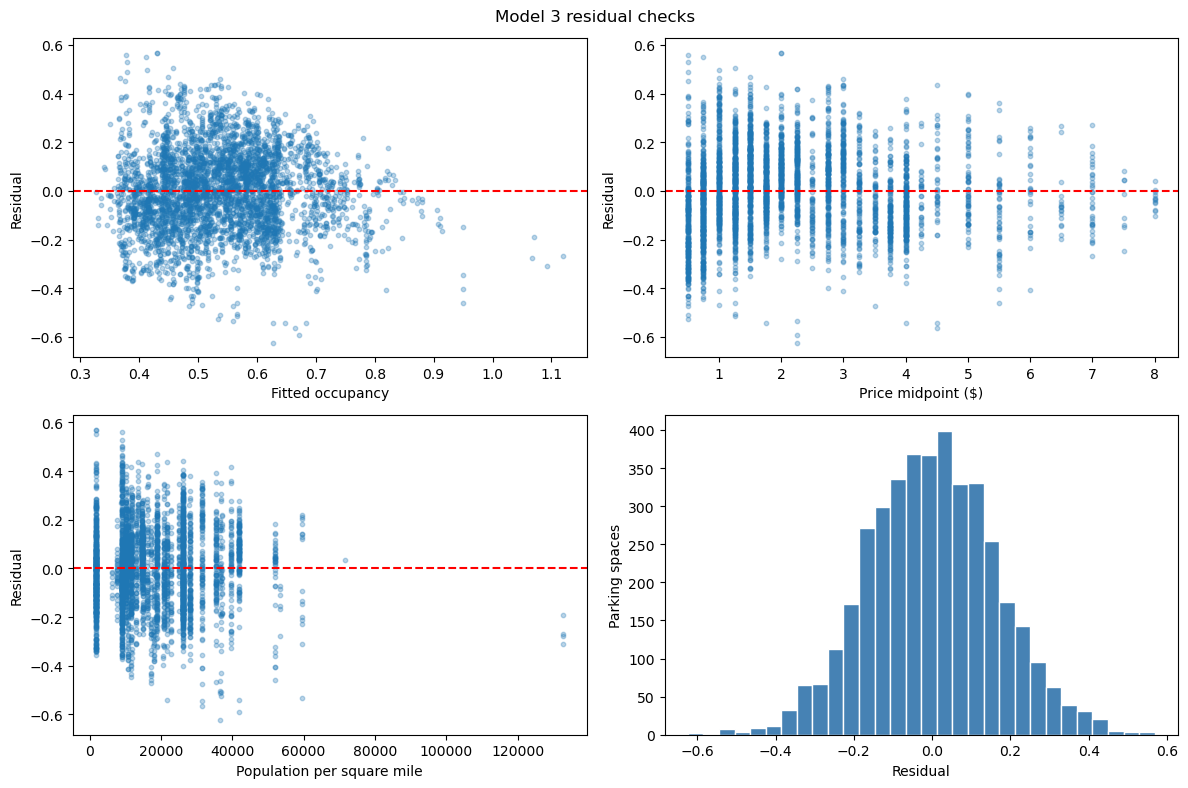

## 3. Check residual normality

I compare internally standardized residuals with normal quantiles and use the Jarque–Bera test, whose null is normal residuals. The histogram is shown in the preceding section rather than repeated here. With a large sample, a test can detect small departures, and failing to reject is not proof of normality.

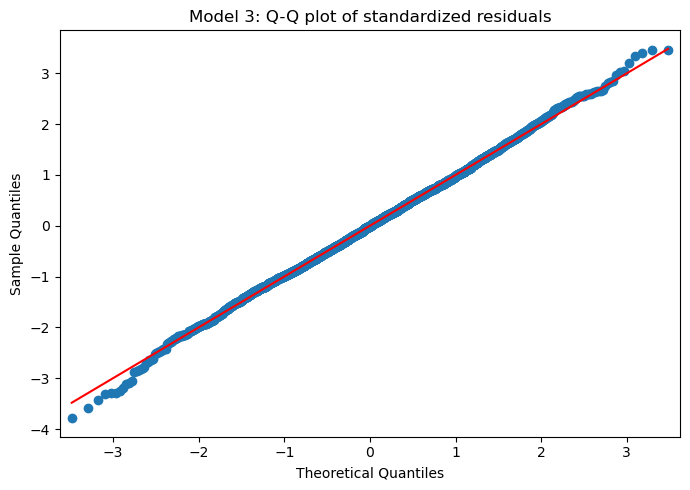

JB statistic    3.835976
P-value         0.146902
Skewness        0.031068
Kurtosis        3.138070
dtype: float64

## 4. Check constant variance and compare robust uncertainty

I use the lecture's scale-location plot, Breusch–Pagan test, and White test. Both tests have a null of constant error variance; I report their LM and F versions without treating them as separate independent checks. The scale-location plot uses the square root of absolute internally standardized residuals.

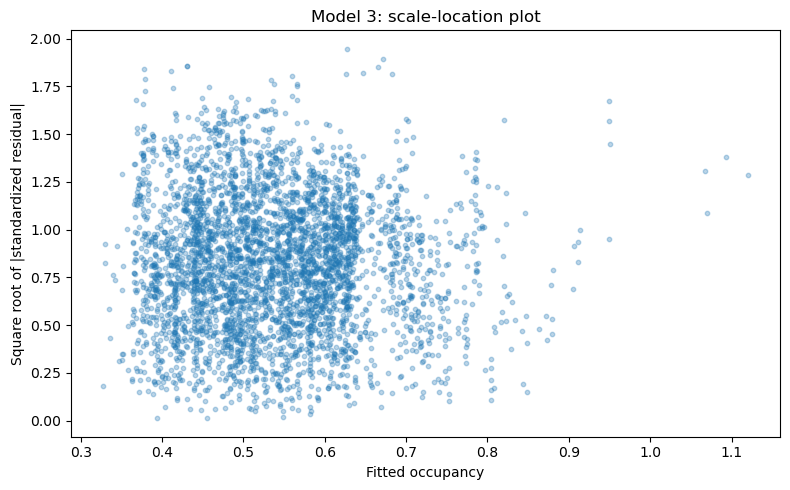

,Test,LM statistic,LM p-value,F statistic,F p-value
0,Breusch–Pagan (default Koenker version),207.230,3.374e-41,31.153,2.605e-42
1,White,394.973,4.755e-63,12.772,8.185e-67


Largest coefficient change: 0.0


,Coefficient,OLS SE,HC1 SE,OLS p-value,HC1 p-value,HC1 95% lower,HC1 95% upper
const,0.456337,0.0157939,0.0171155,6.470e-167,1.291e-156,0.422792,0.489883
price_midpoint,0.0556328,0.00236136,0.00232226,4.731e-115,7.931e-127,0.0510813,0.0601844
time_limit_hours,0.00487929,0.00294796,0.00313717,9.797e-02,1.199e-01,-0.00126946,0.011028
population_density,4.57052e-06,2.21771e-07,2.37074e-07,8.803e-90,8.077e-83,4.10586e-06,5.03518e-06
nearby_restaurant_retail_count,-0.000321282,2.29852e-05,2.4298e-05,2.189e-43,6.502e-40,-0.000368905,-0.000273659
drive_alone_share,-0.198101,0.0208314,0.0211007,3.195e-21,6.095e-21,-0.239458,-0.156744
transit_share,0.0196471,0.0468362,0.0452127,6.749e-01,6.639e-01,-0.0689682,0.108262
RateType_TOD,0.0330042,0.00731608,0.00857071,6.631e-06,1.177e-04,0.0162059,0.0498025


## 5. Check the linear functional form

I use the lecture's Ramsey RESET approach, adding the square of fitted values in an auxiliary test. The null is that this added term is unnecessary. A rejection points to a possible specification problem, not to the particular variable or transformation that would fix it.

<F test: F=122.0777512836214, p=5.604940901584903e-28, df_denom=4.01e+03, df_num=1>


## 6. Screen for influential observations

I link Cook's distance, leverage, and externally studentized residuals back to the unchanged source-row index and parking identifiers. I use the requested Cook's rule **4/n**, plus Lecture 1's **2p/n** leverage rule and **|studentized residual| > 2**, where p includes the intercept. These are screening rules, not evidence that a record is incorrect; the 4/n cutoff is supplied in the project instructions rather than shown as a worked lecture cutoff.

Rows align with the model: True
n, p (including intercept): 4016 8
Cook cutoff: 0.00099601593625498
Leverage cutoff: 0.00398406374501992


cook_flag        249
leverage_flag    136
residual_flag    189
dtype: int64

,SpaceID,BlockFace,GEOID,cooks_d,hat_diag,studentized_residual,cook_flag,leverage_flag,residual_flag
1487,CB3699,601 MAIN ST,06037207308,0.012662,0.009496,-3.254396,True,True,True
1464,CB3647,501 SPRING ST,06037207304,0.011832,0.025590,-1.899096,True,True,False
1466,CB3648B,501 SPRING ST,06037207304,0.009983,0.026675,-1.707438,True,True,False
1468,CB3651,601 SPRING ST,06037207304,0.009970,0.028511,-1.648906,True,True,False
1952,CB4486,700 BROADWAY,06037207303,0.007409,0.009203,2.527712,True,True,True
463,CB1616,900 FIGUEROA ST,06037207901,0.006182,0.006276,-2.800825,True,True,True
2739,HO482,6301 YUCCA ST,06037190201,0.005751,0.003557,-3.595343,True,False,True
464,CB1617,900 FIGUEROA ST,06037207901,0.004745,0.006265,-2.455299,True,True,True
1465,CB3648,501 SPRING ST,06037207304,0.004721,0.026527,-1.177304,True,True,False
1139,CB2930,600 HILL ST,06037207305,0.004482,0.005088,2.649829,True,True,True


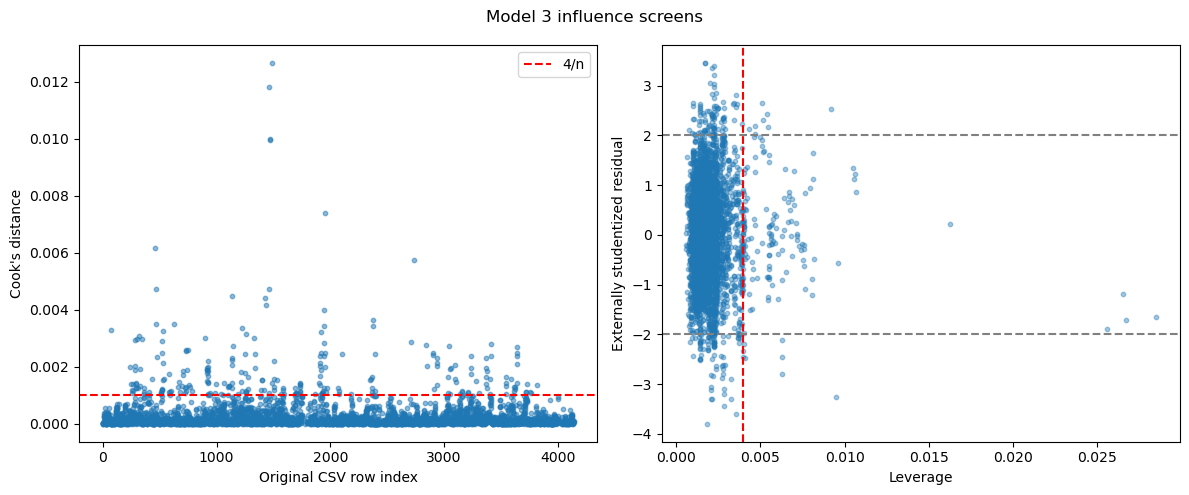

## 7. Check sensitivity to Cook's-distance flags

I refit the same seven-variable specification after excluding only spaces above 4/n for Cook's distance. This is a sensitivity comparison, not a new cleaning rule, and I keep the 4,016-space fit as primary. Fit statistics across different samples do not establish that the screened sample is a better model.

,Sample,N,Price coefficient,Price p-value,Adjusted R2
0,Full sample (primary),4016,0.055633,4.731e-115,0.27235
1,Cook <= 4/n (sensitivity),3767,0.054769,1.393e-133,0.36202


,Full-sample coefficient,Sensitivity coefficient,Sensitivity p-value
const,0.456337,0.48932,2.835e-222
price_midpoint,0.0556328,0.054769,1.393e-133
time_limit_hours,0.00487929,0.0027943,2.905e-01
population_density,4.57052e-06,5.30055e-06,4.065e-132
nearby_restaurant_retail_count,-0.000321282,-0.000390916,2.212e-72
drive_alone_share,-0.198101,-0.247766,2.910e-39
transit_share,0.0196471,-0.03217,4.334e-01
RateType_TOD,0.0330042,0.0339612,7.397e-07


## 8. Bootstrap the preferred specification

I follow the row-resampling examples in Lectures 1–2: sample with replacement, fit the same model, and record its coefficients for **1,000 replications**, with seed **90095**. I summarize all coefficients to match the assignment, then focus on price. This holds the selected specification fixed rather than rerunning variable selection in every draw.

Bootstrap replications: 1000


,Original OLS,Bootstrap mean,Bootstrap SE,Percentile 95% lower,Percentile 95% upper
const,0.456337,0.456724,0.017315,0.422518,0.49125
price_midpoint,0.0556328,0.0554847,0.00237433,0.0509139,0.0601064
time_limit_hours,0.00487929,0.0049741,0.00314588,-0.000987099,0.0110299
population_density,4.57052e-06,4.58343e-06,2.35249e-07,4.11908e-06,5.07294e-06
nearby_restaurant_retail_count,-0.000321282,-0.000321162,2.41982e-05,-0.000371127,-0.000273167
drive_alone_share,-0.198101,-0.199397,0.0213658,-0.244678,-0.157657
transit_share,0.0196471,0.0202927,0.0445782,-0.0653932,0.102353
RateType_TOD,0.0330042,0.0327779,0.0086254,0.0160399,0.0487384


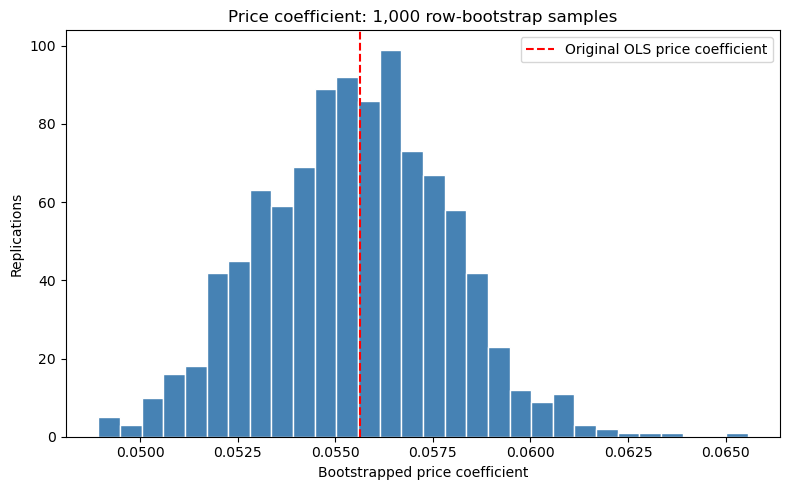

## 9. Reference the existing cross-validation results

Notebook 06, Section 8, already performs the required five-fold comparison with seed 10, identical folds across models, and training-only fits for held-out predictions. The assignment asks for five **or** ten folds, so I do not repeat that analysis or add ten folds unnecessarily. The following values are copied from its executed output, not reestimated here.

,Model,Mean held-out RMSE (Notebook 06)
0,Model 1,0.17756
1,Model 2,0.16834
2,Model 3,0.16532


## 10. Document the remaining sensor sensitivities

The current outcome retains intervals at most 24 hours and spaces with at least 25 transaction-active days. I inspect coverage in the existing 4,016-space sample below, without changing the outcome or applying an alternative sample rule. Active days are not necessarily fully monitored days.

Transaction-active days in the primary sample:
active_days
25     356
26    2032
27      19
28      45
29      89
30     184
31    1291
Name: count, dtype: int64


count    4016.000000
mean        0.822536
std         0.117815
min         0.315420
25%         0.741356
50%         0.775555
75%         0.966179
max         0.999898
Name: total_minutes, dtype: float64

### Processing needed before the sensor checks can proceed

The required input is `data/raw/ladot_occupancy/20261017T052111914317Z/Sensor Transactions_2025_08.csv`, containing **3,707,820 transactions**. I would parse the existing local timestamp format, sort within SpaceID, compute the next-record interval before excluding UNKNOWN states, and aggregate occupied/valid minutes separately under 12-, 24-, and 48-hour cutoffs. Raw active days would be counted before applying 20-, 25-, and 28-day restrictions.

The expanded samples would then need verified meter/predictor linkage; newly eligible spaces may lack the neighborhood predictors saved for the original sample. Comparisons should distinguish a common-space change in Y from a change in sample composition, and any new outputs must use separate paths. This raw-data rebuild requires approval under the task instructions, so it is **not implemented**, and Notebooks 01–06 and all existing datasets remain unchanged.

## 11. Summarize the diagnostics and remaining requirements

I combine the tests and robustness checks below, keeping screening rules distinct from decisions to change the data. A normality test that does not reject does not offset the variance and functional-form concerns. The price association is stable in the completed sensitivity checks, but its interpretation remains conditional and noncausal.

,Diagnostic,Result,Interpretation,Further investigation
0,Residual plots,Uneven spread; tract bands,Inspect variance and mean specification,Yes
1,Jarque–Bera,p = 0.147,Do not reject normality at 5%,Review with other assumptions
2,Breusch–Pagan LM,p = 3.374e-41,Reject constant variance,Yes; HC1 comparison shown
3,White LM,p = 4.755e-63,Reject constant variance,Yes
4,RESET,p = 5.605e-28,Possible functional-form problem,Yes
5,Influence,249 Cook flags / 4016,"Screening flags, not confirmed errors",Review identified spaces
6,Cook sensitivity,Price = 0.05477,Positive price association remains,Keep full sample primary
7,Row bootstrap,"1,000 draws; price CI [0.05091, 0.06011]",Positive interval; independence assumed,Dependence remains unresolved
8,Five-fold CV,Model 3 mean RMSE 0.16532 (Notebook 06),Best of the three fixed models,New-neighborhood validity unresolved
9,Sensor thresholds,Not rebuilt,Coverage rules may affect Y and sample,Approval needed for raw-data rebuild


### Assignment compliance and lecture coverage

| Requirement | Current status |
|---|---|
| Reproduce the common sample and Models 1–3 | Completed here; matches Notebook 06 |
| Residual plots, scale-location plot, normal Q-Q plot and Jarque–Bera | Completed here using Lectures 1–2 |
| Breusch–Pagan, White and Ramsey RESET | Completed here using Lecture 2 |
| Heteroskedasticity-consistent uncertainty | HC1 completed using worked Lecture 2 code; HC3 is named but not demonstrated as a worked comparison |
| Cook's distance, leverage, studentized residuals and influence sensitivity | Completed here; 4/n is the requested project screen, and the leverage/studentized rules appear in Lecture 1 |
| DFBETAS | Required by the assignment but not found in the available lecture examples; still outstanding |
| Bootstrap coefficient estimates, 1,000 replications, compared with OLS | Completed here for all Model 3 coefficients, with price histogram and percentile interval |
| Five- or ten-fold validation and prediction accuracy | Already completed in Notebook 06; referenced here without repeating fits |
| Descriptive statistics, standard EDA plots and missingness | Completed in Notebook 04; predictor Q-Q/density plots, Pandas Profiling discussion and missingness sensitivity remain outstanding |
| Boruta, Mallows' Cp and VIF | Completed in Notebook 05 and left unchanged |
| Model comparison, coefficient interpretation and confidence intervals | Completed in Notebook 06, with additional uncertainty/sensitivity checks here |
| Assignment specification alignment | Model 2 still has four predictors versus the rubric's 2–3; Model 3's significance-based description needs justification, as noted in Notebook 06 |
| Sensor-cutoff/day/Sunday robustness | Still outstanding; no validated alternative files, and raw-data rebuild requires approval |
| Tract-clustered uncertainty | No worked example found in the available lectures; shared-neighborhood dependence remains a limitation |
| Economic literature, final policy/external-validity discussion, references and final presentation | Reserved for Notebook 08 / final report; no claim of complete submission compliance |
| PDF/HTML group submission with names and source code | Still outstanding |

The computational and statistical methods used here follow the reviewed lectures, apart from the Cook's 4/n screen explicitly supplied in the project instructions. I do not implement DFBETAS or clustered inference without course support. Notebook 08, earlier notebooks, and raw/processed files are not changed.

In [38]:
from IPython.display import display, Markdown
display(Markdown('### Historical source: 07_diagnostics.ipynb'))
_historical_bundles = [{'text/markdown': '# 07 — Regression Diagnostics and Robustness\n\nI check the preferred Model 3 from Notebook 06, keeping its seven predictors and 4,016-space sample unchanged. I examine residuals, variance and functional form, then compare influence sensitivity and a 1,000-replication bootstrap. The full-sample OLS model remains the primary specification throughout.\n\nI reviewed `project1-1.pdf`, `Regression_Lecture0.ipynb`, `Regression_Lecture1.ipynb`, `Regression_Lecture2.ipynb`, their available numbered copies, and `Case_1_430_Lab.ipynb` in Downloads, together with Notebooks 01 and 04–06. Lecture 1 supplies residual/normality plots and leverage screens; Lecture 2 supplies variance tests, RESET, influence plots, HC1 standard errors, and bootstrap examples. Methods not found in those materials are identified below rather than added silently.'}, {'text/markdown': '## 1. Load the data and reproduce Notebook 06\n\nI apply the same FLAT + TOD restriction and complete-case variable list as Notebook 06. Income is included only in the sample restriction to match Notebook 05, not as a predictor in any of the three models. I preserve the original row index so diagnostics can be linked back to the correct SpaceID and BlockFace.'}, {'text/plain': 'Original observations: 4139\nFLAT + TOD observations: 4060\n'}, {'text/plain': 'Missing values before the common-sample restriction:\noccupancy_rate                     0\nprice_midpoint                     0\ntime_limit_hours                   0\npopulation_density                 0\nnearby_restaurant_retail_count     0\ndrive_alone_share                  0\ntransit_share                      0\nRateType_TOD                       0\nmedian_income                     44\ndtype: int64\nComparison observations: 4016\nUnique SpaceIDs: 4016\nDuplicate SpaceIDs: 0\nCensus tracts: 45\n'}, {'text/html': ['<div>\n', '<style scoped>\n', '    .dataframe tbody tr th:only-of-type {\n', '        vertical-align: middle;\n', '    }\n', '\n', '    .dataframe tbody tr th {\n', '        vertical-align: top;\n', '    }\n', '\n', '    .dataframe thead th {\n', '        text-align: right;\n', '    }\n', '</style>\n', '<table border="1" class="dataframe">\n', '  <thead>\n', '    <tr style="text-align: right;">\n', '      <th></th>\n', '      <th>Model</th>\n', '      <th>N</th>\n', '      <th>Adjusted R2</th>\n', '      <th>AIC</th>\n', '      <th>BIC</th>\n', '    </tr>\n', '  </thead>\n', '  <tbody>\n', '    <tr>\n', '      <th>0</th>\n', '      <td>Model 1</td>\n', '      <td>4016</td>\n', '      <td>0.15657</td>\n', '      <td>-2483.67051</td>\n', '      <td>-2471.07443</td>\n', '    </tr>\n', '    <tr>\n', '      <th>1</th>\n', '      <td>Model 2</td>\n', '      <td>4016</td>\n', '      <td>0.24303</td>\n', '      <td>-2915.05190</td>\n', '      <td>-2883.56169</td>\n', '    </tr>\n', '    <tr>\n', '      <th>2</th>\n', '      <td>Model 3</td>\n', '      <td>4016</td>\n', '      <td>0.27235</td>\n', '      <td>-3070.71241</td>\n', '      <td>-3020.32808</td>\n', '    </tr>\n', '  </tbody>\n', '</table>\n', '</div>'], 'text/plain': ['     Model     N  Adjusted R2         AIC         BIC\n', '0  Model 1  4016      0.15657 -2483.67051 -2471.07443\n', '1  Model 2  4016      0.24303 -2915.05190 -2883.56169\n', '2  Model 3  4016      0.27235 -3070.71241 -3020.32808']}, {'text/html': ['<style type="text/css">\n', '</style>\n', '<table id="T_d154d">\n', '  <thead>\n', '    <tr>\n', '      <th class="blank level0" >&nbsp;</th>\n', '      <th id="T_d154d_level0_col0" class="col_heading level0 col0" >Model 1</th>\n', '      <th id="T_d154d_level0_col1" class="col_heading level0 col1" >Model 2</th>\n', '      <th id="T_d154d_level0_col2" class="col_heading level0 col2" >Model 3</th>\n', '    </tr>\n', '  </thead>\n', '  <tbody>\n', '    <tr>\n', '      <th id="T_d154d_level0_row0" class="row_heading level0 row0" >RateType_TOD</th>\n', '      <td id="T_d154d_row0_col0" class="data row0 col0" >—</td>\n', '      <td id="T_d154d_row0_col1" class="data row0 col1" >—</td>\n', '      <td id="T_d154d_row0_col2" class="data row0 col2" >0.0330042</td>\n', '    </tr>\n', '    <tr>\n', '      <th id="T_d154d_level0_row1" class="row_heading level0 row1" >const</th>\n', '      <td id="T_d154d_row1_col0" class="data row1 col0" >0.42375</td>\n', '      <td id="T_d154d_row1_col1" class="data row1 col1" >0.382602</td>\n', '      <td id="T_d154d_row1_col2" class="data row1 col2" >0.456337</td>\n', '    </tr>\n', '    <tr>\n', '      <th id="T_d154d_level0_row2" class="row_heading level0 row2" >drive_alone_share</th>\n', '      <td id="T_d154d_row2_col0" class="data row2 col0" >—</td>\n', '      <td id="T_d154d_row2_col1" class="data row2 col1" >—</td>\n', '      <td id="T_d154d_row2_col2" class="data row2 col2" >-0.198101</td>\n', '    </tr>\n', '    <tr>\n', '      <th id="T_d154d_level0_row3" class="row_heading level0 row3" >nearby_restaurant_retail_count</th>\n', '      <td id="T_d154d_row3_col0" class="data row3 col0" >—</td>\n', '      <td id="T_d154d_row3_col1" class="data row3 col1" >-0.000229516</td>\n', '      <td id="T_d154d_row3_col2" class="data row3 col2" >-0.000321282</td>\n', '    </tr>\n', '    <tr>\n', '      <th id="T_d154d_level0_row4" class="row_heading level0 row4" >population_density</th>\n', '      <td id="T_d154d_row4_col0" class="data row4 col0" >—</td>\n', '      <td id="T_d154d_row4_col1" class="data row4 col1" >4.0583e-06</td>\n', '      <td id="T_d154d_row4_col2" class="data row4 col2" >4.57052e-06</td>\n', '    </tr>\n', '    <tr>\n', '      <th id="T_d154d_level0_row5" class="row_heading level0 row5" >price_midpoint</th>\n', '      <td id="T_d154d_row5_col0" class="data row5 col0" >0.0545148</td>\n', '      <td id="T_d154d_row5_col1" class="data row5 col1" >0.0606406</td>\n', '      <td id="T_d154d_row5_col2" class="data row5 col2" >0.0556328</td>\n', '    </tr>\n', '    <tr>\n', '      <th id="T_d154d_level0_row6" class="row_heading level0 row6" >time_limit_hours</th>\n', '      <td id="T_d154d_row6_col0" class="data row6 col0" >—</td>\n', '      <td id="T_d154d_row6_col1" class="data row6 col1" >0.00364837</td>\n', '      <td id="T_d154d_row6_col2" class="data row6 col2" >0.00487929</td>\n', '    </tr>\n', '    <tr>\n', '      <th id="T_d154d_level0_row7" class="row_heading level0 row7" >transit_share</th>\n', '      <td id="T_d154d_row7_col0" class="data row7 col0" >—</td>\n', '      <td id="T_d154d_row7_col1" class="data row7 col1" >—</td>\n', '      <td id="T_d154d_row7_col2" class="data row7 col2" >0.0196471</td>\n', '    </tr>\n', '  </tbody>\n', '</table>\n'], 'text/plain': ['<pandas.io.formats.style.Styler at 0x300a1af90>']}, {'text/markdown': '## 2. Inspect the residual plots\n\nI calculate fitted occupancy, residuals, and internally standardized residuals using the lecture approach. I plot residuals against fitted occupancy, price, and population density to look for changing spread or systematic patterns. The histogram gives a first view of the residual distribution without deleting unusual observations.'}, {'text/plain': 'Fitted occupancy outside [0, 1]: 4\n'}, {'text/plain': ['count    4.016000e+03\n', 'mean    -3.244116e-13\n', 'std      1.647846e-01\n', 'min     -6.240984e-01\n', '25%     -1.125996e-01\n', '50%     -6.126102e-04\n', '75%      1.102839e-01\n', 'max      5.685229e-01\n', 'dtype: float64']}, {'image/png': '...', 'text/plain': ['<Figure size 1200x800 with 4 Axes>']}, {'text/markdown': '## 3. Check residual normality\n\nI compare internally standardized residuals with normal quantiles and use the Jarque–Bera test, whose null is normal residuals. The histogram is shown in the preceding section rather than repeated here. With a large sample, a test can detect small departures, and failing to reject is not proof of normality.'}, {'image/png': '...', 'text/plain': ['<Figure size 700x500 with 1 Axes>']}, {'text/plain': ['JB statistic    3.835976\n', 'P-value         0.146902\n', 'Skewness        0.031068\n', 'Kurtosis        3.138070\n', 'dtype: float64']}, {'text/markdown': "## 4. Check constant variance and compare robust uncertainty\n\nI use the lecture's scale-location plot, Breusch–Pagan test, and White test. Both tests have a null of constant error variance; I report their LM and F versions without treating them as separate independent checks. The scale-location plot uses the square root of absolute internally standardized residuals."}, {'image/png': '...', 'text/plain': ['<Figure size 800x500 with 1 Axes>']}, {'text/html': ['<style type="text/css">\n', '</style>\n', '<table id="T_042f0">\n', '  <thead>\n', '    <tr>\n', '      <th class="blank level0" >&nbsp;</th>\n', '      <th id="T_042f0_level0_col0" class="col_heading level0 col0" >Test</th>\n', '      <th id="T_042f0_level0_col1" class="col_heading level0 col1" >LM statistic</th>\n', '      <th id="T_042f0_level0_col2" class="col_heading level0 col2" >LM p-value</th>\n', '      <th id="T_042f0_level0_col3" class="col_heading level0 col3" >F statistic</th>\n', '      <th id="T_042f0_level0_col4" class="col_heading level0 col4" >F p-value</th>\n', '    </tr>\n', '  </thead>\n', '  <tbody>\n', '    <tr>\n', '      <th id="T_042f0_level0_row0" class="row_heading level0 row0" >0</th>\n', '      <td id="T_042f0_row0_col0" class="data row0 col0" >Breusch–Pagan (default Koenker version)</td>\n', '      <td id="T_042f0_row0_col1" class="data row0 col1" >207.230</td>\n', '      <td id="T_042f0_row0_col2" class="data row0 col2" >3.374e-41</td>\n', '      <td id="T_042f0_row0_col3" class="data row0 col3" >31.153</td>\n', '      <td id="T_042f0_row0_col4" class="data row0 col4" >2.605e-42</td>\n', '    </tr>\n', '    <tr>\n', '      <th id="T_042f0_level0_row1" class="row_heading level0 row1" >1</th>\n', '      <td id="T_042f0_row1_col0" class="data row1 col0" >White</td>\n', '      <td id="T_042f0_row1_col1" class="data row1 col1" >394.973</td>\n', '      <td id="T_042f0_row1_col2" class="data row1 col2" >4.755e-63</td>\n', '      <td id="T_042f0_row1_col3" class="data row1 col3" >12.772</td>\n', '      <td id="T_042f0_row1_col4" class="data row1 col4" >8.185e-67</td>\n', '    </tr>\n', '  </tbody>\n', '</table>\n'], 'text/plain': ['<pandas.io.formats.style.Styler at 0x300fb56d0>']}, {'text/plain': 'Largest coefficient change: 0.0\n'}, {'text/html': ['<style type="text/css">\n', '</style>\n', '<table id="T_2fd5a">\n', '  <thead>\n', '    <tr>\n', '      <th class="blank level0" >&nbsp;</th>\n', '      <th id="T_2fd5a_level0_col0" class="col_heading level0 col0" >Coefficient</th>\n', '      <th id="T_2fd5a_level0_col1" class="col_heading level0 col1" >OLS SE</th>\n', '      <th id="T_2fd5a_level0_col2" class="col_heading level0 col2" >HC1 SE</th>\n', '      <th id="T_2fd5a_level0_col3" class="col_heading level0 col3" >OLS p-value</th>\n', '      <th id="T_2fd5a_level0_col4" class="col_heading level0 col4" >HC1 p-value</th>\n', '      <th id="T_2fd5a_level0_col5" class="col_heading level0 col5" >HC1 95% lower</th>\n', '      <th id="T_2fd5a_level0_col6" class="col_heading level0 col6" >HC1 95% upper</th>\n', '    </tr>\n', '  </thead>\n', '  <tbody>\n', '    <tr>\n', '      <th id="T_2fd5a_level0_row0" class="row_heading level0 row0" >const</th>\n', '      <td id="T_2fd5a_row0_col0" class="data row0 col0" >0.456337</td>\n', '      <td id="T_2fd5a_row0_col1" class="data row0 col1" >0.0157939</td>\n', '      <td id="T_2fd5a_row0_col2" class="data row0 col2" >0.0171155</td>\n', '      <td id="T_2fd5a_row0_col3" class="data row0 col3" >6.470e-167</td>\n', '      <td id="T_2fd5a_row0_col4" class="data row0 col4" >1.291e-156</td>\n', '      <td id="T_2fd5a_row0_col5" class="data row0 col5" >0.422792</td>\n', '      <td id="T_2fd5a_row0_col6" class="data row0 col6" >0.489883</td>\n', '    </tr>\n', '    <tr>\n', '      <th id="T_2fd5a_level0_row1" class="row_heading level0 row1" >price_midpoint</th>\n', '      <td id="T_2fd5a_row1_col0" class="data row1 col0" >0.0556328</td>\n', '      <td id="T_2fd5a_row1_col1" class="data row1 col1" >0.00236136</td>\n', '      <td id="T_2fd5a_row1_col2" class="data row1 col2" >0.00232226</td>\n', '      <td id="T_2fd5a_row1_col3" class="data row1 col3" >4.731e-115</td>\n', '      <td id="T_2fd5a_row1_col4" class="data row1 col4" >7.931e-127</td>\n', '      <td id="T_2fd5a_row1_col5" class="data row1 col5" >0.0510813</td>\n', '      <td id="T_2fd5a_row1_col6" class="data row1 col6" >0.0601844</td>\n', '    </tr>\n', '    <tr>\n', '      <th id="T_2fd5a_level0_row2" class="row_heading level0 row2" >time_limit_hours</th>\n', '      <td id="T_2fd5a_row2_col0" class="data row2 col0" >0.00487929</td>\n', '      <td id="T_2fd5a_row2_col1" class="data row2 col1" >0.00294796</td>\n', '      <td id="T_2fd5a_row2_col2" class="data row2 col2" >0.00313717</td>\n', '      <td id="T_2fd5a_row2_col3" class="data row2 col3" >9.797e-02</td>\n', '      <td id="T_2fd5a_row2_col4" class="data row2 col4" >1.199e-01</td>\n', '      <td id="T_2fd5a_row2_col5" class="data row2 col5" >-0.00126946</td>\n', '      <td id="T_2fd5a_row2_col6" class="data row2 col6" >0.011028</td>\n', '    </tr>\n', '    <tr>\n', '      <th id="T_2fd5a_level0_row3" class="row_heading level0 row3" >population_density</th>\n', '      <td id="T_2fd5a_row3_col0" class="data row3 col0" >4.57052e-06</td>\n', '      <td id="T_2fd5a_row3_col1" class="data row3 col1" >2.21771e-07</td>\n', '      <td id="T_2fd5a_row3_col2" class="data row3 col2" >2.37074e-07</td>\n', '      <td id="T_2fd5a_row3_col3" class="data row3 col3" >8.803e-90</td>\n', '      <td id="T_2fd5a_row3_col4" class="data row3 col4" >8.077e-83</td>\n', '      <td id="T_2fd5a_row3_col5" class="data row3 col5" >4.10586e-06</td>\n', '      <td id="T_2fd5a_row3_col6" class="data row3 col6" >5.03518e-06</td>\n', '    </tr>\n', '    <tr>\n', '      <th id="T_2fd5a_level0_row4" class="row_heading level0 row4" >nearby_restaurant_retail_count</th>\n', '      <td id="T_2fd5a_row4_col0" class="data row4 col0" >-0.000321282</td>\n', '      <td id="T_2fd5a_row4_col1" class="data row4 col1" >2.29852e-05</td>\n', '      <td id="T_2fd5a_row4_col2" class="data row4 col2" >2.4298e-05</td>\n', '      <td id="T_2fd5a_row4_col3" class="data row4 col3" >2.189e-43</td>\n', '      <td id="T_2fd5a_row4_col4" class="data row4 col4" >6.502e-40</td>\n', '      <td id="T_2fd5a_row4_col5" class="data row4 col5" >-0.000368905</td>\n', '      <td id="T_2fd5a_row4_col6" class="data row4 col6" >-0.000273659</td>\n', '    </tr>\n', '    <tr>\n', '      <th id="T_2fd5a_level0_row5" class="row_heading level0 row5" >drive_alone_share</th>\n', '      <td id="T_2fd5a_row5_col0" class="data row5 col0" >-0.198101</td>\n', '      <td id="T_2fd5a_row5_col1" class="data row5 col1" >0.0208314</td>\n', '      <td id="T_2fd5a_row5_col2" class="data row5 col2" >0.0211007</td>\n', '      <td id="T_2fd5a_row5_col3" class="data row5 col3" >3.195e-21</td>\n', '      <td id="T_2fd5a_row5_col4" class="data row5 col4" >6.095e-21</td>\n', '      <td id="T_2fd5a_row5_col5" class="data row5 col5" >-0.239458</td>\n', '      <td id="T_2fd5a_row5_col6" class="data row5 col6" >-0.156744</td>\n', '    </tr>\n', '    <tr>\n', '      <th id="T_2fd5a_level0_row6" class="row_heading level0 row6" >transit_share</th>\n', '      <td id="T_2fd5a_row6_col0" class="data row6 col0" >0.0196471</td>\n', '      <td id="T_2fd5a_row6_col1" class="data row6 col1" >0.0468362</td>\n', '      <td id="T_2fd5a_row6_col2" class="data row6 col2" >0.0452127</td>\n', '      <td id="T_2fd5a_row6_col3" class="data row6 col3" >6.749e-01</td>\n', '      <td id="T_2fd5a_row6_col4" class="data row6 col4" >6.639e-01</td>\n', '      <td id="T_2fd5a_row6_col5" class="data row6 col5" >-0.0689682</td>\n', '      <td id="T_2fd5a_row6_col6" class="data row6 col6" >0.108262</td>\n', '    </tr>\n', '    <tr>\n', '      <th id="T_2fd5a_level0_row7" class="row_heading level0 row7" >RateType_TOD</th>\n', '      <td id="T_2fd5a_row7_col0" class="data row7 col0" >0.0330042</td>\n', '      <td id="T_2fd5a_row7_col1" class="data row7 col1" >0.00731608</td>\n', '      <td id="T_2fd5a_row7_col2" class="data row7 col2" >0.00857071</td>\n', '      <td id="T_2fd5a_row7_col3" class="data row7 col3" >6.631e-06</td>\n', '      <td id="T_2fd5a_row7_col4" class="data row7 col4" >1.177e-04</td>\n', '      <td id="T_2fd5a_row7_col5" class="data row7 col5" >0.0162059</td>\n', '      <td id="T_2fd5a_row7_col6" class="data row7 col6" >0.0498025</td>\n', '    </tr>\n', '  </tbody>\n', '</table>\n'], 'text/plain': ['<pandas.io.formats.style.Styler at 0x302142e90>']}, {'text/markdown': "## 5. Check the linear functional form\n\nI use the lecture's Ramsey RESET approach, adding the square of fitted values in an auxiliary test. The null is that this added term is unnecessary. A rejection points to a possible specification problem, not to the particular variable or transformation that would fix it."}, {'text/plain': '<F test: F=122.0777512836214, p=5.604940901584903e-28, df_denom=4.01e+03, df_num=1>\n'}, {'text/markdown': "## 6. Screen for influential observations\n\nI link Cook's distance, leverage, and externally studentized residuals back to the unchanged source-row index and parking identifiers. I use the requested Cook's rule **4/n**, plus Lecture 1's **2p/n** leverage rule and **|studentized residual| > 2**, where p includes the intercept. These are screening rules, not evidence that a record is incorrect; the 4/n cutoff is supplied in the project instructions rather than shown as a worked lecture cutoff."}, {'text/plain': 'Rows align with the model: True\nn, p (including intercept): 4016 8\nCook cutoff: 0.00099601593625498\nLeverage cutoff: 0.00398406374501992\n'}, {'text/plain': ['cook_flag        249\n', 'leverage_flag    136\n', 'residual_flag    189\n', 'dtype: int64']}, {'text/html': ['<div>\n', '<style scoped>\n', '    .dataframe tbody tr th:only-of-type {\n', '        vertical-align: middle;\n', '    }\n', '\n', '    .dataframe tbody tr th {\n', '        vertical-align: top;\n', '    }\n', '\n', '    .dataframe thead th {\n', '        text-align: right;\n', '    }\n', '</style>\n', '<table border="1" class="dataframe">\n', '  <thead>\n', '    <tr style="text-align: right;">\n', '      <th></th>\n', '      <th>SpaceID</th>\n', '      <th>BlockFace</th>\n', '      <th>GEOID</th>\n', '      <th>cooks_d</th>\n', '      <th>hat_diag</th>\n', '      <th>studentized_residual</th>\n', '      <th>cook_flag</th>\n', '      <th>leverage_flag</th>\n', '      <th>residual_flag</th>\n', '    </tr>\n', '  </thead>\n', '  <tbody>\n', '    <tr>\n', '      <th>1487</th>\n', '      <td>CB3699</td>\n', '      <td>601 MAIN ST</td>\n', '      <td>06037207308</td>\n', '      <td>0.012662</td>\n', '      <td>0.009496</td>\n', '      <td>-3.254396</td>\n', '      <td>True</td>\n', '      <td>True</td>\n', '      <td>True</td>\n', '    </tr>\n', '    <tr>\n', '      <th>1464</th>\n', '      <td>CB3647</td>\n', '      <td>501 SPRING ST</td>\n', '      <td>06037207304</td>\n', '      <td>0.011832</td>\n', '      <td>0.025590</td>\n', '      <td>-1.899096</td>\n', '      <td>True</td>\n', '      <td>True</td>\n', '      <td>False</td>\n', '    </tr>\n', '    <tr>\n', '      <th>1466</th>\n', '      <td>CB3648B</td>\n', '      <td>501 SPRING ST</td>\n', '      <td>06037207304</td>\n', '      <td>0.009983</td>\n', '      <td>0.026675</td>\n', '      <td>-1.707438</td>\n', '      <td>True</td>\n', '      <td>True</td>\n', '      <td>False</td>\n', '    </tr>\n', '    <tr>\n', '      <th>1468</th>\n', '      <td>CB3651</td>\n', '      <td>601 SPRING ST</td>\n', '      <td>06037207304</td>\n', '      <td>0.009970</td>\n', '      <td>0.028511</td>\n', '      <td>-1.648906</td>\n', '      <td>True</td>\n', '      <td>True</td>\n', '      <td>False</td>\n', '    </tr>\n', '    <tr>\n', '      <th>1952</th>\n', '      <td>CB4486</td>\n', '      <td>700 BROADWAY</td>\n', '      <td>06037207303</td>\n', '      <td>0.007409</td>\n', '      <td>0.009203</td>\n', '      <td>2.527712</td>\n', '      <td>True</td>\n', '      <td>True</td>\n', '      <td>True</td>\n', '    </tr>\n', '    <tr>\n', '      <th>463</th>\n', '      <td>CB1616</td>\n', '      <td>900 FIGUEROA ST</td>\n', '      <td>06037207901</td>\n', '      <td>0.006182</td>\n', '      <td>0.006276</td>\n', '      <td>-2.800825</td>\n', '      <td>True</td>\n', '      <td>True</td>\n', '      <td>True</td>\n', '    </tr>\n', '    <tr>\n', '      <th>2739</th>\n', '      <td>HO482</td>\n', '      <td>6301 YUCCA ST</td>\n', '      <td>06037190201</td>\n', '      <td>0.005751</td>\n', '      <td>0.003557</td>\n', '      <td>-3.595343</td>\n', '      <td>True</td>\n', '      <td>False</td>\n', '      <td>True</td>\n', '    </tr>\n', '    <tr>\n', '      <th>464</th>\n', '      <td>CB1617</td>\n', '      <td>900 FIGUEROA ST</td>\n', '      <td>06037207901</td>\n', '      <td>0.004745</td>\n', '      <td>0.006265</td>\n', '      <td>-2.455299</td>\n', '      <td>True</td>\n', '      <td>True</td>\n', '      <td>True</td>\n', '    </tr>\n', '    <tr>\n', '      <th>1465</th>\n', '      <td>CB3648</td>\n', '      <td>501 SPRING ST</td>\n', '      <td>06037207304</td>\n', '      <td>0.004721</td>\n', '      <td>0.026527</td>\n', '      <td>-1.177304</td>\n', '      <td>True</td>\n', '      <td>True</td>\n', '      <td>False</td>\n', '    </tr>\n', '    <tr>\n', '      <th>1139</th>\n', '      <td>CB2930</td>\n', '      <td>600 HILL ST</td>\n', '      <td>06037207305</td>\n', '      <td>0.004482</td>\n', '      <td>0.005088</td>\n', '      <td>2.649829</td>\n', '      <td>True</td>\n', '      <td>True</td>\n', '      <td>True</td>\n', '    </tr>\n', '  </tbody>\n', '</table>\n', '</div>'], 'text/plain': ['      SpaceID        BlockFace        GEOID   cooks_d  hat_diag  \\\n', '1487   CB3699      601 MAIN ST  06037207308  0.012662  0.009496   \n', '1464   CB3647    501 SPRING ST  06037207304  0.011832  0.025590   \n', '1466  CB3648B    501 SPRING ST  06037207304  0.009983  0.026675   \n', '1468   CB3651    601 SPRING ST  06037207304  0.009970  0.028511   \n', '1952   CB4486     700 BROADWAY  06037207303  0.007409  0.009203   \n', '463    CB1616  900 FIGUEROA ST  06037207901  0.006182  0.006276   \n', '2739    HO482    6301 YUCCA ST  06037190201  0.005751  0.003557   \n', '464    CB1617  900 FIGUEROA ST  06037207901  0.004745  0.006265   \n', '1465   CB3648    501 SPRING ST  06037207304  0.004721  0.026527   \n', '1139   CB2930      600 HILL ST  06037207305  0.004482  0.005088   \n', '\n', '      studentized_residual  cook_flag  leverage_flag  residual_flag  \n', '1487             -3.254396       True           True           True  \n', '1464             -1.899096       True           True          False  \n', '1466             -1.707438       True           True          False  \n', '1468             -1.648906       True           True          False  \n', '1952              2.527712       True           True           True  \n', '463              -2.800825       True           True           True  \n', '2739             -3.595343       True          False           True  \n', '464              -2.455299       True           True           True  \n', '1465             -1.177304       True           True          False  \n', '1139              2.649829       True           True           True  ']}, {'image/png': '...', 'text/plain': ['<Figure size 1200x500 with 2 Axes>']}, {'text/markdown': "## 7. Check sensitivity to Cook's-distance flags\n\nI refit the same seven-variable specification after excluding only spaces above 4/n for Cook's distance. This is a sensitivity comparison, not a new cleaning rule, and I keep the 4,016-space fit as primary. Fit statistics across different samples do not establish that the screened sample is a better model."}, {'text/html': ['<style type="text/css">\n', '</style>\n', '<table id="T_15c4a">\n', '  <thead>\n', '    <tr>\n', '      <th class="blank level0" >&nbsp;</th>\n', '      <th id="T_15c4a_level0_col0" class="col_heading level0 col0" >Sample</th>\n', '      <th id="T_15c4a_level0_col1" class="col_heading level0 col1" >N</th>\n', '      <th id="T_15c4a_level0_col2" class="col_heading level0 col2" >Price coefficient</th>\n', '      <th id="T_15c4a_level0_col3" class="col_heading level0 col3" >Price p-value</th>\n', '      <th id="T_15c4a_level0_col4" class="col_heading level0 col4" >Adjusted R2</th>\n', '    </tr>\n', '  </thead>\n', '  <tbody>\n', '    <tr>\n', '      <th id="T_15c4a_level0_row0" class="row_heading level0 row0" >0</th>\n', '      <td id="T_15c4a_row0_col0" class="data row0 col0" >Full sample (primary)</td>\n', '      <td id="T_15c4a_row0_col1" class="data row0 col1" >4016</td>\n', '      <td id="T_15c4a_row0_col2" class="data row0 col2" >0.055633</td>\n', '      <td id="T_15c4a_row0_col3" class="data row0 col3" >4.731e-115</td>\n', '      <td id="T_15c4a_row0_col4" class="data row0 col4" >0.27235</td>\n', '    </tr>\n', '    <tr>\n', '      <th id="T_15c4a_level0_row1" class="row_heading level0 row1" >1</th>\n', '      <td id="T_15c4a_row1_col0" class="data row1 col0" >Cook <= 4/n (sensitivity)</td>\n', '      <td id="T_15c4a_row1_col1" class="data row1 col1" >3767</td>\n', '      <td id="T_15c4a_row1_col2" class="data row1 col2" >0.054769</td>\n', '      <td id="T_15c4a_row1_col3" class="data row1 col3" >1.393e-133</td>\n', '      <td id="T_15c4a_row1_col4" class="data row1 col4" >0.36202</td>\n', '    </tr>\n', '  </tbody>\n', '</table>\n'], 'text/plain': ['<pandas.io.formats.style.Styler at 0x3022191d0>']}, {'text/html': ['<style type="text/css">\n', '</style>\n', '<table id="T_7399e">\n', '  <thead>\n', '    <tr>\n', '      <th class="blank level0" >&nbsp;</th>\n', '      <th id="T_7399e_level0_col0" class="col_heading level0 col0" >Full-sample coefficient</th>\n', '      <th id="T_7399e_level0_col1" class="col_heading level0 col1" >Sensitivity coefficient</th>\n', '      <th id="T_7399e_level0_col2" class="col_heading level0 col2" >Sensitivity p-value</th>\n', '    </tr>\n', '  </thead>\n', '  <tbody>\n', '    <tr>\n', '      <th id="T_7399e_level0_row0" class="row_heading level0 row0" >const</th>\n', '      <td id="T_7399e_row0_col0" class="data row0 col0" >0.456337</td>\n', '      <td id="T_7399e_row0_col1" class="data row0 col1" >0.48932</td>\n', '      <td id="T_7399e_row0_col2" class="data row0 col2" >2.835e-222</td>\n', '    </tr>\n', '    <tr>\n', '      <th id="T_7399e_level0_row1" class="row_heading level0 row1" >price_midpoint</th>\n', '      <td id="T_7399e_row1_col0" class="data row1 col0" >0.0556328</td>\n', '      <td id="T_7399e_row1_col1" class="data row1 col1" >0.054769</td>\n', '      <td id="T_7399e_row1_col2" class="data row1 col2" >1.393e-133</td>\n', '    </tr>\n', '    <tr>\n', '      <th id="T_7399e_level0_row2" class="row_heading level0 row2" >time_limit_hours</th>\n', '      <td id="T_7399e_row2_col0" class="data row2 col0" >0.00487929</td>\n', '      <td id="T_7399e_row2_col1" class="data row2 col1" >0.0027943</td>\n', '      <td id="T_7399e_row2_col2" class="data row2 col2" >2.905e-01</td>\n', '    </tr>\n', '    <tr>\n', '      <th id="T_7399e_level0_row3" class="row_heading level0 row3" >population_density</th>\n', '      <td id="T_7399e_row3_col0" class="data row3 col0" >4.57052e-06</td>\n', '      <td id="T_7399e_row3_col1" class="data row3 col1" >5.30055e-06</td>\n', '      <td id="T_7399e_row3_col2" class="data row3 col2" >4.065e-132</td>\n', '    </tr>\n', '    <tr>\n', '      <th id="T_7399e_level0_row4" class="row_heading level0 row4" >nearby_restaurant_retail_count</th>\n', '      <td id="T_7399e_row4_col0" class="data row4 col0" >-0.000321282</td>\n', '      <td id="T_7399e_row4_col1" class="data row4 col1" >-0.000390916</td>\n', '      <td id="T_7399e_row4_col2" class="data row4 col2" >2.212e-72</td>\n', '    </tr>\n', '    <tr>\n', '      <th id="T_7399e_level0_row5" class="row_heading level0 row5" >drive_alone_share</th>\n', '      <td id="T_7399e_row5_col0" class="data row5 col0" >-0.198101</td>\n', '      <td id="T_7399e_row5_col1" class="data row5 col1" >-0.247766</td>\n', '      <td id="T_7399e_row5_col2" class="data row5 col2" >2.910e-39</td>\n', '    </tr>\n', '    <tr>\n', '      <th id="T_7399e_level0_row6" class="row_heading level0 row6" >transit_share</th>\n', '      <td id="T_7399e_row6_col0" class="data row6 col0" >0.0196471</td>\n', '      <td id="T_7399e_row6_col1" class="data row6 col1" >-0.03217</td>\n', '      <td id="T_7399e_row6_col2" class="data row6 col2" >4.334e-01</td>\n', '    </tr>\n', '    <tr>\n', '      <th id="T_7399e_level0_row7" class="row_heading level0 row7" >RateType_TOD</th>\n', '      <td id="T_7399e_row7_col0" class="data row7 col0" >0.0330042</td>\n', '      <td id="T_7399e_row7_col1" class="data row7 col1" >0.0339612</td>\n', '      <td id="T_7399e_row7_col2" class="data row7 col2" >7.397e-07</td>\n', '    </tr>\n', '  </tbody>\n', '</table>\n'], 'text/plain': ['<pandas.io.formats.style.Styler at 0x302219310>']}, {'text/markdown': '## 8. Bootstrap the preferred specification\n\nI follow the row-resampling examples in Lectures 1–2: sample with replacement, fit the same model, and record its coefficients for **1,000 replications**, with seed **90095**. I summarize all coefficients to match the assignment, then focus on price. This holds the selected specification fixed rather than rerunning variable selection in every draw.'}, {'text/plain': 'Bootstrap replications: 1000\n'}, {'text/html': ['<style type="text/css">\n', '</style>\n', '<table id="T_b74f1">\n', '  <thead>\n', '    <tr>\n', '      <th class="blank level0" >&nbsp;</th>\n', '      <th id="T_b74f1_level0_col0" class="col_heading level0 col0" >Original OLS</th>\n', '      <th id="T_b74f1_level0_col1" class="col_heading level0 col1" >Bootstrap mean</th>\n', '      <th id="T_b74f1_level0_col2" class="col_heading level0 col2" >Bootstrap SE</th>\n', '      <th id="T_b74f1_level0_col3" class="col_heading level0 col3" >Percentile 95% lower</th>\n', '      <th id="T_b74f1_level0_col4" class="col_heading level0 col4" >Percentile 95% upper</th>\n', '    </tr>\n', '  </thead>\n', '  <tbody>\n', '    <tr>\n', '      <th id="T_b74f1_level0_row0" class="row_heading level0 row0" >const</th>\n', '      <td id="T_b74f1_row0_col0" class="data row0 col0" >0.456337</td>\n', '      <td id="T_b74f1_row0_col1" class="data row0 col1" >0.456724</td>\n', '      <td id="T_b74f1_row0_col2" class="data row0 col2" >0.017315</td>\n', '      <td id="T_b74f1_row0_col3" class="data row0 col3" >0.422518</td>\n', '      <td id="T_b74f1_row0_col4" class="data row0 col4" >0.49125</td>\n', '    </tr>\n', '    <tr>\n', '      <th id="T_b74f1_level0_row1" class="row_heading level0 row1" >price_midpoint</th>\n', '      <td id="T_b74f1_row1_col0" class="data row1 col0" >0.0556328</td>\n', '      <td id="T_b74f1_row1_col1" class="data row1 col1" >0.0554847</td>\n', '      <td id="T_b74f1_row1_col2" class="data row1 col2" >0.00237433</td>\n', '      <td id="T_b74f1_row1_col3" class="data row1 col3" >0.0509139</td>\n', '      <td id="T_b74f1_row1_col4" class="data row1 col4" >0.0601064</td>\n', '    </tr>\n', '    <tr>\n', '      <th id="T_b74f1_level0_row2" class="row_heading level0 row2" >time_limit_hours</th>\n', '      <td id="T_b74f1_row2_col0" class="data row2 col0" >0.00487929</td>\n', '      <td id="T_b74f1_row2_col1" class="data row2 col1" >0.0049741</td>\n', '      <td id="T_b74f1_row2_col2" class="data row2 col2" >0.00314588</td>\n', '      <td id="T_b74f1_row2_col3" class="data row2 col3" >-0.000987099</td>\n', '      <td id="T_b74f1_row2_col4" class="data row2 col4" >0.0110299</td>\n', '    </tr>\n', '    <tr>\n', '      <th id="T_b74f1_level0_row3" class="row_heading level0 row3" >population_density</th>\n', '      <td id="T_b74f1_row3_col0" class="data row3 col0" >4.57052e-06</td>\n', '      <td id="T_b74f1_row3_col1" class="data row3 col1" >4.58343e-06</td>\n', '      <td id="T_b74f1_row3_col2" class="data row3 col2" >2.35249e-07</td>\n', '      <td id="T_b74f1_row3_col3" class="data row3 col3" >4.11908e-06</td>\n', '      <td id="T_b74f1_row3_col4" class="data row3 col4" >5.07294e-06</td>\n', '    </tr>\n', '    <tr>\n', '      <th id="T_b74f1_level0_row4" class="row_heading level0 row4" >nearby_restaurant_retail_count</th>\n', '      <td id="T_b74f1_row4_col0" class="data row4 col0" >-0.000321282</td>\n', '      <td id="T_b74f1_row4_col1" class="data row4 col1" >-0.000321162</td>\n', '      <td id="T_b74f1_row4_col2" class="data row4 col2" >2.41982e-05</td>\n', '      <td id="T_b74f1_row4_col3" class="data row4 col3" >-0.000371127</td>\n', '      <td id="T_b74f1_row4_col4" class="data row4 col4" >-0.000273167</td>\n', '    </tr>\n', '    <tr>\n', '      <th id="T_b74f1_level0_row5" class="row_heading level0 row5" >drive_alone_share</th>\n', '      <td id="T_b74f1_row5_col0" class="data row5 col0" >-0.198101</td>\n', '      <td id="T_b74f1_row5_col1" class="data row5 col1" >-0.199397</td>\n', '      <td id="T_b74f1_row5_col2" class="data row5 col2" >0.0213658</td>\n', '      <td id="T_b74f1_row5_col3" class="data row5 col3" >-0.244678</td>\n', '      <td id="T_b74f1_row5_col4" class="data row5 col4" >-0.157657</td>\n', '    </tr>\n', '    <tr>\n', '      <th id="T_b74f1_level0_row6" class="row_heading level0 row6" >transit_share</th>\n', '      <td id="T_b74f1_row6_col0" class="data row6 col0" >0.0196471</td>\n', '      <td id="T_b74f1_row6_col1" class="data row6 col1" >0.0202927</td>\n', '      <td id="T_b74f1_row6_col2" class="data row6 col2" >0.0445782</td>\n', '      <td id="T_b74f1_row6_col3" class="data row6 col3" >-0.0653932</td>\n', '      <td id="T_b74f1_row6_col4" class="data row6 col4" >0.102353</td>\n', '    </tr>\n', '    <tr>\n', '      <th id="T_b74f1_level0_row7" class="row_heading level0 row7" >RateType_TOD</th>\n', '      <td id="T_b74f1_row7_col0" class="data row7 col0" >0.0330042</td>\n', '      <td id="T_b74f1_row7_col1" class="data row7 col1" >0.0327779</td>\n', '      <td id="T_b74f1_row7_col2" class="data row7 col2" >0.0086254</td>\n', '      <td id="T_b74f1_row7_col3" class="data row7 col3" >0.0160399</td>\n', '      <td id="T_b74f1_row7_col4" class="data row7 col4" >0.0487384</td>\n', '    </tr>\n', '  </tbody>\n', '</table>\n'], 'text/plain': ['<pandas.io.formats.style.Styler at 0x302219450>']}, {'image/png': '...', 'text/plain': ['<Figure size 800x500 with 1 Axes>']}, {'text/markdown': '## 9. Reference the existing cross-validation results\n\nNotebook 06, Section 8, already performs the required five-fold comparison with seed 10, identical folds across models, and training-only fits for held-out predictions. The assignment asks for five **or** ten folds, so I do not repeat that analysis or add ten folds unnecessarily. The following values are copied from its executed output, not reestimated here.'}, {'text/html': ['<div>\n', '<style scoped>\n', '    .dataframe tbody tr th:only-of-type {\n', '        vertical-align: middle;\n', '    }\n', '\n', '    .dataframe tbody tr th {\n', '        vertical-align: top;\n', '    }\n', '\n', '    .dataframe thead th {\n', '        text-align: right;\n', '    }\n', '</style>\n', '<table border="1" class="dataframe">\n', '  <thead>\n', '    <tr style="text-align: right;">\n', '      <th></th>\n', '      <th>Model</th>\n', '      <th>Mean held-out RMSE (Notebook 06)</th>\n', '    </tr>\n', '  </thead>\n', '  <tbody>\n', '    <tr>\n', '      <th>0</th>\n', '      <td>Model 1</td>\n', '      <td>0.17756</td>\n', '    </tr>\n', '    <tr>\n', '      <th>1</th>\n', '      <td>Model 2</td>\n', '      <td>0.16834</td>\n', '    </tr>\n', '    <tr>\n', '      <th>2</th>\n', '      <td>Model 3</td>\n', '      <td>0.16532</td>\n', '    </tr>\n', '  </tbody>\n', '</table>\n', '</div>'], 'text/plain': ['     Model  Mean held-out RMSE (Notebook 06)\n', '0  Model 1                           0.17756\n', '1  Model 2                           0.16834\n', '2  Model 3                           0.16532']}, {'text/markdown': '## 10. Document the remaining sensor sensitivities\n\nThe current outcome retains intervals at most 24 hours and spaces with at least 25 transaction-active days. I inspect coverage in the existing 4,016-space sample below, without changing the outcome or applying an alternative sample rule. Active days are not necessarily fully monitored days.'}, {'text/plain': 'Transaction-active days in the primary sample:\nactive_days\n25     356\n26    2032\n27      19\n28      45\n29      89\n30     184\n31    1291\nName: count, dtype: int64\n'}, {'text/plain': ['count    4016.000000\n', 'mean        0.822536\n', 'std         0.117815\n', 'min         0.315420\n', '25%         0.741356\n', '50%         0.775555\n', '75%         0.966179\n', 'max         0.999898\n', 'Name: total_minutes, dtype: float64']}, {'text/markdown': '### Processing needed before the sensor checks can proceed\n\nThe required input is `data/raw/ladot_occupancy/20261017T052111914317Z/Sensor Transactions_2025_08.csv`, containing **3,707,820 transactions**. I would parse the existing local timestamp format, sort within SpaceID, compute the next-record interval before excluding UNKNOWN states, and aggregate occupied/valid minutes separately under 12-, 24-, and 48-hour cutoffs. Raw active days would be counted before applying 20-, 25-, and 28-day restrictions.\n\nThe expanded samples would then need verified meter/predictor linkage; newly eligible spaces may lack the neighborhood predictors saved for the original sample. Comparisons should distinguish a common-space change in Y from a change in sample composition, and any new outputs must use separate paths. This raw-data rebuild requires approval under the task instructions, so it is **not implemented**, and Notebooks 01–06 and all existing datasets remain unchanged.'}, {'text/markdown': '## 11. Summarize the diagnostics and remaining requirements\n\nI combine the tests and robustness checks below, keeping screening rules distinct from decisions to change the data. A normality test that does not reject does not offset the variance and functional-form concerns. The price association is stable in the completed sensitivity checks, but its interpretation remains conditional and noncausal.'}, {'text/html': ['<div>\n', '<style scoped>\n', '    .dataframe tbody tr th:only-of-type {\n', '        vertical-align: middle;\n', '    }\n', '\n', '    .dataframe tbody tr th {\n', '        vertical-align: top;\n', '    }\n', '\n', '    .dataframe thead th {\n', '        text-align: right;\n', '    }\n', '</style>\n', '<table border="1" class="dataframe">\n', '  <thead>\n', '    <tr style="text-align: right;">\n', '      <th></th>\n', '      <th>Diagnostic</th>\n', '      <th>Result</th>\n', '      <th>Interpretation</th>\n', '      <th>Further investigation</th>\n', '    </tr>\n', '  </thead>\n', '  <tbody>\n', '    <tr>\n', '      <th>0</th>\n', '      <td>Residual plots</td>\n', '      <td>Uneven spread; tract bands</td>\n', '      <td>Inspect variance and mean specification</td>\n', '      <td>Yes</td>\n', '    </tr>\n', '    <tr>\n', '      <th>1</th>\n', '      <td>Jarque–Bera</td>\n', '      <td>p = 0.147</td>\n', '      <td>Do not reject normality at 5%</td>\n', '      <td>Review with other assumptions</td>\n', '    </tr>\n', '    <tr>\n', '      <th>2</th>\n', '      <td>Breusch–Pagan LM</td>\n', '      <td>p = 3.374e-41</td>\n', '      <td>Reject constant variance</td>\n', '      <td>Yes; HC1 comparison shown</td>\n', '    </tr>\n', '    <tr>\n', '      <th>3</th>\n', '      <td>White LM</td>\n', '      <td>p = 4.755e-63</td>\n', '      <td>Reject constant variance</td>\n', '      <td>Yes</td>\n', '    </tr>\n', '    <tr>\n', '      <th>4</th>\n', '      <td>RESET</td>\n', '      <td>p = 5.605e-28</td>\n', '      <td>Possible functional-form problem</td>\n', '      <td>Yes</td>\n', '    </tr>\n', '    <tr>\n', '      <th>5</th>\n', '      <td>Influence</td>\n', '      <td>249 Cook flags / 4016</td>\n', '      <td>Screening flags, not confirmed errors</td>\n', '      <td>Review identified spaces</td>\n', '    </tr>\n', '    <tr>\n', '      <th>6</th>\n', '      <td>Cook sensitivity</td>\n', '      <td>Price = 0.05477</td>\n', '      <td>Positive price association remains</td>\n', '      <td>Keep full sample primary</td>\n', '    </tr>\n', '    <tr>\n', '      <th>7</th>\n', '      <td>Row bootstrap</td>\n', '      <td>1,000 draws; price CI [0.05091, 0.06011]</td>\n', '      <td>Positive interval; independence assumed</td>\n', '      <td>Dependence remains unresolved</td>\n', '    </tr>\n', '    <tr>\n', '      <th>8</th>\n', '      <td>Five-fold CV</td>\n', '      <td>Model 3 mean RMSE 0.16532 (Notebook 06)</td>\n', '      <td>Best of the three fixed models</td>\n', '      <td>New-neighborhood validity unresolved</td>\n', '    </tr>\n', '    <tr>\n', '      <th>9</th>\n', '      <td>Sensor thresholds</td>\n', '      <td>Not rebuilt</td>\n', '      <td>Coverage rules may affect Y and sample</td>\n', '      <td>Approval needed for raw-data rebuild</td>\n', '    </tr>\n', '  </tbody>\n', '</table>\n', '</div>'], 'text/plain': ['          Diagnostic                                    Result  \\\n', '0     Residual plots                Uneven spread; tract bands   \n', '1        Jarque–Bera                                 p = 0.147   \n', '2   Breusch–Pagan LM                             p = 3.374e-41   \n', '3           White LM                             p = 4.755e-63   \n', '4              RESET                             p = 5.605e-28   \n', '5          Influence                     249 Cook flags / 4016   \n', '6   Cook sensitivity                           Price = 0.05477   \n', '7      Row bootstrap  1,000 draws; price CI [0.05091, 0.06011]   \n', '8       Five-fold CV   Model 3 mean RMSE 0.16532 (Notebook 06)   \n', '9  Sensor thresholds                               Not rebuilt   \n', '\n', '                            Interpretation  \\\n', '0  Inspect variance and mean specification   \n', '1            Do not reject normality at 5%   \n', '2                 Reject constant variance   \n', '3                 Reject constant variance   \n', '4         Possible functional-form problem   \n', '5    Screening flags, not confirmed errors   \n', '6       Positive price association remains   \n', '7  Positive interval; independence assumed   \n', '8           Best of the three fixed models   \n', '9   Coverage rules may affect Y and sample   \n', '\n', '                  Further investigation  \n', '0                                   Yes  \n', '1         Review with other assumptions  \n', '2             Yes; HC1 comparison shown  \n', '3                                   Yes  \n', '4                                   Yes  \n', '5              Review identified spaces  \n', '6              Keep full sample primary  \n', '7         Dependence remains unresolved  \n', '8  New-neighborhood validity unresolved  \n', '9  Approval needed for raw-data rebuild  ']}, {'text/markdown': "### Assignment compliance and lecture coverage\n\n| Requirement | Current status |\n|---|---|\n| Reproduce the common sample and Models 1–3 | Completed here; matches Notebook 06 |\n| Residual plots, scale-location plot, normal Q-Q plot and Jarque–Bera | Completed here using Lectures 1–2 |\n| Breusch–Pagan, White and Ramsey RESET | Completed here using Lecture 2 |\n| Heteroskedasticity-consistent uncertainty | HC1 completed using worked Lecture 2 code; HC3 is named but not demonstrated as a worked comparison |\n| Cook's distance, leverage, studentized residuals and influence sensitivity | Completed here; 4/n is the requested project screen, and the leverage/studentized rules appear in Lecture 1 |\n| DFBETAS | Required by the assignment but not found in the available lecture examples; still outstanding |\n| Bootstrap coefficient estimates, 1,000 replications, compared with OLS | Completed here for all Model 3 coefficients, with price histogram and percentile interval |\n| Five- or ten-fold validation and prediction accuracy | Already completed in Notebook 06; referenced here without repeating fits |\n| Descriptive statistics, standard EDA plots and missingness | Completed in Notebook 04; predictor Q-Q/density plots, Pandas Profiling discussion and missingness sensitivity remain outstanding |\n| Boruta, Mallows' Cp and VIF | Completed in Notebook 05 and left unchanged |\n| Model comparison, coefficient interpretation and confidence intervals | Completed in Notebook 06, with additional uncertainty/sensitivity checks here |\n| Assignment specification alignment | Model 2 still has four predictors versus the rubric's 2–3; Model 3's significance-based description needs justification, as noted in Notebook 06 |\n| Sensor-cutoff/day/Sunday robustness | Still outstanding; no validated alternative files, and raw-data rebuild requires approval |\n| Tract-clustered uncertainty | No worked example found in the available lectures; shared-neighborhood dependence remains a limitation |\n| Economic literature, final policy/external-validity discussion, references and final presentation | Reserved for Notebook 08 / final report; no claim of complete submission compliance |\n| PDF/HTML group submission with names and source code | Still outstanding |\n\nThe computational and statistical methods used here follow the reviewed lectures, apart from the Cook's 4/n screen explicitly supplied in the project instructions. I do not implement DFBETAS or clustered inference without course support. Notebook 08, earlier notebooks, and raw/processed files are not changed."}]
for _bundle in _historical_bundles:
    display(_bundle, raw=True)


In [39]:
from IPython.display import display, Markdown
display(Markdown('### Historical source: 08_results.ipynb'))
_historical_bundles = [{'text/markdown': '# 08 — Results\n\nPrepare the final results, figures, tables, and interpretation for the project. Discuss the findings, limitations, and conclusions supported by your analysis.'}]
for _bundle in _historical_bundles:
    display(_bundle, raw=True)


### Historical source: 08_results.ipynb

# 08 — Results

Prepare the final results, figures, tables, and interpretation for the project. Discuss the findings, limitations, and conclusions supported by your analysis.